# Задачи этапов

Этап 1 — загрузить структуру белка и подготовить данные для будущей модели.
В результате получаем не просто файл PDB, а подготовленное числовое представление белка.

Ячейки	Раздел	Результат
1–3	Загрузка структуры	Загрузка файла структуры в формате PDB/mmCIF и подготовка к анализу
4	Чтение структуры	Получение информации о моделях, белковых цепях и общей организации структуры
5	Аминокислотные последовательности	Извлечение последовательностей белка и сохранение в формате FASTA
6	Анализ аминокислотных остатков	Формирование таблицы аминокислотных остатков с указанием их характеристик
7	Координаты атомов	Формирование таблицы атомов с пространственными координатами X, Y, Z
8	Анализ комплекса	Выявление белковых остатков, гетерокомпонентов и молекул воды
9	Геометрия структуры	Расчёт пространственного центра, габаритных размеров и других геометрических характеристик белка
10	Метаданные	Получение сведений о разрешении и экспериментальных характеристиках структуры
11	Распределение аминокислот	Расчёт частоты встречаемости аминокислот и построение графика их распределения
12	Сохранение результатов	Сохранение результатов анализа в файлы JSON и CSV
13	Проверка последовательности	Сравнение экспериментальной последовательности с референсной с помощью выравнивания
14	Полнота структуры	Проверка ненаблюдаемых остатков и атомов, альтернативных положений атомов и значений occupancy
15	Разделение компонентов	Разделение и сохранение белковых цепей, небелковых компонентов и молекул воды
16	3D-визуализация	Трёхмерное отображение структуры и её компонентов с помощью NGLView
17	Обнаружение и идентификация компонентов	Определение небелковых компонентов, их кодов, цепей, номеров остатков, атомного и элементного состава и координат. Выбор компонента для дальнейшего анализа
18	Анализ области связывания	Определение аминокислотных остатков белка, расположенных вблизи выбранного компонента, и расчёт минимальных расстояний
19	Анализ взаимодействий белка с компонентом	Определение атомных контактов, потенциальных полярных взаимодействий и водородных связей, гидрофобных контактов и возможной координации металлов
20	Формирование итогового отчёта	Автоматическое формирование единого отчёта с результатами анализа в форматах DOCX и PDF

1. Какую задачу решает текущий ноутбук
Текущий ноутбук 01_PDB_Protein_Analysis.ipynb решает задачу структурного анализа белка и его окружения.

Он отвечает на вопросы:
- Как устроен белок?
- Из каких аминокислот он состоит?
- Где в пространстве находятся его атомы?
- Какие дополнительные молекулы присутствуют в структуре?
- Какие небелковые компоненты находятся рядом с белком?
- Какие аминокислотные остатки образуют окружение выбранного компонента?
- Какие возможные взаимодействия возникают между ними?
То есть ноутбук переводит исходный файл PDB/mmCIF в более удобный для дальнейшей обработки набор структурных данных.
2. Для чего нужны полученные CSV-файлы
Разные таблицы могут использоваться для разных задач.
Данные	Для чего пригодятся
Аминокислотные последовательности	Представление белка в виде последовательности аминокислот
Координаты атомов	Восстановление пространственной структуры белка
Таблицы аминокислотных остатков	Анализ состава и свойств белка
Небелковые компоненты	Получение информации о молекулах, находящихся в структуре
Координаты выбранного компонента	Определение его положения относительно белка
Аминокислоты в области связывания	Описание окружения потенциального участка связывания
Таблицы атомных контактов	Изучение возможных взаимодействий между белком и компонентом
Геометрические характеристики	Дополнительные признаки для анализа структуры

ДАЛЕЕ БУДУТ
Модуль	Назначение
02_PDB_Ligand_Analysis.ipynb	Изучение связанных с белком малых молекул и их аннотаций
03_Protein_Feature_Extraction.ipynb	Подготовка признаков белка для нейросети
04_Protein_Encoder.ipynb	Разработка и проверка Protein Encoder

Этап 2. Создание Protein Encoder
После изучения структур разрабатываем отдельный модуль:

ProteinEncoder

Его задача — преобразовать структуру белка в векторное представление, которое сможет использовать нейросеть.

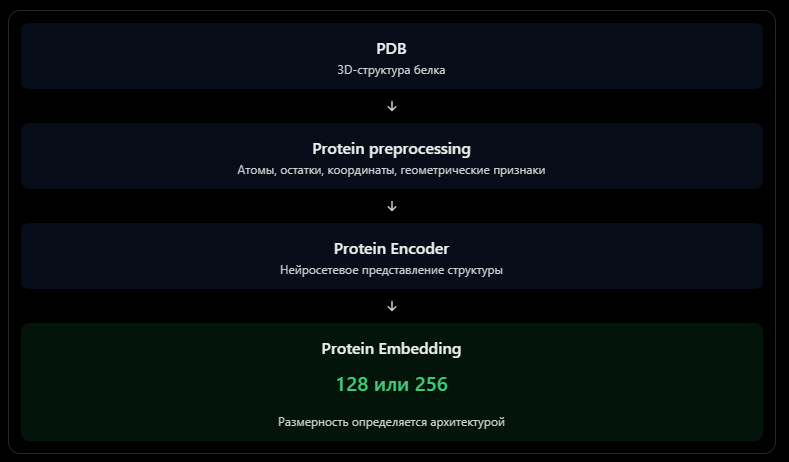

3. Этап 3. Интеграция с текущей Conditional Transformer VAE
Сейчас твоя архитектура получает три источника информации:
- SELFIES Encoder;
- Property Encoder;
- Fingerprint Encoder.
В перспективе добавится четвёртый источник — Protein Encoder.

Это схема возможного расширения, а не готовое решение: для генерации под белок особенно важно передавать декодеру информацию о структуре белка. Поэтому в дальнейшем стоит рассмотреть передачу последовательности признаков белка через cross-attention, а не только одного общего вектора.

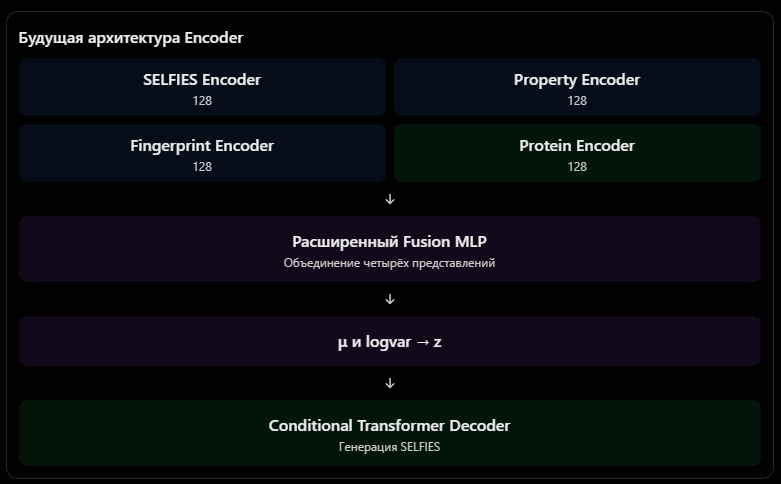

4. Этап 4. Подготовка обучающей выборки
Это важный момент: для обучения генерации под белок недостаточно взять один PDB-файл.

Нужны данные, связывающие структуры белков с соответствующими молекулами. Например, несколько белок-лигандных комплексов для выбранной мишени. Затем формируется набор пар:

(Protein Structure, SELFIES, Molecular Properties)

На нём уже можно будет обучать расширенную модель. Текущая VAE останется базовой моделью для сравнения.

+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# Загрузки

In [1]:
%pip install biopython pandas numpy matplotlib requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\apex_\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [2]:
%pip install python-docx reportlab pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\apex_\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [3]:
%pip install nglview ipywidgets


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\apex_\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


# Этап 1

In [4]:
# ячейка 2
import os
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from Bio.PDB import MMCIFParser, is_aa
from Bio.PDB.MMCIF2Dict import MMCIF2Dict
from Bio.SeqUtils import seq1

warnings.filterwarnings("ignore")

# ============================================================
# НАСТРОЙКИ ПРОЕКТА
# ============================================================

# PDB ID исследуемой структуры
# Пока можно оставить демонстрационный вариант 1CRN.
# Позже заменим его на ID выбранной белковой мишени.

# PDB_ID = "1CRN" # крамбин
# PDB_ID = "1HHO" # гемоглобин
# PDB_ID = "1DGF" # каталаза
PDB_ID = "1OCC" # цитохром-c-оксидаза

# Директории проекта
PROJECT_DIR = Path("PDB_Protein_Analysis")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Пути к файлам
CIF_PATH = DATA_DIR / f"{PDB_ID}.cif"

print("PDB analysis")
print("=" * 60)
print("PDB ID:", PDB_ID)
print("Project directory:", PROJECT_DIR.resolve())
print("Data directory:", DATA_DIR.resolve())
print("Results directory:", RESULTS_DIR.resolve())

PDB analysis
PDB ID: 1OCC
Project directory: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis
Data directory: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\data
Results directory: C:\apex\APEX\МИФИ\СНО\medic\PDB_Protein_Analysis\results


In [5]:
# ============================================================
# START TEXT REPORT
# ============================================================

import sys
from pathlib import Path

class TeeOutput:

    """Display output in Jupyter and simultaneously save it to a file."""

    def __init__(self, original_stream, log_file):
        self.original_stream = original_stream
        self.log_file = log_file

    def write(self, text):
        self.original_stream.write(text)
        self.log_file.write(text)
        self.log_file.flush()

    def flush(self):
        self.original_stream.flush()
        self.log_file.flush()

    def isatty(self):
        return self.original_stream.isatty()

    @property
    def encoding(self):
        return self.original_stream.encoding


# Create report file
REPORT_PATH = RESULTS_DIR / f"{PDB_ID}_analysis_report.txt"

report_file = open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
)

# Save original output streams
original_stdout = sys.stdout
original_stderr = sys.stderr

# Redirect output to screen + file
sys.stdout = TeeOutput(original_stdout, report_file)
sys.stderr = TeeOutput(original_stderr, report_file)

print("=" * 70)
print("PROTEIN STRUCTURE ANALYSIS REPORT")
print("=" * 70)

print("PDB ID:", PDB_ID)
print("Report file:", REPORT_PATH)
print(" ")

PROTEIN STRUCTURE ANALYSIS REPORT
PDB ID: 1OCC
Report file: PDB_Protein_Analysis\results\1OCC_analysis_report.txt
 
Структура загружена: PDB_Protein_Analysis\data\1OCC.cif
Размер файла: 2900.95 KB
CELL 4. ЧТЕНИЕ СТРУКТУРЫ БЕЛКА
PDB ID: 1OCC
Файл структуры: PDB_Protein_Analysis\data\1OCC.cif
Размер файла: 2900.95 KB

----------------------------------------------------------------------
ОБЩАЯ ИНФОРМАЦИЯ О СТРУКТУРЕ
----------------------------------------------------------------------
Количество моделей:              1
Анализируемая модель:             0
Количество цепей:                26

Всего остатков:                  3574
Белковых остатков:               3560
Небелковых остатков:             14
Остатков воды:                   0

Всего атомов:                    28722
Белковых атомов:                 28472
Небелковых атомов:               250
Атомов воды:                     0

----------------------------------------------------------------------
СТАТИСТИКА ПО ЦЕПЯМ
-------------

In [6]:
# ЯЧЕЙКА 3  Загрузка структуры из PDB
# ============================================================
# DOWNLOAD PDB STRUCTURE
# ============================================================

PDB_ID = PDB_ID.upper().strip()

if len(PDB_ID) != 4 or not PDB_ID.isalnum():
    raise ValueError("PDB ID должен состоять из 4 букв или цифр.")

url = f"https://files.rcsb.org/download/{PDB_ID}.cif"

if not CIF_PATH.exists():

    response = requests.get(url, timeout=60)

    if response.status_code != 200:
        raise RuntimeError(
            f"Не удалось загрузить структуру {PDB_ID}. "
            f"HTTP status: {response.status_code}"
        )

    CIF_PATH.write_bytes(response.content)

print("Структура загружена:", CIF_PATH)
print("Размер файла:", round(CIF_PATH.stat().st_size / 1024, 2), "KB")

In [7]:
# ============================================================
# CELL 4. ЧТЕНИЕ СТРУКТУРЫ БЕЛКА
# ============================================================
# Загрузка MMCIF, получение моделей и цепей.
# Первичный подсчёт белковых, небелковых атомов и воды.
# Подготовка технических данных для последующих ячеек.
# ============================================================

from pathlib import Path
from Bio.PDB.Polypeptide import is_aa


print("=" * 70)
print("CELL 4. ЧТЕНИЕ СТРУКТУРЫ БЕЛКА")
print("=" * 70)

# ------------------------------------------------------------
# 1. Проверка исходных данных
# ------------------------------------------------------------

if "PDB_ID" not in globals():
    raise NameError("PDB_ID не определён. Проверьте выполнение предыдущих ячеек.")

if "CIF_PATH" not in globals():
    raise NameError("CIF_PATH не определён. Проверьте выполнение предыдущих ячеек.")

cif_path = Path(CIF_PATH)

print(f"PDB ID: {PDB_ID}")
print(f"Файл структуры: {cif_path}")

if not cif_path.is_file():
    raise FileNotFoundError(
        f"Файл структуры не найден: {cif_path}"
    )

print(f"Размер файла: {cif_path.stat().st_size / 1024:.2f} KB")


# ------------------------------------------------------------
# 2. Чтение MMCIF
# ------------------------------------------------------------

parser = MMCIFParser(QUIET=True)

structure = parser.get_structure(
    PDB_ID,
    str(cif_path)
)

models = list(structure.get_models())

if len(models) == 0:
    raise ValueError("В структуре не обнаружено ни одной модели.")

# Для первичного анализа используем первую модель
model = models[0]

chains = list(model.get_chains())

if len(chains) == 0:
    raise ValueError("В первой модели не обнаружено ни одной цепи.")


# ------------------------------------------------------------
# 3. Подсчёт характеристик каждой цепи
# ------------------------------------------------------------

WATER_NAMES = {"HOH", "WAT", "DOD"}

chain_statistics = []

for chain in chains:

    residues = list(chain.get_residues())

    protein_residues = [
        residue
        for residue in residues
        if is_aa(residue, standard=False)
    ]

    water_residues = [
        residue
        for residue in residues
        if residue.resname.strip().upper() in WATER_NAMES
    ]

    protein_residue_ids = {
        id(residue)
        for residue in protein_residues
    }

    water_residue_ids = {
        id(residue)
        for residue in water_residues
    }

    nonprotein_residues = [
        residue
        for residue in residues
        if (
            id(residue) not in protein_residue_ids
            and id(residue) not in water_residue_ids
        )
    ]

    protein_atom_count = sum(
        len(list(residue.get_atoms()))
        for residue in protein_residues
    )

    water_atom_count = sum(
        len(list(residue.get_atoms()))
        for residue in water_residues
    )

    nonprotein_atom_count = sum(
        len(list(residue.get_atoms()))
        for residue in nonprotein_residues
    )

    total_atom_count = sum(
        len(list(residue.get_atoms()))
        for residue in residues
    )

    chain_statistics.append({
        "chain_id": chain.id,
        "total_residues": len(residues),
        "protein_residues": len(protein_residues),
        "nonprotein_residues": len(nonprotein_residues),
        "water_residues": len(water_residues),
        "protein_atoms": protein_atom_count,
        "nonprotein_atoms": nonprotein_atom_count,
        "water_atoms": water_atom_count,
        "total_atoms": total_atom_count
    })


# ------------------------------------------------------------
# 4. Общая статистика первой модели
# ------------------------------------------------------------

total_residues = sum(
    item["total_residues"]
    for item in chain_statistics
)

protein_residue_count = sum(
    item["protein_residues"]
    for item in chain_statistics
)

nonprotein_residue_count = sum(
    item["nonprotein_residues"]
    for item in chain_statistics
)

water_residue_count = sum(
    item["water_residues"]
    for item in chain_statistics
)

protein_atom_count = sum(
    item["protein_atoms"]
    for item in chain_statistics
)

nonprotein_atom_count = sum(
    item["nonprotein_atoms"]
    for item in chain_statistics
)

water_atom_count = sum(
    item["water_atoms"]
    for item in chain_statistics
)

total_atom_count = sum(
    item["total_atoms"]
    for item in chain_statistics
)


# ------------------------------------------------------------
# 5. Сохранение результатов для следующих ячеек
# ------------------------------------------------------------

structure_statistics = {
    "pdb_id": PDB_ID,
    "source_file": str(cif_path),
    "model_count": len(models),
    "analyzed_model": model.id,
    "chain_count": len(chains),
    "total_residues": total_residues,
    "protein_residues": protein_residue_count,
    "nonprotein_residues": nonprotein_residue_count,
    "water_residues": water_residue_count,
    "protein_atoms": protein_atom_count,
    "nonprotein_atoms": nonprotein_atom_count,
    "water_atoms": water_atom_count,
    "total_atoms": total_atom_count
}


# ------------------------------------------------------------
# 6. Вывод результатов
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ОБЩАЯ ИНФОРМАЦИЯ О СТРУКТУРЕ")
print("-" * 70)

print(f"Количество моделей:              {len(models)}")
print(f"Анализируемая модель:             {model.id}")
print(f"Количество цепей:                {len(chains)}")

print(f"\nВсего остатков:                  {total_residues}")
print(f"Белковых остатков:               {protein_residue_count}")
print(f"Небелковых остатков:             {nonprotein_residue_count}")
print(f"Остатков воды:                   {water_residue_count}")

print(f"\nВсего атомов:                    {total_atom_count}")
print(f"Белковых атомов:                 {protein_atom_count}")
print(f"Небелковых атомов:               {nonprotein_atom_count}")
print(f"Атомов воды:                     {water_atom_count}")


# ------------------------------------------------------------
# 7. Информация по отдельным цепям
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("СТАТИСТИКА ПО ЦЕПЯМ")
print("-" * 70)

for item in chain_statistics:

    print(f"\nChain {item['chain_id']}")

    print(
        f"  Остатки: всего={item['total_residues']}, "
        f"белковые={item['protein_residues']}, "
        f"небелковые={item['nonprotein_residues']}, "
        f"вода={item['water_residues']}"
    )

    print(
        f"  Атомы: всего={item['total_atoms']}, "
        f"белковые={item['protein_atoms']}, "
        f"небелковые={item['nonprotein_atoms']}, "
        f"вода={item['water_atoms']}"
    )


# ------------------------------------------------------------
# 8. Контроль согласованности подсчётов
# ------------------------------------------------------------

calculated_atom_sum = (
    protein_atom_count
    + nonprotein_atom_count
    + water_atom_count
)

atom_count_check = calculated_atom_sum == total_atom_count

print("\n" + "-" * 70)
print("КОНТРОЛЬ РЕЗУЛЬТАТОВ")
print("-" * 70)

print(
    "Проверка суммы категорий атомов:",
    "OK" if atom_count_check else "ERROR"
)

if not atom_count_check:
    raise ValueError(
        "Сумма белковых, небелковых атомов и атомов воды "
        "не совпадает с общим количеством атомов."
    )

print("\nСтатус: OK")
print("Структура загружена.")
print("Результаты подготовлены для последующих ячеек.")

print("=" * 70)
print("CELL 4 COMPLETED")
print("=" * 70)

In [8]:
# ============================================================
# CELL 5. АНАЛИЗ АМИНОКИСЛОТНЫХ ПОСЛЕДОВАТЕЛЬНОСТЕЙ
# ============================================================
# Извлечение последовательностей белковых цепей.
# Преобразование трехбуквенных обозначений аминокислот
# в однобуквенный формат.
# Сохранение последовательностей в формате FASTA.
# Подготовка статистики для последующих этапов анализа.
# ============================================================

from pathlib import Path
from Bio.SeqUtils import seq1
from Bio.PDB.Polypeptide import is_aa


print("=" * 70)
print("CELL 5. АНАЛИЗ АМИНОКИСЛОТНЫХ ПОСЛЕДОВАТЕЛЬНОСТЕЙ")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных данных
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "chains",
    "RESULTS_DIR"
]

for variable in required_variables:

    if variable not in globals():
        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )

RESULTS_DIR = Path(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"PDB ID: {PDB_ID}")
print(f"Количество цепей для анализа: {len(chains)}")
print(f"Каталог результатов: {RESULTS_DIR}")


# ------------------------------------------------------------
# 2. Карта нестандартных аминокислот
# ------------------------------------------------------------

CUSTOM_AMINO_ACIDS = {
    "MSE": "M",  # Селено-метионин
    "SEC": "U",  # Селеноцистеин
    "PYL": "O"   # Пирролизин
}


# ------------------------------------------------------------
# 3. Извлечение последовательностей
# ------------------------------------------------------------

chain_sequences = {}

sequence_statistics = []

for chain in chains:

    sequence = []

    unknown_residues = []
    nonstandard_residues = []

    protein_residues = [
        residue
        for residue in chain.get_residues()
        if is_aa(residue, standard=False)
    ]

    for residue in protein_residues:

        residue_name = residue.resname.strip().upper()

        amino_acid = seq1(
            residue_name,
            custom_map=CUSTOM_AMINO_ACIDS,
            undef_code="X"
        )

        sequence.append(amino_acid)

        if residue_name in CUSTOM_AMINO_ACIDS:

            nonstandard_residues.append(residue_name)

        elif amino_acid == "X":

            unknown_residues.append(residue_name)

    sequence = "".join(sequence)

    chain_sequences[chain.id] = sequence

    sequence_statistics.append({

        "chain_id": chain.id,

        "residue_count": len(protein_residues),

        "sequence_length": len(sequence),

        "unknown_residue_count": sequence.count("X"),

        "unknown_residue_names": sorted(
            set(unknown_residues)
        ),

        "nonstandard_residue_count": len(nonstandard_residues),

        "nonstandard_residue_names": sorted(
            set(nonstandard_residues)
        )
    })


# ------------------------------------------------------------
# 4. Контроль извлечённых последовательностей
# ------------------------------------------------------------

total_sequence_length = sum(
    item["sequence_length"]
    for item in sequence_statistics
)

total_unknown_count = sum(
    item["unknown_residue_count"]
    for item in sequence_statistics
)

total_nonstandard_count = sum(
    item["nonstandard_residue_count"]
    for item in sequence_statistics
)

sequence_length_check = all(
    item["residue_count"] == item["sequence_length"]
    for item in sequence_statistics
)

if not sequence_length_check:

    raise ValueError(
        "Обнаружено несоответствие между количеством "
        "белковых остатков и длиной последовательности."
    )


# ------------------------------------------------------------
# 5. Сохранение последовательностей в FASTA
# ------------------------------------------------------------

FASTA_PATH = RESULTS_DIR / f"{PDB_ID}_sequences.fasta"

with open(FASTA_PATH, "w", encoding="utf-8") as file:

    for chain_id, sequence in chain_sequences.items():

        if not sequence:
            continue

        file.write(f">{PDB_ID}_chain_{chain_id}\n")

        for i in range(0, len(sequence), 80):

            file.write(sequence[i:i + 80] + "\n")


# Совместимость с предыдущим именем переменной
fasta_path = FASTA_PATH


# ------------------------------------------------------------
# 6. Сохранение статистики последовательностей
# ------------------------------------------------------------

sequence_summary = {

    "pdb_id": PDB_ID,

    "chain_count": len(chain_sequences),

    "total_sequence_length": total_sequence_length,

    "unknown_residue_count": total_unknown_count,

    "nonstandard_residue_count": total_nonstandard_count,

    "sequence_length_check": sequence_length_check,

    "fasta_path": str(FASTA_PATH),

    "chain_statistics": sequence_statistics
}


# ------------------------------------------------------------
# 7. Вывод последовательностей и статистики
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ПОСЛЕДОВАТЕЛЬНОСТИ БЕЛКОВЫХ ЦЕПЕЙ")
print("-" * 70)

for chain_id, sequence in chain_sequences.items():

    print(f"\nChain {chain_id}")

    print(f"Длина последовательности: {len(sequence)}")

    print("Последовательность:")

    print(sequence if sequence else "Пустая последовательность")

    print("-" * 70)


print("\n" + "-" * 70)
print("ТЕХНИЧЕСКАЯ СТАТИСТИКА")
print("-" * 70)

for item in sequence_statistics:

    print(f"\nChain {item['chain_id']}")

    print(f"  Белковых остатков: {item['residue_count']}")

    print(f"  Длина последовательности: {item['sequence_length']}")

    print(f"  Неизвестных остатков (X): {item['unknown_residue_count']}")

    print(
        f"  Нестандартных остатков: "
        f"{item['nonstandard_residue_count']}"
    )

    if item["unknown_residue_names"]:

        print(
            "  Неизвестные обозначения:",
            item["unknown_residue_names"]
        )

    if item["nonstandard_residue_names"]:

        print(
            "  Нестандартные обозначения:",
            item["nonstandard_residue_names"]
        )


# ------------------------------------------------------------
# 8. Итоговая проверка
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ИТОГИ CELL 5")
print("-" * 70)

print(f"Количество цепей: {len(chain_sequences)}")

print(f"Общая длина последовательностей: {total_sequence_length}")

print(f"Неизвестные аминокислоты (X): {total_unknown_count}")

print(f"Нестандартные аминокислоты: {total_nonstandard_count}")

print(
    "Проверка соответствия остатков и длины:",
    "OK" if sequence_length_check else "ERROR"
)

print(f"\nFASTA-файл: {FASTA_PATH}")

if not FASTA_PATH.is_file():

    raise FileNotFoundError(
        f"FASTA-файл не был создан: {FASTA_PATH}"
    )

print(f"Размер FASTA: {FASTA_PATH.stat().st_size} bytes")

print("\nСтатус: OK")
print("Последовательности подготовлены для дальнейшего анализа.")

print("=" * 70)
print("CELL 5 COMPLETED")
print("=" * 70)

In [9]:
# ============================================================
# CELL 6. АНАЛИЗ АМИНОКИСЛОТНЫХ ОСТАТКОВ
# ============================================================
# Формирование таблицы каждого белкового остатка.
# Контроль основных атомов пептидного остова.
# Проверка соответствия последовательностям из CELL 5.
# Сохранение результатов для последующих этапов.
# ============================================================

import pandas as pd
from pathlib import Path
from Bio.SeqUtils import seq1
from Bio.PDB.Polypeptide import is_aa


print("=" * 70)
print("CELL 6. АНАЛИЗ АМИНОКИСЛОТНЫХ ОСТАТКОВ")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных данных
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "chains",
    "chain_sequences",
    "RESULTS_DIR"
]

for variable in required_variables:

    if variable not in globals():
        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )

RESULTS_DIR = Path(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"PDB ID: {PDB_ID}")
print(f"Количество цепей: {len(chains)}")


# ------------------------------------------------------------
# 2. Карта нестандартных аминокислот
# ------------------------------------------------------------

CUSTOM_AMINO_ACIDS = {
    "MSE": "M",
    "SEC": "U",
    "PYL": "O"
}

BACKBONE_ATOMS = ["N", "CA", "C", "O"]


# ------------------------------------------------------------
# 3. Формирование записей по каждому остатку
# ------------------------------------------------------------

residue_records = []

for chain in chains:

    for residue in chain.get_residues():

        if not is_aa(residue, standard=False):
            continue

        residue_name = residue.resname.strip().upper()

        amino_acid = seq1(
            residue_name,
            custom_map=CUSTOM_AMINO_ACIDS,
            undef_code="X"
        )

        present_backbone_atoms = [
            atom_name
            for atom_name in BACKBONE_ATOMS
            if residue.has_id(atom_name)
        ]

        missing_backbone_atoms = [
            atom_name
            for atom_name in BACKBONE_ATOMS
            if not residue.has_id(atom_name)
        ]

        residue_records.append({

            "chain_id": chain.id,

            "hetero_flag": residue.id[0],

            "residue_id": residue.id[1],

            "insertion_code": residue.id[2].strip(),

            "residue_name": residue_name,

            "amino_acid": amino_acid,

            "atom_count": len(list(residue.get_atoms())),

            "has_N": residue.has_id("N"),

            "has_CA": residue.has_id("CA"),

            "has_C": residue.has_id("C"),

            "has_O": residue.has_id("O"),

            "present_backbone_atoms": ",".join(
                present_backbone_atoms
            ),

            "missing_backbone_atoms": ",".join(
                missing_backbone_atoms
            ),

            "missing_backbone_atom_count": len(
                missing_backbone_atoms
            ),

            "is_nonstandard": residue_name in CUSTOM_AMINO_ACIDS,

            "is_unknown": amino_acid == "X"

        })


# ------------------------------------------------------------
# 4. Создание DataFrame
# ------------------------------------------------------------

RESIDUE_COLUMNS = [

    "chain_id",
    "hetero_flag",
    "residue_id",
    "insertion_code",
    "residue_name",
    "amino_acid",
    "atom_count",
    "has_N",
    "has_CA",
    "has_C",
    "has_O",
    "present_backbone_atoms",
    "missing_backbone_atoms",
    "missing_backbone_atom_count",
    "is_nonstandard",
    "is_unknown"

]

df_residues = pd.DataFrame(
    residue_records,
    columns=RESIDUE_COLUMNS
)

if df_residues.empty:

    raise ValueError(
        "Белковые остатки не обнаружены. "
        "Проверьте структуру и результат CELL 4."
    )


# ------------------------------------------------------------
# 5. Контроль основных атомов
# ------------------------------------------------------------

missing_backbone_df = df_residues.loc[
    df_residues["missing_backbone_atom_count"] > 0
].copy()

complete_backbone_count = int(
    (df_residues["missing_backbone_atom_count"] == 0).sum()
)

incomplete_backbone_count = len(missing_backbone_df)

missing_atom_counts = {

    atom_name: int(
        (~df_residues[f"has_{atom_name}"]).sum()
    )

    for atom_name in BACKBONE_ATOMS
}


# ------------------------------------------------------------
# 6. Статистика по цепям
# ------------------------------------------------------------

residue_chain_statistics = []

for chain_id, group in df_residues.groupby(
    "chain_id",
    sort=False
):

    residue_chain_statistics.append({

        "chain_id": chain_id,

        "residue_count": len(group),

        "atom_count": int(group["atom_count"].sum()),

        "complete_backbone_count": int(
            (group["missing_backbone_atom_count"] == 0).sum()
        ),

        "incomplete_backbone_count": int(
            (group["missing_backbone_atom_count"] > 0).sum()
        ),

        "unknown_residue_count": int(
            group["is_unknown"].sum()
        ),

        "nonstandard_residue_count": int(
            group["is_nonstandard"].sum()
        )

    })

df_residue_chain_statistics = pd.DataFrame(
    residue_chain_statistics
)


# ------------------------------------------------------------
# 7. Проверка соответствия CELL 5
# ------------------------------------------------------------

sequence_comparison = []

for chain_id, sequence in chain_sequences.items():

    observed_count = int(
        (df_residues["chain_id"] == chain_id).sum()
    )

    sequence_length = len(sequence)

    sequence_comparison.append({

        "chain_id": chain_id,

        "residue_count": observed_count,

        "sequence_length": sequence_length,

        "matches": observed_count == sequence_length

    })

df_sequence_comparison = pd.DataFrame(
    sequence_comparison
)

sequence_match_check = bool(
    df_sequence_comparison["matches"].all()
)


# ------------------------------------------------------------
# 8. Проверка соответствия CELL 4
# ------------------------------------------------------------

cell4_comparison = []

if "chain_statistics" in globals():

    for item in chain_statistics:

        chain_id = item["chain_id"]

        observed_count = int(
            (df_residues["chain_id"] == chain_id).sum()
        )

        expected_count = item["protein_residues"]

        cell4_comparison.append({

            "chain_id": chain_id,

            "cell4_protein_residues": expected_count,

            "cell6_protein_residues": observed_count,

            "matches": expected_count == observed_count

        })

df_cell4_comparison = pd.DataFrame(
    cell4_comparison
)

if not df_cell4_comparison.empty:

    cell4_match_check = bool(
        df_cell4_comparison["matches"].all()
    )

else:

    cell4_match_check = None


# ------------------------------------------------------------
# 9. Проверка повторяющихся идентификаторов
# ------------------------------------------------------------

residue_key_columns = [
    "chain_id",
    "hetero_flag",
    "residue_id",
    "insertion_code"
]

duplicate_residues_df = df_residues.loc[
    df_residues.duplicated(
        subset=residue_key_columns,
        keep=False
    )
].copy()

duplicate_residue_count = len(duplicate_residues_df)


# ------------------------------------------------------------
# 10. Общая статистика
# ------------------------------------------------------------

total_residue_count = len(df_residues)

total_residue_atoms = int(
    df_residues["atom_count"].sum()
)

unknown_residue_count = int(
    df_residues["is_unknown"].sum()
)

nonstandard_residue_count = int(
    df_residues["is_nonstandard"].sum()
)

residue_analysis_summary = {

    "pdb_id": PDB_ID,

    "residue_count": total_residue_count,

    "chain_count": int(
        df_residues["chain_id"].nunique()
    ),

    "atom_count": total_residue_atoms,

    "complete_backbone_count": complete_backbone_count,

    "incomplete_backbone_count": incomplete_backbone_count,

    "missing_backbone_atom_counts": missing_atom_counts,

    "unknown_residue_count": unknown_residue_count,

    "nonstandard_residue_count": nonstandard_residue_count,

    "duplicate_residue_count": duplicate_residue_count,

    "sequence_match_check": sequence_match_check,

    "cell4_match_check": cell4_match_check

}


# ------------------------------------------------------------
# 11. Сохранение результатов
# ------------------------------------------------------------

RESIDUE_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_residue_analysis.csv"
)

RESIDUE_CHAIN_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_residue_chain_statistics.csv"
)

MISSING_BACKBONE_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_missing_backbone_atoms.csv"
)

SEQUENCE_CHECK_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_sequence_verification.csv"
)

CELL4_CHECK_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_cell4_verification.csv"
)

DUPLICATE_RESIDUES_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_duplicate_residues.csv"
)

df_residues.to_csv(
    RESIDUE_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_residue_chain_statistics.to_csv(
    RESIDUE_CHAIN_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

missing_backbone_df.to_csv(
    MISSING_BACKBONE_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_sequence_comparison.to_csv(
    SEQUENCE_CHECK_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_cell4_comparison.to_csv(
    CELL4_CHECK_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

duplicate_residues_df.to_csv(
    DUPLICATE_RESIDUES_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 12. Вывод таблиц и технической информации
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ТАБЛИЦА БЕЛКОВЫХ ОСТАТКОВ")
print("-" * 70)

display(df_residues.head(10))

print("\n" + "-" * 70)
print("СТАТИСТИКА ПО ЦЕПЯМ")
print("-" * 70)

display(df_residue_chain_statistics)

print("\n" + "-" * 70)
print("ПРОВЕРКА ПОСЛЕДОВАТЕЛЬНОСТЕЙ CELL 5")
print("-" * 70)

display(df_sequence_comparison)

print("\n" + "-" * 70)
print("ПРОВЕРКА ДАННЫХ CELL 4")
print("-" * 70)

if not df_cell4_comparison.empty:

    display(df_cell4_comparison)

else:

    print("Сравнение не выполнено: статистика CELL 4 недоступна.")


# ------------------------------------------------------------
# 13. Итоговая диагностика
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ИТОГОВАЯ СТАТИСТИКА")
print("-" * 70)

print(f"Всего белковых остатков: {total_residue_count}")

print(f"Всего атомов белковых остатков: {total_residue_atoms}")

print(f"Цепей: {df_residues['chain_id'].nunique()}")

print(f"Полностью представленных остатков: {complete_backbone_count}")

print(f"Остатков с отсутствующими атомами остова: {incomplete_backbone_count}")

print("\nОтсутствующие основные атомы:")

for atom_name, count in missing_atom_counts.items():

    print(f"  {atom_name}: {count}")

print(f"\nНеизвестные аминокислоты (X): {unknown_residue_count}")

print(f"Нестандартные аминокислоты: {nonstandard_residue_count}")

print(f"Повторяющиеся идентификаторы: {duplicate_residue_count}")

print(
    "\nСоответствие последовательностям CELL 5:",
    "OK" if sequence_match_check else "ERROR"
)

if cell4_match_check is not None:

    print(
        "Соответствие подсчётам CELL 4:",
        "OK" if cell4_match_check else "ERROR"
    )

else:

    print("Соответствие CELL 4: не проверено")


# ------------------------------------------------------------
# 14. Проверка файлов
# ------------------------------------------------------------

output_paths = [

    RESIDUE_CSV_PATH,
    RESIDUE_CHAIN_CSV_PATH,
    MISSING_BACKBONE_CSV_PATH,
    SEQUENCE_CHECK_CSV_PATH,
    CELL4_CHECK_CSV_PATH,
    DUPLICATE_RESIDUES_CSV_PATH

]

print("\n" + "-" * 70)
print("СОХРАНЁННЫЕ ФАЙЛЫ")
print("-" * 70)

for path in output_paths:

    print(
        f"{path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"
    )


# ------------------------------------------------------------
# 15. Итоговый статус
# ------------------------------------------------------------

if not sequence_match_check:

    raise ValueError(
        "Количество остатков не соответствует длинам "
        "последовательностей CELL 5."
    )

if cell4_match_check is False:

    raise ValueError(
        "Количество остатков не соответствует статистике CELL 4."
    )

print("\nСтатус: OK")
print("Таблица остатков подготовлена для дальнейшего анализа.")

print("=" * 70)
print("CELL 6 COMPLETED")
print("=" * 70)

,chain_id,hetero_flag,residue_id,insertion_code,residue_name,amino_acid,atom_count,has_N,has_CA,has_C,has_O,present_backbone_atoms,missing_backbone_atoms,missing_backbone_atom_count,is_nonstandard,is_unknown
0,A,,1,,MET,M,8,True,True,True,True,"N,CA,C,O",,0,False,False
1,A,,2,,PHE,F,11,True,True,True,True,"N,CA,C,O",,0,False,False
2,A,,3,,ILE,I,8,True,True,True,True,"N,CA,C,O",,0,False,False
3,A,,4,,ASN,N,8,True,True,True,True,"N,CA,C,O",,0,False,False
4,A,,5,,ARG,R,11,True,True,True,True,"N,CA,C,O",,0,False,False
5,A,,6,,TRP,W,14,True,True,True,True,"N,CA,C,O",,0,False,False
6,A,,7,,LEU,L,8,True,True,True,True,"N,CA,C,O",,0,False,False
7,A,,8,,PHE,F,11,True,True,True,True,"N,CA,C,O",,0,False,False
8,A,,9,,SER,S,6,True,True,True,True,"N,CA,C,O",,0,False,False
9,A,,10,,THR,T,7,True,True,True,True,"N,CA,C,O",,0,False,False


,chain_id,residue_count,atom_count,complete_backbone_count,incomplete_backbone_count,unknown_residue_count,nonstandard_residue_count
0,A,514,4025,514,0,0,0
1,B,227,1822,227,0,0,0
2,C,261,2124,261,0,0,0
3,D,144,1195,144,0,0,0
4,E,109,878,109,0,0,0
5,F,98,748,98,0,0,0
6,G,84,672,84,0,0,0
7,H,75,628,75,0,0,0
8,I,73,598,73,0,0,0
9,J,56,441,56,0,0,0


,chain_id,residue_count,sequence_length,matches
0,A,514,514,True
1,B,227,227,True
2,C,261,261,True
3,D,144,144,True
4,E,109,109,True
5,F,98,98,True
6,G,84,84,True
7,H,75,75,True
8,I,73,73,True
9,J,56,56,True


,chain_id,cell4_protein_residues,cell6_protein_residues,matches
0,A,514,514,True
1,B,227,227,True
2,C,261,261,True
3,D,144,144,True
4,E,109,109,True
5,F,98,98,True
6,G,84,84,True
7,H,75,75,True
8,I,73,73,True
9,J,56,56,True


In [10]:
# ============================================================
# CELL 7. АНАЛИЗ АТОМОВ И ИХ КООРДИНАТ
# ============================================================
# Извлечение координат белковых атомов.
# Сохранение химических и структурных характеристик.
# Контроль координат, occupancy и B-factor.
# Формирование статистики по атомам и цепям.
# Сверка с результатами CELL 4 и CELL 6.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path


print("=" * 70)
print("CELL 7. АНАЛИЗ АТОМОВ И ИХ КООРДИНАТ")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных данных
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "chains",
    "RESULTS_DIR",
    "df_residues"
]

for variable in required_variables:

    if variable not in globals():
        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )

RESULTS_DIR = Path(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"PDB ID: {PDB_ID}")
print(f"Количество цепей: {len(chains)}")
print(f"Каталог результатов: {RESULTS_DIR}")


# ------------------------------------------------------------
# 2. Извлечение координат белковых атомов
# ------------------------------------------------------------

atom_records = []

for chain in chains:

    for residue in chain.get_residues():

        if not is_aa(residue, standard=False):
            continue

        residue_name = residue.resname.strip().upper()

        amino_acid = seq1(
            residue_name,
            custom_map={
                "MSE": "M",
                "SEC": "U",
                "PYL": "O"
            },
            undef_code="X"
        )

        residue_number = residue.id[1]
        insertion_code = residue.id[2].strip()
        hetero_flag = residue.id[0]

        residue_key = (
            f"{chain.id}:{hetero_flag}:"
            f"{residue_number}:{insertion_code}"
        )

        # Используем тот же способ обхода атомов,
        # что и в CELL 4 и CELL 6.
        # Это сохраняет сопоставимость количества атомов.

        for atom in residue.get_atoms():

            coord = atom.coord

            element = (
                atom.element.strip().upper()
                if atom.element
                else "UNKNOWN"
            )

            atom_name = atom.get_name().strip()

            atom_records.append({

                "chain_id": chain.id,

                "residue_key": residue_key,

                "hetero_flag": hetero_flag,

                "residue_id": residue_number,

                "insertion_code": insertion_code,

                "residue_name": residue_name,

                "amino_acid": amino_acid,

                "atom_serial": atom.get_serial_number(),

                "atom_name": atom_name,

                "atom_fullname": atom.get_fullname().strip(),

                "element": element,

                "x": float(coord[0]),

                "y": float(coord[1]),

                "z": float(coord[2]),

                "occupancy": atom.get_occupancy(),

                "bfactor": atom.get_bfactor(),

                "altloc": atom.get_altloc().strip(),

                "is_backbone": atom_name in {
                    "N", "CA", "C", "O", "OXT"
                },

                "is_hydrogen": element in {"H", "D"}

            })


# ------------------------------------------------------------
# 3. Создание таблицы атомов
# ------------------------------------------------------------

ATOM_COLUMNS = [

    "chain_id",
    "residue_key",
    "hetero_flag",
    "residue_id",
    "insertion_code",
    "residue_name",
    "amino_acid",
    "atom_serial",
    "atom_name",
    "atom_fullname",
    "element",
    "x",
    "y",
    "z",
    "occupancy",
    "bfactor",
    "altloc",
    "is_backbone",
    "is_hydrogen"

]

df_atoms = pd.DataFrame(
    atom_records,
    columns=ATOM_COLUMNS
)

if df_atoms.empty:

    raise ValueError(
        "Белковые атомы не обнаружены. "
        "Проверьте результаты CELL 4 и CELL 6."
    )


# ------------------------------------------------------------
# 4. Проверка координат
# ------------------------------------------------------------

coordinate_columns = ["x", "y", "z"]

coordinate_array = df_atoms[
    coordinate_columns
].to_numpy(dtype=float)

finite_coordinate_mask = np.isfinite(
    coordinate_array
).all(axis=1)

invalid_coordinates_df = df_atoms.loc[
    ~finite_coordinate_mask
].copy()

invalid_coordinate_count = len(
    invalid_coordinates_df
)

if invalid_coordinate_count > 0:

    raise ValueError(
        f"Обнаружено атомов с некорректными координатами: "
        f"{invalid_coordinate_count}"
    )


# ------------------------------------------------------------
# 5. Проверка occupancy и B-factor
# ------------------------------------------------------------

missing_occupancy_count = int(
    df_atoms["occupancy"].isna().sum()
)

missing_bfactor_count = int(
    df_atoms["bfactor"].isna().sum()
)

invalid_occupancy_df = df_atoms.loc[
    df_atoms["occupancy"].notna()
    & (
        (df_atoms["occupancy"] < 0)
        | (df_atoms["occupancy"] > 1)
    )
].copy()

invalid_bfactor_df = df_atoms.loc[
    df_atoms["bfactor"].notna()
    & (df_atoms["bfactor"] < 0)
].copy()


# ------------------------------------------------------------
# 6. Статистика по химическим элементам
# ------------------------------------------------------------

element_statistics = (
    df_atoms
    .groupby("element", dropna=False)
    .agg(
        atom_count=("atom_name", "size")
    )
    .reset_index()
    .sort_values(
        "atom_count",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Статистика по цепям
# ------------------------------------------------------------

chain_atom_statistics = (
    df_atoms
    .groupby("chain_id", sort=False)
    .agg(
        atom_count=("atom_name", "size"),
        residue_count=("residue_key", "nunique"),
        backbone_atom_count=("is_backbone", "sum"),
        hydrogen_atom_count=("is_hydrogen", "sum"),
        altloc_atom_count=(
            "altloc",
            lambda x: int((x != "").sum())
        ),
        mean_occupancy=("occupancy", "mean"),
        mean_bfactor=("bfactor", "mean")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 8. Общая статистика
# ------------------------------------------------------------

total_protein_atoms = len(df_atoms)

total_protein_residues = int(
    df_atoms["residue_key"].nunique()
)

unique_elements = sorted(
    df_atoms["element"].unique().tolist()
)

backbone_atom_count = int(
    df_atoms["is_backbone"].sum()
)

hydrogen_atom_count = int(
    df_atoms["is_hydrogen"].sum()
)

altloc_atom_count = int(
    (df_atoms["altloc"] != "").sum()
)

mean_occupancy = df_atoms["occupancy"].mean()

mean_bfactor = df_atoms["bfactor"].mean()

atom_analysis_summary = {

    "pdb_id": PDB_ID,

    "protein_atom_count": total_protein_atoms,

    "protein_residue_count": total_protein_residues,

    "element_count": len(unique_elements),

    "elements": unique_elements,

    "backbone_atom_count": backbone_atom_count,

    "hydrogen_atom_count": hydrogen_atom_count,

    "altloc_atom_count": altloc_atom_count,

    "invalid_coordinate_count": invalid_coordinate_count,

    "missing_occupancy_count": missing_occupancy_count,

    "missing_bfactor_count": missing_bfactor_count,

    "invalid_occupancy_count": len(invalid_occupancy_df),

    "invalid_bfactor_count": len(invalid_bfactor_df),

    "mean_occupancy": (
        float(mean_occupancy)
        if pd.notna(mean_occupancy)
        else None
    ),

    "mean_bfactor": (
        float(mean_bfactor)
        if pd.notna(mean_bfactor)
        else None
    )

}


# ------------------------------------------------------------
# 9. Сверка с CELL 4
# ------------------------------------------------------------

cell4_atom_check = None

if "protein_atom_count" in globals():

    cell4_atom_check = (
        total_protein_atoms == protein_atom_count
    )

    cell4_expected_atoms = protein_atom_count

else:

    cell4_expected_atoms = None


# ------------------------------------------------------------
# 10. Сверка с CELL 6
# ------------------------------------------------------------

cell6_atom_check = None

cell6_expected_atoms = int(
    df_residues["atom_count"].sum()
)

cell6_atom_check = (
    total_protein_atoms == cell6_expected_atoms
)

cell6_residue_check = (
    total_protein_residues == len(df_residues)
)


# ------------------------------------------------------------
# 11. Сохранение результатов
# ------------------------------------------------------------

ATOM_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_protein_atoms.csv"
)

ELEMENT_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_element_statistics.csv"
)

CHAIN_ATOM_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_chain_atom_statistics.csv"
)

INVALID_COORDINATES_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_invalid_coordinates.csv"
)

INVALID_OCCUPANCY_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_invalid_occupancy.csv"
)

INVALID_BFACTOR_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_invalid_bfactor.csv"
)

df_atoms.to_csv(
    ATOM_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

element_statistics.to_csv(
    ELEMENT_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

chain_atom_statistics.to_csv(
    CHAIN_ATOM_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

invalid_coordinates_df.to_csv(
    INVALID_COORDINATES_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

invalid_occupancy_df.to_csv(
    INVALID_OCCUPANCY_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

invalid_bfactor_df.to_csv(
    INVALID_BFACTOR_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 12. Вывод таблиц
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ПРИМЕР ТАБЛИЦЫ АТОМОВ")
print("-" * 70)

display(df_atoms.head(10))

print("\n" + "-" * 70)
print("РАСПРЕДЕЛЕНИЕ АТОМОВ ПО ЭЛЕМЕНТАМ")
print("-" * 70)

display(element_statistics)

print("\n" + "-" * 70)
print("СТАТИСТИКА ПО ЦЕПЯМ")
print("-" * 70)

display(chain_atom_statistics)


# ------------------------------------------------------------
# 13. Вывод технической информации
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ТЕХНИЧЕСКАЯ СТАТИСТИКА")
print("-" * 70)

print(f"Всего белковых атомов: {total_protein_atoms}")

print(f"Белковых остатков: {total_protein_residues}")

print(f"Количество химических элементов: {len(unique_elements)}")

print(f"Элементы: {unique_elements}")

print(f"Атомов основного остова: {backbone_atom_count}")

print(f"Атомов водорода и дейтерия: {hydrogen_atom_count}")

print(f"Атомов с altloc: {altloc_atom_count}")

print(f"Среднее occupancy: {mean_occupancy:.4f}")

print(f"Средний B-factor: {mean_bfactor:.4f}")

print(f"Атомов с отсутствующим occupancy: {missing_occupancy_count}")

print(f"Атомов с отсутствующим B-factor: {missing_bfactor_count}")

print(f"Атомов с некорректными координатами: {invalid_coordinate_count}")

print(f"Атомов с некорректным occupancy: {len(invalid_occupancy_df)}")

print(f"Атомов с отрицательным B-factor: {len(invalid_bfactor_df)}")


# ------------------------------------------------------------
# 14. Контроль согласованности
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("СВЕРКА С ПРЕДЫДУЩИМИ ЯЧЕЙКАМИ")
print("-" * 70)

print(
    "Количество атомов CELL 4:",
    cell4_expected_atoms
)

print(
    "Количество атомов CELL 7:",
    total_protein_atoms
)

if cell4_atom_check is not None:

    print(
        "Сверка с CELL 4:",
        "OK" if cell4_atom_check else "ERROR"
    )

print(
    "Количество атомов CELL 6:",
    cell6_expected_atoms
)

print(
    "Сверка с CELL 6:",
    "OK" if cell6_atom_check else "ERROR"
)

print(
    "Сверка количества остатков с CELL 6:",
    "OK" if cell6_residue_check else "ERROR"
)

if not cell6_atom_check:
    raise ValueError(
        "Количество атомов CELL 7 не совпадает с CELL 6."
    )

if not cell6_residue_check:
    raise ValueError(
        "Количество остатков CELL 7 не совпадает с CELL 6."
    )

if cell4_atom_check is False:
    raise ValueError(
        "Количество атомов CELL 7 не совпадает с CELL 4."
    )


# ------------------------------------------------------------
# 15. Проверка сохранённых файлов
# ------------------------------------------------------------

output_paths = [

    ATOM_CSV_PATH,
    ELEMENT_CSV_PATH,
    CHAIN_ATOM_CSV_PATH,
    INVALID_COORDINATES_CSV_PATH,
    INVALID_OCCUPANCY_CSV_PATH,
    INVALID_BFACTOR_CSV_PATH

]

print("\n" + "-" * 70)
print("СОХРАНЁННЫЕ ФАЙЛЫ")
print("-" * 70)

for path in output_paths:

    print(
        f"{path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"
    )


# Совместимость со старым именем переменной
atom_csv_path = ATOM_CSV_PATH

# Совместимость с исходной CELL 7:
# сохраняем дополнительную копию таблицы остатков.
residue_csv_path = (
    RESULTS_DIR / f"{PDB_ID}_residues.csv"
)

df_residues.to_csv(
    residue_csv_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nТаблица остатков: {residue_csv_path}")

print("\nСтатус: OK")
print("Координаты белковых атомов подготовлены.")

print("=" * 70)
print("CELL 7 COMPLETED")
print("=" * 70)

,chain_id,residue_key,hetero_flag,residue_id,insertion_code,residue_name,amino_acid,atom_serial,atom_name,atom_fullname,element,x,y,z,occupancy,bfactor,altloc,is_backbone,is_hydrogen
0,A,A: :1:,,1,,MET,M,1,N,N,N,55.365002,340.954987,223.593994,1.0,51.20,,True,False
1,A,A: :1:,,1,,MET,M,2,CA,CA,C,55.060001,339.584991,224.141006,1.0,54.37,,True,False
2,A,A: :1:,,1,,MET,M,3,C,C,C,54.826000,338.536987,223.056000,1.0,48.49,,True,False
3,A,A: :1:,,1,,MET,M,4,O,O,O,55.618000,337.609009,222.910995,1.0,51.47,,True,False
4,A,A: :1:,,1,,MET,M,5,CB,CB,C,53.863998,339.625000,225.100006,1.0,64.39,,False,False
5,A,A: :1:,,1,,MET,M,6,CG,CG,C,54.251999,339.700989,226.570999,1.0,76.96,,False,False
6,A,A: :1:,,1,,MET,M,7,SD,SD,S,55.283001,338.307007,227.082993,1.0,94.70,,False,False
7,A,A: :1:,,1,,MET,M,8,CE,CE,C,54.181999,336.856995,226.600998,1.0,89.74,,False,False
8,A,A: :2:,,2,,PHE,F,9,N,N,N,53.721001,338.669006,222.322998,1.0,42.02,,True,False
9,A,A: :2:,,2,,PHE,F,10,CA,CA,C,53.416000,337.763000,221.216995,1.0,28.93,,True,False


,element,atom_count
0,C,18644
1,O,4984
2,N,4656
3,S,188


,chain_id,atom_count,residue_count,backbone_atom_count,hydrogen_atom_count,altloc_atom_count,mean_occupancy,mean_bfactor
0,A,4025,514,2057,0,0,1.0,14.618149
1,B,1822,227,909,0,0,1.0,23.117184
2,C,2124,261,1045,0,0,1.0,20.534859
3,D,1195,144,577,0,0,1.0,27.153029
4,E,878,109,437,0,0,1.0,32.726298
5,F,748,98,393,0,0,1.0,33.942152
6,G,672,84,337,0,0,1.0,43.922619
7,H,628,75,301,0,0,1.0,37.267803
8,I,598,73,293,0,0,1.0,36.237090
9,J,441,56,224,0,0,1.0,35.889864


In [11]:
# ============================================================
# CELL 8. АНАЛИЗ МАЛЫХ МОЛЕКУЛ И ДРУГИХ КОМПОНЕНТОВ
# ============================================================
# Выделение небелковых компонентов и молекул воды.
# Предварительная классификация по элементному составу.
# Извлечение координат атомов компонентов.
# Подготовка данных для CELL 17, CELL 18 и CELL 19.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from Bio.PDB.Polypeptide import is_aa


print("=" * 70)
print("CELL 8. АНАЛИЗ МАЛЫХ МОЛЕКУЛ И ДРУГИХ КОМПОНЕНТОВ")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных данных
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "chains",
    "RESULTS_DIR",
    "structure_statistics"
]

for variable in required_variables:

    if variable not in globals():
        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )

RESULTS_DIR = Path(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"PDB ID: {PDB_ID}")
print(f"Количество анализируемых цепей: {len(chains)}")


# ------------------------------------------------------------
# 2. Классификация компонентов
# ------------------------------------------------------------

WATER_CODES = {"HOH", "WAT", "DOD"}

METAL_ELEMENTS = {
    "FE", "ZN", "MG", "MN", "CU",
    "CO", "NI", "CA", "NA", "K",
    "CD", "HG"
}


def classify_component(residue_name, elements, atom_count):

    elements = set(elements)

    # Металлсодержащий органический компонент
    if elements.intersection(METAL_ELEMENTS) and "C" in elements:

        return "Metal-containing organic component"

    # Компонент, состоящий только из металлов
    elif elements and elements.issubset(METAL_ELEMENTS):

        return "Metal-containing component"

    # Отдельный атом или ион
    elif atom_count == 1:

        return "Single atom / ion"

    # Органический небелковый компонент
    elif "C" in elements:

        return "Organic non-protein component"

    # Другие неорганические компоненты
    else:

        return "Other non-protein component"


# ------------------------------------------------------------
# 3. Подготовка списков записей
# ------------------------------------------------------------

hetero_records = []
water_records = []

hetero_atom_records = []
water_atom_records = []


# ------------------------------------------------------------
# 4. Обход цепей и остатков
# ------------------------------------------------------------

for chain in chains:

    for residue in chain.get_residues():

        residue_name = residue.resname.strip().upper()

        hetero_flag = residue.id[0]

        residue_number = residue.id[1]

        insertion_code = residue.id[2].strip()

        # ----------------------------------------------------
        # 4.1. Пропускаем белковые остатки
        # ----------------------------------------------------
        # В том числе нестандартные аминокислоты, которые
        # Cell 4 и Cell 6 учитывают как часть белка.

        if is_aa(residue, standard=False):
            continue

        atoms = list(residue.get_atoms())

        if not atoms:
            continue

        # ----------------------------------------------------
        # 4.2. Элементный состав
        # ----------------------------------------------------

        elements = sorted({

            atom.element.strip().upper()

            for atom in atoms

            if atom.element and atom.element.strip()

        })

        atom_count = len(atoms)

        residue_key = (
            f"{chain.id}:{hetero_flag}:"
            f"{residue_number}:{insertion_code}"
        )

        component_id = (
            f"{chain.id}_{residue_name}_"
            f"{residue_number}_{insertion_code or 'none'}"
        )

        # ----------------------------------------------------
        # 4.3. Общая информация об остатке
        # ----------------------------------------------------

        residue_info = {

            "component_id": component_id,

            "residue_key": residue_key,

            "chain_id": chain.id,

            "residue_name": residue_name,

            "residue_id": residue_number,

            "insertion_code": insertion_code,

            "hetero_flag": hetero_flag,

            "atom_count": atom_count,

            "elements": ", ".join(elements),

            "element_count": len(elements)

        }

        # ----------------------------------------------------
        # 4.4. Обработка воды
        # ----------------------------------------------------

        if residue_name in WATER_CODES:

            residue_info["component_type"] = "Water"

            water_records.append(residue_info)

            for atom in atoms:

                coord = atom.get_coord()

                water_atom_records.append({

                    **residue_info,

                    "atom_serial": atom.get_serial_number(),

                    "atom_name": atom.get_name().strip(),

                    "element": (
                        atom.element.strip().upper()
                        if atom.element
                        else "UNKNOWN"
                    ),

                    "x": float(coord[0]),

                    "y": float(coord[1]),

                    "z": float(coord[2]),

                    "occupancy": atom.get_occupancy(),

                    "bfactor": atom.get_bfactor(),

                    "altloc": atom.get_altloc().strip()

                })

            continue

        # ----------------------------------------------------
        # 4.5. Обработка небелковых компонентов
        # ----------------------------------------------------

        component_type = classify_component(
            residue_name,
            elements,
            atom_count
        )

        residue_info["component_type"] = component_type

        hetero_records.append(residue_info)

        # ----------------------------------------------------
        # 4.6. Извлечение координат атомов компонента
        # ----------------------------------------------------

        for atom in atoms:

            coord = atom.get_coord()

            hetero_atom_records.append({

                **residue_info,

                "atom_serial": atom.get_serial_number(),

                "atom_name": atom.get_name().strip(),

                "element": (
                    atom.element.strip().upper()
                    if atom.element
                    else "UNKNOWN"
                ),

                "x": float(coord[0]),

                "y": float(coord[1]),

                "z": float(coord[2]),

                "occupancy": atom.get_occupancy(),

                "bfactor": atom.get_bfactor(),

                "altloc": atom.get_altloc().strip()

            })


# ------------------------------------------------------------
# 5. Формирование таблиц
# ------------------------------------------------------------

HETERO_COLUMNS = [

    "component_id",
    "residue_key",
    "chain_id",
    "residue_name",
    "residue_id",
    "insertion_code",
    "hetero_flag",
    "atom_count",
    "elements",
    "element_count",
    "component_type"

]

ATOM_COLUMNS = HETERO_COLUMNS + [

    "atom_serial",
    "atom_name",
    "element",
    "x",
    "y",
    "z",
    "occupancy",
    "bfactor",
    "altloc"

]

df_hetero = pd.DataFrame(
    hetero_records,
    columns=HETERO_COLUMNS
)

df_water = pd.DataFrame(
    water_records,
    columns=HETERO_COLUMNS
)

df_hetero_atoms = pd.DataFrame(
    hetero_atom_records,
    columns=ATOM_COLUMNS
)

df_water_atoms = pd.DataFrame(
    water_atom_records,
    columns=ATOM_COLUMNS
)


# ------------------------------------------------------------
# 6. Проверка координат
# ------------------------------------------------------------

coordinate_columns = ["x", "y", "z"]

if not df_hetero_atoms.empty:

    hetero_coordinates = df_hetero_atoms[
        coordinate_columns
    ].to_numpy(dtype=float)

    invalid_hetero_coordinates = ~np.isfinite(
        hetero_coordinates
    ).all(axis=1)

else:

    invalid_hetero_coordinates = np.array([], dtype=bool)


if not df_water_atoms.empty:

    water_coordinates = df_water_atoms[
        coordinate_columns
    ].to_numpy(dtype=float)

    invalid_water_coordinates = ~np.isfinite(
        water_coordinates
    ).all(axis=1)

else:

    invalid_water_coordinates = np.array([], dtype=bool)


invalid_hetero_coordinate_count = int(
    invalid_hetero_coordinates.sum()
)

invalid_water_coordinate_count = int(
    invalid_water_coordinates.sum()
)

if (
    invalid_hetero_coordinate_count > 0
    or invalid_water_coordinate_count > 0
):

    raise ValueError(
        "Обнаружены некорректные координаты "
        "небелковых компонентов или воды."
    )


# ------------------------------------------------------------
# 7. Сводная статистика
# ------------------------------------------------------------

hetero_residue_count = len(df_hetero)

water_residue_count = len(df_water)

hetero_atom_count = len(df_hetero_atoms)

water_atom_count = len(df_water_atoms)

unique_components = (
    sorted(df_hetero["residue_name"].unique().tolist())
    if not df_hetero.empty
    else []
)

component_occurrence_statistics = (

    df_hetero
    .groupby(
        ["residue_name", "component_type"],
        dropna=False
    )
    .agg(
        occurrence_count=("component_id", "count"),
        total_atom_count=("atom_count", "sum"),
        chains=("chain_id", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()

    if not df_hetero.empty

    else pd.DataFrame(
        columns=[
            "residue_name",
            "component_type",
            "occurrence_count",
            "total_atom_count",
            "chains"
        ]
    )
)


# ------------------------------------------------------------
# 8. Сверка с CELL 4
# ------------------------------------------------------------

cell4_nonprotein_residues = (
    structure_statistics["nonprotein_residues"]
)

cell4_water_residues = (
    structure_statistics["water_residues"]
)

cell4_nonprotein_atoms = (
    structure_statistics["nonprotein_atoms"]
)

cell4_water_atoms = (
    structure_statistics["water_atoms"]
)

nonprotein_residue_check = (
    hetero_residue_count == cell4_nonprotein_residues
)

water_residue_check = (
    water_residue_count == cell4_water_residues
)

nonprotein_atom_check = (
    hetero_atom_count == cell4_nonprotein_atoms
)

water_atom_check = (
    water_atom_count == cell4_water_atoms
)

cell4_component_check = all([

    nonprotein_residue_check,

    water_residue_check,

    nonprotein_atom_check,

    water_atom_check

])


# ------------------------------------------------------------
# 9. Сводная информация для последующих ячеек
# ------------------------------------------------------------

component_analysis_summary = {

    "pdb_id": PDB_ID,

    "nonprotein_residue_count": hetero_residue_count,

    "nonprotein_atom_count": hetero_atom_count,

    "water_residue_count": water_residue_count,

    "water_atom_count": water_atom_count,

    "component_names": unique_components,

    "component_occurrence_statistics": (
        component_occurrence_statistics.to_dict("records")
    ),

    "cell4_consistency_check": cell4_component_check,

    "invalid_coordinate_count": (
        invalid_hetero_coordinate_count
        + invalid_water_coordinate_count
    )

}


# ------------------------------------------------------------
# 10. Сохранение результатов
# ------------------------------------------------------------

HETERO_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_hetero_components.csv"
)

WATER_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_water_components.csv"
)

HETERO_ATOMS_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_hetero_atoms.csv"
)

WATER_ATOMS_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_water_atoms.csv"
)

COMPONENT_SUMMARY_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_component_summary.csv"
)

df_hetero.to_csv(
    HETERO_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_water.to_csv(
    WATER_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_hetero_atoms.to_csv(
    HETERO_ATOMS_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_water_atoms.to_csv(
    WATER_ATOMS_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

component_occurrence_statistics.to_csv(
    COMPONENT_SUMMARY_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 11. Вывод общей статистики
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ОБЩАЯ ИНФОРМАЦИЯ")
print("-" * 70)

print(f"Небелковых остатков: {hetero_residue_count}")

print(f"Атомов небелковых компонентов: {hetero_atom_count}")

print(f"Остатков воды: {water_residue_count}")

print(f"Атомов воды: {water_atom_count}")

print(f"Уникальных типов компонентов: {len(unique_components)}")

print(f"Компоненты: {unique_components}")


# ------------------------------------------------------------
# 12. Распределение компонентов
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("КЛАССИФИКАЦИЯ НЕБЕЛКОВЫХ КОМПОНЕНТОВ")
print("-" * 70)

if not df_hetero.empty:

    display(
        component_occurrence_statistics
    )

    display(
        df_hetero.sort_values(
            ["residue_name", "chain_id", "residue_id"]
        )
    )

else:

    print("Небелковые компоненты не обнаружены.")


# ------------------------------------------------------------
# 13. Информация о воде
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("АНАЛИЗ МОЛЕКУЛ ВОДЫ")
print("-" * 70)

if not df_water.empty:

    display(df_water.head(20))

else:

    print("Молекулы воды не обнаружены.")


# ------------------------------------------------------------
# 14. Атомы небелковых компонентов
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("КООРДИНАТЫ НЕБЕЛКОВЫХ КОМПОНЕНТОВ")
print("-" * 70)

if not df_hetero_atoms.empty:

    display(df_hetero_atoms.head(10))

    print(
        "Всего атомов в таблице:",
        len(df_hetero_atoms)
    )

else:

    print("Таблица атомов небелковых компонентов пуста.")


# ------------------------------------------------------------
# 15. Контроль соответствия CELL 4
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("СВЕРКА С CELL 4")
print("-" * 70)

print(
    f"Небелковые остатки: "
    f"CELL 4 = {cell4_nonprotein_residues}, "
    f"CELL 8 = {hetero_residue_count}"
)

print(
    f"Молекулы воды: "
    f"CELL 4 = {cell4_water_residues}, "
    f"CELL 8 = {water_residue_count}"
)

print(
    f"Атомы небелковых компонентов: "
    f"CELL 4 = {cell4_nonprotein_atoms}, "
    f"CELL 8 = {hetero_atom_count}"
)

print(
    f"Атомы воды: "
    f"CELL 4 = {cell4_water_atoms}, "
    f"CELL 8 = {water_atom_count}"
)

print(
    "\nОбщая проверка:",
    "OK" if cell4_component_check else "ERROR"
)

if not cell4_component_check:

    raise ValueError(
        "Количество небелковых компонентов или воды "
        "не совпадает с результатами CELL 4. "
        "Проверьте классификацию остатков."
    )


# ------------------------------------------------------------
# 16. Проверка сохранённых файлов
# ------------------------------------------------------------

output_paths = [

    HETERO_CSV_PATH,
    WATER_CSV_PATH,
    HETERO_ATOMS_CSV_PATH,
    WATER_ATOMS_CSV_PATH,
    COMPONENT_SUMMARY_CSV_PATH

]

print("\n" + "-" * 70)
print("СОХРАНЁННЫЕ ФАЙЛЫ")
print("-" * 70)

for path in output_paths:

    print(
        f"{path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"
    )


# ------------------------------------------------------------
# 17. Итоговый статус
# ------------------------------------------------------------

print("\nСтатус: OK")
print("Небелковые компоненты и вода выделены.")
print("Координаты компонентов подготовлены.")
print("Результаты готовы для CELL 17, CELL 18 и CELL 19.")

print("=" * 70)
print("CELL 8 COMPLETED")
print("=" * 70)

,residue_name,component_type,occurrence_count,total_atom_count,chains
0,CU,Metal-containing component,6,6,"A, B, N, O"
1,HEA,Metal-containing organic component,4,240,"A, N"
2,MG,Metal-containing component,2,2,"A, N"
3,ZN,Metal-containing component,2,2,"F, S"


,component_id,residue_key,chain_id,residue_name,residue_id,insertion_code,hetero_flag,atom_count,elements,element_count,component_type
0,A_CU_517_none,A:H_CU:517:,A,CU,517,,H_CU,1,CU,1,Metal-containing component
4,B_CU_228_none,B:H_CU:228:,B,CU,228,,H_CU,1,CU,1,Metal-containing component
5,B_CU_229_none,B:H_CU:229:,B,CU,229,,H_CU,1,CU,1,Metal-containing component
7,N_CU_517_none,N:H_CU:517:,N,CU,517,,H_CU,1,CU,1,Metal-containing component
11,O_CU_228_none,O:H_CU:228:,O,CU,228,,H_CU,1,CU,1,Metal-containing component
12,O_CU_229_none,O:H_CU:229:,O,CU,229,,H_CU,1,CU,1,Metal-containing component
2,A_HEA_515_none,A:H_HEA:515:,A,HEA,515,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component
3,A_HEA_516_none,A:H_HEA:516:,A,HEA,516,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component
9,N_HEA_515_none,N:H_HEA:515:,N,HEA,515,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component
10,N_HEA_516_none,N:H_HEA:516:,N,HEA,516,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component


,component_id,residue_key,chain_id,residue_name,residue_id,insertion_code,hetero_flag,atom_count,elements,element_count,component_type,atom_serial,atom_name,element,x,y,z,occupancy,bfactor,altloc
0,A_CU_517_none,A:H_CU:517:,A,CU,517,,H_CU,1,CU,1,Metal-containing component,28473,CU,CU,67.216003,310.902008,190.210999,1.0,15.34,
1,A_MG_518_none,A:H_MG:518:,A,MG,518,,H_MG,1,MG,1,Metal-containing component,28474,MG,MG,62.974998,315.558014,179.352005,1.0,11.98,
2,A_HEA_515_none,A:H_HEA:515:,A,HEA,515,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component,28475,FE,FE,52.153999,315.891998,192.014008,1.0,9.76,
3,A_HEA_515_none,A:H_HEA:515:,A,HEA,515,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component,28476,CHA,C,53.487000,316.437988,188.854996,1.0,9.36,
4,A_HEA_515_none,A:H_HEA:515:,A,HEA,515,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component,28477,CHB,C,49.188999,315.279999,190.682007,1.0,11.51,
5,A_HEA_515_none,A:H_HEA:515:,A,HEA,515,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component,28478,CHC,C,50.884998,315.164001,195.164993,1.0,13.91,
6,A_HEA_515_none,A:H_HEA:515:,A,HEA,515,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component,28479,CHD,C,55.102001,316.734985,193.434006,1.0,16.30,
7,A_HEA_515_none,A:H_HEA:515:,A,HEA,515,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component,28480,NA,N,51.469002,315.897003,190.190002,1.0,20.08,
8,A_HEA_515_none,A:H_HEA:515:,A,HEA,515,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component,28481,C1A,C,52.168999,316.040009,188.964005,1.0,10.32,
9,A_HEA_515_none,A:H_HEA:515:,A,HEA,515,,H_HEA,60,"C, FE, N, O",4,Metal-containing organic component,28482,C2A,C,51.379002,315.592987,187.897995,1.0,9.13,


Что изменилось по сравнению со старой версией
Возможность	Старая версия	Новая версия
Поиск небелковых компонентов	Да	Да
Поиск воды	Да	Да
Определение цепи и номера остатка	Да	Да
Количество атомов	Да	Да
Элементный состав	Нет	Да
Классификация металлов и ионов	Нет	Да
Выделение органических компонентов	Нет	Да
Распознавание нестандартных аминокислот	Нет	Да
Группировка по типам компонентов	Нет	Да

Важное уточнение: классификация здесь основана на элементном составе и типе остатка. Она не определяет достоверно биологическую функцию молекулы. Например, органический небелковый компонент может быть природным кофактором, субстратом или лекарственным лигандом.

,Parameter,Value,Unit
0,Number of protein atoms,2.847200e+04,atoms
1,Number of protein residues,3.560000e+03,residues
2,Number of chains,2.600000e+01,chains
3,Center X,9.634353e+01,Å
4,Center Y,3.190061e+02,Å
5,Center Z,1.971975e+02,Å
6,Minimum X,2.054400e+01,Å
7,Minimum Y,2.583720e+02,Å
8,Minimum Z,1.345440e+02,Å
9,Maximum X,1.715630e+02,Å


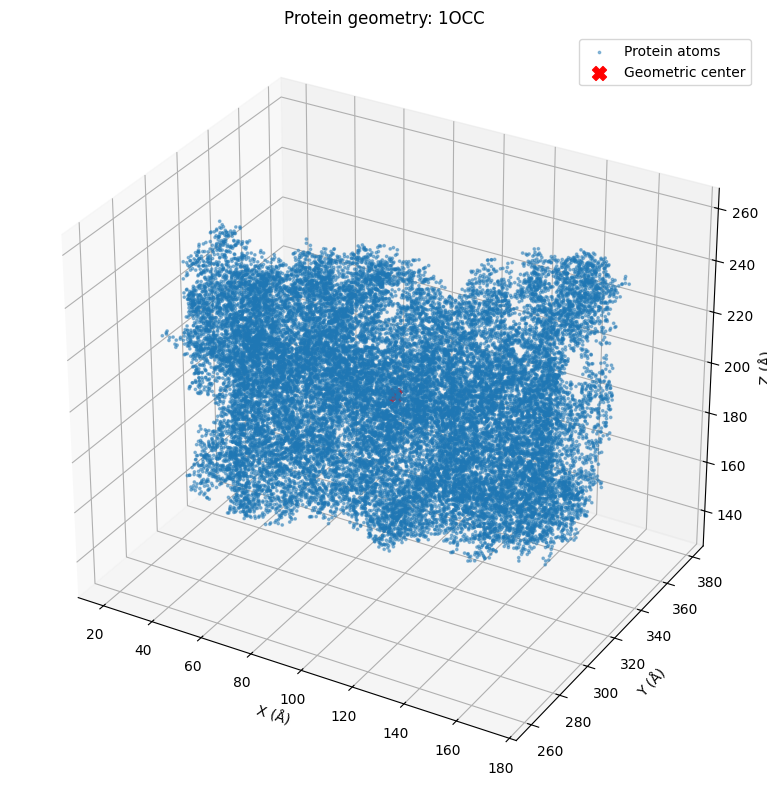

In [12]:
# ============================================================
# CELL 9. АНАЛИЗ ГЕОМЕТРИИ БЕЛКОВОЙ СТРУКТУРЫ
# ============================================================
# Расчёт геометрических характеристик белковой структуры.
# Используются координаты белковых атомов из CELL 7.
#
# Рассчитываются:
# - геометрический центр;
# - минимальные и максимальные координаты;
# - размеры структуры по осям X, Y, Z;
# - объём ограничивающего параллелепипеда;
# - максимальное расстояние от центра;
# - геометрический радиус инерции.
#
# Вода и небелковые компоненты не учитываются.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from pathlib import Path


print("=" * 70)
print("CELL 9. АНАЛИЗ ГЕОМЕТРИИ БЕЛКОВОЙ СТРУКТУРЫ")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных данных
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "df_atoms",
    "RESULTS_DIR"
]

for variable in required_variables:

    if variable not in globals():
        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )

RESULTS_DIR = Path(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"PDB ID: {PDB_ID}")
print("Источник координат: df_atoms (CELL 7)")
print("Тип анализируемых атомов: только белковые атомы")
print("Единицы измерения: Å")


# ------------------------------------------------------------
# 2. Проверка таблицы координат
# ------------------------------------------------------------

coordinate_columns = ["x", "y", "z"]

missing_columns = [
    column
    for column in coordinate_columns
    if column not in df_atoms.columns
]

if missing_columns:

    raise ValueError(
        f"В df_atoms отсутствуют координатные столбцы: "
        f"{missing_columns}"
    )

if df_atoms.empty:

    raise ValueError(
        "Таблица df_atoms пуста. "
        "Невозможно рассчитать геометрию структуры."
    )

coordinates = df_atoms[
    coordinate_columns
].to_numpy(dtype=np.float64)

finite_coordinate_mask = np.isfinite(
    coordinates
).all(axis=1)

invalid_coordinate_count = int(
    (~finite_coordinate_mask).sum()
)

# Не удаляем некорректные координаты молча.
if invalid_coordinate_count > 0:

    raise ValueError(
        f"Обнаружено {invalid_coordinate_count} атомов "
        "с некорректными координатами. "
        "Проверьте CELL 7."
    )

if len(coordinates) < 2:

    raise ValueError(
        "Недостаточно атомов для геометрического анализа."
    )


# ------------------------------------------------------------
# 3. Геометрический центр
# ------------------------------------------------------------

center = coordinates.mean(axis=0)

center_x = float(center[0])
center_y = float(center[1])
center_z = float(center[2])


# ------------------------------------------------------------
# 4. Границы структуры
# ------------------------------------------------------------

coord_min = coordinates.min(axis=0)

coord_max = coordinates.max(axis=0)

dimensions = coord_max - coord_min

bounding_box_volume = float(
    np.prod(dimensions)
)

geometry_min = coord_min.astype(float)
geometry_max = coord_max.astype(float)
geometry_dimensions = dimensions.astype(float)


# ------------------------------------------------------------
# 5. Расстояния от геометрического центра
# ------------------------------------------------------------

distances_from_center = np.linalg.norm(
    coordinates - center,
    axis=1
)

max_distance = float(
    distances_from_center.max()
)

mean_distance = float(
    distances_from_center.mean()
)

median_distance = float(
    np.median(distances_from_center)
)


# ------------------------------------------------------------
# 6. Геометрический радиус инерции
# ------------------------------------------------------------
# Рассчитывается по координатам атомов без учёта их масс.

radius_of_gyration = float(
    np.sqrt(
        np.mean(distances_from_center ** 2)
    )
)


# ------------------------------------------------------------
# 7. Дополнительные характеристики
# ------------------------------------------------------------

atom_count = len(coordinates)

residue_count = (
    int(df_atoms["residue_key"].nunique())
    if "residue_key" in df_atoms.columns
    else None
)

chain_count = (
    int(df_atoms["chain_id"].nunique())
    if "chain_id" in df_atoms.columns
    else None
)

min_dimension = float(dimensions.min())

max_dimension = float(dimensions.max())

aspect_ratio = (
    float(max_dimension / min_dimension)
    if min_dimension > 0
    else None
)


# ------------------------------------------------------------
# 8. Сводная таблица геометрии
# ------------------------------------------------------------

geometry_records = [

    ("Number of protein atoms", atom_count, "atoms"),

    ("Number of protein residues", residue_count, "residues"),

    ("Number of chains", chain_count, "chains"),

    ("Center X", center_x, "Å"),

    ("Center Y", center_y, "Å"),

    ("Center Z", center_z, "Å"),

    ("Minimum X", float(coord_min[0]), "Å"),

    ("Minimum Y", float(coord_min[1]), "Å"),

    ("Minimum Z", float(coord_min[2]), "Å"),

    ("Maximum X", float(coord_max[0]), "Å"),

    ("Maximum Y", float(coord_max[1]), "Å"),

    ("Maximum Z", float(coord_max[2]), "Å"),

    ("Size X", float(dimensions[0]), "Å"),

    ("Size Y", float(dimensions[1]), "Å"),

    ("Size Z", float(dimensions[2]), "Å"),

    ("Bounding box volume", bounding_box_volume, "Å³"),

    ("Maximum distance from center", max_distance, "Å"),

    ("Mean distance from center", mean_distance, "Å"),

    ("Median distance from center", median_distance, "Å"),

    ("Geometric radius of gyration", radius_of_gyration, "Å"),

    ("Bounding box aspect ratio", aspect_ratio, "ratio")

]

df_geometry = pd.DataFrame(
    geometry_records,
    columns=[
        "Parameter",
        "Value",
        "Unit"
    ]
)


# ------------------------------------------------------------
# 9. Сводный словарь результатов
# ------------------------------------------------------------

geometry_summary = {

    "pdb_id": PDB_ID,

    "coordinate_source": "df_atoms",

    "atom_selection": "protein atoms only",

    "water_included": False,

    "hetero_components_included": False,

    "atom_count": atom_count,

    "residue_count": residue_count,

    "chain_count": chain_count,

    "geometric_center": {
        "x": center_x,
        "y": center_y,
        "z": center_z
    },

    "minimum_coordinates": {
        "x": float(coord_min[0]),
        "y": float(coord_min[1]),
        "z": float(coord_min[2])
    },

    "maximum_coordinates": {
        "x": float(coord_max[0]),
        "y": float(coord_max[1]),
        "z": float(coord_max[2])
    },

    "dimensions": {
        "x": float(dimensions[0]),
        "y": float(dimensions[1]),
        "z": float(dimensions[2])
    },

    "bounding_box_volume": bounding_box_volume,

    "maximum_distance_from_center": max_distance,

    "mean_distance_from_center": mean_distance,

    "median_distance_from_center": median_distance,

    "geometric_radius_of_gyration": radius_of_gyration,

    "aspect_ratio": aspect_ratio,

    "coordinate_unit": "Angstrom"

}


# ------------------------------------------------------------
# 10. Сохранение результатов
# ------------------------------------------------------------

GEOMETRY_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_geometry.csv"
)

GEOMETRY_JSON_PATH = (
    RESULTS_DIR / f"{PDB_ID}_geometry.json"
)

df_geometry.to_csv(
    GEOMETRY_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

with open(
    GEOMETRY_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        geometry_summary,
        file,
        ensure_ascii=False,
        indent=4
    )


# ------------------------------------------------------------
# 11. Вывод результатов
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ГЕОМЕТРИЧЕСКИЕ ХАРАКТЕРИСТИКИ")
print("-" * 70)

print(f"Количество белковых атомов: {atom_count}")

print(f"Количество белковых остатков: {residue_count}")

print(f"Количество цепей: {chain_count}")

print("\nГеометрический центр (Å):")

print(f"X: {center_x:.4f}")
print(f"Y: {center_y:.4f}")
print(f"Z: {center_z:.4f}")

print("\nМинимальные координаты (Å):")

print(coord_min)

print("\nМаксимальные координаты (Å):")

print(coord_max)

print("\nРазмеры структуры (Å):")

print(dimensions)

print(
    f"\nОбъём ограничивающего параллелепипеда: "
    f"{bounding_box_volume:.4f} Å³"
)

print(
    f"Максимальное расстояние от центра: "
    f"{max_distance:.4f} Å"
)

print(
    f"Среднее расстояние от центра: "
    f"{mean_distance:.4f} Å"
)

print(
    f"Геометрический радиус инерции: "
    f"{radius_of_gyration:.4f} Å"
)

print("\nСводная таблица:")

display(df_geometry)


# ------------------------------------------------------------
# 12. Сверка с CELL 7
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("КОНТРОЛЬ СООТВЕТСТВИЯ CELL 7")
print("-" * 70)

if "total_protein_atoms" in globals():

    cell7_atom_check = (
        atom_count == total_protein_atoms
    )

    print(
        f"Атомы CELL 7: {total_protein_atoms}"
    )

    print(
        f"Атомы CELL 9: {atom_count}"
    )

    print(
        "Проверка:",
        "OK" if cell7_atom_check else "ERROR"
    )

    if not cell7_atom_check:

        raise ValueError(
            "Количество атомов в геометрическом анализе "
            "не совпадает с CELL 7."
        )

else:

    cell7_atom_check = None

    print("Сверка с CELL 7 не выполнена.")


# ------------------------------------------------------------
# 13. 3D-визуализация распределения атомов
# ------------------------------------------------------------

GEOMETRY_PLOT_PATH = (
    RESULTS_DIR / f"{PDB_ID}_protein_geometry.png"
)

fig = plt.figure(figsize=(10, 8))

ax = fig.add_subplot(
    111,
    projection="3d"
)

ax.scatter(
    coordinates[:, 0],
    coordinates[:, 1],
    coordinates[:, 2],
    s=3,
    alpha=0.45,
    label="Protein atoms"
)

ax.scatter(
    center_x,
    center_y,
    center_z,
    color="red",
    marker="X",
    s=100,
    label="Geometric center"
)

ax.set_xlabel("X (Å)")
ax.set_ylabel("Y (Å)")
ax.set_zlabel("Z (Å)")

ax.set_title(
    f"Protein geometry: {PDB_ID}"
)

ax.set_box_aspect(
    np.maximum(dimensions, 1e-6)
)

ax.legend()

plt.tight_layout()

plt.savefig(
    GEOMETRY_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ------------------------------------------------------------
# 14. Проверка сохранённых файлов
# ------------------------------------------------------------

output_paths = [

    GEOMETRY_CSV_PATH,

    GEOMETRY_JSON_PATH,

    GEOMETRY_PLOT_PATH

]

print("\n" + "-" * 70)
print("СОХРАНЁННЫЕ ФАЙЛЫ")
print("-" * 70)

for path in output_paths:

    print(
        f"{path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"
    )


# ------------------------------------------------------------
# 15. Итоговый статус
# ------------------------------------------------------------

print("\nМетод расчёта:")
print("Геометрия рассчитана по координатам белковых атомов.")
print("Массы атомов не учитывались.")
print("Вода и небелковые компоненты исключены.")

print("\nСтатус: OK")
print("Геометрические характеристики рассчитаны и сохранены.")

print("=" * 70)
print("CELL 9 COMPLETED")
print("=" * 70)

Это облако координат атомов, а не полноценная молекулярная визуализация. Для изучения пространственной структуры, вторичной структуры и взаимодействий удобнее использовать специализированные визуализаторы, например PyMOL.

Что добавили
Показатель	Что означает
Геометрический центр	Среднее положение всех атомов
Bounding box	Габариты структуры по X, Y и Z
Объём bounding box	Объём параллелепипеда, охватывающего все атомы
Максимальное расстояние от центра	Расстояние до наиболее удалённого атома
Радиус инерции	Характеристика пространственной компактности структуры

Особенно полезен радиус инерции (Radius of gyration). Он позволяет количественно описать, насколько компактно расположены атомы белка. Это может быть полезным структурным признаком при дальнейшем машинном обучении.

In [13]:
# ============================================================
# CELL 10. МЕТАДАННЫЕ И КАЧЕСТВО СТРУКТУРЫ
# ============================================================
# Получение метаданных из mmCIF:
# - название структуры;
# - экспериментальный метод;
# - разрешение;
# - количество моделей, цепей, остатков и атомов;
# - сведения о неразрешённых остатках;
# - сведения о неразрешённых атомах и атомах с нулевой
#   занятостью (zero occupancy).
#
# Источник метаданных: исходный файл mmCIF.
# ============================================================

from Bio.PDB.MMCIF2Dict import MMCIF2Dict

import pandas as pd
import numpy as np
import json

from pathlib import Path


print("=" * 70)
print("CELL 10. МЕТАДАННЫЕ И КАЧЕСТВО СТРУКТУРЫ")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных данных
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "CIF_PATH",
    "RESULTS_DIR",
    "models",
    "chains",
    "df_residues",
    "df_atoms",
    "df_hetero",
    "df_water"
]

for variable in required_variables:

    if variable not in globals():

        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )

CIF_PATH = Path(CIF_PATH)
RESULTS_DIR = Path(RESULTS_DIR)

if not CIF_PATH.is_file():

    raise FileNotFoundError(
        f"Файл mmCIF не найден: {CIF_PATH}"
    )

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Чтение mmCIF
# ------------------------------------------------------------

cif_dict = MMCIF2Dict(str(CIF_PATH))

print(f"PDB ID: {PDB_ID}")
print(f"mmCIF file: {CIF_PATH.name}")
print(f"Количество полей mmCIF: {len(cif_dict)}")


# ------------------------------------------------------------
# 3. Функции обработки значений mmCIF
# ------------------------------------------------------------

def normalize_cif_value(value):
    """
    Преобразует значение mmCIF в удобный для анализа вид.

    В mmCIF символы '.' и '?' обозначают отсутствующие
    или неизвестные значения.
    """

    if value is None:
        return None

    if isinstance(value, (list, tuple)):

        normalized = [
            normalize_cif_value(item)
            for item in value
        ]

        normalized = [
            item
            for item in normalized
            if item is not None
        ]

        if not normalized:
            return None

        if len(normalized) == 1:
            return normalized[0]

        return "; ".join(map(str, normalized))

    value = str(value).strip()

    if value in {"", ".", "?"}:
        return None

    return value


def get_cif_values(data, key):
    """
    Возвращает все значения поля mmCIF.
    """

    value = data.get(key)

    if value is None:
        return []

    if not isinstance(value, (list, tuple)):
        value = [value]

    return [
        normalized
        for item in value
        if (normalized := normalize_cif_value(item)) is not None
    ]


def get_cif_value(data, key):
    """
    Возвращает первое доступное значение поля mmCIF.
    """

    values = get_cif_values(data, key)

    return values[0] if values else None


def get_cif_category(data, category_prefix):
    """
    Извлекает все поля указанной категории mmCIF
    и формирует DataFrame с записями категории.

    Например:
    _pdbx_unobs_or_zero_occ_residues.
    """

    category_fields = {

        key: value

        for key, value in data.items()

        if key.startswith(category_prefix)

    }

    if not category_fields:

        return None, "Категория отсутствует в mmCIF"

    normalized_fields = {}

    for key, values in category_fields.items():

        if not isinstance(values, (list, tuple)):
            values = [values]

        normalized_fields[key] = list(values)

    record_count = max(
        len(values)
        for values in normalized_fields.values()
    )

    if record_count == 0:

        return (
            pd.DataFrame(
                columns=list(normalized_fields.keys())
            ),
            "Категория присутствует, записи отсутствуют"
        )

    # Все поля одной категории должны соответствовать
    # одинаковому числу записей.
    for key, values in normalized_fields.items():

        if len(values) != record_count:

            raise ValueError(
                f"Несогласованное число значений в категории "
                f"{category_prefix}: поле {key}, "
                f"получено {len(values)}, ожидалось {record_count}."
            )

    df = pd.DataFrame(normalized_fields)

    return df, "Категория присутствует"


# ------------------------------------------------------------
# 4. Извлечение основных метаданных
# ------------------------------------------------------------

structure_title = get_cif_value(
    cif_dict,
    "_struct.title"
)

experimental_method_values = get_cif_values(
    cif_dict,
    "_exptl.method"
)

experimental_method = (
    "; ".join(experimental_method_values)
    if experimental_method_values
    else None
)

# Разрешение для рентгеновской кристаллографии.
resolution_xray = get_cif_value(
    cif_dict,
    "_refine.ls_d_res_high"
)

# Дополнительное поле разрешения рентгеновской структуры.
resolution_xray_fallback = get_cif_value(
    cif_dict,
    "_reflns.d_resolution_high"
)

if resolution_xray is None:

    resolution_xray = resolution_xray_fallback

# Разрешение для электронной микроскопии.
resolution_em = get_cif_value(
    cif_dict,
    "_em_3d_reconstruction.resolution"
)

# Определение наиболее подходящего поля разрешения.
resolution = None
resolution_source = None

if resolution_xray is not None:

    resolution = resolution_xray
    resolution_source = "X-ray refinement"

elif resolution_em is not None:

    resolution = resolution_em
    resolution_source = "Electron microscopy"

else:

    resolution_source = "Not available in mmCIF"


# ------------------------------------------------------------
# 5. Подсчёт структурных характеристик
# ------------------------------------------------------------

number_of_models = len(models)

number_of_chains = len(chains)

number_of_protein_residues = len(df_residues)

number_of_protein_atoms = len(df_atoms)

number_of_nonwater_hetero_residues = len(df_hetero)

number_of_water_residues = len(df_water)


# ------------------------------------------------------------
# 6. Формирование словаря метаданных
# ------------------------------------------------------------

metadata = {

    "PDB_ID": PDB_ID,

    "Title": structure_title,

    "Experimental_method": experimental_method,

    "Resolution": resolution,

    "Resolution_source": resolution_source,

    "Resolution_X_ray": resolution_xray,

    "Resolution_EM": resolution_em,

    "Number_of_models": number_of_models,

    "Number_of_chains": number_of_chains,

    "Number_of_protein_residues": number_of_protein_residues,

    "Number_of_protein_atoms": number_of_protein_atoms,

    "Number_of_nonwater_hetero_residues":
        number_of_nonwater_hetero_residues,

    "Number_of_water_residues": number_of_water_residues

}


# ------------------------------------------------------------
# 7. Извлечение сведений о неразрешённых остатках
# ------------------------------------------------------------

df_unobserved_residues, residues_category_status = (
    get_cif_category(
        cif_dict,
        "_pdbx_unobs_or_zero_occ_residues."
    )
)

if df_unobserved_residues is None:

    unobserved_residue_count = None

else:

    unobserved_residue_count = len(
        df_unobserved_residues
    )


# ------------------------------------------------------------
# 8. Извлечение сведений о неразрешённых атомах
# ------------------------------------------------------------

df_unobserved_atoms, atoms_category_status = (
    get_cif_category(
        cif_dict,
        "_pdbx_unobs_or_zero_occ_atoms."
    )
)

if df_unobserved_atoms is None:

    unobserved_atom_count = None

else:

    unobserved_atom_count = len(
        df_unobserved_atoms
    )


# ------------------------------------------------------------
# 9. Сводка проверки неразрешённых остатков и атомов
# ------------------------------------------------------------

quality_records = [

    {
        "Parameter": "Unobserved / zero-occupancy residue records",

        "Count": unobserved_residue_count,

        "Status": residues_category_status

    },

    {
        "Parameter": "Unobserved / zero-occupancy atom records",

        "Count": unobserved_atom_count,

        "Status": atoms_category_status

    }

]

df_unobserved_summary = pd.DataFrame(
    quality_records
)


# ------------------------------------------------------------
# 10. Вывод метаданных
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ОСНОВНЫЕ МЕТАДАННЫЕ")
print("-" * 70)

for key, value in metadata.items():

    print(f"{key}: {value}")


print("\n" + "-" * 70)
print("НЕРАЗРЕШЁННЫЕ ОСТАТКИ И АТОМЫ")
print("-" * 70)

display(df_unobserved_summary)


# ------------------------------------------------------------
# 11. Вывод содержимого найденных категорий
# ------------------------------------------------------------

if df_unobserved_residues is not None:

    print("\nЗаписи о неразрешённых остатках:")

    if not df_unobserved_residues.empty:

        display(
            df_unobserved_residues.head(20)
        )

    else:

        print(
            "Категория присутствует, "
            "но записей в ней нет."
        )

else:

    print(
        "\nСведения о неразрешённых остатках "
        "в соответствующей категории mmCIF отсутствуют."
    )


if df_unobserved_atoms is not None:

    print("\nЗаписи о неразрешённых атомах:")

    if not df_unobserved_atoms.empty:

        display(
            df_unobserved_atoms.head(20)
        )

    else:

        print(
            "Категория присутствует, "
            "но записей в ней нет."
        )

else:

    print(
        "\nСведения о неразрешённых атомах "
        "в соответствующей категории mmCIF отсутствуют."
    )


# ------------------------------------------------------------
# 12. Сводная таблица метаданных
# ------------------------------------------------------------

df_metadata = pd.DataFrame(

    [
        {
            "Parameter": key,
            "Value": value
        }

        for key, value in metadata.items()
    ]

)

print("\nСводная таблица метаданных:")

display(df_metadata)


# ------------------------------------------------------------
# 13. Сохранение результатов
# ------------------------------------------------------------

METADATA_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_metadata.csv"
)

METADATA_JSON_PATH = (
    RESULTS_DIR / f"{PDB_ID}_metadata.json"
)

UNOBSERVED_RESIDUES_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_unobserved_residues.csv"
)

UNOBSERVED_ATOMS_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_unobserved_atoms.csv"
)

UNOBSERVED_SUMMARY_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_unobserved_summary.csv"
)


# Метаданные.
df_metadata.to_csv(
    METADATA_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

with open(
    METADATA_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metadata,
        file,
        ensure_ascii=False,
        indent=4
    )


# Неразрешённые остатки.
if df_unobserved_residues is not None:

    df_unobserved_residues.to_csv(
        UNOBSERVED_RESIDUES_CSV_PATH,
        index=False,
        encoding="utf-8-sig"
    )

else:

    pd.DataFrame().to_csv(
        UNOBSERVED_RESIDUES_CSV_PATH,
        index=False,
        encoding="utf-8-sig"
    )


# Неразрешённые атомы.
if df_unobserved_atoms is not None:

    df_unobserved_atoms.to_csv(
        UNOBSERVED_ATOMS_CSV_PATH,
        index=False,
        encoding="utf-8-sig"
    )

else:

    pd.DataFrame().to_csv(
        UNOBSERVED_ATOMS_CSV_PATH,
        index=False,
        encoding="utf-8-sig"
    )


# Общая сводка качества.
df_unobserved_summary.to_csv(
    UNOBSERVED_SUMMARY_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 14. Контроль согласованности данных
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("КОНТРОЛЬ СОГЛАСОВАННОСТИ ДАННЫХ")
print("-" * 70)

checks = {

    "Number of models": number_of_models > 0,

    "Number of chains": number_of_chains > 0,

    "Protein residues": number_of_protein_residues > 0,

    "Protein atoms": number_of_protein_atoms > 0

}

for check_name, check_result in checks.items():

    print(
        f"{check_name}: "
        f"{'OK' if check_result else 'ERROR'}"
    )

if not all(checks.values()):

    raise ValueError(
        "Обнаружена проблема при проверке метаданных "
        "или структурных таблиц."
    )


# ------------------------------------------------------------
# 15. Итоговый статус и сохранённые файлы
# ------------------------------------------------------------

output_paths = [

    METADATA_CSV_PATH,

    METADATA_JSON_PATH,

    UNOBSERVED_RESIDUES_CSV_PATH,

    UNOBSERVED_ATOMS_CSV_PATH,

    UNOBSERVED_SUMMARY_CSV_PATH

]

print("\n" + "-" * 70)
print("СОХРАНЁННЫЕ ФАЙЛЫ")
print("-" * 70)

for path in output_paths:

    print(
        f"{path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"
    )


print("\nИнтерпретация результатов:")

print(
    "- Наличие записей в категориях unobserved/zero occupancy "
    "не означает, что все эти атомы отсутствуют в модели."
)

print(
    "- Эти категории могут объединять сведения "
    "о неразрешённых остатках и атомах с нулевой занятостью."
)

print(
    "- Отсутствие категории в mmCIF не доказывает "
    "полное отсутствие структурных проблем."
)

print("\nСтатус: OK")
print("Метаданные и доступные сведения о качестве извлечены.")

print("=" * 70)
print("CELL 10 COMPLETED")
print("=" * 70)

,Parameter,Count,Status
0,Unobserved / zero-occupancy residue records,52.0,Категория присутствует
1,Unobserved / zero-occupancy atom records,NaN,Категория отсутствует в mmCIF


,_pdbx_unobs_or_zero_occ_residues.id,_pdbx_unobs_or_zero_occ_residues.PDB_model_num,_pdbx_unobs_or_zero_occ_residues.polymer_flag,_pdbx_unobs_or_zero_occ_residues.occupancy_flag,_pdbx_unobs_or_zero_occ_residues.auth_asym_id,_pdbx_unobs_or_zero_occ_residues.auth_comp_id,_pdbx_unobs_or_zero_occ_residues.auth_seq_id,_pdbx_unobs_or_zero_occ_residues.PDB_ins_code,_pdbx_unobs_or_zero_occ_residues.label_asym_id,_pdbx_unobs_or_zero_occ_residues.label_comp_id,_pdbx_unobs_or_zero_occ_residues.label_seq_id
0,1,1,Y,1,D,ALA,1,?,D,ALA,1
1,2,1,Y,1,D,HIS,2,?,D,HIS,2
2,3,1,Y,1,D,GLY,3,?,D,GLY,3
3,4,1,Y,1,H,ALA,1,?,H,ALA,1
4,5,1,Y,1,H,GLU,2,?,H,GLU,2
5,6,1,Y,1,H,ASP,3,?,H,ASP,3
6,7,1,Y,1,H,ILE,4,?,H,ILE,4
7,8,1,Y,1,H,GLN,5,?,H,GLN,5
8,9,1,Y,1,H,ALA,6,?,H,ALA,6
9,10,1,Y,1,H,LYS,7,?,H,LYS,7


,Parameter,Value
0,PDB_ID,1OCC
1,Title,STRUCTURE OF BOVINE HEART CYTOCHROME C OXIDASE...
2,Experimental_method,X-RAY DIFFRACTION
3,Resolution,2.8
4,Resolution_source,X-ray refinement
5,Resolution_X_ray,2.8
6,Resolution_EM,None
7,Number_of_models,1
8,Number_of_chains,26
9,Number_of_protein_residues,3560


Здесь важно учитывать ограничение: отсутствие записей в этих полях не гарантирует, что структура полностью разрешена. Для полноценного анализа необходимо также учитывать пропуски в последовательности, occupancy, альтернативные положения атомов и особенности конкретной структуры.

,amino_acid,count,percentage,cumulative_percentage
0,L,378,10.62,10.62
1,G,256,7.19,17.81
2,A,256,7.19,25.00
3,T,244,6.85,31.85
4,S,234,6.57,38.42
5,F,228,6.40,44.82
6,V,226,6.35,51.17
7,I,198,5.56,56.73
8,P,196,5.51,62.24
9,E,162,4.55,66.79


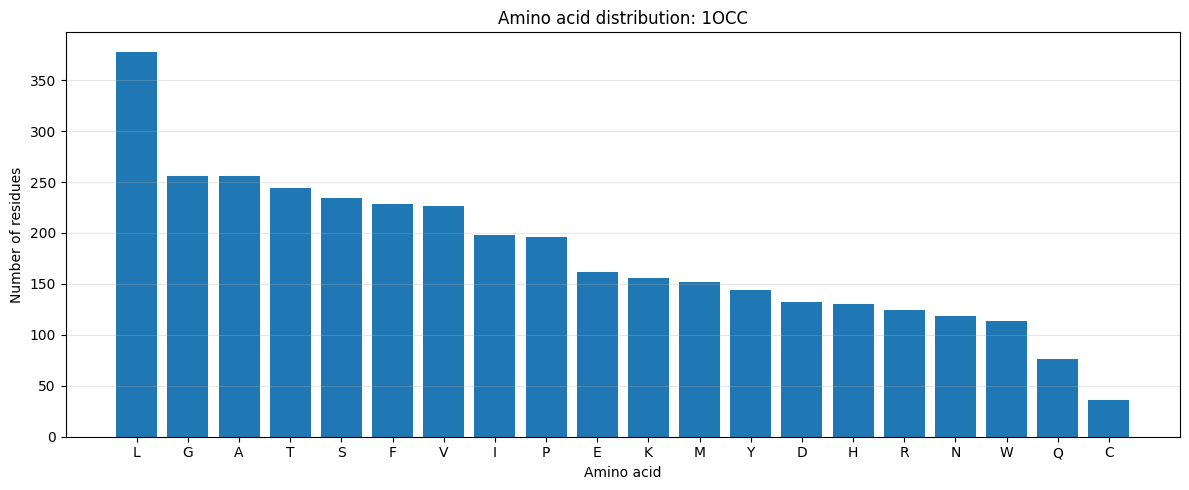

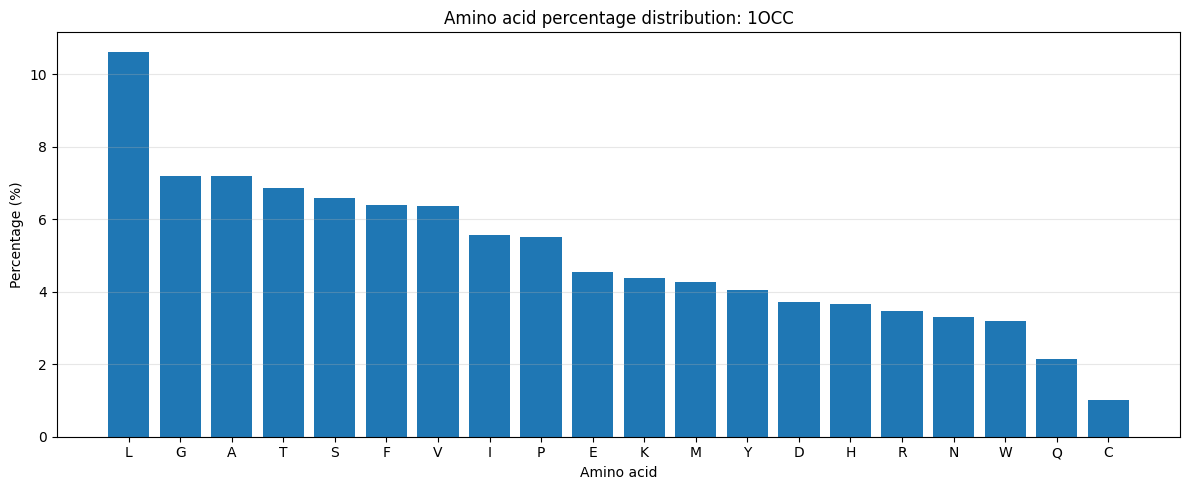

In [14]:
# ============================================================
# CELL 11. AMINO ACID DISTRIBUTION
# ============================================================
# Анализ аминокислотного состава белковой структуры.
#
# Распределение рассчитывается:
# - по всем белковым остаткам;
# - суммарно по всем цепям;
# - без включения небелковых компонентов и воды.
#
# Результаты:
# - количество остатков каждого типа;
# - процентное содержание;
# - накопительный процент;
# - CSV-таблица;
# - PNG-диаграмма.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path


print("=" * 70)
print("CELL 11. AMINO ACID DISTRIBUTION")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных данных
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "df_residues",
    "RESULTS_DIR"
]

for variable in required_variables:

    if variable not in globals():

        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )

if "amino_acid" not in df_residues.columns:

    raise ValueError(
        "В df_residues отсутствует столбец amino_acid."
    )

if df_residues.empty:

    raise ValueError(
        "Таблица df_residues пуста."
    )

RESULTS_DIR = Path(RESULTS_DIR)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(f"PDB ID: {PDB_ID}")
print(f"Количество записей в df_residues: {len(df_residues)}")


# ------------------------------------------------------------
# 2. Подготовка аминокислотных данных
# ------------------------------------------------------------

# Удаляем только пустые значения.
# Небелковые компоненты не должны присутствовать в df_residues,
# поскольку эта таблица была сформирована в CELL 6
# для белковых остатков.

amino_acid_series = (
    df_residues["amino_acid"]
    .dropna()
    .astype(str)
    .str.strip()
)

# Исключаем пустые строки и обозначения неизвестных остатков.
invalid_amino_acid_values = {
    "",
    "X",
    "UNK",
    "None",
    "nan"
}

valid_amino_acid_mask = (
    ~amino_acid_series.isin(invalid_amino_acid_values)
)

valid_amino_acid_series = (
    amino_acid_series[valid_amino_acid_mask]
)

excluded_amino_acid_count = (
    len(df_residues) - len(valid_amino_acid_series)
)

if valid_amino_acid_series.empty:

    raise ValueError(
        "Не найдено пригодных для анализа аминокислотных остатков."
    )


# ------------------------------------------------------------
# 3. Подсчёт количества аминокислот
# ------------------------------------------------------------

amino_acid_counts = (
    valid_amino_acid_series
    .value_counts()
    .sort_values(ascending=False)
)

amino_acid_distribution = pd.DataFrame({

    "amino_acid": amino_acid_counts.index,

    "count": amino_acid_counts.values

})


# ------------------------------------------------------------
# 4. Расчёт процентного содержания
# ------------------------------------------------------------

total_residues = int(
    amino_acid_distribution["count"].sum()
)

amino_acid_distribution["percentage"] = (

    amino_acid_distribution["count"]
    / total_residues
    * 100

).round(2)


# ------------------------------------------------------------
# 5. Накопительный процент
# ------------------------------------------------------------

amino_acid_distribution["cumulative_percentage"] = (

    amino_acid_distribution["percentage"]
    .cumsum()

).round(2)


# ------------------------------------------------------------
# 6. Дополнительная статистика
# ------------------------------------------------------------

number_of_amino_acid_types = len(
    amino_acid_distribution
)

most_common_amino_acid = (
    amino_acid_distribution.iloc[0]["amino_acid"]
)

most_common_amino_acid_count = int(
    amino_acid_distribution.iloc[0]["count"]
)

least_common_amino_acid = (
    amino_acid_distribution.iloc[-1]["amino_acid"]
)

least_common_amino_acid_count = int(
    amino_acid_distribution.iloc[-1]["count"]
)

percentage_sum = float(
    amino_acid_distribution["percentage"].sum()
)


# ------------------------------------------------------------
# 7. Сводная статистика по цепям
# ------------------------------------------------------------

if "chain_id" in df_residues.columns:

    chain_amino_acid_distribution = (

        df_residues[
            df_residues["amino_acid"].notna()
        ]

        .assign(
            amino_acid=lambda df:
                df["amino_acid"].astype(str).str.strip()
        )

        .loc[
            lambda df:
                ~df["amino_acid"].isin(
                    invalid_amino_acid_values
                )
        ]

        .groupby(
            ["chain_id", "amino_acid"]
        )

        .size()

        .reset_index(name="count")

        .sort_values(
            ["chain_id", "count"],
            ascending=[True, False]
        )

    )

else:

    chain_amino_acid_distribution = pd.DataFrame(
        columns=[
            "chain_id",
            "amino_acid",
            "count"
        ]
    )


# ------------------------------------------------------------
# 8. Вывод результатов
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("ОБЩЕЕ РАСПРЕДЕЛЕНИЕ АМИНОКИСЛОТ")
print("-" * 70)

display(amino_acid_distribution)

print(f"\nTotal amino acid residues: {total_residues}")

print(
    f"Number of amino acid types: "
    f"{number_of_amino_acid_types}"
)

print(
    f"Excluded records (missing/unknown): "
    f"{excluded_amino_acid_count}"
)

print(
    f"Most common amino acid: "
    f"{most_common_amino_acid} "
    f"({most_common_amino_acid_count})"
)

print(
    f"Least common amino acid: "
    f"{least_common_amino_acid} "
    f"({least_common_amino_acid_count})"
)

print(
    f"Sum of percentages: "
    f"{percentage_sum:.2f}%"
)


# ------------------------------------------------------------
# 9. Сохранение общей таблицы
# ------------------------------------------------------------

AMINO_ACID_CSV_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_amino_acid_distribution.csv"

)

amino_acid_csv_path = AMINO_ACID_CSV_PATH

amino_acid_distribution.to_csv(
    AMINO_ACID_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nAmino acid distribution saved:",
    AMINO_ACID_CSV_PATH
)


# ------------------------------------------------------------
# 10. Сохранение распределения по цепям
# ------------------------------------------------------------

AMINO_ACID_CHAIN_CSV_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_amino_acid_distribution_by_chain.csv"

)

chain_amino_acid_distribution.to_csv(
    AMINO_ACID_CHAIN_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Distribution by chain saved:",
    AMINO_ACID_CHAIN_CSV_PATH
)


# ------------------------------------------------------------
# 11. Диаграмма аминокислотного состава
# ------------------------------------------------------------

AMINO_ACID_PLOT_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_amino_acid_distribution.png"

)

amino_acid_plot_path = AMINO_ACID_PLOT_PATH

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.bar(
    amino_acid_distribution["amino_acid"],
    amino_acid_distribution["count"]
)

ax.set_title(
    f"Amino acid distribution: {PDB_ID}"
)

ax.set_xlabel("Amino acid")

ax.set_ylabel("Number of residues")

ax.tick_params(
    axis="x",
    rotation=0
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    AMINO_ACID_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ------------------------------------------------------------
# 12. Диаграмма процентного содержания
# ------------------------------------------------------------

AMINO_ACID_PERCENTAGE_PLOT_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_amino_acid_percentage.png"

)

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.bar(
    amino_acid_distribution["amino_acid"],
    amino_acid_distribution["percentage"]
)

ax.set_title(
    f"Amino acid percentage distribution: {PDB_ID}"
)

ax.set_xlabel("Amino acid")

ax.set_ylabel("Percentage (%)")

ax.tick_params(
    axis="x",
    rotation=0
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    AMINO_ACID_PERCENTAGE_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close(fig)


# ------------------------------------------------------------
# 13. Проверка результатов
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("VERIFICATION")
print("-" * 70)

print(
    "Rows in df_residues:",
    len(df_residues)
)

print(
    "Counted amino acid residues:",
    total_residues
)

print(
    "Excluded records:",
    excluded_amino_acid_count
)

print(
    "Percentage sum:",
    f"{percentage_sum:.2f}%"
)

# Проверяем арифметическую согласованность.
count_check = (
    total_residues + excluded_amino_acid_count
    == len(df_residues)
)

percentage_check = np.isclose(
    percentage_sum,
    100.0,
    atol=0.1
)

print(
    "Residue count check:",
    "OK" if count_check else "ERROR"
)

print(
    "Percentage check:",
    "OK" if percentage_check else "ERROR"
)

if not count_check or not percentage_check:

    raise ValueError(
        "Ошибка проверки распределения аминокислот."
    )


# ------------------------------------------------------------
# 14. Проверка сохранённых файлов
# ------------------------------------------------------------

output_paths = [

    AMINO_ACID_CSV_PATH,

    AMINO_ACID_CHAIN_CSV_PATH,

    AMINO_ACID_PLOT_PATH,

    AMINO_ACID_PERCENTAGE_PLOT_PATH

]

print("\nSaved files:")

for path in output_paths:

    print(
        f"{path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"
    )


# ------------------------------------------------------------
# 15. Итог
# ------------------------------------------------------------

print("\nИтог:")

print(
    "Распределение аминокислот рассчитано "
    "суммарно по всем белковым цепям."
)

print(
    "Дополнительно сформировано распределение "
    "по отдельным цепям."
)

print(
    "Неизвестные и отсутствующие обозначения "
    "не включены в процентный расчёт."
)

print("\nСтатус: OK")

print("=" * 70)
print("CELL 11 COMPLETED")
print("=" * 70)

In [15]:

# ============================================================
# CELL 12. SAVE ANALYSIS RESULTS
# ============================================================
# Централизованное сохранение результатов анализа структуры.
#
# Используются результаты предыдущих ячеек:
# - CELL 4: общая статистика структуры;
# - CELL 5: последовательности белковых цепей;
# - CELL 6: таблица белковых остатков;
# - CELL 7: таблица белковых атомов;
# - CELL 8: гетерокомпоненты и вода;
# - CELL 9: геометрические характеристики;
# - CELL 10: метаданные и качество;
# - CELL 11: распределение аминокислот.
#
# Особенности:
# - инвентаризация только файлов текущего PDB ID;
# - поддержка структур без гетерокомпонентов и воды;
# - безопасное преобразование NumPy и pandas в JSON;
# - корректная обработка отсутствующих необязательных данных.
# ============================================================

import json
import pandas as pd
import numpy as np

from pathlib import Path


print("=" * 70)
print("CELL 12. SAVE ANALYSIS RESULTS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка основных переменных
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "RESULTS_DIR",
    "chain_sequences",
    "df_residues",
    "df_atoms",
    "df_hetero",
    "df_water"
]

for variable in required_variables:

    if variable not in globals():

        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )


PDB_ID = str(PDB_ID).strip().upper()

if not PDB_ID:

    raise ValueError("PDB_ID не может быть пустым.")

RESULTS_DIR = Path(RESULTS_DIR)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print(f"PDB ID: {PDB_ID}")
print(f"Results directory: {RESULTS_DIR}")


# ------------------------------------------------------------
# 2. Функция преобразования значений для JSON
# ------------------------------------------------------------

def make_json_serializable(value):

    """
    Рекурсивно преобразует объекты NumPy и pandas
    в типы, поддерживаемые JSON.

    NaN, Infinity, NaT и pd.NA преобразуются в None.
    """

    if value is None:

        return None

    if isinstance(value, Path):

        return str(value)

    if isinstance(value, pd.DataFrame):

        return [
            make_json_serializable(record)
            for record in value.to_dict(orient="records")
        ]

    if isinstance(value, pd.Series):

        return make_json_serializable(
            value.to_dict()
        )

    if isinstance(value, dict):

        return {
            str(key): make_json_serializable(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple, set)):

        return [
            make_json_serializable(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):

        return make_json_serializable(
            value.tolist()
        )

    if isinstance(value, np.generic):

        return make_json_serializable(
            value.item()
        )

    if isinstance(value, (pd.Timestamp, pd.Timedelta)):

        return value.isoformat()

    if value is pd.NA or value is pd.NaT:

        return None

    if isinstance(value, float):

        if not np.isfinite(value):

            return None

        return value

    # Дополнительная проверка пропущенных значений pandas.
    try:

        missing_value = pd.isna(value)

        if isinstance(
            missing_value,
            (bool, np.bool_)
        ) and missing_value:

            return None

    except (TypeError, ValueError):

        pass

    return value


# ------------------------------------------------------------
# 3. Сбор информации о белковых цепях
# ------------------------------------------------------------

chain_lengths = {

    str(chain_id): len(sequence)

    for chain_id, sequence in chain_sequences.items()

}

chain_information = {

    "chains": list(chain_lengths.keys()),

    "chain_lengths": chain_lengths,

    "number_of_chains": len(chain_sequences),

    "total_sequence_length": sum(
        chain_lengths.values()
    )

}


# ------------------------------------------------------------
# 4. Сбор общей статистики структуры
# ------------------------------------------------------------

structure_summary = {

    "PDB_ID": PDB_ID,

    "number_of_models": (
        len(models)
        if "models" in globals()
        else None
    ),

    "number_of_chains": len(chain_sequences),

    "protein_residues": len(df_residues),

    "protein_atoms": len(df_atoms),

    "hetero_residues": len(df_hetero),

    "water_residues": len(df_water),

    "chain_information": chain_information

}


# ------------------------------------------------------------
# 5. Добавление геометрических характеристик
# ------------------------------------------------------------

if "geometry_summary" in globals():

    structure_summary["geometry"] = geometry_summary

elif "dimensions" in globals():

    structure_summary["geometry"] = {

        "coordinate_dimensions": np.asarray(
            dimensions
        ).tolist()

    }

else:

    structure_summary["geometry"] = None


# ------------------------------------------------------------
# 6. Добавление метаданных
# ------------------------------------------------------------

if "metadata" in globals():

    structure_summary["metadata"] = metadata

else:

    structure_summary["metadata"] = None


# ------------------------------------------------------------
# 7. Добавление результатов анализа качества
# ------------------------------------------------------------

quality_summary = {

    "unobserved_residue_records": (
        unobserved_residue_count
        if "unobserved_residue_count" in globals()
        else None
    ),

    "unobserved_atom_records": (
        unobserved_atom_count
        if "unobserved_atom_count" in globals()
        else None
    ),

    "residues_category_status": (
        residues_category_status
        if "residues_category_status" in globals()
        else "Not checked"
    ),

    "atoms_category_status": (
        atoms_category_status
        if "atoms_category_status" in globals()
        else "Not checked"
    )

}

structure_summary["quality_information"] = quality_summary


# ------------------------------------------------------------
# 8. Добавление аминокислотного состава
# ------------------------------------------------------------

if "amino_acid_distribution" in globals():

    distribution = amino_acid_distribution

    if isinstance(distribution, pd.DataFrame):

        structure_summary["amino_acid_distribution"] = {

            "number_of_amino_acid_types": len(distribution),

            "total_counted_residues": (
                int(distribution["count"].sum())
                if "count" in distribution.columns
                else None
            )

        }

    else:

        structure_summary["amino_acid_distribution"] = None

else:

    structure_summary["amino_acid_distribution"] = None


# ------------------------------------------------------------
# 9. Сохранение итоговой сводки JSON
# ------------------------------------------------------------

SUMMARY_JSON_PATH = (
    RESULTS_DIR / f"{PDB_ID}_summary.json"
)

summary = make_json_serializable(
    structure_summary
)

with open(
    SUMMARY_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

summary_path = SUMMARY_JSON_PATH

print("\nИтоговая сводка сохранена:")
print(SUMMARY_JSON_PATH)


# ------------------------------------------------------------
# 10. Сохранение краткой сводной таблицы CSV
# ------------------------------------------------------------

SUMMARY_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_summary.csv"
)

summary_table = pd.DataFrame([{

    "PDB_ID": PDB_ID,

    "Number of chains": len(chain_sequences),

    "Protein residues": len(df_residues),

    "Protein atoms": len(df_atoms),

    "Hetero residues": len(df_hetero),

    "Water residues": len(df_water),

    "Total sequence length": sum(chain_lengths.values())

}])

summary_table.to_csv(
    SUMMARY_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 11. Инвентаризация файлов текущего PDB ID
# ------------------------------------------------------------

# В общей папке могут находиться результаты нескольких белков.
# Поэтому учитываются только файлы, начинающиеся с PDB_ID_.
#
# Реестр OUTPUT_FILES_CSV_PATH исключается из собственного
# содержимого во избежание самоссылки при подсчёте размера.

OUTPUT_FILES_CSV_PATH = (
    RESULTS_DIR / f"{PDB_ID}_output_files.csv"
)

file_records = []

for path in sorted(RESULTS_DIR.iterdir()):

    if not path.is_file():

        continue

    if path == OUTPUT_FILES_CSV_PATH:

        continue

    if not path.name.startswith(f"{PDB_ID}_"):

        continue

    file_records.append({

        "file_name": path.name,

        "extension": path.suffix.lower(),

        "size_bytes": path.stat().st_size,

        "size_kb": round(
            path.stat().st_size / 1024,
            2
        ),

        "exists": True

    })


df_output_files = pd.DataFrame(
    file_records,
    columns=[
        "file_name",
        "extension",
        "size_bytes",
        "size_kb",
        "exists"
    ]
)


# ------------------------------------------------------------
# 12. Сохранение реестра файлов
# ------------------------------------------------------------

df_output_files.to_csv(
    OUTPUT_FILES_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nРеестр файлов сохранён:")
print(OUTPUT_FILES_CSV_PATH)

print(
    "Количество файлов текущего PDB ID "
    "(без самого реестра):",
    len(df_output_files)
)


# ------------------------------------------------------------
# 13. Вывод общей сводки
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("STRUCTURE SUMMARY")
print("-" * 70)

print(f"PDB ID: {PDB_ID}")

print(
    f"Number of chains: "
    f"{len(chain_sequences)}"
)

print(
    f"Protein residues: "
    f"{len(df_residues)}"
)

print(
    f"Protein atoms: "
    f"{len(df_atoms)}"
)

print(
    f"Hetero residues: "
    f"{len(df_hetero)}"
)

print(
    f"Water residues: "
    f"{len(df_water)}"
)

print("\nChain lengths:")

for chain_id, length in chain_lengths.items():

    print(
        f"Chain {chain_id}: {length} residues"
    )


# ------------------------------------------------------------
# 14. Вывод реестра файлов
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("OUTPUT FILES")
print("-" * 70)

display(df_output_files)


# ------------------------------------------------------------
# 15. Проверка основных файлов
# ------------------------------------------------------------

important_files = [

    SUMMARY_JSON_PATH,

    SUMMARY_CSV_PATH,

    OUTPUT_FILES_CSV_PATH

]

print("\nFile verification:")

all_files_exist = True

for path in important_files:

    exists = path.is_file()

    print(
        f"{path.name}: "
        f"{'OK' if exists else 'ERROR'}"
    )

    if not exists:

        all_files_exist = False

if not all_files_exist:

    raise RuntimeError(
        "Не все итоговые файлы были успешно сохранены."
    )


# ------------------------------------------------------------
# 16. Итог
# ------------------------------------------------------------

# Реестр не включает сам себя.
# При общем подсчёте добавляем его отдельно.

total_pdb_files = len(df_output_files) + 1

print("\n" + "-" * 70)

print("ANALYSIS RESULTS SAVED")

print(f"Results directory: {RESULTS_DIR}")

print(
    f"Number of output files for {PDB_ID}: "
    f"{total_pdb_files}"
)

print(
    "Files from other PDB structures: excluded"
)

print("\nСтатус: OK")

print("=" * 70)
print("CELL 12 COMPLETED")
print("=" * 70)


,file_name,extension,size_bytes,size_kb,exists
0,1OCC_all_final_metrics.csv,.csv,39090,38.17,True
1,1OCC_altloc_atoms.csv,.csv,126,0.12,True
2,1OCC_amino_acid_distribution.csv,.csv,410,0.40,True
3,1OCC_amino_acid_distribution.png,.png,83880,81.91,True
4,1OCC_amino_acid_distribution_by_chain.csv,.csv,3624,3.54,True
...,...,...,...,...,...
84,1OCC_unobserved_residues.csv,.csv,1987,1.94,True
85,1OCC_unobserved_summary.csv,.csv,215,0.21,True
86,1OCC_visualization.json,.json,1124,1.10,True
87,1OCC_water_atoms.csv,.csv,199,0.19,True


In [16]:
# ============================================================
# CELL 13. ПРОВЕРКА ПОСЛЕДОВАТЕЛЬНОСТИ БЕЛКА
# ============================================================
# Сравнение экспериментальных последовательностей,
# извлечённых из координатной модели, с референсными
# последовательностями из mmCIF.
#
# Анализ:
# - загрузка последовательностей polymer entities;
# - глобальное выравнивание;
# - процент идентичности;
# - покрытие референсной последовательности;
# - покрытие экспериментальной последовательности;
# - количество несовпадений и пропусков.
#
# Важно:
# Сравниваются последовательности, а не координаты атомов.
# Наличие пропуска в выравнивании само по себе не доказывает,
# что остаток отсутствует в экспериментальной модели.
# ============================================================

from Bio.Align import PairwiseAligner

import pandas as pd
import numpy as np

from pathlib import Path
import json


print("=" * 70)
print("CELL 13. ПРОВЕРКА ПОСЛЕДОВАТЕЛЬНОСТИ БЕЛКА")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных данных
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "CIF_PATH",
    "cif_dict",
    "chain_sequences",
    "RESULTS_DIR"
]

for variable in required_variables:

    if variable not in globals():

        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )

RESULTS_DIR = Path(RESULTS_DIR)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if not chain_sequences:

    raise ValueError(
        "Не найдены экспериментальные последовательности цепей."
    )

print(f"PDB ID: {PDB_ID}")
print(f"Number of experimental chains: {len(chain_sequences)}")


# ------------------------------------------------------------
# 2. Загрузка референсных последовательностей из mmCIF
# ------------------------------------------------------------

# Сначала используем канонические последовательности.
reference_sequences = cif_dict.get(
    "_entity_poly.pdbx_seq_one_letter_code_can",
    []
)

entity_ids = cif_dict.get(
    "_entity_poly.entity_id",
    []
)

reference_sequence_source = (
    "_entity_poly.pdbx_seq_one_letter_code_can"
)

# Если канонические последовательности отсутствуют,
# используем исходные последовательности polymer entities.
if not reference_sequences:

    reference_sequences = cif_dict.get(
        "_entity_poly.pdbx_seq_one_letter_code",
        []
    )

    reference_sequence_source = (
        "_entity_poly.pdbx_seq_one_letter_code"
    )


# Приводим данные к спискам.
if isinstance(reference_sequences, str):

    reference_sequences = [reference_sequences]

if isinstance(entity_ids, str):

    entity_ids = [entity_ids]


if not reference_sequences:

    raise ValueError(
        "В mmCIF не найдены референсные последовательности "
        "в категориях _entity_poly."
    )

if len(entity_ids) != len(reference_sequences):

    raise ValueError(
        "Количество entity_id не совпадает "
        "с количеством референсных последовательностей."
    )


# ------------------------------------------------------------
# 3. Подготовка референсных последовательностей
# ------------------------------------------------------------

reference_records = []

for entity_id, sequence in zip(
    entity_ids,
    reference_sequences
):

    sequence = (
        str(sequence)
        .replace("\n", "")
        .replace("\r", "")
        .replace(" ", "")
        .replace("\t", "")
        .upper()
    )

    if sequence:

        reference_records.append({

            "entity_id": str(entity_id),

            "sequence": sequence,

            "sequence_length": len(sequence),

            "sequence_source": reference_sequence_source

        })


df_reference = pd.DataFrame(
    reference_records
)

if df_reference.empty:

    raise ValueError(
        "После обработки не осталось референсных последовательностей."
    )


# ------------------------------------------------------------
# 4. Проверка референсных последовательностей
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("REFERENCE SEQUENCES")
print("-" * 70)

print(
    f"Reference sequence source: "
    f"{reference_sequence_source}"
)

print(
    f"Number of reference sequences: "
    f"{len(df_reference)}"
)

display(
    df_reference[
        [
            "entity_id",
            "sequence_length",
            "sequence_source"
        ]
    ]
)


# ------------------------------------------------------------
# 5. Настройка алгоритма глобального выравнивания
# ------------------------------------------------------------

aligner = PairwiseAligner()

aligner.mode = "global"

aligner.match_score = 2.0

aligner.mismatch_score = -1.0

aligner.open_gap_score = -3.0

aligner.extend_gap_score = -0.5


# ------------------------------------------------------------
# 6. Функция подготовки последовательности
# ------------------------------------------------------------

def normalize_sequence(sequence):

    """
    Удаляет пробельные символы и приводит последовательность
    к верхнему регистру.
    """

    return (
        str(sequence)
        .replace("\n", "")
        .replace("\r", "")
        .replace(" ", "")
        .replace("\t", "")
        .upper()
    )


# ------------------------------------------------------------
# 7. Функция анализа одного выравнивания
# ------------------------------------------------------------

def calculate_alignment_metrics(
    reference_sequence,
    experimental_sequence,
    alignment
):

    """
    Рассчитывает характеристики глобального выравнивания.
    """

    alignment_indices = alignment.indices

    reference_indices = alignment_indices[0]

    experimental_indices = alignment_indices[1]

    # Позиции, где обе последовательности содержат остаток.
    paired_positions = (

        (reference_indices >= 0)
        &
        (experimental_indices >= 0)

    )

    # Позиции, где обе последовательности имеют остаток.
    aligned_count = int(
        paired_positions.sum()
    )

    if aligned_count == 0:

        raise ValueError(
            "Выравнивание не содержит сопоставленных позиций."
        )

    paired_reference_indices = (
        reference_indices[paired_positions]
    )

    paired_experimental_indices = (
        experimental_indices[paired_positions]
    )

    # Количество совпадающих аминокислот.
    matches = sum(

        reference_sequence[ref_idx]
        == experimental_sequence[exp_idx]

        for ref_idx, exp_idx in zip(
            paired_reference_indices,
            paired_experimental_indices
        )

    )

    mismatches = aligned_count - matches

    # Процент идентичности среди сопоставленных остатков.
    identity = (
        matches / aligned_count * 100
    )

    # Покрытие референсной последовательности.
    reference_coverage = (

        len(set(paired_reference_indices))
        / len(reference_sequence)
        * 100

    )

    # Покрытие экспериментальной последовательности.
    experimental_coverage = (

        len(set(paired_experimental_indices))
        / len(experimental_sequence)
        * 100

    )

    # Позиции референса, которым соответствует gap
    # в экспериментальной последовательности.
    missing_reference = int(

        np.sum(
            (reference_indices >= 0)
            &
            (experimental_indices < 0)
        )

    )

    # Позиции экспериментальной последовательности,
    # которым соответствует gap в референсе.
    extra_experimental = int(

        np.sum(
            (reference_indices < 0)
            &
            (experimental_indices >= 0)
        )

    )

    # Нормализованный alignment score.
    # Нормализация позволяет сравнивать выравнивания
    # последовательностей разной длины.

    reference_self_score = aligner.score(
        reference_sequence,
        reference_sequence
    )

    experimental_self_score = aligner.score(
        experimental_sequence,
        experimental_sequence
    )

    normalization_score = max(
        reference_self_score,
        experimental_self_score
    )

    normalized_score = (

        alignment.score / normalization_score

        if normalization_score > 0

        else 0

    )

    return {

        "alignment_score": float(alignment.score),

        "normalized_score": float(normalized_score),

        "matches": int(matches),

        "mismatches": int(mismatches),

        "aligned_positions": aligned_count,

        "identity_percent": float(identity),

        "reference_coverage_percent": float(
            reference_coverage
        ),

        "experimental_coverage_percent": float(
            experimental_coverage
        ),

        "missing_reference_residues": missing_reference,

        "extra_experimental_residues": extra_experimental

    }


# ------------------------------------------------------------
# 8. Сравнение последовательностей
# ------------------------------------------------------------

sequence_comparison_records = []

best_alignments = {}

best_alignment_details = {}

for chain_id, experimental_sequence in chain_sequences.items():

    experimental_sequence = normalize_sequence(
        experimental_sequence
    )

    if not experimental_sequence:

        print(
            f"WARNING: Chain {chain_id} has an empty sequence."
        )

        continue

    best_result = None

    best_alignment = None

    best_reference_sequence = None

    print(
        f"\nProcessing chain {chain_id} "
        f"({len(experimental_sequence)} residues)"
    )

    for _, reference in df_reference.iterrows():

        reference_sequence = reference["sequence"]

        if not reference_sequence:
            continue

        # Глобальное выравнивание.
        alignment = aligner.align(
            reference_sequence,
            experimental_sequence
        )[0]

        metrics = calculate_alignment_metrics(
            reference_sequence,
            experimental_sequence,
            alignment
        )

        result = {

            "chain_id": str(chain_id),

            "entity_id": reference["entity_id"],

            "reference_length": len(reference_sequence),

            "experimental_length": len(experimental_sequence),

            "reference_sequence": reference_sequence,

            "experimental_sequence": experimental_sequence,

            **metrics

        }

        # Выбор наиболее подходящей референсной последовательности.
        # Основной критерий — нормализованный score.
        # При равенстве учитываются identity и покрытие.

        result_rank = (

            result["normalized_score"],

            result["identity_percent"],

            min(
                result["reference_coverage_percent"],
                result["experimental_coverage_percent"]
            )

        )

        if best_result is None:

            best_result = result

            best_alignment = alignment

            best_reference_sequence = reference_sequence

            best_rank = result_rank

        elif result_rank > best_rank:

            best_result = result

            best_alignment = alignment

            best_reference_sequence = reference_sequence

            best_rank = result_rank


    if best_result is None:

        print(
            f"WARNING: No reference sequence matched chain {chain_id}."
        )

        continue

    sequence_comparison_records.append({

        "chain_id": best_result["chain_id"],

        "entity_id": best_result["entity_id"],

        "reference_length": best_result["reference_length"],

        "experimental_length": best_result["experimental_length"],

        "alignment_score": best_result["alignment_score"],

        "normalized_score": round(
            best_result["normalized_score"],
            4
        ),

        "matches": best_result["matches"],

        "mismatches": best_result["mismatches"],

        "identity_percent": round(
            best_result["identity_percent"],
            2
        ),

        "reference_coverage_percent": round(
            best_result["reference_coverage_percent"],
            2
        ),

        "experimental_coverage_percent": round(
            best_result["experimental_coverage_percent"],
            2
        ),

        "aligned_positions": best_result["aligned_positions"],

        "missing_reference_residues": (
            best_result["missing_reference_residues"]
        ),

        "extra_experimental_residues": (
            best_result["extra_experimental_residues"]
        )

    })

    best_alignments[chain_id] = best_alignment

    best_alignment_details[chain_id] = {

        "entity_id": best_result["entity_id"],

        "reference_sequence": best_reference_sequence,

        "experimental_sequence": experimental_sequence,

        "alignment": best_alignment,

        "metrics": best_result

    }


# ------------------------------------------------------------
# 9. Итоговая таблица сравнения
# ------------------------------------------------------------

df_reference_sequence_comparison = pd.DataFrame(
    sequence_comparison_records
)

if df_reference_sequence_comparison.empty:

    raise ValueError(
        "Не удалось выполнить сравнение ни для одной цепи."
    )


print("\n" + "-" * 70)
print("REFERENCE SEQUENCE COMPARISON RESULTS")
print("-" * 70)

display(
    df_reference_sequence_comparison
)


# ------------------------------------------------------------
# 10. Сохранение результатов сравнения
# ------------------------------------------------------------

REFERENCE_SEQUENCE_CSV_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_reference_sequences.csv"

)

SEQUENCE_COMPARISON_CSV_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_reference_sequence_comparison.csv"

)

df_reference.to_csv(
    REFERENCE_SEQUENCE_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_reference_sequence_comparison.to_csv(
    SEQUENCE_COMPARISON_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 11. Сохранение текстовых выравниваний
# ------------------------------------------------------------

ALIGNMENTS_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_sequence_alignments.txt"

)

with open(
    ALIGNMENTS_PATH,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        f"REFERENCE SEQUENCE ALIGNMENTS: {PDB_ID}\n"
    )

    file.write("=" * 80 + "\n\n")

    for chain_id, details in best_alignment_details.items():

        file.write(
            f"CHAIN: {chain_id}\n"
        )

        file.write(
            f"ENTITY ID: {details['entity_id']}\n"
        )

        file.write(
            f"REFERENCE LENGTH: "
            f"{len(details['reference_sequence'])}\n"
        )

        file.write(
            f"EXPERIMENTAL LENGTH: "
            f"{len(details['experimental_sequence'])}\n"
        )

        file.write(
            f"IDENTITY: "
            f"{details['metrics']['identity_percent']:.2f}%\n"
        )

        file.write(
            f"REFERENCE COVERAGE: "
            f"{details['metrics']['reference_coverage_percent']:.2f}%\n"
        )

        file.write(
            f"EXPERIMENTAL COVERAGE: "
            f"{details['metrics']['experimental_coverage_percent']:.2f}%\n\n"
        )

        file.write(
            str(details["alignment"])
        )

        file.write("\n\n")

        file.write("-" * 80 + "\n\n")


# ------------------------------------------------------------
# 12. Интерпретация результатов
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("INTERPRETATION")
print("-" * 70)

for _, row in df_reference_sequence_comparison.iterrows():

    print(
        f"\nChain: {row['chain_id']}"
    )

    print(
        f"Reference entity: {row['entity_id']}"
    )

    print(
        f"Sequence identity: "
        f"{row['identity_percent']:.2f}%"
    )

    print(
        f"Reference coverage: "
        f"{row['reference_coverage_percent']:.2f}%"
    )

    print(
        f"Experimental coverage: "
        f"{row['experimental_coverage_percent']:.2f}%"
    )

    print(
        f"Aligned positions: "
        f"{row['aligned_positions']}"
    )

    print(
        f"Missing reference positions in alignment: "
        f"{row['missing_reference_residues']}"
    )

    print(
        f"Extra experimental positions in alignment: "
        f"{row['extra_experimental_residues']}"
    )

    if (
        row["identity_percent"] >= 99
        and row["reference_coverage_percent"] >= 99
        and row["experimental_coverage_percent"] >= 99
    ):

        print(
            "The experimental and reference sequences "
            "show almost complete correspondence."
        )

    elif row["identity_percent"] >= 95:

        print(
            "The sequences show high identity, "
            "but some differences or coverage gaps are present."
        )

    else:

        print(
            "The sequences show noticeable differences. "
            "The alignment should be examined."
        )


# ------------------------------------------------------------
# 13. Контроль соответствия цепей
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("CHAIN VALIDATION")
print("-" * 70)

experimental_chain_ids = set(
    chain_sequences.keys()
)

compared_chain_ids = set(
    df_reference_sequence_comparison["chain_id"]
)

not_compared_chains = (
    experimental_chain_ids - compared_chain_ids
)

print(
    f"Experimental chains: "
    f"{sorted(experimental_chain_ids)}"
)

print(
    f"Compared chains: "
    f"{sorted(compared_chain_ids)}"
)

if not_compared_chains:

    print(
        "WARNING: Some chains were not compared:",
        sorted(not_compared_chains)
    )

else:

    print(
        "All experimental chains were compared."
    )


# ------------------------------------------------------------
# 14. Сохранение краткой JSON-сводки
# ------------------------------------------------------------

SEQUENCE_VALIDATION_JSON_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_sequence_validation.json"

)

sequence_validation_summary = {

    "PDB_ID": PDB_ID,

    "reference_sequence_source": reference_sequence_source,

    "number_of_reference_sequences": len(df_reference),

    "number_of_experimental_chains": len(chain_sequences),

    "number_of_compared_chains": len(
        df_reference_sequence_comparison
    ),

    "not_compared_chains": sorted(
        map(str, not_compared_chains)
    ),

    "results": (
        df_reference_sequence_comparison
        .to_dict(orient="records")
    )

}

with open(
    SEQUENCE_VALIDATION_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        sequence_validation_summary,
        file,
        ensure_ascii=False,
        indent=4,
        default=str
    )


# ------------------------------------------------------------
# 15. Проверка сохранённых файлов
# ------------------------------------------------------------

output_paths = [

    REFERENCE_SEQUENCE_CSV_PATH,

    SEQUENCE_COMPARISON_CSV_PATH,

    ALIGNMENTS_PATH,

    SEQUENCE_VALIDATION_JSON_PATH

]

print("\n" + "-" * 70)
print("SAVED FILES")
print("-" * 70)

for path in output_paths:

    print(
        f"{path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"
    )

if not all(path.is_file() for path in output_paths):

    raise RuntimeError(
        "Не все результаты проверки последовательностей сохранены."
    )


# ------------------------------------------------------------
# 16. Итог
# ------------------------------------------------------------

print("\nИтог:")

print(
    "Экспериментальные последовательности сопоставлены "
    "с референсными последовательностями из mmCIF."
)

print(
    "Результаты выравнивания, таблицы и сводка сохранены."
)

print(
    "Пропуски в выравнивании не интерпретируются "
    "автоматически как отсутствующие в модели остатки."
)

print("\nСтатус: OK")

print("=" * 70)
print("CELL 13 COMPLETED")
print("=" * 70)

,entity_id,sequence_length,sequence_source
0,1,514,_entity_poly.pdbx_seq_one_letter_code_can
1,2,227,_entity_poly.pdbx_seq_one_letter_code_can
2,3,261,_entity_poly.pdbx_seq_one_letter_code_can
3,4,147,_entity_poly.pdbx_seq_one_letter_code_can
4,5,109,_entity_poly.pdbx_seq_one_letter_code_can
5,6,98,_entity_poly.pdbx_seq_one_letter_code_can
6,7,84,_entity_poly.pdbx_seq_one_letter_code_can
7,8,85,_entity_poly.pdbx_seq_one_letter_code_can
8,9,73,_entity_poly.pdbx_seq_one_letter_code_can
9,10,59,_entity_poly.pdbx_seq_one_letter_code_can


,chain_id,entity_id,reference_length,experimental_length,alignment_score,normalized_score,matches,mismatches,identity_percent,reference_coverage_percent,experimental_coverage_percent,aligned_positions,missing_reference_residues,extra_experimental_residues
0,A,1,514,514,1028.0,1.0000,514,0,100.0,100.00,100.0,514,0,0
1,B,2,227,227,454.0,1.0000,227,0,100.0,100.00,100.0,227,0,0
2,C,3,261,261,522.0,1.0000,261,0,100.0,100.00,100.0,261,0,0
3,D,4,147,144,284.0,0.9660,144,0,100.0,97.96,100.0,144,3,0
4,E,5,109,109,218.0,1.0000,109,0,100.0,100.00,100.0,109,0,0
5,F,6,98,98,196.0,1.0000,98,0,100.0,100.00,100.0,98,0,0
6,G,7,84,84,168.0,1.0000,84,0,100.0,100.00,100.0,84,0,0
7,H,8,85,75,142.5,0.8382,75,0,100.0,88.24,100.0,75,10,0
8,I,9,73,73,146.0,1.0000,73,0,100.0,100.00,100.0,73,0,0
9,J,10,59,56,108.0,0.9153,56,0,100.0,94.92,100.0,56,3,0


Что анализируем: экспериментальная последовательность может быть короче референсной, потому что некоторые участки белка не удалось определить в экспериментальной структуре.

Важно: приведённое выравнивание показывает сходство и длины последовательностей, но для точного подсчёта пропущенных остатков нужно учитывать соответствие цепей и нумерацию остатков. Это сделаем в следующей ячейке.
Что теперь будет в результатах
Показатель	Значение
reference_length	Длина референсной последовательности
experimental_length	Длина экспериментальной последовательности
alignment_score	Оценка качества выравнивания
identity_percent	Процент совпадения аминокислот
reference_coverage_percent	Процент покрытия референсной последовательности
experimental_coverage_percent	Процент покрытия экспериментальной последовательности
aligned_positions	Количество сопоставленных позиций
missing_reference_residues	Количество позиций референса без соответствующего остатка в экспериментальной последовательности
extra_experimental_residues	Количество экспериментальных позиций без соответствия в референсе

Важное замечание
Здесь сравниваются две последовательности:
- референсная — полная последовательность белка из аннотации PDB;
- экспериментальная — последовательность, извлечённая из атомной структуры.
Если часть белка не видна в экспериментальной структуре, она может отсутствовать в экспериментальной последовательности. Это не обязательно означает, что белок был повреждён: такие участки могут быть просто не разрешены экспериментальным методом.

,record_id,chain_id,residue_name,sequence_id,insertion_code,model_number
0,1,D,ALA,1,None,1
1,2,D,HIS,2,None,1
2,3,D,GLY,3,None,1
3,4,H,ALA,1,None,1
4,5,H,GLU,2,None,1
5,6,H,ASP,3,None,1
6,7,H,ILE,4,None,1
7,8,H,GLN,5,None,1
8,9,H,ALA,6,None,1
9,10,H,LYS,7,None,1


,model_number,chain_id,residue_key,residue_id,insertion_code,residue_name,atom_name,element,x,y,z,occupancy,bfactor,altloc


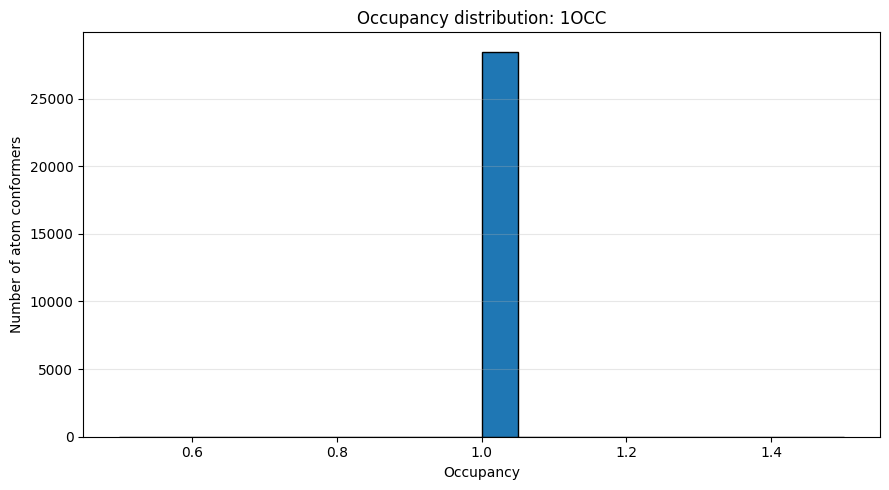

,chain_id,atom_conformer_count,unique_residue_count,unique_atom_site_count,altloc_atom_record_count,altloc_unique_site_count,low_occupancy_count,missing_occupancy_count,invalid_occupancy_count
0,A,4025,514,4025,0,0,0,0,0
1,B,1822,227,1822,0,0,0,0,0
2,C,2124,261,2124,0,0,0,0,0
3,D,1195,144,1195,0,0,0,0,0
4,E,878,109,878,0,0,0,0,0
5,F,748,98,748,0,0,0,0,0
6,G,672,84,672,0,0,0,0,0
7,H,628,75,628,0,0,0,0,0
8,I,598,73,598,0,0,0,0,0
9,J,441,56,441,0,0,0,0,0


,Parameter,Value
0,Observed protein atom conformer records,28472
1,Unique protein atom sites,28472
2,Additional conformer records,0
3,Observed protein residues,3560
4,Unobserved / zero-occupancy residue records,52
5,Unobserved / zero-occupancy atom records,0
6,Atom records with alternative positions,0
7,Unique atom sites with alternative positions,0
8,Atom records with occupancy < 0.99,0
9,Atom records with missing occupancy,0


In [17]:

# ============================================================
# CELL 14. АНАЛИЗ ПОЛНОТЫ СТРУКТУРЫ И АЛЬТЕРНАТИВНЫХ ПОЛОЖЕНИЙ
# ============================================================
# Анализ:
# - неразрешённых или имеющих нулевую occupancy позиций;
# - альтернативных положений атомов (altloc);
# - распределения occupancy;
# - качества структуры по цепям;
# - полноты экспериментальной модели.
#
# Особенности:
# 1. Используются все альтернативные положения атомов.
# 2. Различаются атомные конформеры и уникальные позиции атомов.
# 3. Некорректные occupancy отделяются от низких occupancy.
# 4. Учитываются структуры с отсутствующими mmCIF-категориями.
# 5. Поддерживаются структуры с несколькими цепями и моделями.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from pathlib import Path
from Bio.PDB.Polypeptide import is_aa


print("=" * 70)
print("CELL 14. АНАЛИЗ ПОЛНОТЫ СТРУКТУРЫ")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных данных
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "cif_dict",
    "structure",
    "df_atoms",
    "RESULTS_DIR"
]

for variable in required_variables:

    if variable not in globals():

        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )


RESULTS_DIR = Path(RESULTS_DIR)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

required_atom_columns = {
    "chain_id",
    "residue_id",
    "insertion_code",
    "atom_name",
    "element",
    "occupancy",
    "altloc"
}

missing_columns = (
    required_atom_columns - set(df_atoms.columns)
)

if missing_columns:

    raise KeyError(
        "В df_atoms отсутствуют необходимые столбцы: "
        f"{sorted(missing_columns)}"
    )


print(f"PDB ID: {PDB_ID}")
print(f"Protein atoms in CELL 7: {len(df_atoms)}")


# ------------------------------------------------------------
# 2. Вспомогательные функции для mmCIF
# ------------------------------------------------------------

def get_cif_list(key):

    value = cif_dict.get(key, [])

    if value is None:
        return []

    if isinstance(value, (list, tuple, np.ndarray)):
        return list(value)

    return [value]


def clean_cif_value(value):

    if value is None:
        return None

    value = str(value).strip()

    if value in {"", ".", "?"}:
        return None

    return value


def get_first_available_cif_list(keys):

    """
    Выбирает первое поле, содержащее реальные значения.

    Если поле существует, но заполнено только '.' или '?',
    проверяется следующий вариант.
    """

    for key in keys:

        values = get_cif_list(key)

        if not values:
            continue

        cleaned = [
            clean_cif_value(value)
            for value in values
        ]

        if any(value is not None for value in cleaned):

            return cleaned, key

    return [], None


def category_exists(prefix):

    return any(
        key.startswith(prefix)
        for key in cif_dict.keys()
    )


def build_unobserved_dataframe(field_mapping):

    """
    Формирует таблицу записей mmCIF.

    Полностью пустые строки исключаются.
    """

    columns_data = {}

    max_length = 0

    for column_name, possible_keys in field_mapping.items():

        values, source_key = get_first_available_cif_list(
            possible_keys
        )

        columns_data[column_name] = values

        max_length = max(
            max_length,
            len(values)
        )

    records = []

    for i in range(max_length):

        record = {}

        for column_name, values in columns_data.items():

            value = (
                values[i]
                if i < len(values)
                else None
            )

            record[column_name] = clean_cif_value(value)

        # Не учитываем полностью пустые записи.
        if any(value is not None for value in record.values()):

            records.append(record)

    df = pd.DataFrame(
        records,
        columns=list(field_mapping.keys())
    )

    return df, len(df)


# ------------------------------------------------------------
# 3. Анализ неразрешённых остатков
# ------------------------------------------------------------

RESIDUE_CATEGORY = (
    "_pdbx_unobs_or_zero_occ_residues."
)

residue_category_present = category_exists(
    RESIDUE_CATEGORY
)

residue_field_mapping = {

    "record_id": [
        "_pdbx_unobs_or_zero_occ_residues.id"
    ],

    "chain_id": [
        "_pdbx_unobs_or_zero_occ_residues.auth_asym_id",
        "_pdbx_unobs_or_zero_occ_residues.label_asym_id"
    ],

    "residue_name": [
        "_pdbx_unobs_or_zero_occ_residues.auth_comp_id",
        "_pdbx_unobs_or_zero_occ_residues.label_comp_id"
    ],

    "sequence_id": [
        "_pdbx_unobs_or_zero_occ_residues.auth_seq_id",
        "_pdbx_unobs_or_zero_occ_residues.label_seq_id"
    ],

    "insertion_code": [
        "_pdbx_unobs_or_zero_occ_residues.PDB_ins_code"
    ],

    "model_number": [
        "_pdbx_unobs_or_zero_occ_residues.PDB_model_num"
    ]

}

df_missing_residues, residue_record_count = (
    build_unobserved_dataframe(
        residue_field_mapping
    )
)

print("\n" + "-" * 70)
print("UNOBSERVED OR ZERO-OCCUPANCY RESIDUES")
print("-" * 70)

print(
    f"Category present in mmCIF: "
    f"{residue_category_present}"
)

print(
    f"Number of records: {residue_record_count}"
)

if not df_missing_residues.empty:

    display(
        df_missing_residues.head(20)
    )

else:

    print(
        "No records extracted from this category."
    )

if not residue_category_present:

    print(
        "The category is absent. "
        "This does not prove that all residues are observed."
    )


# ------------------------------------------------------------
# 4. Анализ неразрешённых атомов
# ------------------------------------------------------------

ATOM_CATEGORY = (
    "_pdbx_unobs_or_zero_occ_atoms."
)

atom_category_present = category_exists(
    ATOM_CATEGORY
)

atom_field_mapping = {

    "record_id": [
        "_pdbx_unobs_or_zero_occ_atoms.id"
    ],

    "chain_id": [
        "_pdbx_unobs_or_zero_occ_atoms.auth_asym_id",
        "_pdbx_unobs_or_zero_occ_atoms.label_asym_id"
    ],

    "residue_name": [
        "_pdbx_unobs_or_zero_occ_atoms.auth_comp_id",
        "_pdbx_unobs_or_zero_occ_atoms.label_comp_id"
    ],

    "sequence_id": [
        "_pdbx_unobs_or_zero_occ_atoms.auth_seq_id",
        "_pdbx_unobs_or_zero_occ_atoms.label_seq_id"
    ],

    "atom_name": [
        "_pdbx_unobs_or_zero_occ_atoms.auth_atom_id",
        "_pdbx_unobs_or_zero_occ_atoms.label_atom_id"
    ],

    "insertion_code": [
        "_pdbx_unobs_or_zero_occ_atoms.PDB_ins_code"
    ],

    "model_number": [
        "_pdbx_unobs_or_zero_occ_atoms.PDB_model_num"
    ]

}

df_missing_atoms, atom_record_count = (
    build_unobserved_dataframe(
        atom_field_mapping
    )
)

print("\n" + "-" * 70)
print("UNOBSERVED OR ZERO-OCCUPANCY ATOMS")
print("-" * 70)

print(
    f"Category present in mmCIF: "
    f"{atom_category_present}"
)

print(
    f"Number of records: {atom_record_count}"
)

if not df_missing_atoms.empty:

    display(
        df_missing_atoms.head(20)
    )

else:

    print(
        "No records extracted from this category."
    )

if not atom_category_present:

    print(
        "The category is absent. "
        "No conclusion about missing atoms can be made."
    )


# ------------------------------------------------------------
# 5. Извлечение всех белковых атомных конформеров
# ------------------------------------------------------------

# get_unpacked_list() позволяет получить все варианты
# DisorderedAtom, а не только выбранный вариант.

all_atom_records = []

for model in structure:

    for chain in model:

        for residue in chain:

            if not is_aa(
                residue,
                standard=False
            ):
                continue

            residue_id = residue.id[1]

            insertion_code = (
                str(residue.id[2]).strip()
                if residue.id[2] is not None
                else ""
            )

            residue_name = residue.resname.strip()

            residue_key = (
                f"{chain.id}:"
                f"{residue_id}:"
                f"{insertion_code}"
            )

            unpacked_atoms = residue.get_unpacked_list()

            for atom in unpacked_atoms:

                altloc = str(
                    atom.get_altloc()
                ).strip()

                if altloc in {"", ".", "?"}:
                    altloc = None

                occupancy = atom.get_occupancy()

                try:

                    occupancy = (
                        float(occupancy)
                        if occupancy is not None
                        else np.nan
                    )

                except (TypeError, ValueError):

                    occupancy = np.nan

                element = str(
                    atom.element
                ).strip().upper()

                all_atom_records.append({

                    "model_number": model.id + 1,

                    "chain_id": str(chain.id),

                    "residue_key": residue_key,

                    "residue_id": residue_id,

                    "insertion_code": insertion_code,

                    "residue_name": residue_name,

                    "atom_name": atom.get_name().strip(),

                    "element": element,

                    "x": float(atom.coord[0]),

                    "y": float(atom.coord[1]),

                    "z": float(atom.coord[2]),

                    "occupancy": occupancy,

                    "bfactor": atom.get_bfactor(),

                    "altloc": altloc

                })


df_atom_quality = pd.DataFrame(
    all_atom_records
)

if df_atom_quality.empty:

    raise ValueError(
        "Не удалось извлечь белковые атомы из структуры."
    )


# ------------------------------------------------------------
# 6. Уникальные атомные позиции и altloc
# ------------------------------------------------------------

atom_site_columns = [

    "model_number",

    "chain_id",

    "residue_key",

    "atom_name"

]

# Все альтернативные варианты одной атомной позиции
# считаются отдельными атомными конформерами.

unique_atom_sites = (
    df_atom_quality[
        atom_site_columns
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

unique_atom_site_count = len(unique_atom_sites)

altloc_site_columns = atom_site_columns

df_altloc = df_atom_quality[
    df_atom_quality["altloc"].notna()
].copy()

altloc_atom_record_count = len(df_altloc)

if not df_altloc.empty:

    df_altloc_sites = (
        df_altloc[
            altloc_site_columns
        ]
        .drop_duplicates()
        .reset_index(drop=True)
    )

else:

    df_altloc_sites = pd.DataFrame(
        columns=altloc_site_columns
    )

altloc_unique_site_count = len(
    df_altloc_sites
)

# Разница между всеми конформерами и уникальными позициями.
extra_conformer_records = (
    len(df_atom_quality) - unique_atom_site_count
)


print("\n" + "-" * 70)
print("ALTERNATIVE ATOM POSITIONS")
print("-" * 70)

print(
    f"All protein atom conformer records: "
    f"{len(df_atom_quality)}"
)

print(
    f"Unique protein atom sites: "
    f"{unique_atom_site_count}"
)

print(
    f"Additional conformer records: "
    f"{extra_conformer_records}"
)

print(
    f"Atom records with altloc labels: "
    f"{altloc_atom_record_count}"
)

print(
    f"Unique atom sites with altloc: "
    f"{altloc_unique_site_count}"
)

if not df_altloc.empty:

    print("\nAlternative location labels:")

    display(
        df_altloc["altloc"]
        .value_counts()
        .rename_axis("altloc")
        .reset_index(name="atom_record_count")
    )

    print("\nAlternative atom records:")

    display(
        df_altloc.head(30)
    )

else:

    print(
        "No alternative atom positions were found."
    )


# ------------------------------------------------------------
# 7. Анализ occupancy
# ------------------------------------------------------------

# Сначала выделяем все известные значения occupancy.

df_occupancy_known = df_atom_quality[
    df_atom_quality["occupancy"].notna()
].copy()

# Некорректные значения находятся за пределами [0, 1].

df_invalid_occupancy = df_occupancy_known[
    (
        df_occupancy_known["occupancy"] < 0
    )
    |
    (
        df_occupancy_known["occupancy"] > 1
    )
].copy()

# Для статистики используются только допустимые значения.

df_occupancy_valid = df_occupancy_known[
    (
        df_occupancy_known["occupancy"] >= 0
    )
    &
    (
        df_occupancy_known["occupancy"] <= 1
    )
].copy()

# Низкая occupancy: от 0 включительно до 0.99.

df_low_occupancy = df_occupancy_valid[
    df_occupancy_valid["occupancy"] < 0.99
].copy()

df_missing_occupancy = df_atom_quality[
    df_atom_quality["occupancy"].isna()
].copy()


print("\n" + "-" * 70)
print("OCCUPANCY ANALYSIS")
print("-" * 70)

print(
    f"Atoms with known occupancy: "
    f"{len(df_occupancy_known)}"
)

print(
    f"Atoms with valid occupancy [0, 1]: "
    f"{len(df_occupancy_valid)}"
)

print(
    f"Atoms with occupancy < 0.99: "
    f"{len(df_low_occupancy)}"
)

print(
    f"Atoms with missing occupancy: "
    f"{len(df_missing_occupancy)}"
)

print(
    f"Atoms with invalid occupancy: "
    f"{len(df_invalid_occupancy)}"
)

if not df_occupancy_valid.empty:

    print(
        f"\nMean occupancy: "
        f"{df_occupancy_valid['occupancy'].mean():.4f}"
    )

    print(
        f"Median occupancy: "
        f"{df_occupancy_valid['occupancy'].median():.4f}"
    )

    print(
        f"Minimum occupancy: "
        f"{df_occupancy_valid['occupancy'].min():.4f}"
    )

    print(
        f"Maximum occupancy: "
        f"{df_occupancy_valid['occupancy'].max():.4f}"
    )

    print("\nExamples of low occupancy atoms:")

    display(
        df_low_occupancy.head(30)
    )


# ------------------------------------------------------------
# 8. Распределение occupancy
# ------------------------------------------------------------

OCCUPANCY_PLOT_PATH = (
    RESULTS_DIR
    / f"{PDB_ID}_occupancy_distribution.png"
)

if not df_occupancy_valid.empty:

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.hist(
        df_occupancy_valid["occupancy"],
        bins=20,
        edgecolor="black"
    )

    ax.set_xlabel("Occupancy")
    ax.set_ylabel("Number of atom conformers")

    ax.set_title(
        f"Occupancy distribution: {PDB_ID}"
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        OCCUPANCY_PLOT_PATH,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

else:

    print(
        "\nOccupancy plot was not created: "
        "no valid occupancy values."
    )


# ------------------------------------------------------------
# 9. Сводная статистика по цепям
# ------------------------------------------------------------

chain_summary = []

for chain_id, group in df_atom_quality.groupby(
    "chain_id",
    dropna=False
):

    chain_altloc = group[
        group["altloc"].notna()
    ]

    chain_valid_occupancy = group[
        group["occupancy"].notna()
        &
        (group["occupancy"] >= 0)
        &
        (group["occupancy"] <= 1)
    ]

    chain_low_occupancy = chain_valid_occupancy[
        chain_valid_occupancy["occupancy"] < 0.99
    ]

    chain_missing_occupancy = group[
        group["occupancy"].isna()
    ]

    chain_invalid_occupancy = group[
        group["occupancy"].notna()
        &
        (
            (group["occupancy"] < 0)
            |
            (group["occupancy"] > 1)
        )
    ]

    chain_summary.append({

        "chain_id": chain_id,

        "atom_conformer_count": len(group),

        "unique_residue_count": (
            group["residue_key"].nunique()
        ),

        "unique_atom_site_count": (
            group[
                atom_site_columns
            ]
            .drop_duplicates()
            .shape[0]
        ),

        "altloc_atom_record_count": len(
            chain_altloc
        ),

        "altloc_unique_site_count": (
            chain_altloc[
                atom_site_columns
            ]
            .drop_duplicates()
            .shape[0]
        ),

        "low_occupancy_count": len(
            chain_low_occupancy
        ),

        "missing_occupancy_count": len(
            chain_missing_occupancy
        ),

        "invalid_occupancy_count": len(
            chain_invalid_occupancy
        )

    })


df_structure_quality_by_chain = pd.DataFrame(
    chain_summary
)

print("\n" + "-" * 70)
print("STRUCTURE QUALITY BY CHAIN")
print("-" * 70)

display(
    df_structure_quality_by_chain
)


# ------------------------------------------------------------
# 10. Подсчёт наблюдаемых остатков
# ------------------------------------------------------------

total_atoms = len(df_atom_quality)

total_residues = (
    df_atom_quality[
        [
            "model_number",
            "chain_id",
            "residue_key"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

observed_residues_cell6 = None

if "df_residues" in globals():

    if (
        "residue_name" in df_residues.columns
    ):

        observed_residues_cell6 = int(
            df_residues["residue_name"].notna().sum()
        )

    elif (
        "resname" in df_residues.columns
    ):

        observed_residues_cell6 = int(
            df_residues["resname"].notna().sum()
        )


# Сверка числа выбранных атомов CELL 7 с уникальными
# атомными позициями возможна для структуры с одной моделью.

model_count = len(list(structure))

if model_count == 1:

    cell7_atom_count = len(df_atoms)

    cell7_site_comparison = (
        cell7_atom_count == unique_atom_site_count
    )

else:

    cell7_atom_count = len(df_atoms)

    cell7_site_comparison = None


# ------------------------------------------------------------
# 11. Общая сводка полноты структуры
# ------------------------------------------------------------

quality_parameters = [

    "Observed protein atom conformer records",

    "Unique protein atom sites",

    "Additional conformer records",

    "Observed protein residues",

    "Unobserved / zero-occupancy residue records",

    "Unobserved / zero-occupancy atom records",

    "Atom records with alternative positions",

    "Unique atom sites with alternative positions",

    "Atom records with occupancy < 0.99",

    "Atom records with missing occupancy",

    "Atom records with invalid occupancy",

    "Reference residue category present",

    "Reference atom category present",

    "CELL 7 atom count",

    "CELL 7 matches unique atom sites"

]

quality_values = [

    total_atoms,

    unique_atom_site_count,

    extra_conformer_records,

    total_residues,

    residue_record_count,

    atom_record_count,

    altloc_atom_record_count,

    altloc_unique_site_count,

    len(df_low_occupancy),

    len(df_missing_occupancy),

    len(df_invalid_occupancy),

    residue_category_present,

    atom_category_present,

    cell7_atom_count,

    cell7_site_comparison

]

quality_summary = pd.DataFrame({

    "Parameter": quality_parameters,

    "Value": quality_values

})

print("\n" + "-" * 70)
print("OVERALL STRUCTURE QUALITY SUMMARY")
print("-" * 70)

display(
    quality_summary
)


# ------------------------------------------------------------
# 12. Контроль пересечения altloc и low occupancy
# ------------------------------------------------------------

# Один атомный конформер может одновременно иметь altloc
# и низкую occupancy. Эти категории нельзя суммировать.

altloc_low_occupancy_count = len(

    df_atom_quality[
        df_atom_quality["altloc"].notna()
        &
        df_atom_quality["occupancy"].notna()
        &
        (df_atom_quality["occupancy"] >= 0)
        &
        (df_atom_quality["occupancy"] < 0.99)
    ]

)

print("\n" + "-" * 70)
print("OVERLAP CHECK")
print("-" * 70)

print(
    f"Altloc atom records: "
    f"{altloc_atom_record_count}"
)

print(
    f"Low occupancy atom records: "
    f"{len(df_low_occupancy)}"
)

print(
    f"Both altloc and low occupancy: "
    f"{altloc_low_occupancy_count}"
)

print(
    "Categories overlap and must not be added "
    "as independent problem counts."
)


# ------------------------------------------------------------
# 13. Сохранение результатов
# ------------------------------------------------------------

QUALITY_SUMMARY_CSV_PATH = (
    RESULTS_DIR
    / f"{PDB_ID}_structure_quality_summary.csv"
)

QUALITY_BY_CHAIN_CSV_PATH = (
    RESULTS_DIR
    / f"{PDB_ID}_structure_quality_by_chain.csv"
)

MISSING_RESIDUES_CSV_PATH = (
    RESULTS_DIR
    / f"{PDB_ID}_unobserved_residues.csv"
)

MISSING_ATOMS_CSV_PATH = (
    RESULTS_DIR
    / f"{PDB_ID}_unobserved_atoms.csv"
)

ALTLOC_ATOMS_CSV_PATH = (
    RESULTS_DIR
    / f"{PDB_ID}_altloc_atoms.csv"
)

LOW_OCCUPANCY_CSV_PATH = (
    RESULTS_DIR
    / f"{PDB_ID}_low_occupancy_atoms.csv"
)

ATOM_QUALITY_CSV_PATH = (
    RESULTS_DIR
    / f"{PDB_ID}_atom_quality.csv"
)


quality_summary.to_csv(
    QUALITY_SUMMARY_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_structure_quality_by_chain.to_csv(
    QUALITY_BY_CHAIN_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_missing_residues.to_csv(
    MISSING_RESIDUES_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_missing_atoms.to_csv(
    MISSING_ATOMS_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_altloc.to_csv(
    ALTLOC_ATOMS_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_low_occupancy.to_csv(
    LOW_OCCUPANCY_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)

df_atom_quality.to_csv(
    ATOM_QUALITY_CSV_PATH,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 14. Сохранение JSON-сводки
# ------------------------------------------------------------

QUALITY_JSON_PATH = (
    RESULTS_DIR
    / f"{PDB_ID}_structure_quality.json"
)

quality_information = {

    "PDB_ID": PDB_ID,

    "analysis_scope": (
        "Protein atoms and residues in experimental models"
    ),

    "number_of_models": int(model_count),

    "observed_protein_atom_conformer_records": int(
        total_atoms
    ),

    "unique_protein_atom_sites": int(
        unique_atom_site_count
    ),

    "additional_conformer_records": int(
        extra_conformer_records
    ),

    "observed_protein_residues": int(
        total_residues
    ),

    "observed_residues_cell6": (
        observed_residues_cell6
    ),

    "cell7_atom_count": int(
        cell7_atom_count
    ),

    "cell7_matches_unique_atom_sites": (
        cell7_site_comparison
    ),

    "unobserved_residue_category_present": bool(
        residue_category_present
    ),

    "unobserved_residue_records": int(
        residue_record_count
    ),

    "unobserved_atom_category_present": bool(
        atom_category_present
    ),

    "unobserved_atom_records": int(
        atom_record_count
    ),

    "altloc_atom_record_count": int(
        altloc_atom_record_count
    ),

    "altloc_unique_site_count": int(
        altloc_unique_site_count
    ),

    "low_occupancy_atom_record_count": int(
        len(df_low_occupancy)
    ),

    "missing_occupancy_atom_record_count": int(
        len(df_missing_occupancy)
    ),

    "invalid_occupancy_atom_record_count": int(
        len(df_invalid_occupancy)
    ),

    "altloc_and_low_occupancy_overlap": int(
        altloc_low_occupancy_count
    ),

    "mean_occupancy": (
        float(df_occupancy_valid["occupancy"].mean())
        if not df_occupancy_valid.empty
        else None
    ),

    "median_occupancy": (
        float(df_occupancy_valid["occupancy"].median())
        if not df_occupancy_valid.empty
        else None
    ),

    "minimum_occupancy": (
        float(df_occupancy_valid["occupancy"].min())
        if not df_occupancy_valid.empty
        else None
    ),

    "maximum_occupancy": (
        float(df_occupancy_valid["occupancy"].max())
        if not df_occupancy_valid.empty
        else None
    ),

    "interpretation_note": (
        "Altloc and low occupancy categories can overlap. "
        "Missing mmCIF categories do not prove the absence "
        "of structural issues. Atom conformer records and "
        "unique atom sites are reported separately."
    )

}

with open(
    QUALITY_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        quality_information,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


# ------------------------------------------------------------
# 15. Совместимость с последующими ячейками
# ------------------------------------------------------------

# Эти переменные могут использоваться в CELL 12
# и в итоговом отчёте.

unobserved_residue_count = residue_record_count

unobserved_atom_count = atom_record_count

residues_category_status = (
    "Present" if residue_category_present
    else "Not present in mmCIF"
)

atoms_category_status = (
    "Present" if atom_category_present
    else "Not present in mmCIF"
)


# ------------------------------------------------------------
# 16. Проверка сохранённых файлов
# ------------------------------------------------------------

output_paths = [

    QUALITY_SUMMARY_CSV_PATH,

    QUALITY_BY_CHAIN_CSV_PATH,

    MISSING_RESIDUES_CSV_PATH,

    MISSING_ATOMS_CSV_PATH,

    ALTLOC_ATOMS_CSV_PATH,

    LOW_OCCUPANCY_CSV_PATH,

    ATOM_QUALITY_CSV_PATH,

    QUALITY_JSON_PATH

]

if not df_occupancy_valid.empty:

    output_paths.append(
        OCCUPANCY_PLOT_PATH
    )


print("\n" + "-" * 70)
print("SAVED FILES")
print("-" * 70)

for path in output_paths:

    print(
        f"{path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"
    )


if not all(
    path.is_file()
    for path in output_paths
):

    raise RuntimeError(
        "Не все результаты CELL 14 были сохранены."
    )


# ------------------------------------------------------------
# 17. Итог
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("CELL 14 SUMMARY")
print("-" * 70)

print(
    f"Observed protein residues: {total_residues}"
)

print(
    f"Observed atom conformer records: {total_atoms}"
)

print(
    f"Unique atom sites: {unique_atom_site_count}"
)

print(
    f"Additional conformer records: {extra_conformer_records}"
)

print(
    f"Altloc atom records: {altloc_atom_record_count}"
)

print(
    f"Low occupancy atom records: {len(df_low_occupancy)}"
)

print(
    f"Unobserved residue records: {residue_record_count}"
)

print(
    f"Unobserved atom records: {atom_record_count}"
)

print("\nСтатус: OK")

print("=" * 70)
print("CELL 14 COMPLETED")
print("=" * 70)


Что добавилось
Показатель	Назначение
Пропущенные остатки	Выявление неразрешённых участков белка
Пропущенные атомы	Выявление неполного атомного состава остатков
Альтернативные положения	Определение атомов с несколькими координатными вариантами
Occupancy	Оценка заполненности атомных позиций
Распределение occupancy	Визуальная оценка заполненности
Статистика по цепям	Сравнение качества представления разных цепей
Общая сводка	Подготовка результатов для итогового отчёта

Важные научные уточнения
1. Пропущенные остатки и пропущенные атомы — не одно и то же.

Пропущенный остаток означает, что целый аминокислотный остаток не представлен в координатной модели. Пропущенные атомы означают, что остаток присутствует, но часть его атомов не разрешена.

2. Occupancy меньше 1 не обязательно означает плохое качество структуры.

Это может отражать частичную заселённость позиции или несколько конформаций молекулы.

3. Альтернативные положения нельзя считать независимыми атомами.

Они представляют несколько возможных координатных вариантов одного атома или группы атомов.

4. Количество пропущенных остатков не следует автоматически делить на количество наблюдаемых остатков.

Для корректного процента полноты нужен полный референсный состав каждой цепи и корректное сопоставление идентификаторов остатков. Результаты ячейки 13 могут стать основой для такого расчёта, но простого вычитания количеств недостаточно.

5. В этой ячейке df_atoms должен содержать атомы белка.

Если таблица содержит воду и другие небелковые компоненты, статистика occupancy и altloc будет относиться ко всему содержимому таблицы, а не только к белку.

In [18]:
# ============================================================
# CELL 15. SEPARATE PROTEIN CHAINS AND HETERO COMPONENTS
# ============================================================
# Разделение структуры на:
# - белковые атомы;
# - белковые остатки;
# - небелковые компоненты;
# - молекулы воды;
# - отдельные PDB-файлы белковых цепей.
#
# Белковые остатки определяются через Bio.PDB is_aa().
# Нестандартные аминокислоты также сохраняются в белковой части.
#
# HEM, NDP и ACT остаются небелковыми компонентами.
# ============================================================

from Bio.PDB import PDBIO, Select
from Bio.PDB.Polypeptide import is_aa

import pandas as pd
import numpy as np

from pathlib import Path
import re
import json


print("=" * 70)
print("CELL 15. SEPARATE PROTEIN CHAINS AND HETERO COMPONENTS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных данных
# ------------------------------------------------------------

required_variables = [

    "PDB_ID",
    "structure",
    "RESULTS_DIR",
    "df_atoms",
    "df_residues",
    "df_hetero",
    "df_water"

]

for variable in required_variables:

    if variable not in globals():

        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )


RESULTS_DIR = Path(RESULTS_DIR)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Функции нормализации идентификаторов
# ------------------------------------------------------------

def normalize_chain_id(value):

    if pd.isna(value):
        return ""

    return str(value).strip()


def normalize_residue_number(value):

    if pd.isna(value):
        return None

    if isinstance(value, (tuple, list)):

        if len(value) < 2:
            return None

        value = value[1]

    try:

        return int(float(value))

    except (ValueError, TypeError):

        return None


def normalize_insertion_code(value):

    if pd.isna(value):
        return ""

    value = str(value).strip()

    if value in {"", ".", "?"}:
        return ""

    return value


def normalize_hetero_flag(value):

    if pd.isna(value):
        return ""

    value = str(value).strip()

    if value in {"", ".", "?"}:
        return ""

    return value


# ------------------------------------------------------------
# 3. Определение белковых остатков в структуре
# ------------------------------------------------------------

# Используем полный ключ:
# chain_id + hetero_flag + residue_number + insertion_code.
#
# Это позволяет различать белковые остатки и гетерокомпоненты,
# даже если у них совпадают номера остатков.

protein_residue_keys = set()

protein_residue_keys_without_hetero = set()

protein_chain_ids = set()

protein_residue_records = []

for model in structure:

    for chain in model:

        for residue in chain:

            if not is_aa(
                residue,
                standard=False
            ):

                continue

            chain_id = str(chain.id)

            hetero_flag = normalize_hetero_flag(
                residue.id[0]
            )

            residue_number = int(
                residue.id[1]
            )

            insertion_code = normalize_insertion_code(
                residue.id[2]
            )

            residue_key = (

                chain_id,

                hetero_flag,

                residue_number,

                insertion_code

            )

            simple_residue_key = (

                chain_id,

                residue_number,

                insertion_code

            )

            protein_residue_keys.add(
                residue_key
            )

            protein_residue_keys_without_hetero.add(
                simple_residue_key
            )

            protein_chain_ids.add(
                chain_id
            )

            protein_residue_records.append({

                "chain_id": chain_id,

                "hetero_flag": hetero_flag,

                "residue_id": residue_number,

                "insertion_code": insertion_code,

                "residue_name": residue.resname.strip(),

                "atom_count": len(
                    residue.get_unpacked_list()
                )

            })


df_structure_protein_residues = pd.DataFrame(
    protein_residue_records
)


print("\nPROTEIN STRUCTURE")

print(
    f"Protein chains: {len(protein_chain_ids)}"
)

print(
    f"Protein residues: {len(protein_residue_keys)}"
)

print(
    f"Protein residue records: "
    f"{len(df_structure_protein_residues)}"
)

print(
    f"Chain IDs: {sorted(protein_chain_ids)}"
)


# ------------------------------------------------------------
# 4. Функция фильтрации таблиц по белковым остаткам
# ------------------------------------------------------------

def filter_protein_dataframe(df, table_name):

    """
    Оставляет в DataFrame только белковые остатки.

    При наличии hetero_flag используется полный ключ.
    Если hetero_flag отсутствует, применяется ключ
    chain_id + residue_number + insertion_code.
    """

    if df.empty:

        return df.copy()

    chain_candidates = [

        "chain_id",
        "chain",
        "auth_asym_id"

    ]

    number_candidates = [

        "residue_id",
        "residue_number",
        "sequence_id",
        "resseq",
        "auth_seq_id"

    ]

    insertion_candidates = [

        "insertion_code",
        "icode",
        "insertion"

    ]

    hetero_candidates = [

        "hetero_flag",
        "hetero"

    ]

    chain_col = next(

        (
            column
            for column in chain_candidates
            if column in df.columns
        ),

        None

    )

    number_col = next(

        (
            column
            for column in number_candidates
            if column in df.columns
        ),

        None

    )

    insertion_col = next(

        (
            column
            for column in insertion_candidates
            if column in df.columns
        ),

        None

    )

    hetero_col = next(

        (
            column
            for column in hetero_candidates
            if column in df.columns
        ),

        None

    )

    if chain_col is None or number_col is None:

        raise ValueError(

            f"Не удалось определить колонки цепи "
            f"и номера остатка в {table_name}. "
            f"Колонки: {list(df.columns)}"

        )

    mask = []

    for _, row in df.iterrows():

        chain_id = normalize_chain_id(
            row[chain_col]
        )

        residue_number = normalize_residue_number(
            row[number_col]
        )

        insertion_code = (

            normalize_insertion_code(
                row[insertion_col]
            )

            if insertion_col is not None

            else ""

        )

        if residue_number is None:

            mask.append(False)

            continue

        simple_key = (

            chain_id,

            residue_number,

            insertion_code

        )

        if hetero_col is not None:

            hetero_flag = normalize_hetero_flag(
                row[hetero_col]
            )

            full_key = (

                chain_id,

                hetero_flag,

                residue_number,

                insertion_code

            )

            is_protein = (
                full_key in protein_residue_keys
            )

        else:

            is_protein = (
                simple_key in protein_residue_keys_without_hetero
            )

        mask.append(is_protein)

    return df.loc[mask].copy()


# ------------------------------------------------------------
# 5. Формирование отдельных таблиц
# ------------------------------------------------------------

df_protein_atoms = filter_protein_dataframe(
    df_atoms,
    "df_atoms"
)

df_protein_residues = filter_protein_dataframe(
    df_residues,
    "df_residues"
)


# Небелковые компоненты.
# Сюда входят HEM, NDP, ACT и другие компоненты,
# если они присутствуют в исходной структуре.

df_hetero_components = df_hetero.copy()

# Совместимое имя из исходной ячейки.
df_ligand_candidates = df_hetero_components.copy()

# Вода сохраняется отдельно.
df_water_components = df_water.copy()


# ------------------------------------------------------------
# 6. Проверка разделения
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("DATAFRAME SEPARATION CHECK")
print("-" * 70)

print(
    f"Protein atoms in df_atoms: "
    f"{len(df_atoms)}"
)

print(
    f"Protein atoms after filtering: "
    f"{len(df_protein_atoms)}"
)

print(
    f"Protein residues in df_residues: "
    f"{len(df_residues)}"
)

print(
    f"Protein residues after filtering: "
    f"{len(df_protein_residues)}"
)

print(
    f"Hetero component records: "
    f"{len(df_hetero_components)}"
)

print(
    f"Water component records: "
    f"{len(df_water_components)}"
)


if len(df_protein_atoms) != len(df_atoms):

    print(
        "WARNING: The number of protein atoms changed "
        "during filtering."
    )

else:

    print(
        "Protein atom count is consistent."
    )


if len(df_protein_residues) != len(df_residues):

    print(
        "WARNING: The number of protein residues changed "
        "during filtering."
    )

else:

    print(
        "Protein residue count is consistent."
    )


# ------------------------------------------------------------
# 7. Классификация небелковых компонентов
# ------------------------------------------------------------

# Если Cell 8 уже создал component_type,
# используем его без повторной классификации.

if (
    not df_hetero_components.empty
    and "component_type" in df_hetero_components.columns
):

    df_component_summary = (

        df_hetero_components
        .groupby(
            [
                "residue_name",
                "component_type"
            ],
            dropna=False
        )
        .agg(

            occurrence_count=(
                "component_id",
                "count"
            )

            if "component_id" in df_hetero_components.columns

            else (
                "residue_name",
                "count"
            )

        )
        .reset_index()

    )

else:

    df_component_summary = pd.DataFrame(
        columns=[
            "residue_name",
            "component_type",
            "occurrence_count"
        ]
    )


print("\n" + "-" * 70)
print("HETERO COMPONENTS")
print("-" * 70)

if not df_component_summary.empty:

    display(
        df_component_summary
    )

else:

    print(
        "Component classification is unavailable "
        "or no hetero components were found."
    )


# ------------------------------------------------------------
# 8. Сохранение отдельных PDB-файлов белковых цепей
# ------------------------------------------------------------

class ProteinChainSelect(Select):

    def __init__(
        self,
        chain_id,
        model_id
    ):

        self.chain_id = chain_id

        self.model_id = model_id


    def accept_model(self, model):

        return model.id == self.model_id


    def accept_chain(self, chain):

        return chain.id == self.chain_id


    def accept_residue(self, residue):

        return is_aa(
            residue,
            standard=False
        )


# Каталог для файлов цепей.
CHAIN_DIR = (
    RESULTS_DIR / "protein_chains"
)

CHAIN_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Получаем первый модельный объект.
models = list(structure.get_models())

if not models:

    raise ValueError(
        "В структуре отсутствуют модели."
    )

first_model = models[0]

io = PDBIO()

io.set_structure(
    structure
)

saved_chain_files = []

for chain_id in sorted(protein_chain_ids):

    safe_chain_id = re.sub(
        r"[^A-Za-z0-9_-]",
        "_",
        chain_id
    )

    output_path = (

        CHAIN_DIR
        / f"{PDB_ID}_chain_{safe_chain_id}.pdb"

    )

    io.save(

        str(output_path),

        ProteinChainSelect(
            chain_id,
            first_model.id
        )

    )

    saved_chain_files.append(
        output_path
    )

    print(
        f"Saved chain {chain_id}: {output_path.name}"
    )


# ------------------------------------------------------------
# 9. Проверка сохранённых PDB-файлов
# ------------------------------------------------------------

print("\nCHAIN FILE VALIDATION")

for path in saved_chain_files:

    if not path.is_file():

        raise FileNotFoundError(
            f"Файл цепи не сохранён: {path}"
        )

    if path.stat().st_size == 0:

        raise RuntimeError(
            f"Файл цепи пустой: {path}"
        )

    print(
        f"{path.name}: "
        f"{path.stat().st_size:,} bytes"
    )


if len(saved_chain_files) != len(protein_chain_ids):

    raise RuntimeError(
        "Количество сохранённых файлов не совпадает "
        "с количеством белковых цепей."
    )


# ------------------------------------------------------------
# 10. Сохранение отдельных таблиц
# ------------------------------------------------------------

# Используем отдельные имена separated_*,
# чтобы не перезаписывать результаты Cell 7 и Cell 8.

output_tables = {

    "separated_protein_atoms": df_protein_atoms,

    "separated_protein_residues": df_protein_residues,

    "separated_hetero_components": df_hetero_components,

    "separated_water_components": df_water_components,

    "separated_structure_protein_residues": (
        df_structure_protein_residues
    ),

    "separated_component_summary": df_component_summary

}


saved_table_files = {}

for name, df in output_tables.items():

    output_path = (

        RESULTS_DIR
        / f"{PDB_ID}_{name}.csv"

    )

    df.to_csv(

        output_path,

        index=False,

        encoding="utf-8-sig"

    )

    saved_table_files[name] = output_path

    print(
        f"Saved: {output_path.name}"
    )


# ------------------------------------------------------------
# 11. Сохранение JSON-сводки
# ------------------------------------------------------------

SEPARATION_JSON_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_component_separation.json"

)

separation_summary = {

    "PDB_ID": PDB_ID,

    "number_of_protein_chains": int(
        len(protein_chain_ids)
    ),

    "protein_chain_ids": sorted(
        protein_chain_ids
    ),

    "number_of_protein_residues": int(
        len(df_protein_residues)
    ),

    "number_of_protein_atoms": int(
        len(df_protein_atoms)
    ),

    "number_of_hetero_component_records": int(
        len(df_hetero_components)
    ),

    "number_of_water_component_records": int(
        len(df_water_components)
    ),

    "number_of_saved_chain_files": int(
        len(saved_chain_files)
    ),

    "saved_chain_files": [
        str(path.name)
        for path in saved_chain_files
    ],

    "component_types": (

        df_component_summary
        .to_dict(orient="records")

        if not df_component_summary.empty

        else []

    )

}


with open(
    SEPARATION_JSON_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        separation_summary,
        file,
        ensure_ascii=False,
        indent=4,
        default=str
    )


# ------------------------------------------------------------
# 12. Итоговая статистика
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPONENT SEPARATION SUMMARY")
print("=" * 70)

print(
    f"Protein chains: "
    f"{len(protein_chain_ids)}"
)

print(
    f"Protein residues: "
    f"{len(df_protein_residues)}"
)

print(
    f"Protein atoms: "
    f"{len(df_protein_atoms)}"
)

print(
    f"Hetero components: "
    f"{len(df_hetero_components)}"
)

print(
    f"Water components: "
    f"{len(df_water_components)}"
)

print(
    f"Saved chain files: "
    f"{len(saved_chain_files)}"
)

print(
    f"Output directory: {RESULTS_DIR}"
)


# ------------------------------------------------------------
# 13. Проверка сохранённых результатов
# ------------------------------------------------------------

all_output_files = (

    list(saved_table_files.values())

    + saved_chain_files

    + [SEPARATION_JSON_PATH]

)

if not all(
    path.is_file()
    for path in all_output_files
):

    raise RuntimeError(
        "Не все результаты разделения структуры сохранены."
    )


print("\nAll output files verified.")

print("Статус: OK")

print("=" * 70)
print("CELL 15 COMPLETED")
print("=" * 70)

,residue_name,component_type,occurrence_count
0,CU,Metal-containing component,6
1,HEA,Metal-containing organic component,4
2,MG,Metal-containing component,2
3,ZN,Metal-containing component,2


Что изменилось по сравнению с исходным кодом
Элемент	Исходная версия	Новая версия
Белковые цепи	Используются ключи chain_sequences	Определяются непосредственно по structure
Белковые остатки	Копируется df_residues	Фильтруются по белковым остаткам структуры
Белковые атомы	Копируется df_atoms	Фильтруются по белковым остаткам структуры
Гетерокомпоненты	Копируются из df_hetero	Без изменений
Вода	Копируется из df_water	Без изменений
PDB-файлы	Сохраняются цепи из chain_sequences	Сохраняются все обнаруженные белковые цепи

Важное замечание: код предполагает, что в df_atoms и df_residues есть колонки с идентификатором цепи и номером остатка. Если они называются иначе или residue_id имеет нестандартный формат, фильтрацию нужно будет адаптировать под реальные названия колонок.

Ещё один нюанс: формат PDB имеет ограничения на идентификаторы цепей. Если исходный файл mmCIF использует многосимвольные идентификаторы цепей, сохранение в PDB может привести к потере информации. Для таких структур предпочтительнее сохранять отдельные цепи в mmCIF.

In [19]:
# ============================================================
# CELL 16. INTERACTIVE 3D PROTEIN VISUALIZATION
# NGLView + Jupyter Notebook
# ============================================================
# Интерактивная визуализация структуры белка:
# - Cartoon;
# - Ball and Stick;
# - Surface;
# - Chains;
# - All Components;
# - Components (автоматическое обнаружение).
#
# PNG экспортируется через браузер.
# Само нажатие кнопки не гарантирует сохранение PNG
# непосредственно в RESULTS_DIR.
#
# Универсальная работа с различными PDB/mmCIF:
# - 1DGF: HEM, NDP, ACT;
# - 1HHO: HEM, OXY, PO4;
# - 1CRN: отсутствие небелковых компонентов.
# ============================================================


import nglview as nv
import ipywidgets as widgets

import shutil
import json

from IPython.display import display
from pathlib import Path


print("=" * 70)
print("CELL 16. INTERACTIVE 3D PROTEIN VISUALIZATION")
print("=" * 70)


# ------------------------------------------------------------
# 1. Проверка входных файлов и каталогов
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "CIF_PATH",
    "RESULTS_DIR",
    "df_hetero"
]

for variable in required_variables:

    if variable not in globals():

        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )


CIF_PATH = Path(CIF_PATH)

RESULTS_DIR = Path(RESULTS_DIR)


if not CIF_PATH.is_file():

    raise FileNotFoundError(
        f"Structure file not found: {CIF_PATH}"
    )


if CIF_PATH.stat().st_size == 0:

    raise ValueError(
        "Structure file is empty."
    )


RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Проверка таблицы небелковых компонентов.

if df_hetero is None:

    raise ValueError(
        "df_hetero is None. "
        "Проверьте формирование таблицы небелковых компонентов."
    )


if not hasattr(df_hetero, "columns"):

    raise TypeError(
        "df_hetero должен быть pandas DataFrame."
    )


print("PDB ID:", PDB_ID)

print("Structure:", CIF_PATH)

print(
    "File size:",
    round(
        CIF_PATH.stat().st_size / 1024,
        2
    ),
    "KB"
)

print(
    "NGLView version:",
    getattr(nv, "__version__", "Unknown")
)


# ------------------------------------------------------------
# 2. Автоматическое обнаружение небелковых компонентов
# ------------------------------------------------------------

print("\n" + "-" * 70)

print("NON-PROTEIN COMPONENT DETECTION")

print("-" * 70)


if (
    not df_hetero.empty
    and "residue_name" in df_hetero.columns
):

    component_names = sorted(

        df_hetero["residue_name"]
        .dropna()
        .astype(str)
        .str.strip()
        .loc[
            lambda x: (
                (x != "")
                & (x != ".")
                & (x != "?")
            )
        ]
        .unique()
        .tolist()

    )

else:

    component_names = []


if component_names:

    print(
        "Detected component types:",
        len(component_names)
    )

    print(
        "Component names:",
        ", ".join(component_names)
    )

    # Количество экземпляров каждого компонента.
    if "residue_name" in df_hetero.columns:

        component_instance_counts = (

            df_hetero["residue_name"]
            .astype(str)
            .value_counts()
            .to_dict()

        )

        print("\nComponent records:")

        for component_name in component_names:

            print(
                f"  {component_name}: "
                f"{component_instance_counts.get(component_name, 0)}"
            )

else:

    component_instance_counts = {}

    print(
        "No non-protein components detected."
    )

    print(
        "The visualization will display "
        "the protein structure only."
    )


# ------------------------------------------------------------
# 3. Сохранение исходного CIF в каталог результатов
# ------------------------------------------------------------

STRUCTURE_COPY_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_structure.cif"

)


if CIF_PATH.resolve() != STRUCTURE_COPY_PATH.resolve():

    shutil.copy2(
        CIF_PATH,
        STRUCTURE_COPY_PATH
    )


if not STRUCTURE_COPY_PATH.is_file():

    raise RuntimeError(
        "Не удалось сохранить копию исходного CIF."
    )


print(
    "\nStructure copy:",
    STRUCTURE_COPY_PATH
)


# ------------------------------------------------------------
# 4. Создание NGLView
# ------------------------------------------------------------

view = nv.show_file(
    str(CIF_PATH)
)


view.clear_representations()


# Основная белковая структура.

view.add_cartoon(
    selection="protein",
    color="sstruc"
)


# Органические небелковые компоненты.

view.add_ball_and_stick(
    selection="organic"
)


view.center()


view.layout.width = "950px"

view.layout.height = "650px"


# ------------------------------------------------------------
# 5. Функции переключения режимов визуализации
# ------------------------------------------------------------

def show_cartoon():

    """
    Белковая структура в виде лент.
    Вторичная структура окрашена по типу.
    """

    view.clear_representations()

    view.add_cartoon(
        selection="protein",
        color="sstruc"
    )

    view.add_ball_and_stick(
        selection="organic"
    )

    view.center()


def show_ball_and_stick():

    """
    Атомное представление белка
    и органических компонентов.
    """

    view.clear_representations()

    view.add_ball_and_stick(
        selection="protein"
    )

    view.add_ball_and_stick(
        selection="organic"
    )

    view.center()


def show_surface():

    """
    Поверхность белковой молекулы.
    """

    view.clear_representations()

    view.add_surface(
        selection="protein",
        color="chainid",
        opacity=0.7
    )

    view.add_ball_and_stick(
        selection="organic"
    )

    view.center()


def show_chains():

    """
    Белковые цепи окрашены разными цветами.
    """

    view.clear_representations()

    view.add_cartoon(
        selection="protein",
        color="chainid"
    )

    view.add_ball_and_stick(
        selection="organic"
    )

    view.center()


def show_all_components():

    """
    Белок, все небелковые компоненты и вода.

    Используется универсальная селекция,
    не зависящая от названий компонентов.
    """

    view.clear_representations()

    # Белковые цепи.
    view.add_cartoon(
        selection="protein",
        color="chainid"
    )

    # Все небелковые компоненты, кроме воды.
    view.add_ball_and_stick(
        selection="not protein and not water",
        color="element"
    )

    # Молекулы воды.
    view.add_ball_and_stick(
        selection="water",
        color="element"
    )

    view.center()


def show_components():

    """
    Отдельное отображение всех обнаруженных
    небелковых компонентов.

    Названия компонентов определяются автоматически
    по df_hetero.

    Не зависит от конкретного PDB ID.
    """

    view.clear_representations()

    # Белковые цепи.
    view.add_cartoon(
        selection="protein",
        color="chainid"
    )

    # Отображение обнаруженных компонентов.
    if component_names:

        for component_name in component_names:

            view.add_ball_and_stick(
                selection=f"resname {component_name}",
                color="element"
            )

    else:

        print(
            "No non-protein components available "
            "for separate visualization."
        )

    view.center()


# ------------------------------------------------------------
# 6. Создание интерактивных кнопок
# ------------------------------------------------------------

button_cartoon = widgets.Button(

    description="Cartoon",

    button_style="primary",

    icon="cube",

    tooltip="Secondary structure"

)


button_atoms = widgets.Button(

    description="Ball and Stick",

    icon="circle",

    tooltip="Atomic representation"

)


button_surface = widgets.Button(

    description="Surface",

    icon="globe",

    tooltip="Protein molecular surface"

)


button_chains = widgets.Button(

    description="Chains",

    icon="object-group",

    tooltip="Color protein chains separately"

)


button_all = widgets.Button(

    description="All Components",

    icon="th-large",

    tooltip="Protein, hetero components and water"

)


button_components = widgets.Button(

    description="Components",

    icon="atom",

    tooltip="Display all detected non-protein components"

)


button_screenshot = widgets.Button(

    description="Download PNG",

    icon="camera",

    button_style="success",

    tooltip="Export current visualization through browser"

)


# ------------------------------------------------------------
# 7. Подключение кнопок к режимам визуализации
# ------------------------------------------------------------

button_cartoon.on_click(

    lambda button: show_cartoon()

)


button_atoms.on_click(

    lambda button: show_ball_and_stick()

)


button_surface.on_click(

    lambda button: show_surface()

)


button_chains.on_click(

    lambda button: show_chains()

)


button_all.on_click(

    lambda button: show_all_components()

)


button_components.on_click(

    lambda button: show_components()

)


# ------------------------------------------------------------
# 8. Экспорт изображения
# ------------------------------------------------------------

IMAGE_FILENAME = (
    f"{PDB_ID}_structure.png"
)


IMAGE_DOWNLOAD_NAME = IMAGE_FILENAME


# Это предполагаемое имя загружаемого файла,
# а не подтверждённый путь сохранённого PNG.

image_path = (
    RESULTS_DIR / IMAGE_FILENAME
)


def download_screenshot(button):

    """
    Инициирует экспорт текущего изображения
    через браузер Jupyter Notebook.

    Фактическое место загрузки определяет браузер.
    """

    try:

        view.download_image(

            filename=IMAGE_DOWNLOAD_NAME,

            factor=3,

            antialias=True,

            trim=True

        )

        print(
            "\nPNG export requested."
        )

        print(
            "Expected download filename:",
            IMAGE_DOWNLOAD_NAME
        )

        print(
            "The browser determines the actual "
            "download location."
        )

        print(
            "The file is not automatically saved "
            "to RESULTS_DIR."
        )

    except Exception as error:

        print(
            "\nPNG export failed:"
        )

        print(
            repr(error)
        )


button_screenshot.on_click(
    download_screenshot
)


# ------------------------------------------------------------
# 9. Отображение визуализации
# ------------------------------------------------------------

controls = widgets.HBox(

    [

        button_cartoon,

        button_atoms,

        button_surface,

        button_chains,

        button_all,

        button_components,

        button_screenshot

    ],

    layout=widgets.Layout(

        flex_flow="row wrap",

        width="100%"

    )

)


print("\nVisualization modes:")

print(
    "Cartoon          - secondary protein structure"
)

print(
    "Ball and Stick   - atomic representation"
)

print(
    "Surface          - protein molecular surface"
)

print(
    "Chains           - protein chains in different colors"
)

print(
    "All Components   - protein, hetero components and water"
)

print(
    "Components       - all detected non-protein components"
)

print(
    "Download PNG     - browser image export"
)


display(controls)

display(view)


# ------------------------------------------------------------
# 10. Сохранение настроек визуализации
# ------------------------------------------------------------

visualization_info = {

    "PDB_ID": PDB_ID,

    "visualization_library": "NGLView",

    "visualization_version": getattr(
        nv,
        "__version__",
        "Unknown"
    ),

    "structure_file": str(
        STRUCTURE_COPY_PATH
    ),

    "available_modes": [

        "Cartoon",

        "Ball and Stick",

        "Surface",

        "Chains",

        "All Components",

        "Components"

    ],

    "detected_components": component_names,

    "component_record_counts": component_instance_counts,

    "selections": {

        "protein": "protein",

        "organic_components": "organic",

        "water": "water",

        "other_components": (
            "not protein and not water"
        ),

        "detected_components": component_names

    },

    "image_export": {

        "method": "NGLView browser download",

        "filename": IMAGE_FILENAME,

        "expected_path": str(image_path),

        "automatically_saved_to_results_dir": False

    }

}


VISUALIZATION_INFO_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_visualization.json"

)


with open(

    VISUALIZATION_INFO_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        visualization_info,

        file,

        ensure_ascii=False,

        indent=4

    )


# ------------------------------------------------------------
# 11. Проверка сохранённых файлов
# ------------------------------------------------------------

print("\n" + "-" * 70)

print("SAVED FILES")

print("-" * 70)


files_to_check = [

    STRUCTURE_COPY_PATH,

    VISUALIZATION_INFO_PATH

]


for path in files_to_check:

    print(

        f"{path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"

    )


if not all(

    path.is_file()

    for path in files_to_check

):

    raise RuntimeError(
        "Не все файлы визуализации были сохранены."
    )


# ------------------------------------------------------------
# 12. Итог
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("VISUALIZATION SETUP COMPLETED")

print("=" * 70)


print(
    "PDB structure:",
    STRUCTURE_COPY_PATH
)


print(
    "Visualization settings:",
    VISUALIZATION_INFO_PATH
)


print(
    "Detected component types:",
    len(component_names)
)


print(
    "Detected components:",
    component_names if component_names else "None"
)


print(
    "PNG export:",
    "Use Download PNG button"
)


print(
    "Interactive visualization:",
    "Available in Jupyter Notebook"
)


print(
    "\nСтатус: OK"
)


print("=" * 70)

print("CELL 16 COMPLETED")

print("=" * 70)

NGLWidget(layout=Layout(height='650px', width='950px'))

In [20]:

# ============================================================
# CELL 17. DETECTION AND IDENTIFICATION OF NON-PROTEIN COMPONENTS
# ============================================================
# Задачи:
# 1. Найти все небелковые компоненты структуры.
# 2. Исключить воду и распознанные аминокислотные остатки.
# 3. Определить элементный состав компонентов.
# 4. Выполнить предварительную классификацию.
# 5. Получить химическую информацию из mmCIF _chem_comp.
# 6. Выбрать компонент для последующего анализа.
# 7. Сохранить результаты в CSV и JSON.
#
# Важно:
# HEM, NDP, ACT, OXY, PO4 и другие компоненты
# рассматриваются как отдельные небелковые компоненты.
#
# Биологическая роль не определяется только по
# элементному составу.
#
# Выбор компонента:
# - приоритет: HEM в цепи A;
# - если HEM в цепи A отсутствует, выбирается первый
#   доступный небелковый компонент;
# - если компонентов нет, анализ продолжается
#   без выбранного компонента.
#
# Альтернативные положения атомов:
# - number_of_atoms: количество уникальных атомных позиций;
# - number_of_atom_conformers: количество атомных записей
#   с учетом альтернативных положений.
# ============================================================


import json
import numpy as np
import pandas as pd

from pathlib import Path
from Bio.PDB import MMCIFParser, is_aa


print("=" * 70)
print("CELL 17. NON-PROTEIN COMPONENT DETECTION")
print("=" * 70)


# ------------------------------------------------------------
# 1. ПРОВЕРКА ВХОДНЫХ ДАННЫХ
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "CIF_PATH",
    "RESULTS_DIR",
    "cif_dict"
]

for variable in required_variables:

    if variable not in globals():

        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение предыдущих ячеек."
        )


CIF_PATH = Path(CIF_PATH)

RESULTS_DIR = Path(RESULTS_DIR)


if not CIF_PATH.is_file():

    raise FileNotFoundError(
        f"Structure file not found: {CIF_PATH}"
    )


if CIF_PATH.stat().st_size == 0:

    raise ValueError(
        "Structure file is empty."
    )


RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Используем отдельную переменную,
# не перезаписывая общую structure.

parser = MMCIFParser(QUIET=True)

component_structure = parser.get_structure(
    PDB_ID,
    str(CIF_PATH)
)


WATER_CODES = {
    "HOH",
    "WAT",
    "DOD"
}


METAL_ELEMENTS = {
    "FE", "ZN", "MG", "MN", "CU",
    "CO", "NI", "CA", "NA", "K",
    "CD", "HG"
}


print("PDB ID:", PDB_ID)

print("Structure:", CIF_PATH)

print(
    "Models:",
    len(list(component_structure))
)


# ------------------------------------------------------------
# 2. ПОЛУЧЕНИЕ ИНФОРМАЦИИ ИЗ CHEMICAL COMPONENT DICTIONARY
# ------------------------------------------------------------

def clean_cif_value(value):

    """Очистка значения из mmCIF."""

    if value is None:

        return None

    value = str(value).strip()

    if value in {"", ".", "?"}:

        return None

    return value


def get_cif_column(cif_data, key):

    """Безопасное получение столбца из mmCIF."""

    values = cif_data.get(key, [])

    if values is None:

        values = []

    if isinstance(values, str):

        values = [values]

    return [
        clean_cif_value(value)
        for value in values
    ]


chem_comp_fields = {

    "component": "_chem_comp.id",

    "name": "_chem_comp.name",

    "type": "_chem_comp.type",

    "formula": "_chem_comp.formula",

    "formal_charge": "_chem_comp.pdbx_formal_charge",

    "synonyms": "_chem_comp.pdbx_synonyms",

    "mon_nstd_flag": "_chem_comp.mon_nstd_flag"

}


chem_comp_columns = {

    name: get_cif_column(cif_dict, cif_key)

    for name, cif_key in chem_comp_fields.items()

}


chem_comp_lengths = [

    len(values)

    for values in chem_comp_columns.values()

]


chem_comp_max_length = max(
    chem_comp_lengths,
    default=0
)


chem_comp_records = []

for i in range(chem_comp_max_length):

    record = {}

    for column, values in chem_comp_columns.items():

        record[column] = (

            values[i]
            if i < len(values)
            else None

        )

    chem_comp_records.append(record)


df_chem_comp_dictionary = pd.DataFrame(
    chem_comp_records,
    columns=list(chem_comp_fields.keys())
)


if not df_chem_comp_dictionary.empty:

    df_chem_comp_dictionary["component"] = (

        df_chem_comp_dictionary["component"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.upper()

    )

    df_chem_comp_dictionary = (

        df_chem_comp_dictionary[

            df_chem_comp_dictionary["component"] != ""

        ]

        .drop_duplicates(
            subset=["component"]
        )

        .reset_index(drop=True)

    )


# Словарь для быстрого поиска по коду компонента.

chem_comp_lookup = {

    str(row["component"]): row.to_dict()

    for _, row in df_chem_comp_dictionary.iterrows()

    if pd.notna(row["component"])

}


print("\nChemical component dictionary:")

print(
    "Records:",
    len(df_chem_comp_dictionary)
)


# ------------------------------------------------------------
# 3. ПРЕДВАРИТЕЛЬНАЯ КЛАССИФИКАЦИЯ КОМПОНЕНТОВ
# ------------------------------------------------------------

def classify_component(elements, atom_count):

    """
    Предварительная классификация по элементному составу.

    Классификация не определяет биологическую функцию
    и не заменяет анализ химической структуры.
    """

    element_set = set(elements.keys())

    has_carbon = "C" in element_set

    metal_elements = sorted(
        element_set.intersection(
            METAL_ELEMENTS
        )
    )

    if metal_elements:

        if has_carbon:

            return "Metal-containing organic component"

        elif atom_count == 1:

            return "Metal ion"

        else:

            return "Metal-containing inorganic component"

    if atom_count == 1:

        return "Single-atom component / ion"

    if has_carbon:

        return "Organic non-protein component"

    return "Inorganic non-protein component"


# ------------------------------------------------------------
# 4. ОБНАРУЖЕНИЕ НЕБЕЛКОВЫХ КОМПОНЕНТОВ
# ------------------------------------------------------------

ligand_residues = []

water_count = 0

recognized_amino_acid_count = 0

standard_amino_acid_count = 0

modified_amino_acid_count = 0


for model in component_structure:

    for chain in model:

        for residue in chain:

            residue_name = (
                residue.resname.strip().upper()
            )

            # Учитываем все альтернативные положения атомов.
            atoms = residue.get_unpacked_list()

            if not atoms:

                continue

            # Исключение воды.
            if residue_name in WATER_CODES:

                water_count += 1

                continue

            # Проверка на стандартные аминокислоты.
            if is_aa(
                residue,
                standard=True
            ):

                standard_amino_acid_count += 1

                recognized_amino_acid_count += 1

                continue

            # Проверка на нестандартные аминокислоты
            # и модифицированные аминокислотные остатки.
            if is_aa(
                residue,
                standard=False
            ):

                modified_amino_acid_count += 1

                recognized_amino_acid_count += 1

                continue

            # Оставшиеся остатки рассматриваются
            # как небелковые компоненты для анализа.
            ligand_residues.append({

                "model": model,

                "model_number": (
                    len(
                        [
                            m for m in component_structure
                            if m.id <= model.id
                        ]
                    )
                ),

                "chain": chain,

                "residue": residue

            })


print("\n" + "-" * 70)

print("DETECTION RESULTS")

print("-" * 70)


print(
    "Water residues:",
    water_count
)


print(
    "Standard amino acid residues excluded:",
    standard_amino_acid_count
)


print(
    "Modified / non-standard amino acid residues excluded:",
    modified_amino_acid_count
)


print(
    "Recognized amino acid residues excluded:",
    recognized_amino_acid_count
)


print(
    "Non-protein component instances:",
    len(ligand_residues)
)


# ------------------------------------------------------------
# 5. СБОР ИНФОРМАЦИИ О КАЖДОМ КОМПОНЕНТЕ
# ------------------------------------------------------------

components_info = []

component_atoms_data = []


for component_index, item in enumerate(
    ligand_residues,
    start=1
):

    model = item["model"]

    model_number = item["model_number"]

    chain = item["chain"]

    residue = item["residue"]

    chain_id = str(chain.id)

    residue_id = residue.id

    residue_name = (
        residue.resname.strip().upper()
    )

    residue_number = residue_id[1]

    insertion_code = (
        str(residue_id[2]).strip()
    )

    hetero_flag = (
        str(residue_id[0]).strip()
    )


    # Все атомные конформеры, включая altloc.
    all_atoms = residue.get_unpacked_list()


    # Уникальные атомные позиции.
    # ВАЖНО: преобразуем итератор в список один раз,
    # чтобы он не исчерпывался после первого прохода.
    unique_atoms = list(residue.get_atoms())


    # Координаты всех конформеров.
    coordinates = np.array(
        [
            atom.coord
            for atom in all_atoms
        ],
        dtype=float
    )


    if not np.isfinite(coordinates).all():

        raise ValueError(
            f"Invalid coordinates in component "
            f"{residue_name}, chain {chain_id}, "
            f"residue {residue_number}"
        )


    # Геометрический центр по атомным конформерам.
    centroid = coordinates.mean(axis=0)


    # Элементный состав по уникальным атомным позициям.
    elements = {}

    for atom in unique_atoms:

        element = (
            str(atom.element)
            .strip()
            .upper()
        )

        if not element:

            element = "UNKNOWN"

        elements[element] = (
            elements.get(element, 0) + 1
        )


    metal_elements = sorted(
        set(elements.keys()).intersection(
            METAL_ELEMENTS
        )
    )


    # Предварительная классификация компонента.
    component_type = classify_component(
        elements,
        len(unique_atoms)
    )


    # Химическая информация из mmCIF.
    dictionary_info = chem_comp_lookup.get(
        residue_name,
        {}
    )


    component_name = dictionary_info.get(
        "name"
    )

    component_formula = dictionary_info.get(
        "formula"
    )

    component_synonyms = dictionary_info.get(
        "synonyms"
    )

    component_chem_type = dictionary_info.get(
        "type"
    )

    component_formal_charge = dictionary_info.get(
        "formal_charge"
    )

    component_mon_nstd_flag = dictionary_info.get(
        "mon_nstd_flag"
    )


    model_id = model.id


    # Количество уникальных атомных позиций.
    number_of_atom_sites = len(unique_atoms)


    # Количество атомных записей с учетом altloc.
    number_of_atom_conformers = len(all_atoms)


    # Полная запись компонента.
    info = {

        "component_index": component_index,

        "component": residue_name,

        "component_name": component_name,

        "component_formula": component_formula,

        "component_synonyms": component_synonyms,

        "chemical_component_type": component_chem_type,

        "formal_charge": component_formal_charge,

        "mon_nstd_flag": component_mon_nstd_flag,

        "component_type": component_type,

        "model_id": model_id,

        "model_number": model_number,

        "chain": chain_id,

        "residue_number": residue_number,

        "insertion_code": insertion_code,

        "hetero_flag": hetero_flag,

        "number_of_atoms": number_of_atom_sites,

        "number_of_atom_conformers": number_of_atom_conformers,

        "number_of_alternative_atom_records": (
            number_of_atom_conformers - number_of_atom_sites
        ),

        "elements": elements,

        "metal_elements": metal_elements,

        "center_x": float(centroid[0]),

        "center_y": float(centroid[1]),

        "center_z": float(centroid[2])

    }


    components_info.append(info)


    # Информация об отдельных атомах.
    # Включаются все альтернативные положения.
    for atom in all_atoms:

        element = (
            str(atom.element)
            .strip()
            .upper()
        )

        if not element:

            element = "UNKNOWN"


        atom_data = {

            "component_index": component_index,

            "component": residue_name,

            "component_name": component_name,

            "component_type": component_type,

            "model_id": model_id,

            "model_number": model_number,

            "chain": chain_id,

            "residue_number": residue_number,

            "insertion_code": insertion_code,

            "hetero_flag": hetero_flag,

            "atom_name": atom.get_name(),

            "element": element,

            "x": float(atom.coord[0]),

            "y": float(atom.coord[1]),

            "z": float(atom.coord[2]),

            "occupancy": atom.occupancy,

            "B_factor": atom.bfactor,

            "altloc": atom.get_altloc()

        }


        component_atoms_data.append(atom_data)


# ------------------------------------------------------------
# 6. ТАБЛИЦА НЕБЕЛКОВЫХ КОМПОНЕНТОВ
# ------------------------------------------------------------

COMPONENT_COLUMNS = [

    "component_index",

    "component",

    "component_name",

    "component_formula",

    "component_synonyms",

    "chemical_component_type",

    "formal_charge",

    "mon_nstd_flag",

    "component_type",

    "model_id",

    "model_number",

    "chain",

    "residue_number",

    "insertion_code",

    "hetero_flag",

    "number_of_atoms",

    "number_of_atom_conformers",

    "number_of_alternative_atom_records",

    "elements",

    "metal_elements",

    "center_x",

    "center_y",

    "center_z"

]


ATOM_COLUMNS = [

    "component_index",

    "component",

    "component_name",

    "component_type",

    "model_id",

    "model_number",

    "chain",

    "residue_number",

    "insertion_code",

    "hetero_flag",

    "atom_name",

    "element",

    "x",

    "y",

    "z",

    "occupancy",

    "B_factor",

    "altloc"

]


df_components = pd.DataFrame(
    components_info,
    columns=COMPONENT_COLUMNS
)


print("\n" + "=" * 70)

print("DETECTED NON-PROTEIN COMPONENTS")

print("=" * 70)


if df_components.empty:

    print(
        "No non-protein components detected."
    )

else:

    display(df_components)

    print("\nComponent classification:")

    display(

        df_components[
            "component_type"
        ]
        .value_counts()
        .rename_axis("component_type")
        .reset_index(name="count")

    )


# ------------------------------------------------------------
# 7. СТАТИСТИКА ПО КОДАМ КОМПОНЕНТОВ
# ------------------------------------------------------------

if not df_components.empty:

    df_component_occurrences = (

        df_components
        .groupby(
            "component",
            dropna=False
        )
        .agg(

            occurrence_count=(
                "component_index",
                "count"
            ),

            total_atom_count=(
                "number_of_atoms",
                "sum"
            ),

            total_atom_conformer_count=(
                "number_of_atom_conformers",
                "sum"
            ),

            chains=(
                "chain",
                lambda x: ", ".join(
                    sorted(set(x.astype(str)))
                )
            )

        )
        .reset_index()

    )

else:

    df_component_occurrences = pd.DataFrame(

        columns=[

            "component",

            "occurrence_count",

            "total_atom_count",

            "total_atom_conformer_count",

            "chains"

        ]

    )


print("\nComponent occurrences:")

display(df_component_occurrences)


# Уникальные типы компонентов и количество экземпляров.
number_of_component_instances = len(df_components)

number_of_unique_component_types = (

    df_components["component"].nunique()
    if not df_components.empty
    else 0
)


print(
    "\nNumber of component instances:",
    number_of_component_instances
)


print(
    "Number of unique component types:",
    number_of_unique_component_types
)


# ------------------------------------------------------------
# 8. ИНФОРМАЦИЯ О ВАЖНЫХ КОМПОНЕНТАХ
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("IMPORTANT COMPONENTS")

print("=" * 70)


IMPORTANT_COMPONENT_CODES = [

    "HEM",

    "NDP",

    "ACT",

    "OXY",

    "PO4"

]


for component_code in IMPORTANT_COMPONENT_CODES:

    if df_components.empty:

        selected_rows = df_components.copy()

    else:

        selected_rows = df_components[

            df_components["component"]
            == component_code

        ]


    print(f"\n{component_code}:")


    if selected_rows.empty:

        print("Not detected.")

        continue


    display(

        selected_rows[

            [

                "component",

                "component_name",

                "component_formula",

                "chain",

                "residue_number",

                "number_of_atoms",

                "elements",

                "metal_elements"

            ]

        ]

    )


# ------------------------------------------------------------
# 9. ВЫБОР КОМПОНЕНТА ДЛЯ ДАЛЬНЕЙШЕГО АНАЛИЗА
# ------------------------------------------------------------

selected_component = None

selected_component_index = None

selected_info = None

selected_item = None


# Приоритетный выбор:
# HEM в цепи A.
#
# Если такой компонент отсутствует,
# выбирается первый доступный компонент.
#
# Если компонентов нет, выбор пропускается.


PREFERRED_COMPONENT_NAME = "HEM"

PREFERRED_COMPONENT_CHAIN = "A"


SELECTED_COMPONENT_NAME = None

SELECTED_COMPONENT_CHAIN = None

SELECTION_METHOD = None


if df_components.empty:

    print(
        "\nNo component available for selection."
    )

    SELECTION_METHOD = "No components available"


else:

    print("\nAVAILABLE COMPONENTS")

    print("-" * 70)


    for _, row in df_components.iterrows():

        print(

            f"{int(row['component_index'])}. "
            f"{row['component']} | "
            f"Chain: {row['chain']} | "
            f"Residue: {row['residue_number']} | "
            f"Atoms: {row['number_of_atoms']}"

        )


    # Сначала пытаемся найти предпочтительный компонент.
    selected_rows = df_components[

        (

            df_components["component"]
            == PREFERRED_COMPONENT_NAME

        )

        &

        (

            df_components["chain"]
            == PREFERRED_COMPONENT_CHAIN

        )

    ]


    if not selected_rows.empty:

        SELECTION_METHOD = (
            "Preferred component and chain"
        )

    else:

        # Если предпочтительный компонент отсутствует,
        # выбираем первый найденный компонент.
        selected_rows = df_components.iloc[[0]]

        SELECTION_METHOD = (
            "First available component fallback"
        )


    selected_info = (
        selected_rows.iloc[0].to_dict()
    )


    selected_component_index = int(
        selected_info["component_index"]
    )


    selected_item = ligand_residues[
        selected_component_index - 1
    ]


    selected_component = selected_item[
        "residue"
    ]


    SELECTED_COMPONENT_NAME = (
        selected_info["component"]
    )


    SELECTED_COMPONENT_CHAIN = (
        selected_info["chain"]
    )


    print("\n" + "=" * 70)

    print("SELECTED COMPONENT")

    print("=" * 70)


    print(
        "Selection method:",
        SELECTION_METHOD
    )


    print(
        "Component:",
        selected_info["component"]
    )


    print(
        "Chemical name:",
        selected_info["component_name"]
    )


    print(
        "Formula:",
        selected_info["component_formula"]
    )


    print(
        "Chain:",
        selected_info["chain"]
    )


    print(
        "Residue number:",
        selected_info["residue_number"]
    )


    print(
        "Model:",
        selected_info["model_id"]
    )


    print(
        "Number of unique atoms:",
        selected_info["number_of_atoms"]
    )


    print(
        "Number of atom conformers:",
        selected_info["number_of_atom_conformers"]
    )


    print(
        "Elemental composition:",
        selected_info["elements"]
    )


    print(
        "Metal elements:",
        selected_info["metal_elements"]
    )


    print(
        "Geometric center:",
        np.round(

            [

                selected_info["center_x"],

                selected_info["center_y"],

                selected_info["center_z"]

            ],

            3

        )

    )


# ------------------------------------------------------------
# 10. АТОМЫ ВЫБРАННОГО КОМПОНЕНТА
# ------------------------------------------------------------

df_component_atoms = pd.DataFrame(

    component_atoms_data,

    columns=ATOM_COLUMNS

)


if selected_component is not None:

    df_selected_atoms = df_component_atoms[

        df_component_atoms[
            "component_index"
        ] == selected_component_index

    ].copy()

else:

    df_selected_atoms = pd.DataFrame(
        columns=ATOM_COLUMNS
    )


print("\nSelected component atom count:")

print(
    len(df_selected_atoms)
)


print(
    "Selected component unique atom sites:",
    (
        df_selected_atoms["atom_name"].nunique()
        if not df_selected_atoms.empty
        else 0
    )
)


print(
    "Selected component atom conformers:",
    len(df_selected_atoms)
)


# ------------------------------------------------------------
# 11. СОХРАНЕНИЕ CSV
# ------------------------------------------------------------

COMPONENTS_CSV_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_components.csv"

)


COMPONENT_ATOMS_CSV_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_component_atoms.csv"

)


COMPONENT_OCCURRENCES_CSV_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_component_occurrences.csv"

)


CHEM_COMP_CSV_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_chemical_component_dictionary.csv"

)


SELECTED_COMPONENT_ATOMS_CSV_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_selected_component_atoms.csv"

)


df_components.to_csv(

    COMPONENTS_CSV_PATH,

    index=False

)


df_component_atoms.to_csv(

    COMPONENT_ATOMS_CSV_PATH,

    index=False

)


df_component_occurrences.to_csv(

    COMPONENT_OCCURRENCES_CSV_PATH,

    index=False

)


df_chem_comp_dictionary.to_csv(

    CHEM_COMP_CSV_PATH,

    index=False

)


# Даже при отсутствии выбранного компонента
# создается пустой CSV с заголовками столбцов.

df_selected_atoms.to_csv(

    SELECTED_COMPONENT_ATOMS_CSV_PATH,

    index=False

)


# ------------------------------------------------------------
# 12. СОХРАНЕНИЕ JSON
# ------------------------------------------------------------

selection_info = {

    "PDB_ID": PDB_ID,

    "selected_component_index": (
        selected_component_index
    ),

    "selected_component": selected_info,

    "preferred_component_name": (
        PREFERRED_COMPONENT_NAME
    ),

    "preferred_component_chain": (
        PREFERRED_COMPONENT_CHAIN
    ),

    "selected_component_name": (
        SELECTED_COMPONENT_NAME
    ),

    "selected_component_chain": (
        SELECTED_COMPONENT_CHAIN
    ),

    "selection_method": SELECTION_METHOD,

    "number_of_component_instances": (
        number_of_component_instances
    ),

    "number_of_unique_component_types": (
        number_of_unique_component_types
    ),

    "number_of_waters": water_count,

    "number_of_standard_amino_acid_residues_excluded":
        standard_amino_acid_count,

    "number_of_modified_amino_acid_residues_excluded":
        modified_amino_acid_count,

    "number_of_recognized_amino_acid_residues_excluded":
        recognized_amino_acid_count

}


component_info = {

    "PDB_ID": PDB_ID,

    "components": components_info,

    "component_occurrences": (
        df_component_occurrences.to_dict(
            orient="records"
        )
    ),

    "selection": selection_info,

    "classification_method": (

        "Preliminary classification based on "
        "elemental composition and unique atom sites"

    ),

    "chemical_dictionary_source": (
        "mmCIF _chem_comp category"
    ),

    "atom_count_definition": {

        "number_of_atoms": (
            "Number of unique atom sites"
        ),

        "number_of_atom_conformers": (
            "Number of atom records including alternate locations"
        )

    }

}


def json_safe(value):

    """Преобразование значений в формат JSON."""

    if isinstance(value, dict):

        return {

            str(k): json_safe(v)

            for k, v in value.items()

        }


    if isinstance(value, (list, tuple)):

        return [

            json_safe(v)

            for v in value

        ]


    if isinstance(value, np.ndarray):

        return [

            json_safe(v)

            for v in value.tolist()

        ]


    if isinstance(value, (np.integer,)):

        return int(value)


    if isinstance(value, (np.floating, float)):

        value = float(value)

        return (

            value

            if np.isfinite(value)

            else None

        )


    if isinstance(value, (np.bool_,)):

        return bool(value)


    if value is None:

        return None


    if pd.isna(value):

        return None


    return value


component_info = json_safe(
    component_info
)


COMPONENT_INFO_PATH = (

    RESULTS_DIR
    / f"{PDB_ID}_component_info.json"

)


with open(

    COMPONENT_INFO_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        component_info,

        file,

        ensure_ascii=False,

        indent=4

    )


# ------------------------------------------------------------
# 13. ПРОВЕРКИ
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("VALIDATION")

print("=" * 70)


# Проверка количества атомных конформеров
# для каждого экземпляра компонента.

if not df_component_atoms.empty:

    atom_conformer_counts = (

        df_component_atoms
        .groupby("component_index")
        .size()
        .to_dict()

    )

else:

    atom_conformer_counts = {}


for _, row in df_components.iterrows():

    index = int(
        row["component_index"]
    )


    actual_count = atom_conformer_counts.get(
        index,
        0
    )


    expected_count = int(
        row["number_of_atom_conformers"]
    )


    if actual_count != expected_count:

        raise ValueError(

            f"Atom conformer count mismatch for "
            f"component index {index}: "
            f"{actual_count} != {expected_count}"

        )


print(
    "Component atom conformer counts:",
    "OK"
)


# Проверка количества уникальных атомных позиций.

for _, row in df_components.iterrows():

    index = int(
        row["component_index"]
    )


    component_atom_rows = df_component_atoms[

        df_component_atoms[
            "component_index"
        ] == index

    ]


    actual_unique_sites = (

        component_atom_rows["atom_name"].nunique()

    )


    expected_unique_sites = int(
        row["number_of_atoms"]
    )


    if actual_unique_sites != expected_unique_sites:

        raise ValueError(

            f"Unique atom site count mismatch for "
            f"component index {index}: "
            f"{actual_unique_sites} != "
            f"{expected_unique_sites}"

        )


print(
    "Unique atom site counts:",
    "OK"
)


# Проверка выбранного компонента.

if selected_component is not None:

    assert (

        selected_info["component"]
        == SELECTED_COMPONENT_NAME

    )


    assert (

        selected_info["chain"]
        == SELECTED_COMPONENT_CHAIN

    )


    assert (

        len(df_selected_atoms)
        == selected_info["number_of_atom_conformers"]

    )


    print(
        "Selected component:",
        "OK"
    )

else:

    print(
        "Selected component:",
        "Not available (no components detected)"
    )


# Проверка координат.

if not df_component_atoms.empty:

    coordinate_columns = [
        "x",
        "y",
        "z"
    ]


    if not np.isfinite(

        df_component_atoms[
            coordinate_columns
        ].to_numpy(dtype=float)

    ).all():

        raise ValueError(
            "Invalid component atom coordinates."
        )


print(
    "Coordinates:",
    "OK"
)


# Проверка соответствия числа экземпляров.

if len(df_components) != len(ligand_residues):

    raise ValueError(
        "Component instance count mismatch."
    )


print(
    "Component instance count:",
    "OK"
)


# ------------------------------------------------------------
# 14. ИТОГ
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("COMPONENT ANALYSIS COMPLETED")

print("=" * 70)


print("PDB ID:", PDB_ID)


print(
    "Non-protein component instances:",
    number_of_component_instances
)


print(
    "Unique component types:",
    number_of_unique_component_types
)


print(
    "Water residues:",
    water_count
)


print(
    "Standard amino acid residues excluded:",
    standard_amino_acid_count
)


print(
    "Modified / non-standard amino acid residues excluded:",
    modified_amino_acid_count
)


print(
    "Component atom records:",
    len(df_component_atoms)
)


print(
    "Selected component:",

    (

        f"{SELECTED_COMPONENT_NAME}, "
        f"chain {SELECTED_COMPONENT_CHAIN}"

        if selected_component is not None

        else "None"

    )

)


print("\nSaved files:")


files_to_check = [

    COMPONENTS_CSV_PATH,

    COMPONENT_ATOMS_CSV_PATH,

    COMPONENT_OCCURRENCES_CSV_PATH,

    CHEM_COMP_CSV_PATH,

    SELECTED_COMPONENT_ATOMS_CSV_PATH,

    COMPONENT_INFO_PATH

]


for path in files_to_check:

    print(

        f"- {path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"

    )


if not all(

    path.is_file()

    for path in files_to_check

):

    raise RuntimeError(
        "Не все файлы анализа компонентов были сохранены."
    )


if selected_component is not None:

    print("\nSelected component atoms:")

    display(
        df_selected_atoms.head(10)
    )


print("\nOutput directory:", RESULTS_DIR)


print("\nSTATUS: OK")


print("CELL 17 COMPLETED")


print("=" * 70)


,component_index,component,component_name,component_formula,component_synonyms,chemical_component_type,formal_charge,mon_nstd_flag,component_type,model_id,...,insertion_code,hetero_flag,number_of_atoms,number_of_atom_conformers,number_of_alternative_atom_records,elements,metal_elements,center_x,center_y,center_z
0,1,CU,COPPER (II) ION,Cu 2,None,non-polymer,None,None,Metal ion,0,...,,H_CU,1,1,0,{'CU': 1},[CU],67.216003,310.902008,190.210999
1,2,MG,MAGNESIUM ION,Mg 2,None,non-polymer,None,None,Metal ion,0,...,,H_MG,1,1,0,{'MG': 1},[MG],62.974998,315.558014,179.352005
2,3,HEA,HEME-A,C49 H56 Fe N4 O6,None,non-polymer,None,None,Metal-containing organic component,0,...,,H_HEA,60,60,0,"{'FE': 1, 'C': 49, 'N': 4, 'O': 6}",[FE],51.559400,316.326552,194.181533
3,4,HEA,HEME-A,C49 H56 Fe N4 O6,None,non-polymer,None,None,Metal-containing organic component,0,...,,H_HEA,60,60,0,"{'FE': 1, 'C': 49, 'N': 4, 'O': 6}",[FE],63.633717,306.139748,191.924134
4,5,CU,COPPER (II) ION,Cu 2,None,non-polymer,None,None,Metal ion,0,...,,H_CU,1,1,0,{'CU': 1},[CU],57.647999,320.631012,171.300003
5,6,CU,COPPER (II) ION,Cu 2,None,non-polymer,None,None,Metal ion,0,...,,H_CU,1,1,0,{'CU': 1},[CU],56.646999,320.096985,173.386993
6,7,ZN,ZINC ION,Zn 2,None,non-polymer,None,None,Metal ion,0,...,,H_ZN,1,1,0,{'ZN': 1},[ZN],71.427002,300.496002,232.776001
7,8,CU,COPPER (II) ION,Cu 2,None,non-polymer,None,None,Metal ion,0,...,,H_CU,1,1,0,{'CU': 1},[CU],124.524002,327.122009,187.031998
8,9,MG,MAGNESIUM ION,Mg 2,None,non-polymer,None,None,Metal ion,0,...,,H_MG,1,1,0,{'MG': 1},[MG],127.531998,322.473999,175.766998
9,10,HEA,HEME-A,C49 H56 Fe N4 O6,None,non-polymer,None,None,Metal-containing organic component,0,...,,H_HEA,60,60,0,"{'FE': 1, 'C': 49, 'N': 4, 'O': 6}",[FE],140.518067,321.680018,189.241166


,component_type,count
0,Metal ion,10
1,Metal-containing organic component,4


,component,occurrence_count,total_atom_count,total_atom_conformer_count,chains
0,CU,6,6,6,"A, B, N, O"
1,HEA,4,240,240,"A, N"
2,MG,2,2,2,"A, N"
3,ZN,2,2,2,"F, S"


,component_index,component,component_name,component_type,model_id,model_number,chain,residue_number,insertion_code,hetero_flag,atom_name,element,x,y,z,occupancy,B_factor,altloc
0,1,CU,COPPER (II) ION,Metal ion,0,1,A,517,,H_CU,CU,CU,67.216003,310.902008,190.210999,1.0,15.34,


In [21]:
# ============================================================
# CELL 18. BINDING SITE ANALYSIS
# ============================================================
# Задачи:
# 1. Найти аминокислотные остатки рядом с выбранным компонентом.
# 2. Рассчитать минимальные расстояния между атомами.
# 3. Определить количество атомных контактов.
# 4. Сформировать таблицу области связывания.
# 5. Выполнить статистику по белковым цепям.
# 6. Сохранить результаты в CSV и JSON.
#
# Универсальность:
# - 1DGF: анализ выбранного HEM в цепи A;
# - 1HHO: анализ выбранного HEM в цепи A;
# - 1CRN: небелковых компонентов нет, анализ пропускается
#   без аварийного завершения ноутбука.
#
# Методика:
# - используются тяжелые атомы;
# - водород и дейтерий исключаются;
# - для DisorderedAtom используется выбранный Bio.PDB
#   конформер, а не все альтернативные положения одновременно;
# - контакт определяется как расстояние <= BINDING_CUTOFF;
# - контакт не является доказательством химической связи.
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from Bio.PDB import is_aa


print("=" * 70)
print("CELL 18. BINDING SITE ANALYSIS")
print("=" * 70)


# ------------------------------------------------------------
# 1. ПРОВЕРКА ВХОДНЫХ ДАННЫХ
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "RESULTS_DIR",
    "selected_component"
]

for variable in required_variables:

    if variable not in globals():

        raise NameError(
            f"Переменная {variable} не определена. "
            "Проверьте выполнение Cell 17."
        )


RESULTS_DIR = Path(RESULTS_DIR)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. ПАРАМЕТРЫ АНАЛИЗА
# ------------------------------------------------------------

BINDING_CUTOFF = 5.0  # Angstrom

HYDROGEN_ELEMENTS = {
    "H",
    "D"
}

# Политика обработки альтернативных конформаций.
ALTLOC_POLICY = (
    "Bio.PDB selected conformer; "
    "alternative conformers are not counted simultaneously"
)


def get_heavy_atoms(residue):
    """
    Возвращает тяжелые атомы остатка.

    Используется get_atoms(), а не get_unpacked_list():
    для DisorderedAtom Bio.PDB возвращает выбранный
    конформер, что исключает одновременный учет
    альтернативных положений одного атома.
    """

    return [

        atom

        for atom in residue.get_atoms()

        if str(atom.element).strip().upper()
        not in HYDROGEN_ELEMENTS

    ]


def get_atom_altloc(atom):

    """Безопасное получение метки альтернативного положения."""

    altloc = atom.get_altloc()

    if altloc is None:
        return ""

    return str(altloc).strip()


def get_atom_element(atom):

    """Безопасное получение химического элемента."""

    element = str(
        atom.element
    ).strip().upper()

    return element if element else "UNKNOWN"


def get_atom_identifier(atom):

    """
    Формирует идентификатор атома внутри компонента.

    Используется для подсчета уникальных атомов,
    участвующих в контактах.
    """

    return (

        atom.get_name(),

        get_atom_altloc(atom)

    )


# ------------------------------------------------------------
# 3. ИНИЦИАЛИЗАЦИЯ РЕЗУЛЬТАТОВ
# ------------------------------------------------------------

binding_data = []

atom_contact_data = []

binding_by_chain_data = []

protein_residue_count = 0

checked_residue_count = 0

invalid_residue_count = 0

selected_component_available = (
    selected_component is not None
)


# ------------------------------------------------------------
# 4. ПОДГОТОВКА ИНФОРМАЦИИ О КОМПОНЕНТЕ
# ------------------------------------------------------------

selected_component_name = None

selected_chain = None

selected_model_id = None

selected_component_number = None

selected_component_index_value = None

component_atoms = []

component_coordinates = np.empty(
    (0, 3),
    dtype=float
)


if selected_component_available:

    selected_component_name = (
        selected_component.resname.strip().upper()
    )

    selected_chain = (
        selected_component.get_parent().id
    )

    selected_model = (
        selected_component
        .get_parent()
        .get_parent()
    )

    selected_model_id = selected_model.id

    selected_residue_id = selected_component.id

    selected_component_number = (
        selected_residue_id[1]
    )

    selected_component_index_value = globals().get(
        "selected_component_index",
        None
    )

    if selected_component_index_value is not None:

        selected_component_index_value = int(
            selected_component_index_value
        )

    component_atoms = get_heavy_atoms(
        selected_component
    )

    if not component_atoms:

        raise ValueError(
            "Selected component contains no heavy atoms."
        )

    component_coordinates = np.array(

        [
            atom.coord
            for atom in component_atoms
        ],

        dtype=float

    )

    if not np.isfinite(
        component_coordinates
    ).all():

        raise ValueError(
            "Selected component contains invalid coordinates."
        )

    print("PDB ID:", PDB_ID)

    print(
        "Selected component:",
        selected_component_name
    )

    print(
        "Component chain:",
        selected_chain
    )

    print(
        "Component residue:",
        selected_component_number
    )

    print(
        "Model:",
        selected_model_id
    )

    print(
        "Component heavy atoms:",
        len(component_atoms)
    )

    print(
        "Search radius:",
        BINDING_CUTOFF,
        "Å"
    )

else:

    print("PDB ID:", PDB_ID)

    print(
        "No component selected in Cell 17."
    )

    print(
        "Binding site analysis will be skipped."
    )


# ------------------------------------------------------------
# 5. ПОИСК БЕЛКОВЫХ ОСТАТКОВ ВОКРУГ КОМПОНЕНТА
# ------------------------------------------------------------

if selected_component_available:

    for chain in selected_model:

        for residue in chain:

            # Только аминокислотные остатки.
            if not is_aa(
                residue,
                standard=False
            ):

                continue

            protein_residue_count += 1

            # Исключаем выбранный компонент,
            # если он сам распознается как аминокислота.
            if residue is selected_component:

                continue

            protein_atoms = get_heavy_atoms(
                residue
            )

            if not protein_atoms:

                continue

            protein_coordinates = np.array(

                [
                    atom.coord
                    for atom in protein_atoms
                ],

                dtype=float

            )

            checked_residue_count += 1

            # Проверка координат.
            if not np.isfinite(
                protein_coordinates
            ).all():

                invalid_residue_count += 1

                continue

            # ------------------------------------------------
            # Матрица попарных расстояний
            #
            # Строки: атомы белкового остатка.
            # Столбцы: атомы выбранного компонента.
            # ------------------------------------------------

            distances = np.linalg.norm(

                protein_coordinates[:, None, :]
                -
                component_coordinates[None, :, :],

                axis=2

            )

            # Минимальное расстояние между атомами.
            min_flat_index = int(
                np.argmin(distances)
            )

            protein_atom_index, component_atom_index = (
                np.unravel_index(
                    min_flat_index,
                    distances.shape
                )
            )

            min_distance = float(
                distances[
                    protein_atom_index,
                    component_atom_index
                ]
            )

            # Матрица контактных пар.
            contact_mask = (
                distances <= BINDING_CUTOFF
            )

            atom_contacts = int(
                contact_mask.sum()
            )

            # Уникальные атомы белкового остатка,
            # участвующие хотя бы в одном контакте.
            protein_contact_atoms = int(
                np.any(
                    contact_mask,
                    axis=1
                ).sum()
            )

            # Уникальные атомы компонента,
            # участвующие в контактах с этим остатком.
            component_contact_atoms = int(
                np.any(
                    contact_mask,
                    axis=0
                ).sum()
            )

            # Остатки вне радиуса не включаются в таблицу.
            if min_distance > BINDING_CUTOFF:

                continue

            closest_protein_atom = protein_atoms[
                protein_atom_index
            ]

            closest_component_atom = component_atoms[
                component_atom_index
            ]

            residue_number = residue.id[1]

            insertion_code = (
                str(residue.id[2]).strip()
            )

            residue_name = (
                residue.resname.strip().upper()
            )

            residue_key = (

                f"{chain.id}:"
                f"{residue_name}:"
                f"{residue_number}"
                f"{insertion_code}"

            )

            # ------------------------------------------------
            # 5.1. Информация об аминокислотном остатке
            # ------------------------------------------------

            binding_data.append({

                "component_index": (
                    selected_component_index_value
                ),

                "component": selected_component_name,

                "component_chain": selected_chain,

                "component_residue_number": (
                    selected_component_number
                ),

                "model_id": selected_model_id,

                "protein_chain": str(chain.id),

                "residue_key": residue_key,

                "residue_name": residue_name,

                "residue_number": residue_number,

                "insertion_code": insertion_code,

                "min_distance_A": min_distance,

                "atom_contacts": atom_contacts,

                "protein_contact_atoms": (
                    protein_contact_atoms
                ),

                "component_contact_atoms": (
                    component_contact_atoms
                ),

                "closest_protein_atom": (
                    closest_protein_atom.get_name()
                ),

                "closest_protein_element": (
                    get_atom_element(
                        closest_protein_atom
                    )
                ),

                "closest_protein_altloc": (
                    get_atom_altloc(
                        closest_protein_atom
                    )
                ),

                "closest_component_atom": (
                    closest_component_atom.get_name()
                ),

                "closest_component_element": (
                    get_atom_element(
                        closest_component_atom
                    )
                ),

                "closest_component_altloc": (
                    get_atom_altloc(
                        closest_component_atom
                    )
                )

            })

            # ------------------------------------------------
            # 5.2. Информация об отдельных парах атомов
            # ------------------------------------------------

            contact_indices = np.argwhere(
                contact_mask
            )

            for protein_index, component_index in contact_indices:

                protein_atom = protein_atoms[
                    protein_index
                ]

                component_atom = component_atoms[
                    component_index
                ]

                atom_contact_data.append({

                    "component_index": (
                        selected_component_index_value
                    ),

                    "component": selected_component_name,

                    "component_chain": selected_chain,

                    "component_residue_number": (
                        selected_component_number
                    ),

                    "model_id": selected_model_id,

                    "protein_chain": str(chain.id),

                    "residue_name": residue_name,

                    "residue_number": residue_number,

                    "insertion_code": insertion_code,

                    "residue_key": residue_key,

                    "protein_atom": (
                        protein_atom.get_name()
                    ),

                    "protein_element": (
                        get_atom_element(protein_atom)
                    ),

                    "protein_altloc": (
                        get_atom_altloc(protein_atom)
                    ),

                    "component_atom": (
                        component_atom.get_name()
                    ),

                    "component_element": (
                        get_atom_element(component_atom)
                    ),

                    "component_altloc": (
                        get_atom_altloc(component_atom)
                    ),

                    "component_atom_id": str(
                        get_atom_identifier(component_atom)
                    ),

                    "distance_A": float(
                        distances[
                            protein_index,
                            component_index
                        ]
                    )

                })


# ------------------------------------------------------------
# 6. СОЗДАНИЕ ТАБЛИЦ РЕЗУЛЬТАТОВ
# ------------------------------------------------------------

binding_columns = [

    "component_index",
    "component",
    "component_chain",
    "component_residue_number",
    "model_id",
    "protein_chain",
    "residue_key",
    "residue_name",
    "residue_number",
    "insertion_code",
    "min_distance_A",
    "atom_contacts",
    "protein_contact_atoms",
    "component_contact_atoms",
    "closest_protein_atom",
    "closest_protein_element",
    "closest_protein_altloc",
    "closest_component_atom",
    "closest_component_element",
    "closest_component_altloc"

]


atom_contact_columns = [

    "component_index",
    "component",
    "component_chain",
    "component_residue_number",
    "model_id",
    "protein_chain",
    "residue_name",
    "residue_number",
    "insertion_code",
    "residue_key",
    "protein_atom",
    "protein_element",
    "protein_altloc",
    "component_atom",
    "component_element",
    "component_altloc",
    "component_atom_id",
    "distance_A"

]


df_binding = pd.DataFrame(
    binding_data,
    columns=binding_columns
)

df_binding_atom_contacts = pd.DataFrame(
    atom_contact_data,
    columns=atom_contact_columns
)


if not df_binding.empty:

    df_binding = (

        df_binding
        .sort_values(

            [
                "min_distance_A",
                "protein_chain",
                "residue_number"
            ]

        )
        .reset_index(drop=True)

    )


if not df_binding_atom_contacts.empty:

    df_binding_atom_contacts = (

        df_binding_atom_contacts
        .sort_values(

            [
                "distance_A",
                "protein_chain",
                "residue_number"
            ]

        )
        .reset_index(drop=True)

    )


print("\n" + "=" * 70)

print("BINDING SITE RESULTS")

print("=" * 70)


if not df_binding.empty:

    print(
        "Number of nearby amino acid residues:",
        len(df_binding)
    )

    print(
        "Number of atom-pair contacts:",
        len(df_binding_atom_contacts)
    )

    print("\nNearby protein residues:")

    display(df_binding)

    print("\nIndividual atom contacts:")

    display(
        df_binding_atom_contacts.head(30)
    )

else:

    print(
        "No amino acid residues found "
        "within the specified radius."
    )


# ------------------------------------------------------------
# 7. СВОДКА ПО БЕЛКОВЫМ ЦЕПЯМ
# ------------------------------------------------------------

if not df_binding.empty:

    chain_records = []

    for chain_id, chain_group in df_binding.groupby(
        "protein_chain"
    ):

        chain_contacts = df_binding_atom_contacts[
            df_binding_atom_contacts["protein_chain"]
            == chain_id
        ]

        # Количество уникальных атомов компонента,
        # контактирующих с данной белковой цепью.
        unique_component_atoms = (
            chain_contacts["component_atom_id"]
            .nunique()
            if not chain_contacts.empty
            else 0
        )

        chain_records.append({

            "protein_chain": chain_id,

            "number_of_residues": len(
                chain_group
            ),

            "minimum_distance_A": float(
                chain_group["min_distance_A"].min()
            ),

            "total_atom_contacts": int(
                chain_group["atom_contacts"].sum()
            ),

            "protein_contact_atoms": int(
                chain_group["protein_contact_atoms"].sum()
            ),

            "unique_component_contact_atoms": int(
                unique_component_atoms
            )

        })

    df_binding_by_chain = pd.DataFrame(
        chain_records
    )

else:

    df_binding_by_chain = pd.DataFrame(

        columns=[

            "protein_chain",

            "number_of_residues",

            "minimum_distance_A",

            "total_atom_contacts",

            "protein_contact_atoms",

            "unique_component_contact_atoms"

        ]

    )


print("\nBinding site summary by chain:")

if not df_binding_by_chain.empty:

    display(df_binding_by_chain)

else:

    print("No contacts to summarize.")


# ------------------------------------------------------------
# 8. ОБЩАЯ СТАТИСТИКА
# ------------------------------------------------------------

if not df_binding.empty:

    minimum_distance = float(
        df_binding["min_distance_A"].min()
    )

    maximum_distance = float(
        df_binding["min_distance_A"].max()
    )

    total_atom_contacts = int(
        df_binding["atom_contacts"].sum()
    )

    average_contacts = float(
        df_binding["atom_contacts"].mean()
    )

    # Уникальные атомы белка.
    unique_protein_contact_atoms = int(
        df_binding_atom_contacts[
            [
                "protein_chain",
                "residue_key",
                "protein_atom",
                "protein_altloc"
            ]
        ]
        .drop_duplicates()
        .shape[0]
    )

    # Уникальные атомы выбранного компонента
    # во всей области связывания.
    unique_component_contact_atoms = int(
        df_binding_atom_contacts[
            "component_atom_id"
        ].nunique()
    )

else:

    minimum_distance = None

    maximum_distance = None

    total_atom_contacts = 0

    average_contacts = None

    unique_protein_contact_atoms = 0

    unique_component_contact_atoms = 0


analysis_status = (

    "COMPLETED"
    if selected_component_available
    else "SKIPPED_NO_COMPONENT"

)


binding_summary = {

    "PDB_ID": PDB_ID,

    "analysis_status": analysis_status,

    "component": selected_component_name,

    "component_index": selected_component_index_value,

    "component_chain": selected_chain,

    "component_residue_number": selected_component_number,

    "model_id": selected_model_id,

    "binding_cutoff_A": BINDING_CUTOFF,

    "hydrogen_atoms_excluded": True,

    "altloc_policy": ALTLOC_POLICY,

    "protein_residue_count": protein_residue_count,

    "checked_residue_count": checked_residue_count,

    "invalid_residue_count": invalid_residue_count,

    "nearby_residue_count": len(df_binding),

    "atom_pair_contact_count": total_atom_contacts,

    "unique_protein_contact_atom_count": (
        unique_protein_contact_atoms
    ),

    "unique_component_contact_atom_count": (
        unique_component_contact_atoms
    ),

    "minimum_distance_A": minimum_distance,

    "maximum_distance_A": maximum_distance,

    "average_contacts_per_residue": average_contacts,

    "analysis_scope": (

        "Protein amino acid residues in the selected "
        "model around the selected non-protein component"

    ),

    "interpretation": (

        "Spatial contacts within the specified cutoff; "
        "not proof of chemical bonding"

    )

}


print("\nOVERALL STATISTICS")

print("-" * 70)

print(
    "Analysis status:",
    analysis_status
)

print(
    "Protein residues in model:",
    protein_residue_count
)

print(
    "Checked protein residues:",
    checked_residue_count
)

print(
    "Residues with invalid coordinates:",
    invalid_residue_count
)

print(
    "Nearby amino acid residues:",
    len(df_binding)
)

print(
    "Total atom-pair contacts:",
    total_atom_contacts
)

print(
    "Unique protein contact atoms:",
    unique_protein_contact_atoms
)

print(
    "Unique component contact atoms:",
    unique_component_contact_atoms
)

if minimum_distance is not None:

    print(
        "Minimum distance:",
        round(minimum_distance, 3),
        "Å"
    )

    print(
        "Maximum distance:",
        round(maximum_distance, 3),
        "Å"
    )

    print(
        "Average contacts per residue:",
        round(average_contacts, 2)
    )


# ------------------------------------------------------------
# 9. СОХРАНЕНИЕ CSV
# ------------------------------------------------------------

BINDING_FILE = (

    RESULTS_DIR
    / f"{PDB_ID}_binding_site.csv"

)

BINDING_ATOM_CONTACTS_FILE = (

    RESULTS_DIR
    / f"{PDB_ID}_binding_atom_contacts.csv"

)

BINDING_SUMMARY_FILE = (

    RESULTS_DIR
    / f"{PDB_ID}_binding_site_summary.csv"

)


df_binding.to_csv(
    BINDING_FILE,
    index=False
)

df_binding_atom_contacts.to_csv(
    BINDING_ATOM_CONTACTS_FILE,
    index=False
)

df_binding_by_chain.to_csv(
    BINDING_SUMMARY_FILE,
    index=False
)


# ------------------------------------------------------------
# 10. СОХРАНЕНИЕ JSON
# ------------------------------------------------------------

BINDING_JSON_FILE = (

    RESULTS_DIR
    / f"{PDB_ID}_binding_site.json"

)


def json_safe(value):

    """Преобразование значений NumPy и Pandas в JSON."""

    if isinstance(value, dict):

        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):

        return [
            json_safe(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):

        return json_safe(
            value.tolist()
        )

    if isinstance(value, (np.integer,)):

        return int(value)

    if isinstance(value, (np.floating, float)):

        value = float(value)

        return (
            value
            if np.isfinite(value)
            else None
        )

    if isinstance(value, (np.bool_,)):

        return bool(value)

    if value is None:

        return None

    if isinstance(value, (str, int, bool)):

        return value

    try:

        if pd.isna(value):

            return None

    except (TypeError, ValueError):

        pass

    return str(value)


with open(

    BINDING_JSON_FILE,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        json_safe(binding_summary),

        file,

        ensure_ascii=False,

        indent=4

    )


# ------------------------------------------------------------
# 11. ПРОВЕРКИ
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("VALIDATION")

print("=" * 70)


# Проверка расстояний.
if not df_binding_atom_contacts.empty:

    if not (
        df_binding_atom_contacts["distance_A"]
        <= BINDING_CUTOFF
    ).all():

        raise ValueError(
            "Some atom contacts exceed the specified cutoff."
        )

    if (
        df_binding_atom_contacts["distance_A"] < 0
    ).any():

        raise ValueError(
            "Negative interatomic distance detected."
        )


print(
    "Contact distance threshold:",
    "OK"
)


# Проверка количества пар атомов.
if (
    len(df_binding_atom_contacts)
    != total_atom_contacts
):

    raise ValueError(
        "Mismatch between atom contact records "
        "and calculated contact count."
    )


print(
    "Atom-pair contact count:",
    "OK"
)


# Проверка соответствия количества остатков.
if len(df_binding) != len(binding_data):

    raise ValueError(
        "Mismatch in binding residue count."
    )


print(
    "Binding residue count:",
    "OK"
)


# Проверка уникальных атомов компонента.
if not df_binding_atom_contacts.empty:

    calculated_unique_component_atoms = int(
        df_binding_atom_contacts[
            "component_atom_id"
        ].nunique()
    )

    if (
        calculated_unique_component_atoms
        != unique_component_contact_atoms
    ):

        raise ValueError(
            "Mismatch in unique component contact atom count."
        )


print(
    "Unique component contact atoms:",
    "OK"
)


# Проверка файлов.
saved_files = [

    BINDING_FILE,

    BINDING_ATOM_CONTACTS_FILE,

    BINDING_SUMMARY_FILE,

    BINDING_JSON_FILE

]


for path in saved_files:

    if not path.is_file():

        raise RuntimeError(
            f"Output file was not saved: {path}"
        )

    if path.stat().st_size == 0:

        raise RuntimeError(
            f"Output file is empty: {path}"
        )


print(
    "Output files:",
    "OK"
)


# ------------------------------------------------------------
# 12. ИТОГ
# ------------------------------------------------------------

print("\n" + "=" * 70)

print("BINDING SITE ANALYSIS COMPLETED")

print("=" * 70)

print("PDB ID:", PDB_ID)

print(
    "Analysis status:",
    analysis_status
)

print(
    "Selected component:",
    (
        selected_component_name
        if selected_component_available
        else "None"
    )
)

print(
    "Component chain:",
    (
        selected_chain
        if selected_component_available
        else "None"
    )
)

print(
    "Binding cutoff:",
    BINDING_CUTOFF,
    "Å"
)

print(
    "Nearby residues:",
    len(df_binding)
)

print(
    "Atom-pair contacts:",
    total_atom_contacts
)

print(
    "Unique protein contact atoms:",
    unique_protein_contact_atoms
)

print(
    "Unique component contact atoms:",
    unique_component_contact_atoms
)

print("\nSaved files:")

for path in saved_files:

    print(
        f"- {path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"
    )


print(
    "\nOutput directory:",
    RESULTS_DIR
)

print(
    "\nSTATUS:",
    analysis_status
)

print("CELL 18 COMPLETED")

print("=" * 70)

,component_index,component,component_chain,component_residue_number,model_id,protein_chain,residue_key,residue_name,residue_number,insertion_code,min_distance_A,atom_contacts,protein_contact_atoms,component_contact_atoms,closest_protein_atom,closest_protein_element,closest_protein_altloc,closest_component_atom,closest_component_element,closest_component_altloc
0,1,CU,A,517,0,A,A:HIS:240,HIS,240,,1.850355,7,7,1,ND1,N,,CU,CU,
1,1,CU,A,517,0,A,A:HIS:291,HIS,291,,2.152817,5,5,1,NE2,N,,CU,CU,
2,1,CU,A,517,0,A,A:HIS:290,HIS,290,,2.158778,5,5,1,NE2,N,,CU,CU,


,component_index,component,component_chain,component_residue_number,model_id,protein_chain,residue_name,residue_number,insertion_code,residue_key,protein_atom,protein_element,protein_altloc,component_atom,component_element,component_altloc,component_atom_id,distance_A
0,1,CU,A,517,0,A,HIS,240,,A:HIS:240,ND1,N,,CU,CU,,"('CU', '')",1.850355
1,1,CU,A,517,0,A,HIS,291,,A:HIS:291,NE2,N,,CU,CU,,"('CU', '')",2.152817
2,1,CU,A,517,0,A,HIS,290,,A:HIS:290,NE2,N,,CU,CU,,"('CU', '')",2.158778
3,1,CU,A,517,0,A,HIS,240,,A:HIS:240,CE1,C,,CU,CU,,"('CU', '')",2.636601
4,1,CU,A,517,0,A,HIS,291,,A:HIS:291,CD2,C,,CU,CU,,"('CU', '')",2.989896
5,1,CU,A,517,0,A,HIS,240,,A:HIS:240,CG,C,,CU,CU,,"('CU', '')",3.051446
6,1,CU,A,517,0,A,HIS,290,,A:HIS:290,CE1,C,,CU,CU,,"('CU', '')",3.090754
7,1,CU,A,517,0,A,HIS,291,,A:HIS:291,CE1,C,,CU,CU,,"('CU', '')",3.170511
8,1,CU,A,517,0,A,HIS,290,,A:HIS:290,CD2,C,,CU,CU,,"('CU', '')",3.187568
9,1,CU,A,517,0,A,HIS,240,,A:HIS:240,CB,C,,CU,CU,,"('CU', '')",3.636572


,protein_chain,number_of_residues,minimum_distance_A,total_atom_contacts,protein_contact_atoms,unique_component_contact_atoms
0,A,3,1.850355,17,17,1


Результат ячейки: таблица ближайших аминокислотных остатков с указанием цепи, номера остатка, минимального расстояния до гема и числа атомных контактов в пределах 5 Å.
3. Что означают новые показатели
Показатель	Значение
min_distance_A	Минимальное расстояние между атомами остатка и компонента
atom_contacts	Количество пар атомов на расстоянии не более 5 Å
protein_contact_atoms	Количество уникальных атомов белка, участвующих в контактах
component_contact_atoms	Количество уникальных атомов компонента, участвующих в контактах
closest_protein_atom	Название ближайшего атома белка
closest_component_atom	Название ближайшего атома компонента

4. Важное методическое уточнение
Радиус 5 Å — это критерий поиска соседних остатков, а не доказательство химического взаимодействия.

Например:
- расстояние 3,0 Å может соответствовать потенциальной водородной связи, но нужно проверить типы атомов и геометрию;
- расстояние 4,5 Å указывает на пространственную близость, но само по себе не доказывает наличие конкретного взаимодействия;
- контакты с металлами требуют отдельного анализа координационного окружения.
Также новая версия анализирует только модель, в которой находится выбранный компонент. Это важно для структур с несколькими моделями.

In [22]:
# ============================================================
# CELL 19. PROTEIN-COMPONENT INTERACTION ANALYSIS
# ============================================================
# Задачи:
# 1. Найти атомные контакты выбранного компонента с белком.
# 2. Определить потенциальные донорно-акцепторные контакты.
# 3. Определить потенциальные гидрофобные контакты.
# 4. Найти координационные контакты железа в гемах.
# 5. Выполнить универсальный поиск координационных контактов
#    всех распознаваемых металлов.
# 6. Проанализировать контакты Fe с компонентами OXY.
# 7. Найти потенциальные дисульфидные мостики.
# 8. Сохранить результаты в CSV и JSON.
#
# ВАЖНО:
# df_metal_coordination — прежняя таблица: только Fe в гемах.
# df_all_metal_coordination — новая таблица: все металлы.
#
# Старые имена CSV-файлов и их семантика сохраняются.
# ============================================================


import json
import numpy as np
import pandas as pd

from pathlib import Path
from Bio.PDB import is_aa


# ============================================================
# 1. PARAMETERS
# ============================================================

CONTACT_CUTOFF = 4.0
HBOND_CUTOFF = 3.5
HYDROPHOBIC_CUTOFF = 4.0

METAL_COORDINATION_CUTOFF = 2.8
DISULFIDE_CUTOFF = 2.3

METAL_ELEMENTS = {
    "FE", "ZN", "MG", "MN", "CU",
    "CO", "NI", "CA", "CD", "HG"
}

DONOR_ELEMENTS = {"N", "O", "S"}
HYDROPHOBIC_ELEMENTS = {"C", "S"}

WATER_RESIDUES = {"HOH", "WAT", "DOD"}

HEME_COMPONENT_CODES = {
    "HEM", "HEA", "HEB", "HEC",
    "HEO", "HEF", "HEG", "HEV"
}

OXYGEN_COMPONENT_CODES = {
    "OXY", "O2"
}


# ============================================================
# 2. INPUT VALIDATION
# ============================================================

required_variables = [
    "PDB_ID",
    "RESULTS_DIR",
    "component_structure"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        "Не найдены обязательные переменные: "
        + ", ".join(missing_variables)
    )


PDB_ID = str(PDB_ID)

RESULTS_DIR = Path(RESULTS_DIR)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if component_structure is None:
    raise ValueError(
        "component_structure не содержит структуру белка."
    )


# selected_component может отсутствовать,
# если компонент не был выбран в предыдущих ячейках.

selected_component = globals().get(
    "selected_component",
    None
)


# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================

def get_atom_element(atom):
    """
    Возвращает химический элемент атома.
    """

    element = getattr(atom, "element", None)

    if element:
        return str(element).strip().upper()

    name = atom.get_name().strip()

    letters = "".join(
        character for character in name
        if character.isalpha()
    )

    if not letters:
        return ""

    return letters[0].upper()


def get_residue_code(residue):
    """
    Возвращает трёхбуквенный код остатка.
    """

    return str(residue.get_resname()).strip().upper()


def get_residue_number(residue):
    """
    Возвращает номер остатка.
    """

    return int(residue.id[1])


def get_insertion_code(residue):
    """
    Возвращает код вставки остатка.
    """

    code = residue.id[2]

    if code is None:
        return ""

    return str(code).strip()


def get_hetero_flag(residue):
    """
    Возвращает hetero-флаг остатка.
    """

    return str(residue.id[0]).strip()


def get_chain_id(residue):
    """
    Возвращает идентификатор цепи.
    """

    return str(residue.get_parent().id)


def get_model_id(residue):
    """
    Возвращает идентификатор модели.
    """

    return int(residue.get_parent().get_parent().id)


def get_residue_component_id(residue):
    """
    Формирует идентификатор компонента.
    """

    return (
        f"{get_chain_id(residue)}:"
        f"{get_residue_code(residue)}:"
        f"{get_residue_number(residue)}"
        f"{get_insertion_code(residue)}"
    )


def get_atom_altloc(atom):
    """
    Возвращает альтернативное положение атома.
    """

    altloc = atom.get_altloc()

    if altloc is None:
        return ""

    return str(altloc).strip()


def get_valid_atoms_and_coordinates(residue):
    """
    Возвращает тяжёлые атомы с корректными координатами.

    Исключаются:
    - атомы водорода;
    - атомы с некорректными координатами;
    - атомы с NaN или Inf.
    """

    atoms = []
    coordinates = []

    for atom in residue.get_atoms():

        element = get_atom_element(atom)

        if element in {"H", "D"}:
            continue

        coordinate = np.asarray(
            atom.coord,
            dtype=float
        )

        if coordinate.shape != (3,):
            continue

        if not np.all(np.isfinite(coordinate)):
            continue

        atoms.append(atom)
        coordinates.append(coordinate)

    if not coordinates:
        return [], np.empty((0, 3), dtype=float)

    return atoms, np.asarray(
        coordinates,
        dtype=float
    )


def get_component_type(residue):
    """
    Определяет тип небелкового компонента.
    """

    code = get_residue_code(residue)

    if code in HEME_COMPONENT_CODES:
        return "HEME"

    if code in OXYGEN_COMPONENT_CODES:
        return "OXY"

    if code in METAL_ELEMENTS:
        return "METAL"

    if code in WATER_RESIDUES:
        return "WATER"

    return "OTHER"


def is_protein_residue(residue):
    """
    Проверяет, является ли остаток белковым.
    """

    try:
        return bool(
            is_aa(
                residue,
                standard=False
            )
        )
    except Exception:
        return False


def is_water_residue(residue):
    """
    Проверяет, является ли остаток водой.
    """

    return get_residue_code(residue) in WATER_RESIDUES


def is_heme_residue(residue):
    """
    Проверяет, содержит ли гемовый компонент железо.
    """

    if get_residue_code(residue) not in HEME_COMPONENT_CODES:
        return False

    for atom in residue.get_atoms():

        if get_atom_element(atom) == "FE":
            return True

    return False


def get_metal_atoms(residue):
    """
    Возвращает атомы распознаваемых металлов.
    """

    result = []

    for atom in residue.get_atoms():

        element = get_atom_element(atom)

        if element in METAL_ELEMENTS:
            result.append(atom)

    return result


def get_atom_distance(atom_1, atom_2):
    """
    Рассчитывает расстояние между атомами.
    """

    coord_1 = np.asarray(
        atom_1.coord,
        dtype=float
    )

    coord_2 = np.asarray(
        atom_2.coord,
        dtype=float
    )

    if not (
        np.all(np.isfinite(coord_1))
        and np.all(np.isfinite(coord_2))
    ):
        return np.nan

    return float(
        np.linalg.norm(coord_1 - coord_2)
    )


def get_atom_record(atom, residue):
    """
    Формирует описание атома и его остатка.
    """

    return {
        "model_id": get_model_id(residue),
        "chain": get_chain_id(residue),
        "residue": get_residue_code(residue),
        "residue_number": get_residue_number(residue),
        "insertion_code": get_insertion_code(residue),
        "atom": atom.get_name().strip(),
        "element": get_atom_element(atom),
        "altloc": get_atom_altloc(atom),
        "component_id": get_residue_component_id(residue)
    }


# ============================================================
# 4. STRUCTURE COLLECTION
# ============================================================

models = list(component_structure.get_models())

if not models:
    raise ValueError(
        "В структуре не обнаружено ни одной модели."
    )


all_residues = []

for model in models:

    for chain in model:

        for residue in chain:

            all_residues.append(residue)


protein_residues = [
    residue
    for residue in all_residues
    if is_protein_residue(residue)
]


nonprotein_residues = [
    residue
    for residue in all_residues
    if (
        not is_protein_residue(residue)
        and not is_water_residue(residue)
    )
]


heme_residues = [
    residue
    for residue in nonprotein_residues
    if is_heme_residue(residue)
]


oxy_residues = [
    residue
    for residue in nonprotein_residues
    if get_residue_code(residue) in OXYGEN_COMPONENT_CODES
]


# ============================================================
# 5. SELECTED COMPONENT
# ============================================================

selected_residue = selected_component

if selected_residue is not None:

    if not hasattr(selected_residue, "get_atoms"):

        raise TypeError(
            "selected_component должен быть объектом Residue "
            "из Bio.PDB."
        )

    selected_atoms, selected_coordinates = (
        get_valid_atoms_and_coordinates(
            selected_residue
        )
    )

else:

    selected_atoms = []
    selected_coordinates = np.empty(
        (0, 3),
        dtype=float
    )


selected_component_code = (
    get_residue_code(selected_residue)
    if selected_residue is not None
    else None
)

selected_component_id = (
    get_residue_component_id(selected_residue)
    if selected_residue is not None
    else None
)


# ============================================================
# 6. SELECTED COMPONENT - PROTEIN INTERACTIONS
# ============================================================

interaction_data = []

if selected_residue is not None and len(selected_atoms) > 0:

    selected_model_id = get_model_id(selected_residue)

    for protein_residue in protein_residues:

        if get_model_id(protein_residue) != selected_model_id:
            continue

        protein_atoms, protein_coordinates = (
            get_valid_atoms_and_coordinates(
                protein_residue
            )
        )

        if not protein_atoms:
            continue

        for component_atom, component_coord in zip(
            selected_atoms,
            selected_coordinates
        ):

            component_element = get_atom_element(
                component_atom
            )

            for protein_atom, protein_coord in zip(
                protein_atoms,
                protein_coordinates
            ):

                protein_element = get_atom_element(
                    protein_atom
                )

                distance = float(
                    np.linalg.norm(
                        component_coord - protein_coord
                    )
                )

                if distance > CONTACT_CUTOFF:
                    continue

                if (
                    component_element in DONOR_ELEMENTS
                    and protein_element in DONOR_ELEMENTS
                    and distance <= HBOND_CUTOFF
                ):

                    interaction_type = (
                        "Potential donor-acceptor contact"
                    )

                elif (
                    component_element in HYDROPHOBIC_ELEMENTS
                    and protein_element in HYDROPHOBIC_ELEMENTS
                    and distance <= HYDROPHOBIC_CUTOFF
                ):

                    interaction_type = (
                        "Potential hydrophobic contact"
                    )

                else:

                    interaction_type = "Other contact"

                component_record = get_atom_record(
                    component_atom,
                    selected_residue
                )

                protein_record = get_atom_record(
                    protein_atom,
                    protein_residue
                )

                interaction_data.append({

                    "model_id": selected_model_id,

                    "component": selected_component_code,
                    "component_chain": component_record["chain"],
                    "component_residue_number":
                        component_record["residue_number"],
                    "component_atom": component_record["atom"],
                    "component_element": component_element,
                    "component_id": selected_component_id,

                    "protein_chain": protein_record["chain"],
                    "protein_residue": protein_record["residue"],
                    "protein_residue_number":
                        protein_record["residue_number"],
                    "protein_insertion_code":
                        protein_record["insertion_code"],
                    "protein_atom": protein_record["atom"],
                    "protein_element": protein_element,

                    "distance": distance,
                    "interaction_type": interaction_type

                })


# ============================================================
# 7. UNIVERSAL METAL COORDINATION ANALYSIS
# ============================================================
# Анализируются все распознаваемые металлы:
# FE, ZN, MG, MN, CU, CO, NI, CA, CD, HG.
#
# Соседние атомы:
# - белковые N/O/S;
# - атомы того же небелкового компонента;
# - атомы других небелковых компонентов.
#
# Вода исключена из этой таблицы.
#
# Расстояние является геометрическим критерием отбора,
# а не доказательством существования химической связи.
# ============================================================

metal_coordination_data = []

for model in models:

    model_id = int(model.id)

    model_residues = [
        residue
        for residue in all_residues
        if get_model_id(residue) == model_id
    ]

    model_protein_residues = [
        residue
        for residue in model_residues
        if is_protein_residue(residue)
    ]

    model_nonprotein_residues = [
        residue
        for residue in model_residues
        if (
            not is_protein_residue(residue)
            and not is_water_residue(residue)
        )
    ]

    for metal_residue in model_nonprotein_residues:

        metal_atoms = get_metal_atoms(
            metal_residue
        )

        if not metal_atoms:
            continue

        for metal_atom in metal_atoms:

            metal_element = get_atom_element(
                metal_atom
            )

            metal_coordinate = np.asarray(
                metal_atom.coord,
                dtype=float
            )

            if not np.all(np.isfinite(metal_coordinate)):
                continue

            metal_component = get_residue_code(
                metal_residue
            )

            metal_component_id = (
                get_residue_component_id(
                    metal_residue
                )
            )

            metal_is_heme = is_heme_residue(
                metal_residue
            )

            metal_record = get_atom_record(
                metal_atom,
                metal_residue
            )

            # ------------------------------------------------
            # 7.1. Contacts inside the same component
            # ------------------------------------------------

            for neighbor_atom in metal_residue.get_atoms():

                if neighbor_atom is metal_atom:
                    continue

                neighbor_element = get_atom_element(
                    neighbor_atom
                )

                if neighbor_element not in DONOR_ELEMENTS:
                    continue

                distance = get_atom_distance(
                    metal_atom,
                    neighbor_atom
                )

                if (
                    not np.isfinite(distance)
                    or distance > METAL_COORDINATION_CUTOFF
                ):
                    continue

                neighbor_record = get_atom_record(
                    neighbor_atom,
                    metal_residue
                )

                if metal_is_heme:
                    neighbor_type = "Same HEME component"
                else:
                    neighbor_type = "Same component"

                metal_coordination_data.append({

                    "model_id": model_id,

                    "metal_element": metal_element,
                    "metal_component": metal_component,
                    "component": metal_component,

                    "metal_chain": metal_record["chain"],
                    "metal_residue_number":
                        metal_record["residue_number"],
                    "metal_atom": metal_record["atom"],
                    "metal_component_id": metal_component_id,

                    "neighbor_type": neighbor_type,
                    "neighbor_component": metal_component,
                    "neighbor_component_id": metal_component_id,

                    "neighbor_chain": neighbor_record["chain"],
                    "neighbor_residue":
                        neighbor_record["residue"],
                    "neighbor_residue_number":
                        neighbor_record["residue_number"],
                    "neighbor_atom": neighbor_record["atom"],
                    "neighbor_element": neighbor_element,

                    "distance": distance

                })

            # ------------------------------------------------
            # 7.2. Contacts with protein atoms
            # ------------------------------------------------

            for protein_residue in model_protein_residues:

                protein_atoms, _ = (
                    get_valid_atoms_and_coordinates(
                        protein_residue
                    )
                )

                for neighbor_atom in protein_atoms:

                    neighbor_element = get_atom_element(
                        neighbor_atom
                    )

                    if neighbor_element not in DONOR_ELEMENTS:
                        continue

                    distance = get_atom_distance(
                        metal_atom,
                        neighbor_atom
                    )

                    if (
                        not np.isfinite(distance)
                        or distance > METAL_COORDINATION_CUTOFF
                    ):
                        continue

                    neighbor_record = get_atom_record(
                        neighbor_atom,
                        protein_residue
                    )

                    metal_coordination_data.append({

                        "model_id": model_id,

                        "metal_element": metal_element,
                        "metal_component": metal_component,
                        "component": metal_component,

                        "metal_chain": metal_record["chain"],
                        "metal_residue_number":
                            metal_record["residue_number"],
                        "metal_atom": metal_record["atom"],
                        "metal_component_id": metal_component_id,

                        "neighbor_type": "PROTEIN",
                        "neighbor_component": "PROTEIN",
                        "neighbor_component_id":
                            neighbor_record["component_id"],

                        "neighbor_chain": neighbor_record["chain"],
                        "neighbor_residue":
                            neighbor_record["residue"],
                        "neighbor_residue_number":
                            neighbor_record["residue_number"],
                        "neighbor_atom": neighbor_record["atom"],
                        "neighbor_element": neighbor_element,

                        "distance": distance

                    })

            # ------------------------------------------------
            # 7.3. Contacts with other non-protein components
            # ------------------------------------------------

            for neighbor_residue in model_nonprotein_residues:

                if neighbor_residue is metal_residue:
                    continue

                neighbor_component = get_residue_code(
                    neighbor_residue
                )

                neighbor_component_type = get_component_type(
                    neighbor_residue
                )

                if neighbor_component_type == "OXY":
                    neighbor_type = "OXY"
                else:
                    neighbor_type = "OTHER_COMPONENT"

                neighbor_atoms, _ = (
                    get_valid_atoms_and_coordinates(
                        neighbor_residue
                    )
                )

                for neighbor_atom in neighbor_atoms:

                    neighbor_element = get_atom_element(
                        neighbor_atom
                    )

                    if neighbor_element not in DONOR_ELEMENTS:
                        continue

                    distance = get_atom_distance(
                        metal_atom,
                        neighbor_atom
                    )

                    if (
                        not np.isfinite(distance)
                        or distance > METAL_COORDINATION_CUTOFF
                    ):
                        continue

                    neighbor_record = get_atom_record(
                        neighbor_atom,
                        neighbor_residue
                    )

                    metal_coordination_data.append({

                        "model_id": model_id,

                        "metal_element": metal_element,
                        "metal_component": metal_component,
                        "component": metal_component,

                        "metal_chain": metal_record["chain"],
                        "metal_residue_number":
                            metal_record["residue_number"],
                        "metal_atom": metal_record["atom"],
                        "metal_component_id": metal_component_id,

                        "neighbor_type": neighbor_type,
                        "neighbor_component": neighbor_component,
                        "neighbor_component_id":
                            neighbor_record["component_id"],

                        "neighbor_chain": neighbor_record["chain"],
                        "neighbor_residue":
                            neighbor_record["residue"],
                        "neighbor_residue_number":
                            neighbor_record["residue_number"],
                        "neighbor_atom": neighbor_record["atom"],
                        "neighbor_element": neighbor_element,

                        "distance": distance

                    })


# ============================================================
# 8. DISULFIDE BRIDGE ANALYSIS
# ============================================================

disulfide_data = []

for model in models:

    model_id = int(model.id)

    cysteine_residues = []

    for residue in all_residues:

        if get_model_id(residue) != model_id:
            continue

        if not is_protein_residue(residue):
            continue

        if get_residue_code(residue) != "CYS":
            continue

        if "SG" not in residue:
            continue

        sg_atom = residue["SG"]

        coordinate = np.asarray(
            sg_atom.coord,
            dtype=float
        )

        if not np.all(np.isfinite(coordinate)):
            continue

        cysteine_residues.append(
            (residue, sg_atom)
        )

    for i in range(len(cysteine_residues)):

        residue_1, atom_1 = cysteine_residues[i]

        for j in range(i + 1, len(cysteine_residues)):

            residue_2, atom_2 = cysteine_residues[j]

            distance = get_atom_distance(
                atom_1,
                atom_2
            )

            if (
                not np.isfinite(distance)
                or distance > DISULFIDE_CUTOFF
            ):
                continue

            disulfide_data.append({

                "model_id": model_id,

                "chain_1": get_chain_id(residue_1),
                "residue_1": "CYS",
                "residue_number_1":
                    get_residue_number(residue_1),
                "insertion_code_1":
                    get_insertion_code(residue_1),
                "atom_1": "SG",

                "chain_2": get_chain_id(residue_2),
                "residue_2": "CYS",
                "residue_number_2":
                    get_residue_number(residue_2),
                "insertion_code_2":
                    get_insertion_code(residue_2),
                "atom_2": "SG",

                "distance": distance,
                "interaction_type":
                    "Potential disulfide bridge"

            })


# ============================================================
# 9. DATAFRAME CREATION
# ============================================================

interaction_columns = [
    "model_id",
    "component",
    "component_chain",
    "component_residue_number",
    "component_atom",
    "component_element",
    "component_id",
    "protein_chain",
    "protein_residue",
    "protein_residue_number",
    "protein_insertion_code",
    "protein_atom",
    "protein_element",
    "distance",
    "interaction_type"
]


metal_columns = [
    "model_id",
    "metal_element",
    "metal_component",
    "component",
    "metal_chain",
    "metal_residue_number",
    "metal_atom",
    "metal_component_id",
    "neighbor_type",
    "neighbor_component",
    "neighbor_component_id",
    "neighbor_chain",
    "neighbor_residue",
    "neighbor_residue_number",
    "neighbor_atom",
    "neighbor_element",
    "distance"
]


disulfide_columns = [
    "model_id",
    "chain_1",
    "residue_1",
    "residue_number_1",
    "insertion_code_1",
    "atom_1",
    "chain_2",
    "residue_2",
    "residue_number_2",
    "insertion_code_2",
    "atom_2",
    "distance",
    "interaction_type"
]


df_interactions = pd.DataFrame(
    interaction_data,
    columns=interaction_columns
)


# Универсальная таблица: все распознаваемые металлы.

df_all_metal_coordination = pd.DataFrame(
    metal_coordination_data,
    columns=metal_columns
)


# ------------------------------------------------------------
# LEGACY TABLE
# Только железо в распознанных гемовых компонентах.
# Сохраняется прежняя семантика df_metal_coordination.
# ------------------------------------------------------------

if not df_all_metal_coordination.empty:

    df_metal_coordination = (
        df_all_metal_coordination[
            (
                df_all_metal_coordination["metal_element"] == "FE"
            )
            &
            (
                df_all_metal_coordination["metal_component"].isin(
                    HEME_COMPONENT_CODES
                )
            )
        ]
        .copy()
        .reset_index(drop=True)
    )

else:

    df_metal_coordination = pd.DataFrame(
        columns=metal_columns
    )


df_disulfide_bridges = pd.DataFrame(
    disulfide_data,
    columns=disulfide_columns
)


# ============================================================
# 10. DATAFRAME SORTING
# ============================================================

if not df_interactions.empty:

    df_interactions = (
        df_interactions
        .sort_values(
            by=["model_id", "distance"],
            ascending=[True, True]
        )
        .reset_index(drop=True)
    )


if not df_all_metal_coordination.empty:

    df_all_metal_coordination = (
        df_all_metal_coordination
        .sort_values(
            by=[
                "model_id",
                "metal_element",
                "metal_chain",
                "metal_residue_number",
                "distance"
            ],
            ascending=True
        )
        .reset_index(drop=True)
    )


if not df_metal_coordination.empty:

    df_metal_coordination = (
        df_metal_coordination
        .sort_values(
            by=[
                "model_id",
                "metal_chain",
                "metal_residue_number",
                "distance"
            ],
            ascending=True
        )
        .reset_index(drop=True)
    )


if not df_disulfide_bridges.empty:

    df_disulfide_bridges = (
        df_disulfide_bridges
        .sort_values(
            by=["model_id", "distance"],
            ascending=[True, True]
        )
        .reset_index(drop=True)
    )


# ============================================================
# 11. FE - OXY ANALYSIS
# ============================================================
# Таблица формируется из универсальной таблицы металлов.
# Это позволяет находить Fe-OXY контакты независимо
# от того, относятся ли они к конкретному типу гема.
# ============================================================

fe_oxy_columns = metal_columns.copy()

if not df_all_metal_coordination.empty:

    df_fe_oxy = (
        df_all_metal_coordination[
            (
                df_all_metal_coordination["metal_element"] == "FE"
            )
            &
            (
                df_all_metal_coordination["neighbor_type"] == "OXY"
            )
            &
            (
                df_all_metal_coordination["neighbor_element"] == "O"
            )
        ]
        .copy()
        .reset_index(drop=True)
    )

else:

    df_fe_oxy = pd.DataFrame(
        columns=fe_oxy_columns
    )


if not df_fe_oxy.empty:

    df_fe_oxy = (
        df_fe_oxy
        .sort_values(
            by=["model_id", "distance"],
            ascending=[True, True]
        )
        .reset_index(drop=True)
    )


# Совместимость с возможными именами последующих ячеек.

df_fe_oxy_coordination = df_fe_oxy.copy()


# Уникальные пары Fe-OXY.

if not df_fe_oxy.empty:

    df_fe_oxy_molecules = (
        df_fe_oxy[
            [
                "model_id",
                "metal_component",
                "metal_chain",
                "metal_residue_number",
                "metal_atom",
                "neighbor_component",
                "neighbor_chain",
                "neighbor_residue_number",
                "distance"
            ]
        ]
        .drop_duplicates()
        .reset_index(drop=True)
    )

else:

    df_fe_oxy_molecules = pd.DataFrame(
        columns=[
            "model_id",
            "metal_component",
            "metal_chain",
            "metal_residue_number",
            "metal_atom",
            "neighbor_component",
            "neighbor_chain",
            "neighbor_residue_number",
            "distance"
        ]
    )


# ============================================================
# 12. INTERACTION SUMMARY
# ============================================================

if not df_interactions.empty:

    df_interaction_summary = (
        df_interactions
        .groupby(
            "interaction_type",
            dropna=False
        )
        .agg(
            contact_count=("distance", "count"),
            mean_distance=("distance", "mean"),
            min_distance=("distance", "min"),
            max_distance=("distance", "max")
        )
        .reset_index()
    )

else:

    df_interaction_summary = pd.DataFrame(
        columns=[
            "interaction_type",
            "contact_count",
            "mean_distance",
            "min_distance",
            "max_distance"
        ]
    )


# ============================================================
# 13. LEGACY HEME IRON SUMMARY
# ============================================================
# Сохраняет прежнюю семантику:
# только Fe в гемовых компонентах.
# ============================================================

if not df_metal_coordination.empty:

    df_metal_coordination_summary = (
        df_metal_coordination
        .groupby(
            [
                "metal_element",
                "metal_component",
                "neighbor_type",
                "neighbor_element"
            ],
            dropna=False
        )
        .agg(
            coordination_contact_count=("distance", "count"),
            mean_distance=("distance", "mean"),
            min_distance=("distance", "min"),
            max_distance=("distance", "max")
        )
        .reset_index()
    )

else:

    df_metal_coordination_summary = pd.DataFrame(
        columns=[
            "metal_element",
            "metal_component",
            "neighbor_type",
            "neighbor_element",
            "coordination_contact_count",
            "mean_distance",
            "min_distance",
            "max_distance"
        ]
    )


# ============================================================
# 14. UNIVERSAL METAL SUMMARY
# ============================================================

if not df_all_metal_coordination.empty:

    df_all_metal_coordination_summary = (
        df_all_metal_coordination
        .groupby(
            [
                "metal_element",
                "metal_component",
                "neighbor_type",
                "neighbor_element"
            ],
            dropna=False
        )
        .agg(
            coordination_contact_count=("distance", "count"),
            mean_distance=("distance", "mean"),
            min_distance=("distance", "min"),
            max_distance=("distance", "max")
        )
        .reset_index()
    )

else:

    df_all_metal_coordination_summary = pd.DataFrame(
        columns=[
            "metal_element",
            "metal_component",
            "neighbor_type",
            "neighbor_element",
            "coordination_contact_count",
            "mean_distance",
            "min_distance",
            "max_distance"
        ]
    )


# ============================================================
# 15. FE-OXY SUMMARY
# ============================================================

if not df_fe_oxy.empty:

    df_fe_oxy_summary = (
        df_fe_oxy
        .groupby(
            [
                "metal_component",
                "neighbor_component",
                "neighbor_element"
            ],
            dropna=False
        )
        .agg(
            contact_count=("distance", "count"),
            mean_distance=("distance", "mean"),
            min_distance=("distance", "min"),
            max_distance=("distance", "max")
        )
        .reset_index()
    )

else:

    df_fe_oxy_summary = pd.DataFrame(
        columns=[
            "metal_component",
            "neighbor_component",
            "neighbor_element",
            "contact_count",
            "mean_distance",
            "min_distance",
            "max_distance"
        ]
    )


# ============================================================
# 16. DISULFIDE SUMMARY
# ============================================================

if not df_disulfide_bridges.empty:

    df_disulfide_summary = (
        df_disulfide_bridges
        .groupby(
            ["model_id", "chain_1", "chain_2"],
            dropna=False
        )
        .agg(
            bridge_count=("distance", "count"),
            mean_distance=("distance", "mean"),
            min_distance=("distance", "min"),
            max_distance=("distance", "max")
        )
        .reset_index()
    )

else:

    df_disulfide_summary = pd.DataFrame(
        columns=[
            "model_id",
            "chain_1",
            "chain_2",
            "bridge_count",
            "mean_distance",
            "min_distance",
            "max_distance"
        ]
    )


# ============================================================
# 17. SAVE CSV FILES
# ============================================================

# Старые файлы. Их назначение сохраняется.

output_files = []

legacy_csv_data = {

    f"{PDB_ID}_ligand_interactions.csv":
        df_interactions,

    f"{PDB_ID}_heme_iron_coordination.csv":
        df_metal_coordination,

    f"{PDB_ID}_heme_iron_coordination_summary.csv":
        df_metal_coordination_summary,

    f"{PDB_ID}_interaction_summary.csv":
        df_interaction_summary,

    f"{PDB_ID}_disulfide_bridges.csv":
        df_disulfide_bridges,

    f"{PDB_ID}_disulfide_summary.csv":
        df_disulfide_summary,

    f"{PDB_ID}_fe_oxy_distances.csv":
        df_fe_oxy,

    f"{PDB_ID}_fe_oxy_summary.csv":
        df_fe_oxy_summary

}


# Новые файлы универсального анализа металлов.

universal_csv_data = {

    f"{PDB_ID}_metal_coordination.csv":
        df_all_metal_coordination,

    f"{PDB_ID}_metal_coordination_summary.csv":
        df_all_metal_coordination_summary

}


for filename, dataframe in {
    **legacy_csv_data,
    **universal_csv_data
}.items():

    output_path = RESULTS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    output_files.append(
        str(output_path)
    )


# ============================================================
# 18. VALIDATION
# ============================================================

validation_results = {}


# ------------------------------------------------------------
# 18.1. Legacy heme iron table
# ------------------------------------------------------------

if df_metal_coordination.empty:

    legacy_metal_valid = True

else:

    legacy_metal_valid = bool(

        (
            df_metal_coordination["metal_element"] == "FE"
        ).all()

        and

        (
            df_metal_coordination["metal_component"].isin(
                HEME_COMPONENT_CODES
            )
        ).all()

        and

        (
            df_metal_coordination["neighbor_element"].isin(
                DONOR_ELEMENTS
            )
        ).all()

        and

        (
            df_metal_coordination["distance"].notna()
        ).all()

        and

        (
            df_metal_coordination["distance"]
            <= METAL_COORDINATION_CUTOFF
        ).all()

    )


validation_results[
    "legacy_heme_iron_coordination_valid"
] = legacy_metal_valid


# ------------------------------------------------------------
# 18.2. Universal metal table
# ------------------------------------------------------------

if df_all_metal_coordination.empty:

    all_metal_valid = True

else:

    all_metal_valid = bool(

        (
            df_all_metal_coordination["metal_element"].isin(
                METAL_ELEMENTS
            )
        ).all()

        and

        (
            df_all_metal_coordination["neighbor_element"].isin(
                DONOR_ELEMENTS
            )
        ).all()

        and

        (
            df_all_metal_coordination["distance"].notna()
        ).all()

        and

        (
            df_all_metal_coordination["distance"]
            <= METAL_COORDINATION_CUTOFF
        ).all()

    )


validation_results[
    "universal_metal_coordination_valid"
] = all_metal_valid


# ------------------------------------------------------------
# 18.3. Legacy table must be a subset of universal table
# ------------------------------------------------------------

if df_metal_coordination.empty:

    legacy_subset_valid = True

elif df_all_metal_coordination.empty:

    legacy_subset_valid = False

else:

    legacy_subset_valid = bool(

        len(df_metal_coordination)
        <= len(df_all_metal_coordination)

    )


validation_results[
    "legacy_table_subset_of_universal_table"
] = legacy_subset_valid


# ------------------------------------------------------------
# 18.4. Fe-OXY table
# ------------------------------------------------------------

if df_fe_oxy.empty:

    fe_oxy_valid = True

else:

    fe_oxy_valid = bool(

        (
            df_fe_oxy["metal_element"] == "FE"
        ).all()

        and

        (
            df_fe_oxy["neighbor_type"] == "OXY"
        ).all()

        and

        (
            df_fe_oxy["neighbor_element"] == "O"
        ).all()

    )


validation_results[
    "fe_oxy_contacts_valid"
] = fe_oxy_valid


# ------------------------------------------------------------
# 18.5. Disulfide table
# ------------------------------------------------------------

if df_disulfide_bridges.empty:

    disulfide_valid = True

else:

    disulfide_valid = bool(

        (
            df_disulfide_bridges["distance"].notna()
        ).all()

        and

        (
            df_disulfide_bridges["distance"]
            <= DISULFIDE_CUTOFF
        ).all()

    )


validation_results[
    "disulfide_candidates_valid"
] = disulfide_valid


# ------------------------------------------------------------
# 18.6. Output files
# ------------------------------------------------------------

files_exist = all(
    Path(filename).exists()
    for filename in output_files
)

validation_results[
    "all_output_files_exist"
] = files_exist


# ============================================================
# 19. JSON REPORT
# ============================================================

interaction_analysis_report = {

    "pdb_id": PDB_ID,

    "selected_component": {
        "component": selected_component_code,
        "component_id": selected_component_id
    },

    "parameters": {

        "contact_cutoff": CONTACT_CUTOFF,
        "hbond_cutoff": HBOND_CUTOFF,
        "hydrophobic_cutoff": HYDROPHOBIC_CUTOFF,
        "metal_coordination_cutoff":
            METAL_COORDINATION_CUTOFF,
        "disulfide_cutoff": DISULFIDE_CUTOFF

    },

    "structure": {

        "model_count": len(models),
        "protein_residue_count": len(protein_residues),
        "nonprotein_component_count":
            len(nonprotein_residues),
        "heme_component_count": len(heme_residues),
        "oxy_component_count": len(oxy_residues)

    },

    "interaction_analysis": {

        "total_interactions": int(
            len(df_interactions)
        ),

        "potential_donor_acceptor_contacts": int(
            (
                df_interactions["interaction_type"]
                == "Potential donor-acceptor contact"
            ).sum()
        ) if not df_interactions.empty else 0,

        "potential_hydrophobic_contacts": int(
            (
                df_interactions["interaction_type"]
                == "Potential hydrophobic contact"
            ).sum()
        ) if not df_interactions.empty else 0,

        "other_contacts": int(
            (
                df_interactions["interaction_type"]
                == "Other contact"
            ).sum()
        ) if not df_interactions.empty else 0

    },

    "metal_coordination": {

        # Старый показатель сохраняет прежнюю семантику.
        "potential_metal_coordination_contacts": int(
            len(df_metal_coordination)
        ),

        "potential_heme_iron_coordination_contacts": int(
            len(df_metal_coordination)
        ),

        # Новый показатель для универсального анализа.
        "potential_all_metal_coordination_contacts": int(
            len(df_all_metal_coordination)
        ),

        "recognized_metal_elements": sorted(
            list(METAL_ELEMENTS)
        ),

        "metal_element_distribution": (
            df_all_metal_coordination[
                "metal_element"
            ]
            .value_counts()
            .to_dict()
            if not df_all_metal_coordination.empty
            else {}
        )

    },

    "fe_oxy_analysis": {

        "fe_oxy_contact_count": int(
            len(df_fe_oxy)
        ),

        "oxy_component_count": int(
            df_fe_oxy["neighbor_component_id"].nunique()
        ) if not df_fe_oxy.empty else 0

    },

    "disulfide_analysis": {

        "potential_disulfide_bridge_count": int(
            len(df_disulfide_bridges)
        )

    },

    "validation": validation_results,

    "output_files": output_files,

    "interpretation_notes": [

        "Atomic contacts are identified using geometric distance cutoffs.",

        "Potential donor-acceptor contacts are not definitive "
        "hydrogen bonds.",

        "Potential metal coordination contacts are not definitive "
        "chemical bonds.",

        "The legacy heme iron table contains only Fe atoms "
        "in recognized heme components.",

        "The universal metal table includes all recognized "
        "metal elements.",

        "Potential disulfide bridges are identified by SG-SG "
        "distance and require additional chemical validation."

    ]

}


json_path = (
    RESULTS_DIR
    / f"{PDB_ID}_interaction_analysis.json"
)


with open(
    json_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        interaction_analysis_report,
        file,
        ensure_ascii=False,
        indent=4
    )


output_files.append(
    str(json_path)
)


# ============================================================
# 20. DISPLAY RESULTS
# ============================================================

print("=" * 70)
print("PROTEIN-COMPONENT INTERACTION ANALYSIS")
print("=" * 70)

print(f"PDB ID: {PDB_ID}")
print(f"Models: {len(models)}")

print(
    f"Selected component: "
    f"{selected_component_code}"
)

print(
    f"Protein residues: "
    f"{len(protein_residues)}"
)

print(
    f"Non-protein components: "
    f"{len(nonprotein_residues)}"
)

print("-" * 70)

print("1. SELECTED COMPONENT - PROTEIN INTERACTIONS")

print(
    f"Total contacts: {len(df_interactions)}"
)

if not df_interactions.empty:
    display(df_interactions.head(20))

print("-" * 70)

print("2. LEGACY HEME IRON COORDINATION")

print(
    "Fe coordination contacts: "
    f"{len(df_metal_coordination)}"
)

if not df_metal_coordination.empty:
    display(df_metal_coordination.head(20))

print("-" * 70)

print("3. UNIVERSAL METAL COORDINATION")

print(
    "All metal coordination contacts: "
    f"{len(df_all_metal_coordination)}"
)

if not df_all_metal_coordination.empty:

    print("\nMetal element distribution:")

    display(
        df_all_metal_coordination[
            "metal_element"
        ]
        .value_counts()
        .rename_axis("metal_element")
        .reset_index(name="contact_count")
    )

    display(
        df_all_metal_coordination.head(30)
    )

print("-" * 70)

print("4. FE - OXY CONTACTS")

print(
    f"Fe-OXY contacts: {len(df_fe_oxy)}"
)

if not df_fe_oxy.empty:
    display(df_fe_oxy)

print("-" * 70)

print("5. POTENTIAL DISULFIDE BRIDGES")

print(
    "Potential bridges: "
    f"{len(df_disulfide_bridges)}"
)

if not df_disulfide_bridges.empty:
    display(df_disulfide_bridges)

print("-" * 70)

print("6. VALIDATION")

for validation_name, validation_value in (
    validation_results.items()
):

    status = (
        "OK"
        if validation_value
        else "CHECK"
    )

    print(
        f"{validation_name}: {status}"
    )

print("-" * 70)

print("7. OUTPUT FILES")

for filename in output_files:

    print(
        f"[OK] {Path(filename).name}"
    )

print("=" * 70)

print("CELL 19 COMPLETED")
print("=" * 70)


# ============================================================
# 21. FINAL VALIDATION WARNING
# ============================================================

failed_validations = [
    name
    for name, result in validation_results.items()
    if not result
]

if failed_validations:

    print("\nWARNING: Validation issues detected:")

    for name in failed_validations:
        print(f" - {name}")

else:

    print(
        "\nAll Cell 19 validation checks passed."
    )


# ============================================================
# END OF CELL 19
# ============================================================

,model_id,component,component_chain,component_residue_number,component_atom,component_element,component_id,protein_chain,protein_residue,protein_residue_number,protein_insertion_code,protein_atom,protein_element,distance,interaction_type
0,0,CU,A,517,CU,CU,A:CU:517,A,HIS,240,,ND1,N,1.850355,Other contact
1,0,CU,A,517,CU,CU,A:CU:517,A,HIS,291,,NE2,N,2.152817,Other contact
2,0,CU,A,517,CU,CU,A:CU:517,A,HIS,290,,NE2,N,2.158778,Other contact
3,0,CU,A,517,CU,CU,A:CU:517,A,HIS,240,,CE1,C,2.636601,Other contact
4,0,CU,A,517,CU,CU,A:CU:517,A,HIS,291,,CD2,C,2.989896,Other contact
5,0,CU,A,517,CU,CU,A:CU:517,A,HIS,240,,CG,C,3.051446,Other contact
6,0,CU,A,517,CU,CU,A:CU:517,A,HIS,290,,CE1,C,3.090754,Other contact
7,0,CU,A,517,CU,CU,A:CU:517,A,HIS,291,,CE1,C,3.170511,Other contact
8,0,CU,A,517,CU,CU,A:CU:517,A,HIS,290,,CD2,C,3.187568,Other contact
9,0,CU,A,517,CU,CU,A:CU:517,A,HIS,240,,CB,C,3.636572,Other contact


,model_id,metal_element,metal_component,component,metal_chain,metal_residue_number,metal_atom,metal_component_id,neighbor_type,neighbor_component,neighbor_component_id,neighbor_chain,neighbor_residue,neighbor_residue_number,neighbor_atom,neighbor_element,distance
0,0,FE,HEA,HEA,A,515,FE,A:HEA:515,PROTEIN,PROTEIN,A:HIS:61,A,HIS,61,NE2,N,1.833662
1,0,FE,HEA,HEA,A,515,FE,A:HEA:515,PROTEIN,PROTEIN,A:HIS:378,A,HIS,378,NE2,N,1.899919
2,0,FE,HEA,HEA,A,515,FE,A:HEA:515,Same HEME component,HEA,A:HEA:515,A,HEA,515,NB,N,1.923521
3,0,FE,HEA,HEA,A,515,FE,A:HEA:515,Same HEME component,HEA,A:HEA:515,A,HEA,515,NA,N,1.948395
4,0,FE,HEA,HEA,A,515,FE,A:HEA:515,Same HEME component,HEA,A:HEA:515,A,HEA,515,ND,N,1.954800
5,0,FE,HEA,HEA,A,515,FE,A:HEA:515,Same HEME component,HEA,A:HEA:515,A,HEA,515,NC,N,1.990028
6,0,FE,HEA,HEA,A,516,FE,A:HEA:516,Same HEME component,HEA,A:HEA:516,A,HEA,516,ND,N,1.934066
7,0,FE,HEA,HEA,A,516,FE,A:HEA:516,Same HEME component,HEA,A:HEA:516,A,HEA,516,NB,N,1.986789
8,0,FE,HEA,HEA,A,516,FE,A:HEA:516,Same HEME component,HEA,A:HEA:516,A,HEA,516,NC,N,2.016164
9,0,FE,HEA,HEA,A,516,FE,A:HEA:516,Same HEME component,HEA,A:HEA:516,A,HEA,516,NA,N,2.044542


,metal_element,contact_count
0,CU,22
1,FE,22
2,ZN,8
3,MG,6


,model_id,metal_element,metal_component,component,metal_chain,metal_residue_number,metal_atom,metal_component_id,neighbor_type,neighbor_component,neighbor_component_id,neighbor_chain,neighbor_residue,neighbor_residue_number,neighbor_atom,neighbor_element,distance
0,0,CU,CU,CU,A,517,CU,A:CU:517,PROTEIN,PROTEIN,A:HIS:240,A,HIS,240,ND1,N,1.850355
1,0,CU,CU,CU,A,517,CU,A:CU:517,PROTEIN,PROTEIN,A:HIS:291,A,HIS,291,NE2,N,2.152817
2,0,CU,CU,CU,A,517,CU,A:CU:517,PROTEIN,PROTEIN,A:HIS:290,A,HIS,290,NE2,N,2.158778
3,0,CU,CU,CU,B,228,CU,B:CU:228,PROTEIN,PROTEIN,B:HIS:161,B,HIS,161,ND1,N,1.889166
4,0,CU,CU,CU,B,228,CU,B:CU:228,PROTEIN,PROTEIN,B:CYS:196,B,CYS,196,SG,S,2.273234
5,0,CU,CU,CU,B,228,CU,B:CU:228,PROTEIN,PROTEIN,B:CYS:200,B,CYS,200,SG,S,2.298278
6,0,CU,CU,CU,B,228,CU,B:CU:228,PROTEIN,PROTEIN,B:MET:207,B,MET,207,SD,S,2.476227
7,0,CU,CU,CU,B,229,CU,B:CU:229,PROTEIN,PROTEIN,B:HIS:204,B,HIS,204,ND1,N,1.921255
8,0,CU,CU,CU,B,229,CU,B:CU:229,PROTEIN,PROTEIN,B:GLU:198,B,GLU,198,O,O,2.184837
9,0,CU,CU,CU,B,229,CU,B:CU:229,PROTEIN,PROTEIN,B:CYS:200,B,CYS,200,SG,S,2.214406


,model_id,chain_1,residue_1,residue_number_1,insertion_code_1,atom_1,chain_2,residue_2,residue_number_2,insertion_code_2,atom_2,distance,interaction_type
0,0,H,CYS,29,,SG,H,CYS,64,,SG,2.013888,Potential disulfide bridge
1,0,U,CYS,29,,SG,U,CYS,64,,SG,2.014229,Potential disulfide bridge


In [23]:

# ============================================================
# CELL 20. FINAL STRUCTURAL AND FUNCTIONAL METRICS
# ============================================================
# Задача:
# 1. Собрать основные характеристики исследуемой структуры.
# 2. Рассчитать метрики белковых цепей.
# 3. Сравнить аминокислотные последовательности цепей.
# 4. Систематизировать геометрические характеристики белка.
# 5. Систематизировать показатели качества структуры.
# 6. Оценить состав не белковых компонентов.
# 7. Систематизировать показатели binding site и взаимодействий.
# 8. Сравнить расстояния Fe-N во всех копиях HEM.
# 9. Систематизировать потенциальные контакты Fe-OXY.
# 10. Включить результаты анализа дисульфидных мостиков.
# 11. Сформировать сводные таблицы для финального отчета.
#
# Важно:
# - Геометрические показатели рассчитываются по df_atoms,
#   содержащему белковые атомы.
# - Binding site относится к выбранному компоненту из Cell 17–18.
# - Координация Fe анализируется по всем копиям HEM из Cell 19.
# - Fe-N рассчитывается отдельно для каждой копии HEM.
# - Fe-OXY учитывается только при наличии компонента OXY.
# - Дисульфидные мостики анализируются отдельно от обычных контактов.
# - Геометрическая близость атомов сама по себе не доказывает
#   химическую природу взаимодействия.
# ============================================================


import json
import numpy as np
import pandas as pd

from pathlib import Path
from Bio.Align import PairwiseAligner
from IPython.display import display


# ============================================================
# 1. CHECK INPUT DATA
# ============================================================

required_variables = [
    "PDB_ID",
    "RESULTS_DIR",
    "df_atoms",
    "df_residues",
    "df_hetero",
    "df_water",
    "chain_sequences"
]

for variable_name in required_variables:

    if variable_name not in globals():

        raise NameError(
            f"Variable '{variable_name}' is missing. "
            "Run the previous notebook cells."
        )


RESULTS_DIR = Path(RESULTS_DIR)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


required_dataframes = {
    "df_atoms": df_atoms,
    "df_residues": df_residues,
    "df_hetero": df_hetero,
    "df_water": df_water
}

for name, dataframe in required_dataframes.items():

    if not isinstance(dataframe, pd.DataFrame):

        raise TypeError(
            f"{name} must be a pandas DataFrame."
        )


if not isinstance(chain_sequences, dict):

    raise TypeError(
        "chain_sequences must be a dictionary."
    )


if df_atoms.empty:

    raise ValueError(
        "df_atoms is empty. "
        "Protein geometry metrics cannot be calculated."
    )


if not isinstance(df_residues, pd.DataFrame):

    raise TypeError("df_residues must be a pandas DataFrame.")


print("=" * 75)
print("20. FINAL STRUCTURAL AND FUNCTIONAL METRICS")
print("=" * 75)

print("PDB ID:", PDB_ID)

print("Output directory:", RESULTS_DIR)


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def numeric_values(series):

    return pd.to_numeric(
        series,
        errors="coerce"
    ).dropna()


def safe_mean(series):

    values = numeric_values(series)

    if values.empty:
        return np.nan

    return float(values.mean())


def safe_median(series):

    values = numeric_values(series)

    if values.empty:
        return np.nan

    return float(values.median())


def safe_std(series):

    values = numeric_values(series)

    if len(values) < 2:
        return np.nan

    return float(values.std())


def safe_percentage(numerator, denominator):

    if pd.isna(numerator) or pd.isna(denominator):
        return np.nan

    if denominator == 0:
        return np.nan

    return float(
        100.0 * numerator / denominator
    )


def json_safe(value):

    if isinstance(value, dict):

        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):

        return [
            json_safe(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):

        return json_safe(value.tolist())

    if isinstance(value, (np.integer,)):

        return int(value)

    if isinstance(value, (np.floating, float)):

        if not np.isfinite(value):
            return None

        return float(value)

    if isinstance(value, (np.bool_, bool)):

        return bool(value)

    if isinstance(value, Path):

        return str(value)

    if value is None:
        return None

    if isinstance(value, (str, int)):
        return value

    try:

        if pd.isna(value):
            return None

    except (TypeError, ValueError):

        pass

    return str(value)


def dataframe_or_empty(variable_name):

    value = globals().get(variable_name)

    if isinstance(value, pd.DataFrame):

        return value.copy()

    return pd.DataFrame()


def metric_row(
    category,
    metric,
    value,
    unit=None,
    status="calculated"
):

    return {

        "category": category,

        "metric": metric,

        "value": value,

        "unit": unit,

        "status": status

    }


def get_first_existing_column(dataframe, candidates):

    for column in candidates:

        if column in dataframe.columns:

            return column

    return None


def empty_metric_dataframe():

    return pd.DataFrame(
        columns=[
            "metric",
            "value",
            "unit",
            "status"
        ]
    )


# ============================================================
# 3. GLOBAL STRUCTURE METRICS
# ============================================================

number_of_chains = len(chain_sequences)

number_of_protein_residues = len(df_residues)

number_of_protein_atoms = len(df_atoms)

number_of_water_residues = len(df_water)


# ------------------------------------------------------------
# 3.1. Number of atom elements
# ------------------------------------------------------------

if "element" in df_atoms.columns:

    element_counts = (

        df_atoms["element"]

        .fillna("Unknown")

        .astype(str)

        .str.strip()

        .str.upper()

        .value_counts()

    )

else:

    element_counts = pd.Series(dtype=int)


number_of_elements = len(element_counts)


# ------------------------------------------------------------
# 3.2. Component instances and unique component types
# ------------------------------------------------------------

df_components_source = dataframe_or_empty(
    "df_components"
)


if not df_components_source.empty:

    # Cell 17 creates one row per component occurrence.
    # Therefore, the number of rows represents component instances.

    number_of_component_instances = len(
        df_components_source
    )

    component_column = get_first_existing_column(
        df_components_source,
        ["component", "residue_name", "resname"]
    )

    if component_column is not None:

        component_counts = (

            df_components_source[component_column]

            .dropna()

            .astype(str)

            .str.strip()

            .str.upper()

            .value_counts()

        )

        number_of_unique_component_types = len(
            component_counts
        )

    else:

        component_counts = pd.Series(dtype=int)

        number_of_unique_component_types = np.nan


    component_count_status = (
        "calculated from Cell 17 component instances"
    )


elif not df_hetero.empty:

    component_column = get_first_existing_column(
        df_hetero,
        ["residue_name", "resname", "component"]
    )

    if component_column is not None:

        # Try to identify columns that distinguish component instances.

        instance_columns = [

            column

            for column in [
                "model_id",
                "model",
                "chain_id",
                "chain",
                "residue_number",
                "residue_id",
                "residue_index",
                "insertion_code"
            ]

            if column in df_hetero.columns

        ]

        if instance_columns:

            temporary_components = df_hetero[
                instance_columns + [component_column]
            ].copy()

            temporary_components[component_column] = (

                temporary_components[component_column]

                .fillna("Unknown")

                .astype(str)

                .str.strip()

                .str.upper()

            )

            temporary_components = (
                temporary_components.drop_duplicates()
            )

            component_counts = (
                temporary_components[component_column]
                .value_counts()
            )

            number_of_component_instances = len(
                temporary_components
            )

            number_of_unique_component_types = len(
                component_counts
            )

        else:

            # Without instance identifiers, atom-level rows
            # cannot be reliably converted into component instances.

            component_counts = (
                df_hetero[component_column]
                .dropna()
                .astype(str)
                .str.strip()
                .str.upper()
                .value_counts()
            )

            number_of_component_instances = np.nan

            number_of_unique_component_types = len(
                component_counts
            )


        component_count_status = (
            "estimated from df_hetero; "
            "instance identifiers may be incomplete"
        )

    else:

        component_counts = pd.Series(dtype=int)

        number_of_component_instances = np.nan

        number_of_unique_component_types = np.nan

        component_count_status = "component column unavailable"

else:

    component_counts = pd.Series(dtype=int)

    number_of_component_instances = 0

    number_of_unique_component_types = 0

    component_count_status = (
        "no non-water hetero components detected"
    )


global_metrics = {

    "PDB_ID": PDB_ID,

    "number_of_chains": number_of_chains,

    "number_of_protein_residues": number_of_protein_residues,

    "number_of_protein_atoms": number_of_protein_atoms,

    "number_of_component_instances": (
        number_of_component_instances
    ),

    "number_of_unique_component_types": (
        number_of_unique_component_types
    ),

    "number_of_water_residues": number_of_water_residues,

    "number_of_atom_elements": number_of_elements

}


df_global_metrics = pd.DataFrame(
    [global_metrics]
)


# ============================================================
# 4. PROTEIN CHAIN METRICS
# ============================================================

chain_metric_data = []


chain_column = get_first_existing_column(
    df_residues,
    ["chain_id", "chain"]
)

atom_chain_column = get_first_existing_column(
    df_atoms,
    ["chain_id", "chain"]
)


for chain_id, sequence in chain_sequences.items():

    if chain_column is not None:

        chain_residues = df_residues[
            df_residues[chain_column].astype(str)
            == str(chain_id)
        ]

    else:

        chain_residues = pd.DataFrame()


    if atom_chain_column is not None:

        chain_atoms = df_atoms[
            df_atoms[atom_chain_column].astype(str)
            == str(chain_id)
        ]

    else:

        chain_atoms = pd.DataFrame()


    sequence_length = len(str(sequence))

    residue_count = len(chain_residues)

    atom_count = len(chain_atoms)


    if "missing_backbone_atom_count" in chain_residues.columns:

        missing_backbone_count = int(

            pd.to_numeric(

                chain_residues["missing_backbone_atom_count"],

                errors="coerce"

            ).fillna(0).sum()

        )

    else:

        missing_backbone_count = np.nan


    mean_bfactor = (

        safe_mean(chain_atoms["bfactor"])

        if "bfactor" in chain_atoms.columns

        else np.nan

    )


    median_bfactor = (

        safe_median(chain_atoms["bfactor"])

        if "bfactor" in chain_atoms.columns

        else np.nan

    )


    mean_occupancy = (

        safe_mean(chain_atoms["occupancy"])

        if "occupancy" in chain_atoms.columns

        else np.nan

    )


    chain_metric_data.append({

        "chain_id": str(chain_id),

        "sequence_length": sequence_length,

        "residue_count": residue_count,

        "atom_count": atom_count,

        "atoms_per_residue": (

            atom_count / residue_count

            if residue_count > 0

            else np.nan

        ),

        "missing_backbone_atoms": missing_backbone_count,

        "mean_B_factor": mean_bfactor,

        "median_B_factor": median_bfactor,

        "mean_occupancy": mean_occupancy

    })


df_final_chain_metrics = pd.DataFrame(
    chain_metric_data
)


# ============================================================
# 5. SEQUENCE IDENTITY BETWEEN CHAINS
# ============================================================

# Global sequence alignment.
# Positions containing gaps are excluded from the identity denominator.

aligner = PairwiseAligner()

aligner.mode = "global"

aligner.match_score = 2.0

aligner.mismatch_score = -1.0

aligner.open_gap_score = -3.0

aligner.extend_gap_score = -0.5


chain_identity_data = []

chain_ids = list(chain_sequences.keys())


for i in range(len(chain_ids)):

    for j in range(i + 1, len(chain_ids)):

        chain_a = chain_ids[i]

        chain_b = chain_ids[j]

        sequence_a = str(chain_sequences[chain_a])

        sequence_b = str(chain_sequences[chain_b])


        if not sequence_a or not sequence_b:

            chain_identity_data.append({

                "chain_1": chain_a,

                "chain_2": chain_b,

                "alignment_score": np.nan,

                "identical_positions": np.nan,

                "aligned_positions": np.nan,

                "sequence_identity_percent": np.nan,

                "comparison_status": "Empty sequence"

            })

            continue


        alignment = aligner.align(
            sequence_a,
            sequence_b
        )[0]


        alignment_indices = alignment.indices

        identical_positions = 0

        aligned_positions = 0


        for position_a, position_b in zip(

            alignment_indices[0],

            alignment_indices[1]

        ):

            if position_a < 0 or position_b < 0:
                continue

            aligned_positions += 1

            if sequence_a[position_a] == sequence_b[position_b]:

                identical_positions += 1


        identity = safe_percentage(
            identical_positions,
            aligned_positions
        )


        chain_identity_data.append({

            "chain_1": chain_a,

            "chain_2": chain_b,

            "alignment_score": float(alignment.score),

            "identical_positions": identical_positions,

            "aligned_positions": aligned_positions,

            "sequence_identity_percent": identity,

            "comparison_status": "Global sequence alignment"

        })


df_chain_identity = pd.DataFrame(
    chain_identity_data
)


# ============================================================
# 6. GEOMETRY METRICS
# ============================================================

geometry_metric_data = []


df_geometry_source = dataframe_or_empty(
    "df_geometry"
)


if not df_geometry_source.empty:

    if {"metric", "value"}.issubset(
        df_geometry_source.columns
    ):

        for _, row in df_geometry_source.iterrows():

            geometry_metric_data.append({

                "metric": str(row["metric"]),

                "value": json_safe(row["value"]),

                "unit": None,

                "status": "calculated in Cell 9"

            })


# ------------------------------------------------------------
# 6.1. Fallback to variables from Cell 9
# ------------------------------------------------------------

if not geometry_metric_data:

    if "radius_of_gyration" in globals():

        geometry_metric_data.append({

            "metric": "Geometric radius of gyration",

            "value": json_safe(radius_of_gyration),

            "unit": "A",

            "status": "calculated in Cell 9"

        })


    if "dimensions" in globals():

        dimensions_array = np.asarray(
            dimensions,
            dtype=float
        )

        if dimensions_array.size == 3:

            geometry_metric_data.extend([

                {

                    "metric": "X dimension",

                    "value": float(dimensions_array[0]),

                    "unit": "A",

                    "status": "calculated in Cell 9"

                },

                {

                    "metric": "Y dimension",

                    "value": float(dimensions_array[1]),

                    "unit": "A",

                    "status": "calculated in Cell 9"

                },

                {

                    "metric": "Z dimension",

                    "value": float(dimensions_array[2]),

                    "unit": "A",

                    "status": "calculated in Cell 9"

                }

            ])


if not geometry_metric_data:

    geometry_metric_data.append({

        "metric": "Geometry metrics",

        "value": np.nan,

        "unit": None,

        "status": "geometry variables from Cell 9 unavailable"

    })


df_final_geometry_metrics = pd.DataFrame(
    geometry_metric_data,
    columns=[
        "metric",
        "value",
        "unit",
        "status"
    ]
)


# Geometry is calculated using protein atoms from df_atoms.
# Water and non-protein components are excluded.


# ============================================================
# 7. STRUCTURE QUALITY METRICS
# ============================================================

quality_metric_data = []


df_quality_source = dataframe_or_empty(
    "df_atom_quality"
)


if not df_quality_source.empty:

    quality_atom_count = len(
        df_quality_source
    )


    # --------------------------------------------------------
    # 7.1. Alternate locations
    # --------------------------------------------------------

    if "altloc" in df_quality_source.columns:

        altloc_values = (

            df_quality_source["altloc"]

            .fillna("")

            .astype(str)

            .str.strip()

        )

        altloc_count = int(
            (altloc_values != "").sum()
        )

        altloc_status = "calculated"

    else:

        altloc_count = np.nan

        altloc_status = "altloc column unavailable"


# --------------------------------------------------------
    # 7.2. Occupancy
    # --------------------------------------------------------

    if "occupancy" in df_quality_source.columns:

        occupancy_values = pd.to_numeric(
            df_quality_source["occupancy"],
            errors="coerce"
        )

        # Корректные значения occupancy: от 0 до 1 включительно
        valid_occupancy = occupancy_values[
            occupancy_values.between(0.0, 1.0)
        ]

        # Число записей с occupancy ниже 0.99
        low_occupancy_count = int(
            (
                (valid_occupancy >= 0.0) &
                (valid_occupancy < 0.99)
            ).sum()
        )

        # Число записей с некорректным occupancy
        invalid_occupancy_count = int(
            (
                occupancy_values.notna() &
                (~occupancy_values.between(0.0, 1.0))
            ).sum()
        )

        # Число записей без значения occupancy
        missing_occupancy_count = int(
            occupancy_values.isna().sum()
        )

    else:

        low_occupancy_count = np.nan
        invalid_occupancy_count = np.nan
        missing_occupancy_count = np.nan
    # --------------------------------------------------------
    # 7.3. B-factors
    # --------------------------------------------------------

    quality_mean_bfactor = (

        safe_mean(df_quality_source["bfactor"])

        if "bfactor" in df_quality_source.columns

        else np.nan

    )

    quality_median_bfactor = (

        safe_median(df_quality_source["bfactor"])

        if "bfactor" in df_quality_source.columns

        else np.nan

    )

    quality_status = "calculated"

else:

    quality_atom_count = np.nan

    altloc_count = np.nan

    altloc_status = "analysis unavailable"

    low_occupancy_count = np.nan

    invalid_occupancy_count = np.nan

    missing_occupancy_count = np.nan

    quality_mean_bfactor = np.nan

    quality_median_bfactor = np.nan

    quality_status = "analysis unavailable"


quality_metric_data.extend([

    {

        "metric": "Protein atom conformers",

        "value": quality_atom_count,

        "unit": "records",

        "status": quality_status

    },

    {

        "metric": "Atom records with alternate locations",

        "value": altloc_count,

        "unit": "records",

        "status": altloc_status

    },

    {

        "metric": "Alternate location record percentage",

        "value": safe_percentage(
            altloc_count,
            quality_atom_count
        ),

        "unit": "%",

        "status": altloc_status

    },

    {

        "metric": "Atom records with occupancy below 0.99",

        "value": low_occupancy_count,

        "unit": "records",

        "status": quality_status

    },

    {

        "metric": "Atom records with invalid occupancy",

        "value": invalid_occupancy_count,

        "unit": "records",

        "status": quality_status

    },

    {

        "metric": "Atom records with missing occupancy",

        "value": missing_occupancy_count,

        "unit": "records",

        "status": quality_status

    },

    {

        "metric": "Mean B-factor",

        "value": quality_mean_bfactor,

        "unit": "A^2",

        "status": quality_status

    },

    {

        "metric": "Median B-factor",

        "value": quality_median_bfactor,

        "unit": "A^2",

        "status": quality_status

    }

])


# ------------------------------------------------------------
# 7.4. Missing backbone atoms
# ------------------------------------------------------------

if (

    "missing_backbone_df" in globals()

    and isinstance(missing_backbone_df, pd.DataFrame)

):

    missing_backbone_count = len(
        missing_backbone_df
    )

    missing_backbone_status = "calculated"

else:

    missing_backbone_count = np.nan

    missing_backbone_status = "analysis unavailable"


quality_metric_data.append({

    "metric": "Residues with missing backbone atoms",

    "value": missing_backbone_count,

    "unit": "records",

    "status": missing_backbone_status

})


# ------------------------------------------------------------
# 7.5. Unobserved residues and atoms from mmCIF
# ------------------------------------------------------------

if (

    "df_missing_residues" in globals()

    and isinstance(df_missing_residues, pd.DataFrame)

):

    unobserved_residue_records = len(
        df_missing_residues
    )

    unobserved_residue_status = "category checked"

elif (

    "df_unobserved_residues" in globals()

    and isinstance(df_unobserved_residues, pd.DataFrame)

):

    unobserved_residue_records = len(
        df_unobserved_residues
    )

    unobserved_residue_status = "category checked"

else:

    unobserved_residue_records = np.nan

    unobserved_residue_status = "data unavailable"


if (

    "df_missing_atoms" in globals()

    and isinstance(df_missing_atoms, pd.DataFrame)

):

    unobserved_atom_records = len(
        df_missing_atoms
    )

    unobserved_atom_status = "category checked"

elif (

    "df_unobserved_atoms" in globals()

    and isinstance(df_unobserved_atoms, pd.DataFrame)

):

    unobserved_atom_records = len(
        df_unobserved_atoms
    )

    unobserved_atom_status = "category checked"

else:

    unobserved_atom_records = np.nan

    unobserved_atom_status = "data unavailable"


quality_metric_data.extend([

    {

        "metric": "Unobserved residue records in mmCIF",

        "value": unobserved_residue_records,

        "unit": "records",

        "status": unobserved_residue_status

    },

    {

        "metric": "Unobserved atom records in mmCIF",

        "value": unobserved_atom_records,

        "unit": "records",

        "status": unobserved_atom_status

    }

])


df_final_quality_metrics = pd.DataFrame(
    quality_metric_data
)


# ============================================================
# 8. COMPONENT METRICS
# ============================================================

component_metric_data = []


if not component_counts.empty:

    for component, count in component_counts.items():

        component_metric_data.append({

            "component": str(component),

            "occurrence_count": int(count),

            "status": component_count_status

        })


df_final_component_metrics = pd.DataFrame(

    component_metric_data,

    columns=[
        "component",
        "occurrence_count",
        "status"
    ]

)


# ============================================================
# 9. BINDING SITE METRICS
# ============================================================

binding_metric_data = []


df_binding_source = dataframe_or_empty(
    "df_binding"
)


if isinstance(
    globals().get("selected_component"),
    object
) and globals().get("selected_component") is not None:

    selected_component_available = True

else:

    selected_component_available = False


if selected_component_available and isinstance(
    globals().get("df_binding"),
    pd.DataFrame
):

    if not df_binding_source.empty:

        binding_residue_count = len(
            df_binding_source
        )


        minimum_distance_column = get_first_existing_column(

            df_binding_source,

            [
                "minimum_distance_A",
                "min_distance_A",
                "minimum_distance",
                "min_distance"
            ]

        )


        if minimum_distance_column is not None:

            minimum_distances = numeric_values(
                df_binding_source[minimum_distance_column]
            )

            overall_minimum_distance = (

                float(minimum_distances.min())

                if not minimum_distances.empty

                else np.nan

            )

            mean_minimum_distance = (

                float(minimum_distances.mean())

                if not minimum_distances.empty

                else np.nan

            )

        else:

            overall_minimum_distance = np.nan

            mean_minimum_distance = np.nan


        atom_contacts_column = get_first_existing_column(

            df_binding_source,

            [
                "atom_contacts",
                "number_of_atom_contacts",
                "contact_count"
            ]

        )


        if atom_contacts_column is not None:

            total_atom_contacts = int(

                pd.to_numeric(

                    df_binding_source[atom_contacts_column],

                    errors="coerce"

                ).fillna(0).sum()

            )

        else:

            total_atom_contacts = np.nan


        binding_status = "calculated"

    else:

        binding_residue_count = 0

        overall_minimum_distance = np.nan

        mean_minimum_distance = np.nan

        total_atom_contacts = 0

        binding_status = (
            "analysis completed; no residues within cutoff"
        )

else:

    binding_residue_count = np.nan

    overall_minimum_distance = np.nan

    mean_minimum_distance = np.nan

    total_atom_contacts = np.nan

    if not selected_component_available:

        binding_status = "not applicable: no selected component"

    else:

        binding_status = "analysis unavailable"


binding_metric_data.extend([

    {

        "metric": "Binding site residues",

        "value": binding_residue_count,

        "unit": "residues",

        "status": binding_status

    },

    {

        "metric": "Minimum component-protein distance",

        "value": overall_minimum_distance,

        "unit": "A",

        "status": binding_status

    },

    {

        "metric": "Mean minimum residue distance",

        "value": mean_minimum_distance,

        "unit": "A",

        "status": binding_status

    },

    {

        "metric": "Protein-component atom pair contacts",

        "value": total_atom_contacts,

        "unit": "contacts",

        "status": binding_status

    }

])


df_final_binding_metrics = pd.DataFrame(
    binding_metric_data
)


# ============================================================
# 10. INTERACTION METRICS
# ============================================================

interaction_metric_data = []


if isinstance(
    globals().get("df_interactions"),
    pd.DataFrame
):

    df_interactions_source = df_interactions.copy()

    total_interactions = len(
        df_interactions_source
    )


    interaction_status = (

        "calculated"

        if not df_interactions_source.empty

        else "analysis completed; no contacts or no component"

    )


    interaction_metric_data.append({

        "metric": "Total atom-pair contacts",

        "value": total_interactions,

        "unit": "contacts",

        "status": interaction_status

    })


    if not df_interactions_source.empty:

        if "interaction_type" in df_interactions_source.columns:

            interaction_counts = (

                df_interactions_source["interaction_type"]

                .value_counts()

            )

            for interaction_type, count in interaction_counts.items():

                interaction_metric_data.append({

                    "metric": str(interaction_type),

                    "value": int(count),

                    "unit": "contacts",

                    "status": "distance-based classification"

                })

else:

    interaction_metric_data.append({

        "metric": "Total atom-pair contacts",

        "value": np.nan,

        "unit": "contacts",

        "status": "analysis unavailable"

    })


df_final_interaction_metrics = pd.DataFrame(
    interaction_metric_data
)


# ============================================================
# 11. HEM IRON COORDINATION METRICS
# ============================================================

heme_metric_data = []


df_fe_source = dataframe_or_empty(
    "df_metal_coordination"
)


if isinstance(
    globals().get("df_metal_coordination"),
    pd.DataFrame
):

    total_fe_contacts = len(
        df_fe_source
    )

    heme_status = (

        "calculated for all detected HEM components"

        if not df_fe_source.empty

        else "analysis completed; no Fe contacts detected"

    )


    heme_metric_data.append({

        "metric": "Potential Fe coordination contacts",

        "value": total_fe_contacts,

        "unit": "contacts",

        "status": heme_status

    })


    if not df_fe_source.empty:

        if "neighbor_type" in df_fe_source.columns:

            protein_fe = df_fe_source[
                df_fe_source["neighbor_type"] == "Protein"
            ]

            heme_fe = df_fe_source[
                df_fe_source["neighbor_type"] == "Same HEM component"
            ]

            oxy_fe = df_fe_source[
                df_fe_source["neighbor_type"] == "OXY"
            ]

            other_fe = df_fe_source[
                df_fe_source["neighbor_type"].astype(str).str.startswith(
                    "Other component:"
                )
            ]

        else:

            protein_fe = pd.DataFrame()

            heme_fe = pd.DataFrame()

            oxy_fe = pd.DataFrame()

            other_fe = pd.DataFrame()


        heme_metric_data.extend([

            {

                "metric": "Potential protein-Fe contacts",

                "value": len(protein_fe),

                "unit": "contacts",

                "status": heme_status

            },

            {

                "metric": "Intracomponent Fe contacts in HEM",

                "value": len(heme_fe),

                "unit": "contacts",

                "status": heme_status

            },

            {

                "metric": "Potential Fe-OXY contacts",

                "value": len(oxy_fe),

                "unit": "contacts",

                "status": heme_status

            },

            {

                "metric": "Potential Fe contacts with other components",

                "value": len(other_fe),

                "unit": "contacts",

                "status": heme_status

            }

        ])


        if (
            not protein_fe.empty
            and "distance_A" in protein_fe.columns
        ):

            protein_distances = numeric_values(
                protein_fe["distance_A"]
            )

            heme_metric_data.append({

                "metric": "Minimum Fe-protein distance",

                "value": (

                    float(protein_distances.min())

                    if not protein_distances.empty

                    else np.nan

                ),

                "unit": "A",

                "status": heme_status

            })


        if (
            not oxy_fe.empty
            and "distance_A" in oxy_fe.columns
        ):

            oxy_distances = numeric_values(
                oxy_fe["distance_A"]
            )

            heme_metric_data.append({

                "metric": "Minimum Fe-OXY distance",

                "value": (

                    float(oxy_distances.min())

                    if not oxy_distances.empty

                    else np.nan

                ),

                "unit": "A",

                "status": heme_status

            })


        if "component_chain" in df_fe_source.columns:

            for chain_id, group in df_fe_source.groupby(
                "component_chain"
            ):

                heme_metric_data.append({

                    "metric": f"Fe contacts in HEM chain {chain_id}",

                    "value": len(group),

                    "unit": "contacts",

                    "status": heme_status

                })

else:

    heme_metric_data.append({

        "metric": "Fe coordination analysis",

        "value": np.nan,

        "unit": None,

        "status": "analysis unavailable"

    })


df_final_heme_metrics = pd.DataFrame(
    heme_metric_data
)


# ============================================================
# 12. FE-N DISTANCES WITHIN ALL HEM COMPONENTS
# ============================================================

fe_n_distance_data = []


component_structure_available = (

    "component_structure" in globals()

    and component_structure is not None

)


if component_structure_available:

    for model in component_structure:

        for chain in model:

            for residue in chain:

                if residue.resname.strip().upper() != "HEM":
                    continue


                if "get_heavy_atoms" in globals():

                    atoms = get_heavy_atoms(residue)

                else:

                    atoms = [

                        atom

                        for atom in residue.get_atoms()

                        if str(atom.element).strip().upper()
                        not in {"H", "D"}

                    ]


                fe_atoms = [

                    atom

                    for atom in atoms

                    if str(atom.element).strip().upper() == "FE"

                ]


                nitrogen_atoms = [

                    atom

                    for atom in atoms

                    if str(atom.element).strip().upper() == "N"

                ]


                for fe_atom in fe_atoms:

                    for nitrogen_atom in nitrogen_atoms:

                        distance = float(

                            np.linalg.norm(

                                fe_atom.coord
                                - nitrogen_atom.coord

                            )

                        )


                        fe_n_distance_data.append({

                            "model_id": model.id,

                            "chain_id": chain.id,

                            "residue_number": residue.id[1],

                            "iron_atom": fe_atom.get_name(),

                            "nitrogen_atom": nitrogen_atom.get_name(),

                            "distance_A": distance

                        })


else:

    print(
        "WARNING: component_structure is unavailable. "
        "Fe-N distances cannot be calculated."
    )


df_fe_n_distances = pd.DataFrame(

    fe_n_distance_data,

    columns=[
        "model_id",
        "chain_id",
        "residue_number",
        "iron_atom",
        "nitrogen_atom",
        "distance_A"
    ]

)


if not df_fe_n_distances.empty:

    df_fe_n_summary = (

        df_fe_n_distances

        .groupby(
            ["model_id", "chain_id", "residue_number"]
        )

        .agg(

            number_of_Fe_N_distances=(
                "distance_A",
                "count"
            ),

            minimum_distance_A=(
                "distance_A",
                "min"
            ),

            maximum_distance_A=(
                "distance_A",
                "max"
            ),

            mean_distance_A=(
                "distance_A",
                "mean"
            ),

            std_distance_A=(
                "distance_A",
                "std"
            )

        )

        .reset_index()

    )

else:

    df_fe_n_summary = pd.DataFrame({

        "model_id": pd.Series(dtype="object"),

        "chain_id": pd.Series(dtype="object"),

        "residue_number": pd.Series(dtype="int64"),

        "number_of_Fe_N_distances": pd.Series(dtype="int64"),

        "minimum_distance_A": pd.Series(dtype="float64"),

        "maximum_distance_A": pd.Series(dtype="float64"),

        "mean_distance_A": pd.Series(dtype="float64"),

        "std_distance_A": pd.Series(dtype="float64")

    })


# ============================================================
# 13. FE-OXY DISTANCES
# ============================================================

fe_oxy_distance_data = []


if component_structure_available:

    for model in component_structure:

        # Collect Fe atoms from all HEM components in this model.

        fe_records = []

        oxy_records = []


        for chain in model:

            for residue in chain:

                residue_code = residue.resname.strip().upper()

                if residue_code == "HEM":

                    for atom in residue.get_atoms():

                        if str(atom.element).strip().upper() == "FE":

                            fe_records.append({

                                "chain_id": chain.id,

                                "residue_number": residue.id[1],

                                "atom": atom

                            })


                elif residue_code == "OXY":

                    for atom in residue.get_atoms():

                        if str(atom.element).strip().upper() == "O":

                            oxy_records.append({

                                "chain_id": chain.id,

                                "residue_number": residue.id[1],

                                "atom": atom

                            })


        for fe_record in fe_records:

            for oxy_record in oxy_records:

                fe_atom = fe_record["atom"]

                oxy_atom = oxy_record["atom"]

                distance = float(

                    np.linalg.norm(

                        fe_atom.coord - oxy_atom.coord

                    )

                )


                fe_oxy_distance_data.append({

                    "model_id": model.id,

                    "heme_chain": fe_record["chain_id"],

                    "heme_residue_number": fe_record["residue_number"],

                    "iron_atom": fe_atom.get_name(),

                    "oxy_chain": oxy_record["chain_id"],

                    "oxy_residue_number": oxy_record["residue_number"],

                    "oxygen_atom": oxy_atom.get_name(),

                    "distance_A": distance

                })


df_fe_oxy_distances = pd.DataFrame(

    fe_oxy_distance_data,

    columns=[
        "model_id",
        "heme_chain",
        "heme_residue_number",
        "iron_atom",
        "oxy_chain",
        "oxy_residue_number",
        "oxygen_atom",
        "distance_A"
    ]

)


if not df_fe_oxy_distances.empty:

    df_fe_oxy_summary = (

        df_fe_oxy_distances

        .groupby(
            ["heme_chain", "heme_residue_number"]
        )

        .agg(

            number_of_Fe_OXY_distances=(
                "distance_A",
                "count"
            ),

            minimum_distance_A=(
                "distance_A",
                "min"
            ),

            mean_distance_A=(
                "distance_A",
                "mean"
            ),

            maximum_distance_A=(
                "distance_A",
                "max"
            )

        )

        .reset_index()

    )

else:

    df_fe_oxy_summary = pd.DataFrame({

        "heme_chain": pd.Series(dtype="object"),

        "heme_residue_number": pd.Series(dtype="int64"),

        "number_of_Fe_OXY_distances": pd.Series(dtype="int64"),

        "minimum_distance_A": pd.Series(dtype="float64"),

        "mean_distance_A": pd.Series(dtype="float64"),

        "maximum_distance_A": pd.Series(dtype="float64")

    })


# ============================================================
# 14. DISULFIDE BRIDGE METRICS
# ============================================================

df_disulfide_source = dataframe_or_empty(
    "df_disulfide_bridges"
)


if isinstance(
    globals().get("df_disulfide_bridges"),
    pd.DataFrame
):

    disulfide_count = len(
        df_disulfide_source
    )

    if disulfide_count > 0:

        disulfide_status = (
            "potential bridges identified by SG-SG distance"
        )

    else:

        disulfide_status = (
            "analysis completed; no pairs within cutoff"
        )

else:

    disulfide_count = np.nan

    disulfide_status = "analysis unavailable"


disulfide_metric_data = [

    {

        "metric": "Potential disulfide bridge count",

        "value": disulfide_count,

        "unit": "bridges",

        "status": disulfide_status

    }

]


if (
    not df_disulfide_source.empty
    and "distance_A" in df_disulfide_source.columns
):

    disulfide_distances = numeric_values(
        df_disulfide_source["distance_A"]
    )

    disulfide_metric_data.extend([

        {

            "metric": "Minimum SG-SG distance",

            "value": (

                float(disulfide_distances.min())

                if not disulfide_distances.empty

                else np.nan

            ),

            "unit": "A",

            "status": disulfide_status

        },

        {

            "metric": "Mean SG-SG distance",

            "value": (

                float(disulfide_distances.mean())

                if not disulfide_distances.empty

                else np.nan

            ),

            "unit": "A",

            "status": disulfide_status

        }

    ])


df_final_disulfide_metrics = pd.DataFrame(
    disulfide_metric_data
)


# ============================================================
# 15. BUILD MASTER METRICS TABLE
# ============================================================

master_metric_data = []


# ------------------------------------------------------------
# 15.1. Global metrics
# ------------------------------------------------------------

for metric_name, metric_value in global_metrics.items():

    if metric_name == "PDB_ID":
        continue

    master_metric_data.append(

        metric_row(

            "Global structure",

            metric_name,

            metric_value,

            status=component_count_status
            if "component" in metric_name
            else "calculated"

        )

    )


# ------------------------------------------------------------
# 15.2. Append metric DataFrames
# ------------------------------------------------------------

def append_metric_dataframe(
    dataframe,
    category,
    metric_column="metric",
    value_column="value",
    unit_column="unit",
    status_column="status"
):

    if dataframe is None or dataframe.empty:
        return

    for _, row in dataframe.iterrows():

        unit = (

            row[unit_column]

            if unit_column in dataframe.columns

            else None

        )

        status = (

            row[status_column]

            if status_column in dataframe.columns

            else "calculated"

        )

        master_metric_data.append({

            "category": category,

            "metric": row[metric_column],

            "value": json_safe(row[value_column]),

            "unit": json_safe(unit),

            "status": json_safe(status)

        })


append_metric_dataframe(
    df_final_geometry_metrics,
    "Geometry"
)

append_metric_dataframe(
    df_final_quality_metrics,
    "Structure quality"
)

append_metric_dataframe(
    df_final_binding_metrics,
    "Binding site"
)

append_metric_dataframe(
    df_final_interaction_metrics,
    "Interactions"
)

append_metric_dataframe(
    df_final_heme_metrics,
    "HEM iron coordination"
)

append_metric_dataframe(
    df_final_disulfide_metrics,
    "Disulfide bridges"
)


# ------------------------------------------------------------
# 15.3. Chain metrics
# ------------------------------------------------------------

for _, row in df_final_chain_metrics.iterrows():

    for metric_name in [

        "sequence_length",

        "residue_count",

        "atom_count",

        "atoms_per_residue",

        "missing_backbone_atoms",

        "mean_B_factor",

        "median_B_factor",

        "mean_occupancy"

    ]:

        master_metric_data.append({

            "category": f"Chain {row['chain_id']}",

            "metric": metric_name,

            "value": json_safe(row[metric_name]),

            "unit": None,

            "status": "calculated"

        })


# ------------------------------------------------------------
# 15.4. Sequence identity
# ------------------------------------------------------------

for _, row in df_chain_identity.iterrows():

    master_metric_data.append({

        "category": "Sequence comparison",

        "metric": (
            f"Identity {row['chain_1']}-{row['chain_2']}"
        ),

        "value": json_safe(
            row["sequence_identity_percent"]
        ),

        "unit": "%",

        "status": row["comparison_status"]

    })


# ------------------------------------------------------------
# 15.5. Component occurrence counts
# ------------------------------------------------------------

for _, row in df_final_component_metrics.iterrows():

    master_metric_data.append({

        "category": "Components",

        "metric": f"{row['component']} occurrences",

        "value": int(row["occurrence_count"]),

        "unit": "instances",

        "status": row["status"]

    })


# ------------------------------------------------------------
# 15.6. Fe-N distances
# ------------------------------------------------------------

if not df_fe_n_summary.empty:

    for _, row in df_fe_n_summary.iterrows():

        chain_id = row["chain_id"]

        residue_number = row["residue_number"]

        for metric_name in [

            "number_of_Fe_N_distances",

            "minimum_distance_A",

            "maximum_distance_A",

            "mean_distance_A",

            "std_distance_A"

        ]:

            master_metric_data.append({

                "category": (
                    f"HEM Fe-N chain {chain_id}, "
                    f"residue {residue_number}"
                ),

                "metric": metric_name,

                "value": json_safe(row[metric_name]),

                "unit": (

                    "A"

                    if metric_name.endswith("_A")

                    else "distances"

                ),

                "status": "calculated"

            })


# ------------------------------------------------------------
# 15.7. Fe-OXY distances
# ------------------------------------------------------------

if not df_fe_oxy_summary.empty:

    for _, row in df_fe_oxy_summary.iterrows():

        chain_id = row["heme_chain"]

        residue_number = row["heme_residue_number"]

        for metric_name in [

            "number_of_Fe_OXY_distances",

            "minimum_distance_A",

            "mean_distance_A",

            "maximum_distance_A"

        ]:

            master_metric_data.append({

                "category": (
                    f"HEM Fe-OXY chain {chain_id}, "
                    f"residue {residue_number}"
                ),

                "metric": metric_name,

                "value": json_safe(row[metric_name]),

                "unit": (

                    "A"

                    if metric_name.endswith("_A")

                    else "distances"

                ),

                "status": "calculated"

            })


df_final_metrics = pd.DataFrame(

    master_metric_data,

    columns=[
        "category",
        "metric",
        "value",
        "unit",
        "status"
    ]

)


# ============================================================
# 16. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 75)
print("1. GLOBAL STRUCTURE METRICS")
print("=" * 75)

display(
    df_global_metrics
)


print("\n" + "=" * 75)
print("2. PROTEIN CHAIN METRICS")
print("=" * 75)

display(
    df_final_chain_metrics
)


print("\n" + "=" * 75)
print("3. SEQUENCE IDENTITY BETWEEN CHAINS")
print("=" * 75)

display(
    df_chain_identity
)


print("\n" + "=" * 75)
print("4. GEOMETRY METRICS")
print("=" * 75)

display(
    df_final_geometry_metrics
)


print("\n" + "=" * 75)
print("5. STRUCTURE QUALITY METRICS")
print("=" * 75)

display(
    df_final_quality_metrics
)


print("\n" + "=" * 75)
print("6. COMPONENT METRICS")
print("=" * 75)

display(
    df_final_component_metrics
)


print("\n" + "=" * 75)
print("7. BINDING SITE METRICS")
print("=" * 75)

display(
    df_final_binding_metrics
)


print("\n" + "=" * 75)
print("8. INTERACTION METRICS")
print("=" * 75)

display(
    df_final_interaction_metrics
)


print("\n" + "=" * 75)
print("9. HEM IRON COORDINATION METRICS")
print("=" * 75)

display(
    df_final_heme_metrics
)


print("\n" + "=" * 75)
print("10. FE-N DISTANCES")
print("=" * 75)

display(
    df_fe_n_distances
)


print("\nFE-N SUMMARY BY HEM")

display(
    df_fe_n_summary
)


print("\n" + "=" * 75)
print("11. FE-OXY DISTANCES")
print("=" * 75)

display(
    df_fe_oxy_distances
)


print("\nFE-OXY SUMMARY")

display(
    df_fe_oxy_summary
)


print("\n" + "=" * 75)
print("12. DISULFIDE BRIDGE METRICS")
print("=" * 75)

display(
    df_final_disulfide_metrics
)


if not df_disulfide_source.empty:

    print("\nDETECTED DISULFIDE BRIDGES")

    display(
        df_disulfide_source
    )


print("\n" + "=" * 75)
print("13. MASTER METRICS TABLE")
print("=" * 75)

display(
    df_final_metrics
)


# ============================================================
# 17. SAVE METRICS
# ============================================================

metrics_files = {

    "global": (
        RESULTS_DIR /
        f"{PDB_ID}_final_global_metrics.csv"
    ),

    "chains": (
        RESULTS_DIR /
        f"{PDB_ID}_final_chain_metrics.csv"
    ),

    "chain_identity": (
        RESULTS_DIR /
        f"{PDB_ID}_chain_identity.csv"
    ),

    "geometry": (
        RESULTS_DIR /
        f"{PDB_ID}_final_geometry_metrics.csv"
    ),

    "quality": (
        RESULTS_DIR /
        f"{PDB_ID}_final_quality_metrics.csv"
    ),

    "components": (
        RESULTS_DIR /
        f"{PDB_ID}_final_component_metrics.csv"
    ),

    "binding": (
        RESULTS_DIR /
        f"{PDB_ID}_final_binding_metrics.csv"
    ),

    "interactions": (
        RESULTS_DIR /
        f"{PDB_ID}_final_interaction_metrics.csv"
    ),

    "heme": (
        RESULTS_DIR /
        f"{PDB_ID}_final_heme_metrics.csv"
    ),

    "fe_n_distances": (
        RESULTS_DIR /
        f"{PDB_ID}_fe_n_distances.csv"
    ),

    "fe_n_summary": (
        RESULTS_DIR /
        f"{PDB_ID}_fe_n_summary.csv"
    ),

    "fe_oxy_distances": (
        RESULTS_DIR /
        f"{PDB_ID}_fe_oxy_distances.csv"
    ),

    "fe_oxy_summary": (
        RESULTS_DIR /
        f"{PDB_ID}_fe_oxy_summary.csv"
    ),

    "disulfide_metrics": (
        RESULTS_DIR /
        f"{PDB_ID}_final_disulfide_metrics.csv"
    ),

    "all_metrics": (
        RESULTS_DIR /
        f"{PDB_ID}_all_final_metrics.csv"
    )

}


dataframes_to_save = {

    "global": df_global_metrics,

    "chains": df_final_chain_metrics,

    "chain_identity": df_chain_identity,

    "geometry": df_final_geometry_metrics,

    "quality": df_final_quality_metrics,

    "components": df_final_component_metrics,

    "binding": df_final_binding_metrics,

    "interactions": df_final_interaction_metrics,

    "heme": df_final_heme_metrics,

    "fe_n_distances": df_fe_n_distances,

    "fe_n_summary": df_fe_n_summary,

    "fe_oxy_distances": df_fe_oxy_distances,

    "fe_oxy_summary": df_fe_oxy_summary,

    "disulfide_metrics": df_final_disulfide_metrics,

    "all_metrics": df_final_metrics

}


for name, dataframe in dataframes_to_save.items():

    dataframe.to_csv(

        metrics_files[name],

        index=False,

        encoding="utf-8-sig"

    )


# ============================================================
# 18. SAVE JSON SUMMARY
# ============================================================

final_metrics_json = {

    "PDB_ID": PDB_ID,

    "global_metrics": global_metrics,

    "component_count_status": component_count_status,

    "number_of_chain_metric_records": len(
        df_final_chain_metrics
    ),

    "number_of_chain_identity_comparisons": len(
        df_chain_identity
    ),

    "number_of_geometry_metrics": len(
        df_final_geometry_metrics
    ),

    "number_of_quality_metrics": len(
        df_final_quality_metrics
    ),

    "number_of_component_types": len(
        df_final_component_metrics
    ),

    "number_of_binding_metrics": len(
        df_final_binding_metrics
    ),

    "number_of_interaction_metrics": len(
        df_final_interaction_metrics
    ),

    "number_of_heme_metrics": len(
        df_final_heme_metrics
    ),

    "number_of_Fe_N_distances": len(
        df_fe_n_distances
    ),

    "number_of_Fe_N_HEM_summaries": len(
        df_fe_n_summary
    ),

    "number_of_Fe_OXY_distances": len(
        df_fe_oxy_distances
    ),

    "number_of_disulfide_bridges": (
        disulfide_count
    ),

    "number_of_master_metrics": len(
        df_final_metrics
    ),

    "analysis_scope": {

        "geometry": (
            "Protein atoms from df_atoms; "
            "water and non-protein components excluded"
        ),

        "binding_site": (
            "Selected component from Cells 17-18; "
            "not applicable when no component is selected"
        ),

        "interactions": (
            "Selected component from Cell 19; "
            "distance-based classification"
        ),

        "metal_coordination": (
            "All detected HEM components from Cell 19"
        ),

        "Fe_N_distances": (
            "All HEM components found in component_structure"
        ),

        "Fe_OXY_distances": (
            "All Fe atoms in HEM compared with oxygen atoms "
            "in OXY components in the same model"
        ),

        "disulfide_bridges": (
            "Potential CYS-CYS bridges based on SG-SG distances; "
            "chemical connectivity requires separate confirmation"
        )

    },

    "metric_tables": {

        name: path.name

        for name, path in metrics_files.items()

    }

}


metrics_json_path = (
    RESULTS_DIR /
    f"{PDB_ID}_final_metrics.json"
)


with open(

    metrics_json_path,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        json_safe(final_metrics_json),

        file,

        ensure_ascii=False,

        indent=4

    )


# ============================================================
# 19. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("FINAL METRICS VALIDATION")
print("=" * 75)


print("Global metrics:", len(global_metrics))

print(
    "Chain metrics:",
    len(df_final_chain_metrics)
)

print(
    "Chain identity comparisons:",
    len(df_chain_identity)
)

print(
    "Geometry metrics:",
    len(df_final_geometry_metrics)
)

print(
    "Quality metrics:",
    len(df_final_quality_metrics)
)

print(
    "Component metrics:",
    len(df_final_component_metrics)
)

print(
    "Binding metrics:",
    len(df_final_binding_metrics)
)

print(
    "Interaction metrics:",
    len(df_final_interaction_metrics)
)

print(
    "HEM metrics:",
    len(df_final_heme_metrics)
)

print(
    "Fe-N distances:",
    len(df_fe_n_distances)
)

print(
    "Fe-OXY distances:",
    len(df_fe_oxy_distances)
)

print(
    "Disulfide bridges:",
    disulfide_count
)

print(
    "Master metrics:",
    len(df_final_metrics)
)


print("\nSAVED FILES")

for name, path in metrics_files.items():

    print(

        f"{name}: {path.exists()} -> {path.name}",

        "| size:",

        path.stat().st_size
        if path.exists()
        else 0,

        "bytes"

    )


print(
    "JSON summary:",
    metrics_json_path.exists()
)


missing_files = [

    str(path)

    for path in metrics_files.values()

    if not path.exists()

]


if missing_files:

    raise RuntimeError(

        "Some metric files were not saved:\n"

        + "\n".join(missing_files)

    )


if not metrics_json_path.exists():

    raise RuntimeError(
        "Final metrics JSON was not saved."
    )


print("\n" + "=" * 75)
print("FINAL METRICS CALCULATION COMPLETED")
print("=" * 75)

print("PDB ID:", PDB_ID)

print(
    "Protein chains:",
    number_of_chains
)

print(
    "Protein residues:",
    number_of_protein_residues
)

print(
    "Protein atoms:",
    number_of_protein_atoms
)

print(
    "Component instances:",
    number_of_component_instances
)

print(
    "Unique component types:",
    number_of_unique_component_types
)

print(
    "HEM Fe-N distances:",
    len(df_fe_n_distances)
)

print(
    "Fe-OXY distances:",
    len(df_fe_oxy_distances)
)

print(
    "Potential disulfide bridges:",
    disulfide_count
)

print("\nOutput directory:", RESULTS_DIR)


,PDB_ID,number_of_chains,number_of_protein_residues,number_of_protein_atoms,number_of_component_instances,number_of_unique_component_types,number_of_water_residues,number_of_atom_elements
0,1OCC,26,3560,28472,14,4,0,4


,chain_id,sequence_length,residue_count,atom_count,atoms_per_residue,missing_backbone_atoms,mean_B_factor,median_B_factor,mean_occupancy
0,A,514,514,4025,7.830739,0,14.618149,12.600,1.0
1,B,227,227,1822,8.026432,0,23.117184,18.980,1.0
2,C,261,261,2124,8.137931,0,20.534859,16.895,1.0
3,D,144,144,1195,8.298611,0,27.153029,23.020,1.0
4,E,109,109,878,8.055046,0,32.726298,25.055,1.0
5,F,98,98,748,7.632653,0,33.942152,26.185,1.0
6,G,84,84,672,8.000000,0,43.922619,32.585,1.0
7,H,75,75,628,8.373333,0,37.267803,29.740,1.0
8,I,73,73,598,8.191781,0,36.237090,32.590,1.0
9,J,56,56,441,7.875000,0,35.889864,30.580,1.0


,chain_1,chain_2,alignment_score,identical_positions,aligned_positions,sequence_identity_percent,comparison_status
0,A,B,-172.0,102,216,47.222222,Global sequence alignment
1,A,C,-185.0,115,236,48.728814,Global sequence alignment
2,A,D,-210.0,73,135,54.074074,Global sequence alignment
3,A,E,-210.5,57,98,58.163265,Global sequence alignment
4,A,F,-219.0,54,97,55.670103,Global sequence alignment
...,...,...,...,...,...,...,...
320,W,Y,-27.5,13,29,44.827586,Global sequence alignment
321,W,Z,-21.0,12,43,27.906977,Global sequence alignment
322,X,Y,-31.5,13,28,46.428571,Global sequence alignment
323,X,Z,-30.5,11,34,32.352941,Global sequence alignment


,metric,value,unit,status
0,Geometric radius of gyration,50.556833,A,calculated in Cell 9
1,X dimension,151.019003,A,calculated in Cell 9
2,Y dimension,121.212982,A,calculated in Cell 9
3,Z dimension,124.088989,A,calculated in Cell 9


,metric,value,unit,status
0,Protein atom conformers,28472.000000,records,calculated
1,Atom records with alternate locations,0.000000,records,calculated
2,Alternate location record percentage,0.000000,%,calculated
3,Atom records with occupancy below 0.99,0.000000,records,calculated
4,Atom records with invalid occupancy,0.000000,records,calculated
5,Atom records with missing occupancy,0.000000,records,calculated
6,Mean B-factor,25.003046,A^2,calculated
7,Median B-factor,19.260000,A^2,calculated
8,Residues with missing backbone atoms,0.000000,records,calculated
9,Unobserved residue records in mmCIF,52.000000,records,category checked


,component,occurrence_count,status
0,CU,6,calculated from Cell 17 component instances
1,HEA,4,calculated from Cell 17 component instances
2,MG,2,calculated from Cell 17 component instances
3,ZN,2,calculated from Cell 17 component instances


... (6 outputs left out)

,heme_chain,heme_residue_number,number_of_Fe_OXY_distances,minimum_distance_A,mean_distance_A,maximum_distance_A


,metric,value,unit,status
0,Potential disulfide bridge count,2,bridges,potential bridges identified by SG-SG distance


,model_id,chain_1,residue_1,residue_number_1,insertion_code_1,atom_1,chain_2,residue_2,residue_number_2,insertion_code_2,atom_2,distance,interaction_type
0,0,H,CYS,29,,SG,H,CYS,64,,SG,2.013888,Potential disulfide bridge
1,0,U,CYS,29,,SG,U,CYS,64,,SG,2.014229,Potential disulfide bridge


,category,metric,value,unit,status
0,Global structure,number_of_chains,26.000000,None,calculated
1,Global structure,number_of_protein_residues,3560.000000,None,calculated
2,Global structure,number_of_protein_atoms,28472.000000,None,calculated
3,Global structure,number_of_component_instances,14.000000,None,calculated from Cell 17 component instances
4,Global structure,number_of_unique_component_types,4.000000,None,calculated from Cell 17 component instances
...,...,...,...,...,...
566,Sequence comparison,Identity Y-Z,38.461538,%,Global sequence alignment
567,Components,CU occurrences,6.000000,instances,calculated from Cell 17 component instances
568,Components,HEA occurrences,4.000000,instances,calculated from Cell 17 component instances
569,Components,MG occurrences,2.000000,instances,calculated from Cell 17 component instances


# Отчет

In [24]:

# ============================================================
# CELL 21. FINAL REPORT: DOCX + PDF
# ============================================================
# Задача:
# 1. Собрать результаты предыдущих ячеек.
# 2. Сформировать сводные структурные метрики.
# 3. Подготовить таблицы, графики и пояснения.
# 4. Создать итоговые отчёты DOCX и PDF.
# 5. Проверить наличие и размер сформированных файлов.
#
# Универсальная версия:
# - Раздельный подсчёт экземпляров и типов компонентов.
# - Поддержка структур без небелковых компонентов (1CRN).
# - Отдельный анализ дисульфидных мостиков.
# - Отдельный анализ Fe–OXY.
# - Раздельное представление Fe–N, Fe–OXY и контактов Fe с белком.
# - Поддержка фактических имён файлов Cell19.
# - Пустые таблицы не интерпретируются как доказательство
#   отсутствия соответствующих особенностей.
# - Полные таблицы сохраняются в CSV; в отчёте они сокращаются.
# - DOCX и PDF содержат одинаковые аналитические разделы.
# ============================================================


import json
import math
import warnings

from pathlib import Path
from xml.sax.saxutils import escape

import numpy as np
import pandas as pd

from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_CELL_VERTICAL_ALIGNMENT

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import mm

from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    LongTable,
    TableStyle,
    Image as PDFImage
)

from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont


# ============================================================
# 21.1. PATHS AND SETTINGS
# ============================================================

if "PDB_ID" not in globals():
    raise NameError(
        "Не найдена переменная PDB_ID. "
        "Сначала выполните ячейки загрузки структуры."
    )

if "RESULTS_DIR" not in globals():
    raise NameError(
        "Не найдена переменная RESULTS_DIR. "
        "Сначала выполните ячейки подготовки результатов."
    )

PDB_ID = str(PDB_ID).strip().upper()
RESULTS_DIR = Path(RESULTS_DIR)

if not PDB_ID:
    raise ValueError("PDB_ID не может быть пустым.")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

REPORT_DOCX = (
    RESULTS_DIR /
    f"{PDB_ID}_Protein_Analysis_Report.docx"
)

REPORT_PDF = (
    RESULTS_DIR /
    f"{PDB_ID}_Protein_Analysis_Report.pdf"
)

GEOMETRY_IMAGE = (
    RESULTS_DIR /
    f"{PDB_ID}_protein_geometry.png"
)

AMINO_ACID_IMAGE = (
    RESULTS_DIR /
    f"{PDB_ID}_amino_acid_distribution.png"
)

STRUCTURE_IMAGE = (
    RESULTS_DIR /
    f"{PDB_ID}_structure.png"
)

MAX_TABLE_ROWS = 40
MAX_TABLE_COLUMNS = 8
MAX_TEXT_LENGTH = 500

print("=" * 70)
print("21. FINAL REPORT GENERATION")
print("=" * 70)
print("PDB ID:", PDB_ID)
print("Results directory:", RESULTS_DIR)


# ============================================================
# 21.2. GENERAL FUNCTIONS
# ============================================================

def get_value(*names, default=None):
    """Возвращает первую существующую переменную из globals()."""

    for name in names:
        value = globals().get(name)

        if value is not None:
            return value

    return default


def load_json_file(path):
    """Безопасная загрузка JSON."""

    path = Path(path)

    if not path.exists():
        return {}

    try:
        with open(path, "r", encoding="utf-8") as file:
            result = json.load(file)

        return result if isinstance(result, dict) else {}

    except Exception as error:
        warnings.warn(
            f"Не удалось прочитать {path.name}: {error}"
        )
        return {}


def load_csv_file(path):
    """Безопасная загрузка CSV."""

    path = Path(path)

    if not path.exists():
        return pd.DataFrame()

    try:
        return pd.read_csv(path)

    except Exception as error:
        warnings.warn(
            f"Не удалось прочитать {path.name}: {error}"
        )
        return pd.DataFrame()


def load_dataframe(variable_names, filenames=None):
    """
    Загружает DataFrame для текущей структуры.

    Приоритет источников:
    1. CSV-файл с именем текущего PDB ID.
    2. DataFrame из памяти Jupyter.
    3. Пустой DataFrame.

    Такой порядок предотвращает использование устаревших
    таблиц от предыдущей исследуемой структуры.
    """

    if isinstance(variable_names, str):
        variable_names = [variable_names]

    if filenames is None:
        filenames = []

    if isinstance(filenames, str):
        filenames = [filenames]

    # --------------------------------------------------------
    # 1. Сначала проверяем CSV-файлы текущей структуры
    # --------------------------------------------------------

    for filename in filenames:

        path = RESULTS_DIR / filename

        if path.exists():

            df_from_csv = load_csv_file(path)

            if isinstance(df_from_csv, pd.DataFrame):
                return df_from_csv.copy()

    # --------------------------------------------------------
    # 2. Если CSV отсутствует, используем DataFrame из памяти
    # --------------------------------------------------------

    for name in variable_names:

        value = globals().get(name)

        if isinstance(value, pd.DataFrame):
            return value.copy()

    # --------------------------------------------------------
    # 3. Если источники отсутствуют
    # --------------------------------------------------------

    return pd.DataFrame()
def table_is_available(variable_names, filenames=None):
    """
    Проверяет существование источника данных.

    Наличие пустой таблицы отличается от отсутствия
    таблицы или файла.
    """

    if isinstance(variable_names, str):
        variable_names = [variable_names]

    if filenames is None:
        filenames = []

    if isinstance(filenames, str):
        filenames = [filenames]

    for name in variable_names:

        if isinstance(globals().get(name), pd.DataFrame):
            return True

    for filename in filenames:

        if (RESULTS_DIR / filename).exists():
            return True

    return False


def display_value(value):
    """Преобразует значение в безопасную строку для DOCX/PDF."""

    if value is None:
        return "Не указано"

    if isinstance(value, np.integer):
        return str(int(value))

    if isinstance(value, np.floating):
        value = float(value)

    if isinstance(value, float):

        if not math.isfinite(value):
            return "Не указано"

        return f"{value:.4f}"

    if isinstance(value, np.ndarray):
        return str(value.tolist())

    if isinstance(value, (dict, list, tuple)):

        try:
            return json.dumps(
                value,
                ensure_ascii=False,
                default=str
            )

        except Exception:
            return str(value)

    try:

        if pd.isna(value):
            return "Не указано"

    except (TypeError, ValueError):
        pass

    result = str(value)

    if len(result) > MAX_TEXT_LENGTH:
        result = result[:MAX_TEXT_LENGTH] + "..."

    return result


def safe_number(value, default=None):

    try:
        number = float(value)

        return (
            number
            if math.isfinite(number)
            else default
        )

    except (TypeError, ValueError):
        return default


def get_metadata_value(data, *keys, default="Не указано"):
    """Поиск значения в словаре без учёта регистра."""

    if not isinstance(data, dict):
        return default

    normalized = {
        str(key).lower(): value
        for key, value in data.items()
    }

    for key in keys:

        value = normalized.get(str(key).lower())

        if value is not None:
            return value

    return default


def dataframe_for_report(df):
    """
    Подготавливает сокращённую таблицу для отчёта.
    Исходный DataFrame не изменяется.
    """

    if not isinstance(df, pd.DataFrame) or df.empty:
        return pd.DataFrame(), 0, 0

    result = df.copy()
    result = result.dropna(axis=1, how="all")

    original_rows = len(result)
    original_columns = len(result.columns)

    if original_columns > MAX_TABLE_COLUMNS:
        result = result.iloc[:, :MAX_TABLE_COLUMNS].copy()

    if original_rows > MAX_TABLE_ROWS:
        result = result.head(MAX_TABLE_ROWS).copy()

    for column in result.columns:
        result[column] = result[column].map(display_value)

    return result, original_rows, original_columns


def optional_count(df, available=True):
    """
    Возвращает число строк.

    Если источник отсутствует, возвращает 'Не загружено'.
    """

    if not available:
        return "Не загружено"

    if isinstance(df, pd.DataFrame):
        return len(df)

    return "Не загружено"


def get_file_list():
    """Список файлов только для текущего PDB ID."""

    excluded = {
        REPORT_DOCX.name,
        REPORT_PDF.name
    }

    return sorted(
        file.name
        for file in RESULTS_DIR.iterdir()
        if (
            file.is_file()
            and file.name.upper().startswith(f"{PDB_ID}_")
            and file.name not in excluded
        )
    )


def empty_table_message(df, category, available=True):
    """
    Различает:
    - отсутствие источника данных;
    - существующую пустую таблицу;
    - таблицу с данными.
    """

    if not available:
        return (
            f"Данные категории «{category}» не загружены. "
            "Отсутствие данных не означает нулевое значение."
        )

    if not isinstance(df, pd.DataFrame):
        return f"Данные категории «{category}» не загружены."

    if df.empty:
        return (
            f"В таблице «{category}» нет записей. "
            "Это не является самостоятельным доказательством "
            "отсутствия соответствующих особенностей структуры."
        )

    return ""


def get_unique_component_types(df):
    """Подсчитывает уникальные коды компонентов."""

    if not isinstance(df, pd.DataFrame) or df.empty:
        return 0

    possible_columns = [
        "component",
        "component_id",
        "residue_name",
        "comp_id"
    ]

    for column in possible_columns:

        if column in df.columns:

            return int(
                df[column]
                .dropna()
                .astype(str)
                .nunique()
            )

    return None


def get_component_instance_count(df):
    """
    Количество экземпляров компонентов.

    Предполагается, что df_components содержит
    одну строку на один экземпляр компонента.
    """

    if isinstance(df, pd.DataFrame):
        return len(df)

    return None


def dataframe_available(variable_names, filenames=None):
    """Удобная проверка наличия таблицы."""

    return table_is_available(
        variable_names,
        filenames
    )


# ============================================================
# 21.3. LOAD SUMMARY INFORMATION
# ============================================================

summary_from_file = load_json_file(
    RESULTS_DIR / f"{PDB_ID}_summary.json"
)

quality_from_file = load_json_file(
    RESULTS_DIR / f"{PDB_ID}_structure_quality.json"
)

visualization_from_file = load_json_file(
    RESULTS_DIR / f"{PDB_ID}_visualization.json"
)

metadata = get_value(
    "metadata",
    default={}
)

if not isinstance(metadata, dict) or not metadata:
    metadata = summary_from_file.get("metadata", {})

if not isinstance(metadata, dict):
    metadata = {}

structure_summary = get_value(
    "structure_summary",
    "summary",
    default={}
)

if not isinstance(structure_summary, dict) or not structure_summary:
    structure_summary = summary_from_file

if not isinstance(structure_summary, dict):
    structure_summary = {}

geometry_summary = get_value(
    "geometry_summary",
    default={}
)

if not isinstance(geometry_summary, dict):
    geometry_summary = {}

quality_summary = get_value(
    "quality_summary",
    default={}
)

if not isinstance(quality_summary, dict) or not quality_summary:
    quality_summary = quality_from_file.get(
        "quality_summary",
        quality_from_file
    )

if not isinstance(quality_summary, dict):
    quality_summary = {}

visualization_info = get_value(
    "visualization_info",
    default={}
)

if not isinstance(visualization_info, dict) or not visualization_info:
    visualization_info = visualization_from_file

if not isinstance(visualization_info, dict):
    visualization_info = {}


# ============================================================
# 21.4. LOAD DATAFRAMES
# ============================================================

# ------------------------------------------------------------
# Основные таблицы
# ------------------------------------------------------------

df_atoms = load_dataframe(
    ["df_atoms"],
    [f"{PDB_ID}_protein_atoms.csv"]
)

df_residues = load_dataframe(
    ["df_residues"],
    [f"{PDB_ID}_residues.csv"]
)

df_hetero = load_dataframe(
    ["df_hetero", "df_hetero_components"],
    [f"{PDB_ID}_hetero_components.csv"]
)

df_water = load_dataframe(
    ["df_water", "df_water_components"],
    [f"{PDB_ID}_water_components.csv"]
)


# ------------------------------------------------------------
# Аминокислотный состав
# ------------------------------------------------------------

df_amino_acids = load_dataframe(
    [
        "amino_acid_distribution",
        "df_amino_acids",
        "df_aa_distribution",
        "df_amino_acid_distribution"
    ],
    [f"{PDB_ID}_amino_acid_distribution.csv"]
)


# ------------------------------------------------------------
# Сравнение с референсной последовательностью
# ------------------------------------------------------------

df_reference_sequence_comparison = load_dataframe(
    ["df_reference_sequence_comparison"],
    [f"{PDB_ID}_reference_sequence_comparison.csv"]
)


# ------------------------------------------------------------
# Качество структуры
# ------------------------------------------------------------

df_missing_residues = load_dataframe(
    ["df_missing_residues"],
    [f"{PDB_ID}_unobserved_residues.csv"]
)

df_missing_atoms = load_dataframe(
    ["df_missing_atoms"],
    [f"{PDB_ID}_unobserved_atoms.csv"]
)

df_altloc = load_dataframe(
    ["df_altloc"],
    [f"{PDB_ID}_altloc_atoms.csv"]
)

df_low_occupancy = load_dataframe(
    ["df_low_occupancy"],
    [f"{PDB_ID}_low_occupancy_atoms.csv"]
)

df_missing_occupancy = load_dataframe(
    ["df_missing_occupancy"],
    [f"{PDB_ID}_missing_occupancy_atoms.csv"]
)

df_structure_quality_by_chain = load_dataframe(
    ["df_structure_quality_by_chain"],
    [f"{PDB_ID}_structure_quality_by_chain.csv"]
)


# ------------------------------------------------------------
# Компоненты
# ------------------------------------------------------------

df_components = load_dataframe(
    ["df_components"],
    [f"{PDB_ID}_components.csv"]
)

df_component_atoms = load_dataframe(
    ["df_component_atoms"],
    [f"{PDB_ID}_component_atoms.csv"]
)

df_selected_atoms = load_dataframe(
    ["df_selected_atoms"],
    [f"{PDB_ID}_selected_component_atoms.csv"]
)


# ------------------------------------------------------------
# Binding site
# ------------------------------------------------------------

df_binding = load_dataframe(
    ["df_binding"],
    [f"{PDB_ID}_binding_site.csv"]
)

df_binding_by_chain = load_dataframe(
    ["df_binding_by_chain"],
    [f"{PDB_ID}_binding_site_summary.csv"]
)


# ------------------------------------------------------------
# Взаимодействия
# ------------------------------------------------------------

df_interactions = load_dataframe(
    ["df_interactions"],
    [f"{PDB_ID}_ligand_interactions.csv"]
)

# В Cell19 фактическое имя файла:
# <PDB_ID>_heme_iron_coordination.csv

df_metal_coordination = load_dataframe(
    ["df_metal_coordination"],
    [
        f"{PDB_ID}_heme_iron_coordination.csv",
        f"{PDB_ID}_metal_coordination.csv"
    ]
)

df_interaction_summary = load_dataframe(
    ["df_interaction_summary"],
    [f"{PDB_ID}_interaction_summary.csv"]
)


# ------------------------------------------------------------
# Fe–OXY
# ------------------------------------------------------------

# В Cell19 контакты Fe–OXY входят в общую таблицу
# df_metal_coordination и имеют neighbor_type == "OXY".
#
# Поэтому отдельная глобальная переменная
# df_fe_oxy_coordination не используется как основной источник:
# она могла остаться от предыдущего анализа в Jupyter.
#
# Источник данных — актуальная таблица координации металла,
# загруженная для текущего PDB ID.

df_fe_oxy_coordination = pd.DataFrame()

if (
    isinstance(df_metal_coordination, pd.DataFrame)
    and not df_metal_coordination.empty
):

    if "neighbor_type" in df_metal_coordination.columns:

        oxy_mask = (
            df_metal_coordination["neighbor_type"]
            .astype(str)
            .str.strip()
            .str.upper()
            .eq("OXY")
        )

        df_fe_oxy_coordination = (
            df_metal_coordination.loc[oxy_mask].copy()
        )

    elif "interaction_type" in df_metal_coordination.columns:

        oxy_mask = (
            df_metal_coordination["interaction_type"]
            .astype(str)
            .str.contains(
                "Fe-OXY",
                case=False,
                na=False
            )
        )

        df_fe_oxy_coordination = (
            df_metal_coordination.loc[oxy_mask].copy()
        )


print("\nFe-OXY DATA VALIDATION")
print("-" * 70)

print(
    "Metal coordination records:",
    len(df_metal_coordination)
)

print(
    "Fe-OXY records:",
    len(df_fe_oxy_coordination)
)

if not df_fe_oxy_coordination.empty:

    display(df_fe_oxy_coordination)

    if "chain" in df_fe_oxy_coordination.columns:

        print("\nFe-OXY records by chain:")

        display(
            df_fe_oxy_coordination
            .groupby("chain")
            .size()
            .reset_index(name="Fe-OXY records")
        )

else:

    print(
        "В актуальной таблице координации металла "
        "не обнаружены строки с neighbor_type == 'OXY'."
    )


# ------------------------------------------------------------
# Дисульфидные мостики
# ------------------------------------------------------------
# ------------------------------------------------------------
# Дисульфидные мостики
# ------------------------------------------------------------

# В Cell19:
#   DataFrame: df_disulfide_bridges
#   CSV:       <PDB_ID>_disulfide_bridges.csv
#
# Поддерживаем также прежние имена для совместимости.

df_disulfide_bonds = load_dataframe(
    [
        "df_disulfide_bridges",
        "df_disulfide_bonds"
    ],
    [
        f"{PDB_ID}_disulfide_bridges.csv",
        f"{PDB_ID}_disulfide_bonds.csv"
    ]
)


# ============================================================
# 21.5. DATA AVAILABILITY
# ============================================================

availability = {

    "df_atoms": table_is_available(
        ["df_atoms"],
        [f"{PDB_ID}_protein_atoms.csv"]
    ),

    "df_residues": table_is_available(
        ["df_residues"],
        [f"{PDB_ID}_residues.csv"]
    ),

    "df_components": table_is_available(
        ["df_components"],
        [f"{PDB_ID}_components.csv"]
    ),

    "df_water": table_is_available(
        ["df_water", "df_water_components"],
        [f"{PDB_ID}_water_components.csv"]
    ),

    "df_missing_residues": table_is_available(
        ["df_missing_residues"],
        [f"{PDB_ID}_unobserved_residues.csv"]
    ),

    "df_missing_atoms": table_is_available(
        ["df_missing_atoms"],
        [f"{PDB_ID}_unobserved_atoms.csv"]
    ),

    "df_altloc": table_is_available(
        ["df_altloc"],
        [f"{PDB_ID}_altloc_atoms.csv"]
    ),

    "df_low_occupancy": table_is_available(
        ["df_low_occupancy"],
        [f"{PDB_ID}_low_occupancy_atoms.csv"]
    ),

    "df_missing_occupancy": table_is_available(
        ["df_missing_occupancy"],
        [f"{PDB_ID}_missing_occupancy_atoms.csv"]
    ),

    "df_binding": table_is_available(
        ["df_binding"],
        [f"{PDB_ID}_binding_site.csv"]
    ),

    "df_interactions": table_is_available(
        ["df_interactions"],
        [f"{PDB_ID}_ligand_interactions.csv"]
    ),

    "df_metal_coordination": table_is_available(
        ["df_metal_coordination"],
        [
            f"{PDB_ID}_heme_iron_coordination.csv",
            f"{PDB_ID}_metal_coordination.csv"
        ]
    ),

    "df_fe_oxy_coordination": (
        table_is_available(
            ["df_fe_oxy_coordination"],
            [f"{PDB_ID}_fe_oxy_coordination.csv"]
        )
        or table_is_available(
            ["df_metal_coordination"],
            [
                f"{PDB_ID}_heme_iron_coordination.csv",
                f"{PDB_ID}_metal_coordination.csv"
            ]
        )
    ),

    "df_disulfide_bonds": table_is_available(
        [
            "df_disulfide_bridges",
            "df_disulfide_bonds"
        ],
        [
            f"{PDB_ID}_disulfide_bridges.csv",
            f"{PDB_ID}_disulfide_bonds.csv"
        ]
    )
}


# ============================================================
# 21.6. SELECTED COMPONENT
# ============================================================

selected_info = get_value(
    "selected_info",
    default={}
)

if not isinstance(selected_info, dict):
    selected_info = {}

if not selected_info:

    json_candidates = [
        RESULTS_DIR / f"{PDB_ID}_component_analysis.json",
        RESULTS_DIR / f"{PDB_ID}_components_summary.json",
        RESULTS_DIR / f"{PDB_ID}_selected_component.json",
        RESULTS_DIR / f"{PDB_ID}_component_summary.json"
    ]

    for json_path in json_candidates:

        candidate_data = load_json_file(json_path)

        if not candidate_data:
            continue

        if isinstance(candidate_data.get("selected_info"), dict):
            selected_info = candidate_data["selected_info"]
            break

        if isinstance(candidate_data.get("selection_info"), dict):
            selected_info = candidate_data["selection_info"]
            break


selected_component = get_value(
    "selected_component"
)

selected_component_index = get_value(
    "selected_component_index"
)

selected_component_name = selected_info.get(
    "component",
    selected_info.get(
        "component_id",
        "Не выбран"
    )
)

selected_component_chain = selected_info.get(
    "chain",
    "Не указана"
)

if selected_component is not None:

    try:
        selected_component_name = selected_component.resname
    except Exception:
        pass

    try:
        selected_component_chain = (
            selected_component.get_parent().id
        )
    except Exception:
        pass

selected_component_name = display_value(
    selected_component_name
)

selected_component_chain = display_value(
    selected_component_chain
)

component_selected = (
    selected_component is not None
    or selected_component_name not in [
        "Не выбран",
        "Не указан",
        "None"
    ]
)


# ============================================================
# 21.7. FASTA FILE
# ============================================================

fasta_path = get_value(
    "fasta_path",
    "FASTA_PATH",
    default=RESULTS_DIR / f"{PDB_ID}_sequences.fasta"
)

fasta_path = Path(fasta_path)

if not fasta_path.exists():

    fallback_fasta = (
        RESULTS_DIR / f"{PDB_ID}_sequences.fasta"
    )

    if fallback_fasta.exists():
        fasta_path = fallback_fasta


# ============================================================
# 21.8. GENERAL STRUCTURE INFORMATION
# ============================================================

structure = get_value("structure")

number_of_models = None
number_of_chains = None

if structure is not None:

    try:
        number_of_models = len(
            list(structure.get_models())
        )
    except Exception:
        pass

    try:
        number_of_chains = len(
            list(structure.get_chains())
        )
    except Exception:
        pass

if number_of_models is None:

    number_of_models = get_metadata_value(
        metadata,
        "Number_of_models",
        default=get_metadata_value(
            structure_summary,
            "number_of_models"
        )
    )

if number_of_chains is None:

    number_of_chains = get_metadata_value(
        metadata,
        "Number_of_chains",
        default=get_metadata_value(
            structure_summary,
            "number_of_chains"
        )
    )


protein_atom_count = (
    len(df_atoms)
    if availability["df_atoms"]
    else get_metadata_value(
        metadata,
        "Number_of_protein_atoms",
        default=get_metadata_value(
            structure_summary,
            "protein_atoms"
        )
    )
)

protein_residue_count = (
    len(df_residues)
    if availability["df_residues"]
    else get_metadata_value(
        metadata,
        "Number_of_protein_residues",
        default=get_metadata_value(
            structure_summary,
            "protein_residues"
        )
    )
)


# Количество экземпляров компонентов берётся из df_components.
# df_hetero может содержать атомы, поэтому для подсчёта
# экземпляров компонентов не используется.

if availability["df_components"]:

    hetero_instance_count = len(df_components)

    unique_component_types = get_unique_component_types(
        df_components
    )

else:

    hetero_instance_count = get_metadata_value(
        metadata,
        "Number_of_nonwater_hetero_residues",
        default=get_metadata_value(
            structure_summary,
            "hetero_residues"
        )
    )

    unique_component_types = "Не загружено"


water_count = (
    len(df_water)
    if availability["df_water"]
    else get_metadata_value(
        metadata,
        "Number_of_water_residues",
        default=get_metadata_value(
            structure_summary,
            "water_residues"
        )
    )
)


general_info = {

    "PDB ID": PDB_ID,

    "Количество моделей": number_of_models,

    "Количество цепей": number_of_chains,

    "Количество белковых атомов": protein_atom_count,

    "Количество белковых остатков": protein_residue_count,

    "Количество экземпляров небелковых компонентов":
        hetero_instance_count,

    "Количество уникальных типов компонентов":
        unique_component_types,

    "Количество водных остатков": water_count,

    "Метод определения структуры": get_metadata_value(
        metadata,
        "Experimental_method"
    ),

    "Разрешение, Å": get_metadata_value(
        metadata,
        "Resolution"
    )
}


# ============================================================
# 21.9. GEOMETRY
# ============================================================

geometry_info = {}

if geometry_summary:

    geometry_info = dict(geometry_summary)

else:

    coordinate_columns = ["x", "y", "z"]

    if (
        not df_atoms.empty
        and all(
            column in df_atoms.columns
            for column in coordinate_columns
        )
    ):

        coordinates_df = df_atoms[
            coordinate_columns
        ].apply(
            pd.to_numeric,
            errors="coerce"
        )

        coordinates = coordinates_df.to_numpy(
            dtype=float
        )

        valid_mask = np.isfinite(
            coordinates
        ).all(axis=1)

        coordinates = coordinates[valid_mask]

        if len(coordinates) > 0:

            center = coordinates.mean(axis=0)

            dimensions = (
                coordinates.max(axis=0)
                - coordinates.min(axis=0)
            )

            distances = np.linalg.norm(
                coordinates - center,
                axis=1
            )

            geometry_info = {

                "Center X, Å": center[0],

                "Center Y, Å": center[1],

                "Center Z, Å": center[2],

                "Size X, Å": dimensions[0],

                "Size Y, Å": dimensions[1],

                "Size Z, Å": dimensions[2],

                "Maximum distance from center, Å":
                    distances.max(),

                "Geometric radius of gyration, Å":
                    np.sqrt(np.mean(distances ** 2)),

                "Bounding box volume, Å³":
                    np.prod(dimensions)
            }


# ============================================================
# 21.10. COMPONENT OCCURRENCE SUMMARY
# ============================================================

component_occurrence_summary = pd.DataFrame()

if (
    not df_components.empty
    and "component" in df_components.columns
):

    component_occurrence_summary = (
        df_components
        .groupby("component")
        .size()
        .reset_index(name="Количество экземпляров")
        .sort_values(
            "Количество экземпляров",
            ascending=False
        )
        .reset_index(drop=True)
    )

elif (
    not df_components.empty
    and "component_id" in df_components.columns
):

    component_occurrence_summary = (
        df_components
        .groupby("component_id")
        .size()
        .reset_index(name="Количество экземпляров")
        .sort_values(
            "Количество экземпляров",
            ascending=False
        )
        .reset_index(drop=True)
    )


# ============================================================
# 21.11. SUMMARY METRICS
# ============================================================

amino_acid_types = "Не загружено"

if (
    not df_amino_acids.empty
    and "amino_acid" in df_amino_acids.columns
):

    amino_acid_types = int(
        df_amino_acids["amino_acid"].nunique()
    )


component_instances_metric = (
    len(df_components)
    if availability["df_components"]
    else "Не загружено"
)

component_types_metric = (
    unique_component_types
    if availability["df_components"]
    else "Не загружено"
)

disulfide_count = optional_count(
    df_disulfide_bonds,
    availability["df_disulfide_bonds"]
)

fe_oxy_count = optional_count(
    df_fe_oxy_coordination,
    availability["df_fe_oxy_coordination"]
)


metrics = {

    "Белковые атомы": (
        len(df_atoms)
        if availability["df_atoms"]
        else protein_atom_count
    ),

    "Белковые остатки": (
        len(df_residues)
        if availability["df_residues"]
        else protein_residue_count
    ),

    "Экземпляры небелковых компонентов":
        component_instances_metric,

    "Уникальные типы небелковых компонентов":
        component_types_metric,

    "Водные остатки": (
        len(df_water)
        if availability["df_water"]
        else water_count
    ),

    "Типы аминокислот":
        amino_acid_types,

    "Пропущенные остатки": optional_count(
        df_missing_residues,
        availability["df_missing_residues"]
    ),

    "Пропущенные атомы": optional_count(
        df_missing_atoms,
        availability["df_missing_atoms"]
    ),

    "Альтернативные конформации": optional_count(
        df_altloc,
        availability["df_altloc"]
    ),

    "Атомы с низким occupancy": optional_count(
        df_low_occupancy,
        availability["df_low_occupancy"]
    ),

    "Атомы без occupancy": optional_count(
        df_missing_occupancy,
        availability["df_missing_occupancy"]
    ),

    "Атомы выбранного компонента": (
        len(df_selected_atoms)
        if component_selected
        else "Компонент не выбран"
    ),

    "Остатки в binding site": optional_count(
        df_binding,
        availability["df_binding"]
    ),

    "Записи межатомных контактов": optional_count(
        df_interactions,
        availability["df_interactions"]
    ),

    "Записи координации металла": optional_count(
        df_metal_coordination,
        availability["df_metal_coordination"]
    ),

    "Записи Fe–OXY": fe_oxy_count,

    "Дисульфидные мостики": disulfide_count
}


df_metrics = pd.DataFrame(
    [
        {
            "Показатель": key,
            "Значение": value
        }
        for key, value in metrics.items()
    ]
)


# ============================================================
# 21.12. ANALYSIS SCOPE AND LIMITATIONS
# ============================================================

analysis_scope = {

    "Геометрический анализ": (
        "Выполняется по белковым атомам из df_atoms. "
        "Вода и небелковые компоненты исключены."
    ),

    "Binding site": (
        f"Выбранный компонент {selected_component_name}, "
        f"цепь {selected_component_chain}."
        if component_selected
        else "Выбранный компонент не определён. "
             "Анализ binding site не выполнялся."
    ),

    "Анализ взаимодействий": (
        "Относится к выбранному компоненту, а не ко всем "
        "небелковым компонентам структуры."
        if component_selected
        else "Выбранный компонент отсутствует или не выбран. "
             "Анализ взаимодействий с компонентом не выполнялся."
    ),

    "Полярные контакты": (
        "Предварительная классификация по расстоянию и элементам. "
        "Не является строгим подтверждением водородной связи."
    ),

    "Координация металла": (
        "Контакты по расстоянию рассматриваются как кандидаты "
        "на координацию, а не как окончательное доказательство."
    ),

    "Fe–N": (
        "Контакты железа с атомами азота порфиринового кольца HEM "
        "рассматриваются отдельно от контактов железа с белком."
    ),

    "Fe–OXY": (
        "Контакты железа с кислородным компонентом OXY "
        "анализируются отдельно от Fe–N и контактов с белком."
    ),

    "Дисульфидные мостики": (
        "Рассматриваются отдельно от нековалентных контактов. "
        "Геометрическое обнаружение пары SG–SG само по себе "
        "требует проверки химического контекста."
    ),

    "Визуализация": (
        "Интерактивная визуализация NGLView доступна в ноутбуке. "
        "PNG включается в отчёт только при наличии отдельного файла."
    )
}


if selected_component_name.upper() == "HEM":

    analysis_scope["Ограничение анализа HEM"] = (
        "Binding site и общие контакты относятся к выбранной копии "
        f"HEM в цепи {selected_component_chain}. "
        "Они не характеризуют автоматически остальные копии HEM."
    )


if not component_selected:

    analysis_scope["Отсутствие выбранного компонента"] = (
        "Отсутствие выбранного небелкового компонента не означает, "
        "что структурный анализ не выполнен. Другие виды анализа, "
        "например геометрия и дисульфидные мостики, могут быть доступны."
    )


# ============================================================
# 21.13. ANALYSIS WORKFLOW
# ============================================================

analysis_sections = [

    ["1–3", "Загрузка структуры",
     "Получение и подготовка структурного файла."],

    ["4", "Чтение структуры",
     "Разбор mmCIF, моделей, цепей и остатков."],

    ["5", "Последовательности",
     "Извлечение аминокислотных последовательностей."],

    ["6", "Анализ остатков",
     "Формирование таблицы белковых остатков."],

    ["7", "Координаты атомов",
     "Извлечение координат белковых атомов."],

    ["8", "Состав комплекса",
     "Разделение белка, воды и небелковых компонентов."],

    ["9", "Геометрия",
     "Расчёт геометрических характеристик белка."],

    ["10", "Метаданные",
     "Получение экспериментальных метаданных."],

    ["11", "Аминокислотный состав",
     "Расчёт частоты встречаемости аминокислот."],

    ["12", "Сохранение результатов",
     "Формирование сводных файлов."],

    ["13", "Сравнение последовательностей",
     "Сопоставление с референсными последовательностями."],

    ["14", "Качество структуры",
     "Проверка пропущенных данных, altloc и occupancy."],

    ["15", "Разделение компонентов",
     "Сохранение отдельных цепей и таблиц компонентов."],

    ["16", "Визуализация",
     "Интерактивное отображение структуры через NGLView."],

    ["17", "Идентификация компонентов",
     "Анализ небелковых компонентов по словарю mmCIF."],

    ["18", "Binding site",
     "Поиск остатков в окрестности выбранного компонента."],

    ["19", "Взаимодействия",
     "Расчёт расстояний, Fe–OXY и дисульфидных мостиков."],

    ["20", "Дополнительные метрики",
     "Сводные структурные и функциональные показатели."],

    ["21", "Итоговый отчёт",
     "Формирование DOCX и PDF."]
]


# ============================================================
# 21.14. REPORT TEXT
# ============================================================

sbdd_points = [

    "Аминокислотная последовательность и состав помогают "
    "охарактеризовать исследуемый белок.",

    "Геометрические характеристики описывают пространственную "
    "организацию белковой структуры.",

    "Анализ полноты и качества позволяет учитывать ограничения "
    "экспериментальных структурных данных.",

    "Идентификация небелковых компонентов помогает описать "
    "состав исследуемого комплекса.",

    "Анализ binding site позволяет выделить область белка, "
    "пространственно близкую к выбранному компоненту.",

    "Расчёт межатомных расстояний помогает предварительно "
    "охарактеризовать пространственные контакты.",

    "Анализ дисульфидных мостиков позволяет учитывать "
    "ковалентные связи, стабилизирующие структуру белка.",

    "Анализ координации металла и кислородных лигандов "
    "помогает описать особенности металлосодержащих комплексов.",

    "Полученные результаты могут использоваться при подготовке "
    "дальнейших этапов Structure-Based Drug Design."
]


conclusion = (
    f"В работе выполнен структурный анализ белка {PDB_ID} "
    "на основе данных PDB/mmCIF. Проведены извлечение "
    "аминокислотных последовательностей, анализ состава и "
    "геометрии структуры, оценка полноты структурных данных, "
    "идентификация небелковых компонентов и исследование "
    "пространственных контактов выбранного компонента с белком. "
    "Дополнительно рассмотрены возможная координация металла, "
    "контакты Fe–OXY и дисульфидные мостики при наличии "
    "соответствующих структурных данных. Полученные результаты "
    "могут служить основой для дальнейшего исследования структуры "
    "и подготовки этапов Structure-Based Drug Design."
)


# ============================================================
# 21.15. REPORT TABLE COLLECTION
# ============================================================

report_tables = [

    (
        "Результаты сравнения последовательностей",
        df_reference_sequence_comparison,
        "сравнение последовательностей",
        table_is_available(
            ["df_reference_sequence_comparison"],
            [f"{PDB_ID}_reference_sequence_comparison.csv"]
        )
    ),

    (
        "Распределение аминокислот",
        df_amino_acids,
        "аминокислотное распределение",
        table_is_available(
            [
                "amino_acid_distribution",
                "df_amino_acids",
                "df_aa_distribution",
                "df_amino_acid_distribution"
            ],
            [f"{PDB_ID}_amino_acid_distribution.csv"]
        )
    ),

    (
        "Небелковые компоненты",
        df_hetero,
        "небелковые компоненты",
        table_is_available(
            ["df_hetero", "df_hetero_components"],
            [f"{PDB_ID}_hetero_components.csv"]
        )
    ),

    (
        "Водные компоненты",
        df_water,
        "водные компоненты",
        availability["df_water"]
    ),

    (
        "Качество структуры по цепям",
        df_structure_quality_by_chain,
        "качество структуры по цепям",
        table_is_available(
            ["df_structure_quality_by_chain"],
            [f"{PDB_ID}_structure_quality_by_chain.csv"]
        )
    ),

    (
        "Пропущенные остатки",
        df_missing_residues,
        "пропущенные остатки",
        availability["df_missing_residues"]
    ),

    (
        "Пропущенные атомы",
        df_missing_atoms,
        "пропущенные атомы",
        availability["df_missing_atoms"]
    ),

    (
        "Альтернативные конформации",
        df_altloc,
        "альтернативные конформации",
        availability["df_altloc"]
    ),

    (
        "Атомы с низким occupancy",
        df_low_occupancy,
        "низкий occupancy",
        availability["df_low_occupancy"]
    ),

    (
        "Атомы без occupancy",
        df_missing_occupancy,
        "отсутствующий occupancy",
        availability["df_missing_occupancy"]
    ),

    (
        "Обнаруженные компоненты",
        df_components,
        "идентифицированные компоненты",
        availability["df_components"]
    ),

    (
        "Распределение экземпляров компонентов",
        component_occurrence_summary,
        "распределение экземпляров компонентов",
        availability["df_components"]
    ),

    (
        "Атомы выбранного компонента",
        df_selected_atoms,
        "атомы выбранного компонента",
        component_selected
    ),

    (
        "Остатки белка в области binding site",
        df_binding,
        "binding site",
        availability["df_binding"]
    ),

    (
        "Распределение binding site по цепям",
        df_binding_by_chain,
        "binding site по цепям",
        table_is_available(
            ["df_binding_by_chain"],
            [f"{PDB_ID}_binding_site_summary.csv"]
        )
    ),

    (
        "Сводка взаимодействий",
        df_interaction_summary,
        "сводка взаимодействий",
        table_is_available(
            ["df_interaction_summary"],
            [f"{PDB_ID}_interaction_summary.csv"]
        )
    ),

    (
        "Межатомные контакты",
        df_interactions,
        "межатомные контакты",
        availability["df_interactions"]
    ),

    (
        "Возможная координация металла",
        df_metal_coordination,
        "координация металла",
        availability["df_metal_coordination"]
    ),

    (
        "Контакты Fe–OXY",
        df_fe_oxy_coordination,
        "контакты Fe–OXY",
        availability["df_fe_oxy_coordination"]
    ),

    (
        "Дисульфидные мостики",
        df_disulfide_bonds,
        "дисульфидные мостики",
        availability["df_disulfide_bonds"]
    )
]


# ============================================================
# 21.16. TABLE PREPARATION
# ============================================================

def truncation_note(
    original_rows,
    original_columns,
    shown_rows,
    shown_columns
):

    notes = []

    if original_rows > shown_rows:

        notes.append(
            f"показаны первые {shown_rows} строк "
            f"из {original_rows}"
        )

    if original_columns > shown_columns:

        notes.append(
            f"показаны первые {shown_columns} столбцов "
            f"из {original_columns}"
        )

    if notes:

        return (
            "В таблице отчёта "
            + "; ".join(notes)
            + "."
        )

    return ""


# ============================================================
# 21.17. CREATE DOCX
# ============================================================

doc = Document()

section = doc.sections[0]

section.top_margin = Inches(0.65)
section.bottom_margin = Inches(0.65)
section.left_margin = Inches(0.65)
section.right_margin = Inches(0.65)

doc.styles["Normal"].font.name = "Arial"
doc.styles["Normal"].font.size = Pt(9)

for style_name in ["Heading 1", "Heading 2"]:
    doc.styles[style_name].font.name = "Arial"


def docx_add_table(
    headers,
    rows,
    empty_message="Данные отсутствуют."
):

    if not rows:

        doc.add_paragraph(empty_message)
        return

    table = doc.add_table(
        rows=1,
        cols=len(headers)
    )

    table.style = "Table Grid"
    table.alignment = WD_TABLE_ALIGNMENT.CENTER

    for index, header in enumerate(headers):

        cell = table.rows[0].cells[index]
        cell.text = str(header)

        for run in cell.paragraphs[0].runs:
            run.bold = True

    for row in rows:

        cells = table.add_row().cells

        for index, value in enumerate(row):

            cells[index].text = display_value(value)

            cells[index].vertical_alignment = (
                WD_CELL_VERTICAL_ALIGNMENT.CENTER
            )


def docx_add_key_values(data):

    if not data:

        doc.add_paragraph("Данные отсутствуют.")
        return

    rows = [
        [key, display_value(value)]
        for key, value in data.items()
    ]

    docx_add_table(
        ["Параметр", "Значение"],
        rows
    )


def docx_add_dataframe(
    title,
    df,
    category=None,
    available=True
):

    doc.add_heading(
        title,
        level=2
    )

    if not isinstance(df, pd.DataFrame) or df.empty:

        doc.add_paragraph(
            empty_table_message(
                df,
                category or title,
                available
            )
        )

        return

    result, original_rows, original_columns = (
        dataframe_for_report(df)
    )

    docx_add_table(
        list(result.columns),
        result.values.tolist()
    )

    note = truncation_note(
        original_rows,
        original_columns,
        len(result),
        len(result.columns)
    )

    if note:
        doc.add_paragraph(note)

    doc.add_paragraph(
        "Полная таблица при наличии сохранена "
        "в соответствующем CSV-файле."
    )


def docx_add_image(path, width=5.8):

    path = Path(path)

    if not path.exists():
        return False

    try:

        doc.add_picture(
            str(path),
            width=Inches(width)
        )

        return True

    except Exception as error:

        doc.add_paragraph(
            f"Не удалось добавить изображение "
            f"{path.name}: {error}"
        )

        return False


# ------------------------------------------------------------
# Титульная часть
# ------------------------------------------------------------

title = doc.add_heading(
    f"АНАЛИЗ СТРУКТУРЫ БЕЛКА {PDB_ID}",
    level=0
)

title.alignment = WD_ALIGN_PARAGRAPH.CENTER

subtitle = doc.add_paragraph(
    "Структурный анализ и подготовка данных "
    "для Structure-Based Drug Design"
)

subtitle.alignment = WD_ALIGN_PARAGRAPH.CENTER


# ------------------------------------------------------------
# 1. Общая информация
# ------------------------------------------------------------

doc.add_heading(
    "1. Общая информация о структуре",
    level=1
)

doc.add_paragraph(
    "В таблице представлены основные сведения об исследуемой "
    "структуре: число моделей, цепей, белковых атомов и остатков, "
    "а также экспериментальные метаданные."
)

docx_add_key_values(general_info)


# ------------------------------------------------------------
# 2. Последовательности
# ------------------------------------------------------------

doc.add_heading(
    "2. Аминокислотные последовательности",
    level=1
)

if fasta_path.exists():

    with open(
        fasta_path,
        "r",
        encoding="utf-8"
    ) as file:

        fasta_text = file.read()

    doc.add_paragraph(
        fasta_text[:10000]
    )

    if len(fasta_text) > 10000:

        doc.add_paragraph(
            "Текст FASTA в отчёте сокращён. "
            "Полная последовательность сохранена "
            "в отдельном FASTA-файле."
        )

else:

    doc.add_paragraph(
        f"FASTA-файл не найден: {fasta_path}"
    )


# ------------------------------------------------------------
# 3. Сравнение с референсом
# ------------------------------------------------------------

doc.add_heading(
    "3. Сравнение с референсной последовательностью",
    level=1
)

doc.add_paragraph(
    "Экспериментальные последовательности сопоставляются "
    "с референсными последовательностями из mmCIF."
)

docx_add_dataframe(
    "Результаты сравнения последовательностей",
    df_reference_sequence_comparison,
    "сравнение последовательностей",
    availability.get("df_reference_sequence_comparison", True)
)


# ------------------------------------------------------------
# 4. Аминокислотный состав
# ------------------------------------------------------------

doc.add_heading(
    "4. Аминокислотный состав",
    level=1
)

docx_add_dataframe(
    "Распределение аминокислот",
    df_amino_acids,
    "аминокислотное распределение",
    table_is_available(
        [
            "amino_acid_distribution",
            "df_amino_acids",
            "df_aa_distribution",
            "df_amino_acid_distribution"
        ],
        [f"{PDB_ID}_amino_acid_distribution.csv"]
    )
)

docx_add_image(AMINO_ACID_IMAGE)


# ------------------------------------------------------------
# 5. Состав структуры
# ------------------------------------------------------------

doc.add_heading(
    "5. Состав структуры",
    level=1
)

doc.add_paragraph(
    "Небелковые компоненты и молекулы воды учитываются отдельно "
    "от белковой части структуры. Количество экземпляров "
    "компонентов не следует смешивать с количеством уникальных "
    "типов компонентов."
)

docx_add_key_values({
    "Количество экземпляров компонентов":
        hetero_instance_count,

    "Количество уникальных типов компонентов":
        unique_component_types
})

docx_add_dataframe(
    "Небелковые компоненты",
    df_hetero,
    "небелковые компоненты",
    table_is_available(
        ["df_hetero", "df_hetero_components"],
        [f"{PDB_ID}_hetero_components.csv"]
    )
)

docx_add_dataframe(
    "Водные компоненты",
    df_water,
    "водные компоненты",
    availability["df_water"]
)


# ------------------------------------------------------------
# 6. Геометрия
# ------------------------------------------------------------

doc.add_heading(
    "6. Геометрические характеристики",
    level=1
)

doc.add_paragraph(
    "Геометрические характеристики рассчитываются по координатам "
    "белковых атомов из df_atoms. Вода и небелковые компоненты "
    "в этот расчёт не включаются."
)

docx_add_key_values(geometry_info)

docx_add_image(GEOMETRY_IMAGE)

doc.add_paragraph(
    "Примечание: объём ограничивающего параллелепипеда "
    "не является физическим объёмом молекулы. Геометрический "
    "радиус инерции рассчитывается без взвешивания по массе атомов."
)


# ------------------------------------------------------------
# 7. Метаданные
# ------------------------------------------------------------

doc.add_heading(
    "7. Метаданные структуры",
    level=1
)

docx_add_key_values(metadata)


# ------------------------------------------------------------
# 8. Качество структуры
# ------------------------------------------------------------

doc.add_heading(
    "8. Полнота и качество структуры",
    level=1
)

doc.add_paragraph(
    "Проверяются сведения о пропущенных остатках и атомах, "
    "альтернативных конформациях и значениях occupancy. "
    "Отсутствие записей в таблице не следует автоматически "
    "интерпретировать как отсутствие соответствующих особенностей."
)

docx_add_key_values(quality_summary)

for title_text, df, category, available in report_tables[4:10]:

    docx_add_dataframe(
        title_text,
        df,
        category,
        available
    )


# ------------------------------------------------------------
# 9. Идентификация компонентов
# ------------------------------------------------------------

doc.add_heading(
    "9. Идентификация компонентов",
    level=1
)

doc.add_paragraph(
    "Небелковые компоненты классифицируются с использованием "
    "информации химического словаря mmCIF. Классификация по "
    "элементному составу сама по себе не устанавливает "
    "биологическую функцию компонента."
)

docx_add_dataframe(
    "Обнаруженные компоненты",
    df_components,
    "идентифицированные компоненты",
    availability["df_components"]
)

docx_add_dataframe(
    "Распределение экземпляров компонентов",
    component_occurrence_summary,
    "распределение экземпляров компонентов",
    availability["df_components"]
)


# ------------------------------------------------------------
# 10. Выбранный компонент
# ------------------------------------------------------------

doc.add_heading(
    "10. Выбранный компонент",
    level=1
)

docx_add_key_values(selected_info)

doc.add_paragraph(
    f"Выбранный компонент: {selected_component_name}; "
    f"цепь: {selected_component_chain}."
)

if selected_component_index is not None:

    doc.add_paragraph(
        f"Индекс выбранного компонента: "
        f"{selected_component_index}"
    )

if not component_selected:

    doc.add_paragraph(
        "В структуре не выбран небелковый компонент. "
        "Анализ binding site и взаимодействий с выбранным "
        "компонентом не выполнялся. Остальные виды структурного "
        "анализа сохраняют самостоятельное значение."
    )

docx_add_dataframe(
    "Атомы выбранного компонента",
    df_selected_atoms,
    "атомы выбранного компонента",
    component_selected
)


# ------------------------------------------------------------
# 11. Binding site
# ------------------------------------------------------------

doc.add_heading(
    "11. Анализ binding site",
    level=1
)

doc.add_paragraph(
    "В ячейке 18 выполняется поиск белковых остатков, "
    "расположенных в пределах заданного расстояния от выбранного "
    "компонента. Если выбран HEM в цепи A, приведённые результаты "
    "относятся именно к этой копии HEM."
)

docx_add_dataframe(
    "Остатки белка в области binding site",
    df_binding,
    "binding site",
    availability["df_binding"]
)

docx_add_dataframe(
    "Распределение binding site по цепям",
    df_binding_by_chain,
    "binding site по цепям",
    table_is_available(
        ["df_binding_by_chain"],
        [f"{PDB_ID}_binding_site_summary.csv"]
    )
)


# ------------------------------------------------------------
# 12. Взаимодействия
# ------------------------------------------------------------

doc.add_heading(
    "12. Анализ взаимодействий",
    level=1
)

doc.add_paragraph(
    "В ячейке 19 рассчитываются межатомные расстояния между "
    "выбранным компонентом и белком. Классификация контактов "
    "по расстоянию является предварительной."
)

doc.add_paragraph(
    "Близость атомов N, O или S сама по себе не подтверждает "
    "водородную связь. Для её строгой проверки необходим анализ "
    "доноров, акцепторов, положения водородов и геометрии взаимодействия."
)

doc.add_paragraph(
    "Возможная координация металла определяется отдельно. "
    "Контакты Fe–N порфиринового кольца, Fe–OXY и возможные "
    "контакты железа с белком не следует объединять в одну категорию."
)

docx_add_dataframe(
    "Сводка взаимодействий",
    df_interaction_summary,
    "сводка взаимодействий",
    table_is_available(
        ["df_interaction_summary"],
        [f"{PDB_ID}_interaction_summary.csv"]
    )
)

docx_add_dataframe(
    "Межатомные контакты",
    df_interactions,
    "межатомные контакты",
    availability["df_interactions"]
)

docx_add_dataframe(
    "Возможная координация металла",
    df_metal_coordination,
    "координация металла",
    availability["df_metal_coordination"]
)

docx_add_dataframe(
    "Контакты Fe–OXY",
    df_fe_oxy_coordination,
    "контакты Fe–OXY",
    availability["df_fe_oxy_coordination"]
)


# ------------------------------------------------------------
# 13. Дисульфидные мостики
# ------------------------------------------------------------

doc.add_heading(
    "13. Анализ дисульфидных мостиков",
    level=1
)

doc.add_paragraph(
    "Дисульфидные мостики рассматриваются отдельно от "
    "нековалентных межатомных контактов. Для цистеиновых остатков "
    "анализируется расстояние между атомами серы SG. Геометрический "
    "критерий требует проверки с учётом химического контекста "
    "и структурных аннотаций."
)

docx_add_dataframe(
    "Обнаруженные дисульфидные мостики",
    df_disulfide_bonds,
    "дисульфидные мостики",
    availability["df_disulfide_bonds"]
)


# ------------------------------------------------------------
# 14. Сводные метрики
# ------------------------------------------------------------

doc.add_heading(
    "14. Сводные метрики анализа",
    level=1
)

docx_add_dataframe(
    "Количественные показатели",
    df_metrics,
    "сводные метрики",
    True
)

doc.add_heading(
    "Область и ограничения анализа",
    level=2
)

docx_add_key_values(analysis_scope)


# ------------------------------------------------------------
# 15. Визуализация
# ------------------------------------------------------------

doc.add_heading(
    "15. Визуализация структуры",
    level=1
)

doc.add_paragraph(
    "В ячейке 16 создаётся интерактивное представление структуры "
    "с помощью NGLView. Оно доступно непосредственно в ноутбуке. "
    "Статическое изображение включается в отчёт только в том случае, "
    "если PNG был отдельно сохранён."
)

if not docx_add_image(STRUCTURE_IMAGE):

    doc.add_paragraph(
        "Отдельный PNG-файл структуры не найден. "
        "Интерактивная визуализация доступна в ноутбуке."
    )

docx_add_key_values(visualization_info)


# ------------------------------------------------------------
# 16. Значение для SBDD
# ------------------------------------------------------------

doc.add_heading(
    "16. Значение результатов для Structure-Based Drug Design",
    level=1
)

for point in sbdd_points:

    doc.add_paragraph(
        point,
        style="List Bullet"
    )


# ------------------------------------------------------------
# 17. Этапы анализа
# ------------------------------------------------------------

doc.add_heading(
    "17. Этапы анализа",
    level=1
)

docx_add_table(
    ["Ячейки", "Раздел", "Описание"],
    analysis_sections
)


# ------------------------------------------------------------
# 18. Заключение
# ------------------------------------------------------------

doc.add_heading(
    "18. Заключение",
    level=1
)

doc.add_paragraph(conclusion)

doc.add_paragraph(
    "Полученные геометрические контакты следует рассматривать "
    "как предварительные признаки пространственного взаимодействия. "
    "Они не являются самостоятельным доказательством химической "
    "связи или биологической активности."
)


# ------------------------------------------------------------
# 19. Созданные файлы
# ------------------------------------------------------------

doc.add_heading(
    "19. Созданные файлы",
    level=1
)

files_before_reports = get_file_list()

if files_before_reports:

    for filename in files_before_reports:

        doc.add_paragraph(
            filename,
            style="List Bullet"
        )

else:

    doc.add_paragraph(
        "Файлы с префиксом текущего PDB ID не найдены."
    )


# Сохранение DOCX.

doc.save(REPORT_DOCX)

print("\nDOCX report saved:", REPORT_DOCX)


# ============================================================
# 21.18. PDF FONT CONFIGURATION
# ============================================================

font_candidates = [

    (
        Path("C:/Windows/Fonts/arial.ttf"),
        Path("C:/Windows/Fonts/arialbd.ttf")
    ),

    (
        Path("C:/Windows/Fonts/calibri.ttf"),
        Path("C:/Windows/Fonts/calibrib.ttf")
    ),

    (
        Path("C:/Windows/Fonts/tahoma.ttf"),
        Path("C:/Windows/Fonts/tahomabd.ttf")
    ),

    (
        Path("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"),
        Path("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf")
    ),

    (
        Path("/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf"),
        Path("/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf")
    )
]

PDF_FONT = None
PDF_FONT_BOLD = None

for regular_font, bold_font in font_candidates:

    if not regular_font.exists():
        continue

    try:

        pdfmetrics.registerFont(
            TTFont(
                "ReportFont",
                str(regular_font)
            )
        )

        PDF_FONT = "ReportFont"

        if bold_font.exists():

            pdfmetrics.registerFont(
                TTFont(
                    "ReportFont-Bold",
                    str(bold_font)
                )
            )

            PDF_FONT_BOLD = "ReportFont-Bold"

        else:

            PDF_FONT_BOLD = PDF_FONT

        print(
            "PDF Unicode font:",
            regular_font.name
        )

        break

    except Exception as error:

        warnings.warn(
            f"Не удалось зарегистрировать шрифт "
            f"{regular_font}: {error}"
        )


# ============================================================
# 21.19. CREATE PDF
# ============================================================

pdf_created = False

if PDF_FONT is None:

    warnings.warn(
        "Unicode-шрифт не найден. DOCX сохранён, "
        "но PDF не будет создан, чтобы избежать "
        "некорректного отображения кириллицы."
    )

else:

    pdf_styles = getSampleStyleSheet()

    pdf_styles.add(
        ParagraphStyle(
            name="ReportTitleCustom",
            parent=pdf_styles["Title"],
            fontName=PDF_FONT_BOLD,
            fontSize=16,
            leading=20,
            alignment=TA_CENTER,
            spaceAfter=12
        )
    )

    pdf_styles.add(
        ParagraphStyle(
            name="ReportHeadingCustom",
            parent=pdf_styles["Heading1"],
            fontName=PDF_FONT_BOLD,
            fontSize=12,
            leading=15,
            spaceBefore=10,
            spaceAfter=6
        )
    )

    pdf_styles.add(
        ParagraphStyle(
            name="ReportBodyCustom",
            parent=pdf_styles["BodyText"],
            fontName=PDF_FONT,
            fontSize=8,
            leading=11,
            spaceAfter=5
        )
    )

    pdf_styles.add(
        ParagraphStyle(
            name="ReportSmallCustom",
            parent=pdf_styles["BodyText"],
            fontName=PDF_FONT,
            fontSize=6,
            leading=8
        )
    )

    PDF_TABLE_WIDTH = (
        landscape(A4)[0] - 30 * mm
    )


    def pdf_text(value):

        return escape(
            display_value(value)
        ).replace(
            "\n",
            "<br/>"
        )


    def pdf_paragraph(
        value,
        style="ReportBodyCustom"
    ):

        return Paragraph(
            pdf_text(value),
            pdf_styles[style]
        )


    def pdf_table(
        headers,
        rows,
        empty_message="Данные отсутствуют."
    ):

        if not rows or not headers:

            return pdf_paragraph(
                empty_message
            )

        data = [
            [
                Paragraph(
                    pdf_text(header),
                    pdf_styles["ReportSmallCustom"]
                )
                for header in headers
            ]
        ]

        for row in rows:

            data.append(
                [
                    Paragraph(
                        pdf_text(value),
                        pdf_styles["ReportSmallCustom"]
                    )
                    for value in row
                ]
            )

        column_count = len(headers)
        col_width = PDF_TABLE_WIDTH / column_count

        table = LongTable(
            data,
            colWidths=[col_width] * column_count,
            repeatRows=1,
            hAlign="LEFT"
        )

        table.setStyle(
            TableStyle([

                (
                    "BACKGROUND",
                    (0, 0),
                    (-1, 0),
                    colors.HexColor("#D9E2F3")
                ),

                (
                    "TEXTCOLOR",
                    (0, 0),
                    (-1, 0),
                    colors.black
                ),

                (
                    "FONTNAME",
                    (0, 0),
                    (-1, 0),
                    PDF_FONT_BOLD
                ),

                (
                    "GRID",
                    (0, 0),
                    (-1, -1),
                    0.35,
                    colors.grey
                ),

                (
                    "VALIGN",
                    (0, 0),
                    (-1, -1),
                    "TOP"
                ),

                (
                    "LEFTPADDING",
                    (0, 0),
                    (-1, -1),
                    4
                ),

                (
                    "RIGHTPADDING",
                    (0, 0),
                    (-1, -1),
                    4
                ),

                (
                    "TOPPADDING",
                    (0, 0),
                    (-1, -1),
                    4
                ),

                (
                    "BOTTOMPADDING",
                    (0, 0),
                    (-1, -1),
                    4
                )
            ])
        )

        return table


    def pdf_key_values(data):

        if not data:

            return pdf_paragraph(
                "Данные отсутствуют."
            )

        rows = [
            [key, display_value(value)]
            for key, value in data.items()
        ]

        return pdf_table(
            ["Параметр", "Значение"],
            rows
        )


    def pdf_dataframe(
        df,
        category,
        available=True
    ):

        if not isinstance(df, pd.DataFrame) or df.empty:

            return pdf_paragraph(
                empty_table_message(
                    df,
                    category,
                    available
                )
            )

        result, original_rows, original_columns = (
            dataframe_for_report(df)
        )

        elements = [
            pdf_table(
                list(result.columns),
                result.values.tolist()
            )
        ]

        note = truncation_note(
            original_rows,
            original_columns,
            len(result),
            len(result.columns)
        )

        if note:

            elements.append(
                pdf_paragraph(
                    note,
                    "ReportSmallCustom"
                )
            )

        elements.append(
            pdf_paragraph(
                "Полная таблица при наличии сохранена в CSV-файле.",
                "ReportSmallCustom"
            )
        )

        return elements


    def pdf_add_section(
        story,
        number,
        title,
        description=None
    ):

        story.append(
            Paragraph(
                f"{number}. {pdf_text(title)}",
                pdf_styles["ReportHeadingCustom"]
            )
        )

        if description:

            story.append(
                pdf_paragraph(description)
            )


    def pdf_add_dataframe(
        story,
        title,
        df,
        category=None,
        available=True
    ):

        story.append(
            Paragraph(
                pdf_text(title),
                pdf_styles["ReportBodyCustom"]
            )
        )

        result = pdf_dataframe(
            df,
            category or title,
            available
        )

        if isinstance(result, list):

            story.extend(result)

        else:

            story.append(result)

        story.append(
            Spacer(1, 5)
        )


    def pdf_add_image(
        story,
        path,
        max_width=145 * mm,
        max_height=90 * mm
    ):

        path = Path(path)

        if not path.exists():
            return False

        try:

            from PIL import Image as PILImage

            with PILImage.open(path) as img:

                width_px, height_px = img.size

            if width_px <= 0 or height_px <= 0:
                return False

            scale = min(
                max_width / width_px,
                max_height / height_px
            )

            story.append(
                PDFImage(
                    str(path),
                    width=width_px * scale,
                    height=height_px * scale
                )
            )

            return True

        except Exception as error:

            story.append(
                pdf_paragraph(
                    f"Не удалось добавить изображение "
                    f"{path.name}: {error}"
                )
            )

            return False


    # --------------------------------------------------------
    # Формирование содержимого PDF
    # --------------------------------------------------------

    story = []

    # Титульная часть.

    story.append(
        Paragraph(
            f"АНАЛИЗ СТРУКТУРЫ БЕЛКА {pdf_text(PDB_ID)}",
            pdf_styles["ReportTitleCustom"]
        )
    )

    story.append(
        pdf_paragraph(
            "Структурный анализ и подготовка данных "
            "для Structure-Based Drug Design"
        )
    )

    story.append(
        Spacer(1, 8)
    )


    # 1. Общая информация.

    pdf_add_section(
        story,
        1,
        "Общая информация о структуре"
    )

    story.append(
        pdf_key_values(general_info)
    )

    story.append(
        Spacer(1, 8)
    )


    # 2. Последовательности.

    pdf_add_section(
        story,
        2,
        "Аминокислотные последовательности"
    )

    if fasta_path.exists():

        with open(
            fasta_path,
            "r",
            encoding="utf-8"
        ) as file:

            fasta_text = file.read()

        story.append(
            pdf_paragraph(
                fasta_text[:10000]
            )
        )

        if len(fasta_text) > 10000:

            story.append(
                pdf_paragraph(
                    "Текст FASTA сокращён. Полная последовательность "
                    "сохранена в отдельном FASTA-файле."
                )
            )

    else:

        story.append(
            pdf_paragraph(
                f"FASTA-файл не найден: {fasta_path}"
            )
        )

    story.append(
        Spacer(1, 8)
    )


    # 3. Референсное сравнение.

    pdf_add_section(
        story,
        3,
        "Сравнение с референсной последовательностью"
    )

    pdf_add_dataframe(
        story,
        "Результаты сравнения",
        df_reference_sequence_comparison,
        "сравнение последовательностей",
        table_is_available(
            ["df_reference_sequence_comparison"],
            [f"{PDB_ID}_reference_sequence_comparison.csv"]
        )
    )


    # 4. Аминокислотный состав.

    pdf_add_section(
        story,
        4,
        "Аминокислотный состав"
    )

    pdf_add_dataframe(
        story,
        "Распределение аминокислот",
        df_amino_acids,
        "аминокислотное распределение",
        table_is_available(
            [
                "amino_acid_distribution",
                "df_amino_acids",
                "df_aa_distribution",
                "df_amino_acid_distribution"
            ],
            [f"{PDB_ID}_amino_acid_distribution.csv"]
        )
    )

    pdf_add_image(
        story,
        AMINO_ACID_IMAGE
    )

    story.append(
        Spacer(1, 8)
    )


    # 5. Состав структуры.

    pdf_add_section(
        story,
        5,
        "Состав структуры"
    )

    story.append(
        pdf_key_values({
            "Количество экземпляров компонентов":
                hetero_instance_count,

            "Количество уникальных типов компонентов":
                unique_component_types
        })
    )

    pdf_add_dataframe(
        story,
        "Небелковые компоненты",
        df_hetero,
        "небелковые компоненты",
        table_is_available(
            ["df_hetero", "df_hetero_components"],
            [f"{PDB_ID}_hetero_components.csv"]
        )
    )

    pdf_add_dataframe(
        story,
        "Водные компоненты",
        df_water,
        "водные компоненты",
        availability["df_water"]
    )


    # 6. Геометрия.

    pdf_add_section(
        story,
        6,
        "Геометрические характеристики"
    )

    story.append(
        pdf_key_values(geometry_info)
    )

    story.append(
        pdf_paragraph(
            "Геометрические характеристики рассчитаны по белковым "
            "атомам. Геометрический радиус инерции не учитывает массу "
            "атомов. Объём ограничивающего параллелепипеда не является "
            "физическим объёмом молекулы."
        )
    )

    pdf_add_image(
        story,
        GEOMETRY_IMAGE
    )

    story.append(
        Spacer(1, 8)
    )


    # 7. Метаданные.

    pdf_add_section(
        story,
        7,
        "Метаданные структуры"
    )

    story.append(
        pdf_key_values(metadata)
    )

    story.append(
        Spacer(1, 8)
    )


    # 8. Качество структуры.

    pdf_add_section(
        story,
        8,
        "Полнота и качество структуры"
    )

    story.append(
        pdf_key_values(quality_summary)
    )

    for title_text, df, category, available in report_tables[4:10]:

        pdf_add_dataframe(
            story,
            title_text,
            df,
            category,
            available
        )


    # 9. Идентификация компонентов.

    pdf_add_section(
        story,
        9,
        "Идентификация компонентов"
    )

    pdf_add_dataframe(
        story,
        "Обнаруженные компоненты",
        df_components,
        "идентифицированные компоненты",
        availability["df_components"]
    )

    pdf_add_dataframe(
        story,
        "Распределение экземпляров компонентов",
        component_occurrence_summary,
        "распределение экземпляров компонентов",
        availability["df_components"]
    )


    # 10. Выбранный компонент.

    pdf_add_section(
        story,
        10,
        "Выбранный компонент"
    )

    story.append(
        pdf_key_values(selected_info)
    )

    story.append(
        pdf_paragraph(
            f"Выбранный компонент: {selected_component_name}; "
            f"цепь: {selected_component_chain}."
        )
    )

    if not component_selected:

        story.append(
            pdf_paragraph(
                "Небелковый компонент не выбран. "
                "Анализ binding site и взаимодействий с выбранным "
                "компонентом не выполнялся."
            )
        )

    pdf_add_dataframe(
        story,
        "Атомы выбранного компонента",
        df_selected_atoms,
        "атомы выбранного компонента",
        component_selected
    )


    # 11. Binding site.

    pdf_add_section(
        story,
        11,
        "Анализ binding site",
        "Результат относится к выбранному компоненту. "
        "Он не распространяется автоматически на остальные "
        "копии этого компонента в структуре."
    )

    pdf_add_dataframe(
        story,
        "Остатки binding site",
        df_binding,
        "binding site",
        availability["df_binding"]
    )

    pdf_add_dataframe(
        story,
        "Распределение binding site по цепям",
        df_binding_by_chain,
        "binding site по цепям",
        table_is_available(
            ["df_binding_by_chain"],
            [f"{PDB_ID}_binding_site_summary.csv"]
        )
    )


    # 12. Взаимодействия.

    pdf_add_section(
        story,
        12,
        "Анализ взаимодействий",
        "Близкое расположение атомов не доказывает наличие "
        "химической или водородной связи. Классификация контактов "
        "и возможной координации металла является предварительной."
    )

    pdf_add_dataframe(
        story,
        "Сводка взаимодействий",
        df_interaction_summary,
        "сводка взаимодействий",
        table_is_available(
            ["df_interaction_summary"],
            [f"{PDB_ID}_interaction_summary.csv"]
        )
    )

    pdf_add_dataframe(
        story,
        "Межатомные контакты",
        df_interactions,
        "межатомные контакты",
        availability["df_interactions"]
    )

    pdf_add_dataframe(
        story,
        "Возможная координация металла",
        df_metal_coordination,
        "координация металла",
        availability["df_metal_coordination"]
    )

    pdf_add_dataframe(
        story,
        "Контакты Fe–OXY",
        df_fe_oxy_coordination,
        "контакты Fe–OXY",
        availability["df_fe_oxy_coordination"]
    )


    # 13. Дисульфидные мостики.

    pdf_add_section(
        story,
        13,
        "Анализ дисульфидных мостиков",
        "Дисульфидные мостики рассматриваются отдельно "
        "от нековалентных контактов. Геометрическое обнаружение "
        "пары SG–SG требует проверки химического контекста."
    )

    pdf_add_dataframe(
        story,
        "Обнаруженные дисульфидные мостики",
        df_disulfide_bonds,
        "дисульфидные мостики",
        availability["df_disulfide_bonds"]
    )


    # 14. Сводные метрики.

    pdf_add_section(
        story,
        14,
        "Сводные метрики анализа"
    )

    pdf_add_dataframe(
        story,
        "Количественные показатели",
        df_metrics,
        "сводные метрики",
        True
    )

    story.append(
        Paragraph(
            "Область и ограничения анализа",
            pdf_styles["ReportBodyCustom"]
        )
    )

    story.append(
        pdf_key_values(analysis_scope)
    )


    # 15. Визуализация.

    pdf_add_section(
        story,
        15,
        "Визуализация структуры"
    )

    if not pdf_add_image(
        story,
        STRUCTURE_IMAGE
    ):

        story.append(
            pdf_paragraph(
                "Отдельное изображение структуры не найдено. "
                "Интерактивная визуализация доступна в ноутбуке."
            )
        )

    story.append(
        pdf_key_values(visualization_info)
    )

    story.append(
        Spacer(1, 8)
    )


    # 16. Значение для SBDD.

    pdf_add_section(
        story,
        16,
        "Значение результатов для Structure-Based Drug Design"
    )

    for point in sbdd_points:

        story.append(
            pdf_paragraph(
                "• " + point
            )
        )


    # 17. Этапы анализа.

    pdf_add_section(
        story,
        17,
        "Этапы анализа"
    )

    story.append(
        pdf_table(
            ["Ячейки", "Раздел", "Описание"],
            analysis_sections
        )
    )

    story.append(
        Spacer(1, 8)
    )


    # 18. Заключение.

    pdf_add_section(
        story,
        18,
        "Заключение"
    )

    story.append(
        pdf_paragraph(conclusion)
    )

    story.append(
        pdf_paragraph(
            "Геометрические контакты требуют дополнительной проверки "
            "перед интерпретацией как конкретных химических взаимодействий."
        )
    )


    # 19. Список файлов.

    pdf_add_section(
        story,
        19,
        "Приложение. Созданные файлы"
    )

    files_for_appendix = get_file_list()

    if files_for_appendix:

        for filename in files_for_appendix:

            story.append(
                pdf_paragraph(
                    "• " + filename,
                    "ReportSmallCustom"
                )
            )

    else:

        story.append(
            pdf_paragraph(
                "Файлы для текущего PDB ID не найдены."
            )
        )


    # --------------------------------------------------------
    # Формирование PDF
    # --------------------------------------------------------

    try:

        pdf_doc = SimpleDocTemplate(
            str(REPORT_PDF),
            pagesize=landscape(A4),
            rightMargin=15 * mm,
            leftMargin=15 * mm,
            topMargin=15 * mm,
            bottomMargin=15 * mm
        )

        pdf_doc.build(story)

        pdf_created = True

        print(
            "PDF report saved:",
            REPORT_PDF
        )

    except Exception as error:

        warnings.warn(
            f"Не удалось сформировать PDF: {error}"
        )


# ============================================================
# 21.20. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("FINAL REPORT VALIDATION")
print("=" * 70)

report_status = []

for report_path in [
    REPORT_DOCX,
    REPORT_PDF
]:

    exists = report_path.exists()

    size_kb = (
        report_path.stat().st_size / 1024
        if exists
        else 0
    )

    status = (
        "OK"
        if exists and size_kb > 0
        else "NOT CREATED"
    )

    report_status.append({

        "Файл": report_path.name,

        "Существует": exists,

        "Размер, KB": round(size_kb, 2),

        "Статус": status
    })

    print(
        f"{report_path.name}: "
        f"{status}, {size_kb:.2f} KB"
    )


df_report_status = pd.DataFrame(
    report_status
)


# ============================================================
# 21.21. DATA INCLUDED IN REPORT
# ============================================================

print("\nDATA INCLUDED IN REPORT")
print("-" * 70)

print("PDB ID:", PDB_ID)
print("FASTA exists:", fasta_path.exists())

print(
    "Geometry image exists:",
    GEOMETRY_IMAGE.exists()
)

print(
    "Amino acid image exists:",
    AMINO_ACID_IMAGE.exists()
)

print(
    "Separate structure PNG exists:",
    STRUCTURE_IMAGE.exists()
)


print("\nGENERAL STRUCTURE")
print("-" * 70)

print("Protein atoms:", len(df_atoms))
print("Protein residues:", len(df_residues))

print(
    "Hetero component instances:",
    hetero_instance_count
)

print(
    "Unique component types:",
    unique_component_types
)

print("Water residues:", len(df_water))


print("\nSEQUENCE AND QUALITY")
print("-" * 70)

print(
    "Amino acid distribution rows:",
    len(df_amino_acids)
)

print(
    "Reference sequence comparison rows:",
    len(df_reference_sequence_comparison)
)

print(
    "Missing residues:",
    optional_count(
        df_missing_residues,
        availability["df_missing_residues"]
    )
)

print(
    "Missing atoms:",
    optional_count(
        df_missing_atoms,
        availability["df_missing_atoms"]
    )
)

print(
    "Alternative conformations:",
    optional_count(
        df_altloc,
        availability["df_altloc"]
    )
)

print(
    "Low occupancy atoms:",
    optional_count(
        df_low_occupancy,
        availability["df_low_occupancy"]
    )
)


print("\nCOMPONENTS AND BINDING SITE")
print("-" * 70)

print(
    "Identified component instances:",
    optional_count(
        df_components,
        availability["df_components"]
    )
)

print(
    "Selected component:",
    selected_component_name
)

print(
    "Selected component atoms:",
    len(df_selected_atoms)
    if component_selected
    else "Component not selected"
)

print(
    "Binding site residues:",
    optional_count(
        df_binding,
        availability["df_binding"]
    )
)


print("\nINTERACTIONS AND COVALENT FEATURES")
print("-" * 70)

print(
    "Interaction records:",
    optional_count(
        df_interactions,
        availability["df_interactions"]
    )
)

print(
    "Metal coordination records:",
    optional_count(
        df_metal_coordination,
        availability["df_metal_coordination"]
    )
)

print(
    "Fe-OXY records:",
    optional_count(
        df_fe_oxy_coordination,
        availability["df_fe_oxy_coordination"]
    )
)

print(
    "Disulfide bridge records:",
    optional_count(
        df_disulfide_bonds,
        availability["df_disulfide_bonds"]
    )
)


# ------------------------------------------------------------
# Дополнительная проверка дисульфидных мостиков
# ------------------------------------------------------------

print("\nDISULFIDE BRIDGE VALIDATION")
print("-" * 70)

print(
    "DataFrame source:",
    "df_disulfide_bridges / df_disulfide_bonds"
)

print(
    "Disulfide CSV:",
    (RESULTS_DIR / f"{PDB_ID}_disulfide_bridges.csv").exists()
)

print(
    "Detected disulfide bridges:",
    len(df_disulfide_bonds)
)

if (
    PDB_ID == "1CRN"
    and not df_disulfide_bonds.empty
):

    print(
        "\nОбнаруженные дисульфидные мостики 1CRN:"
    )

    columns_to_show = [
        column
        for column in [
            "chain_1",
            "residue_1",
            "residue_number_1",
            "chain_2",
            "residue_2",
            "residue_number_2",
            "distance_A",
            "interaction_type"
        ]
        if column in df_disulfide_bonds.columns
    ]

    if columns_to_show:

        display(
            df_disulfide_bonds[columns_to_show]
        )


print("\nOUTPUT FILES")
print("-" * 70)

print(
    "Files for current structure:",
    len(get_file_list())
)


print("\nREPORT STATUS")
display(df_report_status)


if df_report_status["Статус"].eq("OK").all():

    print(
        "DOCX и PDF созданы."
    )

elif REPORT_DOCX.exists():

    print(
        "DOCX создан. PDF не создан или требует проверки "
        "шрифта/ошибки формирования."
    )

else:

    warnings.warn(
        "Итоговые отчёты созданы не полностью."
    )


print("\nOutput directory:", RESULTS_DIR)
print("=" * 70)


,Файл,Существует,"Размер, KB",Статус
0,1OCC_Protein_Analysis_Report.docx,True,2211.52,OK
1,1OCC_Protein_Analysis_Report.pdf,True,2759.43,OK


In [25]:
# ============================================================
# FINISH TEXT REPORT
# ============================================================

print("\n" + "=" * 70)
print("PROTEIN STRUCTURE ANALYSIS COMPLETED")
print("=" * 70)

print("PDB ID:", PDB_ID)
print("Report saved:", REPORT_PATH)

# Restore original output streams
sys.stdout = original_stdout
sys.stderr = original_stderr

report_file.close()

print("\nText report successfully saved:")
print(REPORT_PATH)

# Создание единого файла с признаками белка

In [28]:
# ============================================================
# CELL 22. PROTEIN FEATURE EXTRACTION
# ============================================================
# Задачи:
# 1. Собрать структурные данные, полученные в предыдущих ячейках.
# 2. Сформировать глобальные признаки белка.
# 3. Сформировать таблицы атомных и остаточных признаков.
# 4. Подключить область связывания из Cell 18:
#       df_binding
#       df_binding_atom_contacts
#       df_binding_by_chain
# 5. Подключить взаимодействия и координацию металлов из Cell 19.
# 6. Сохранить единый JSON с описанием признаков и структуры данных.
#
# Основные выходные файлы:
#   {PDB_ID}_protein_features.json
#   {PDB_ID}_global_features.csv
#   {PDB_ID}_atom_features.csv
#   {PDB_ID}_residue_features.csv
#   {PDB_ID}_interaction_features.csv
#   {PDB_ID}_metal_features.csv
#
# Дополнительные файлы области связывания:
#   {PDB_ID}_binding_site_features.csv
#   {PDB_ID}_binding_atom_contact_features.csv
#   {PDB_ID}_binding_chain_features.csv
#
# Важно:
# - исходные DataFrame не изменяются;
# - отсутствующие таблицы обрабатываются безопасно;
# - признаки не подменяются искусственными значениями;
# - расстояния измеряются в Angstrom (Å);
# - геометрические контакты не интерпретируются
#   автоматически как химические связи.
# ============================================================


import json
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime


print("=" * 70)
print("CELL 22. PROTEIN FEATURE EXTRACTION")
print("=" * 70)


# ------------------------------------------------------------
# 1. ПРОВЕРКА ИСХОДНЫХ ПЕРЕМЕННЫХ
# ------------------------------------------------------------

required_variables = [
    "PDB_ID",
    "RESULTS_DIR"
]

for variable in required_variables:

    if variable not in globals():

        raise NameError(
            f"Переменная {variable} не определена. "
            f"Проверьте выполнение предыдущих ячеек."
        )


PDB_ID = str(PDB_ID)

RESULTS_DIR = Path(RESULTS_DIR)

FEATURE_DIR = RESULTS_DIR / "features"

FEATURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("PDB ID:", PDB_ID)

print("Feature directory:", FEATURE_DIR)


# ------------------------------------------------------------
# 2. ПОИСК ИСХОДНЫХ DATAFRAME
# ------------------------------------------------------------
# Для каждой категории задаются возможные имена таблиц.
#
# Важно:
# Cell 18 создает:
#   df_binding
#   df_binding_atom_contacts
#   df_binding_by_chain
#
# Именно эти имена используются в первую очередь.
# ------------------------------------------------------------


DATAFRAME_CANDIDATES = {

    "atoms": [
        "df_atoms"
    ],

    "residues": [
        "df_residues"
    ],

    "chains": [
        "df_chains"
    ],

    "interactions": [
        "df_interactions"
    ],

    # Cell 18: область связывания
    "binding_site": [
        "df_binding",
        "df_binding_site",
        "df_binding_site_residues",
        "df_binding_site_analysis"
    ],

    # Cell 18: отдельные пары контактирующих атомов
    "binding_atom_contacts": [
        "df_binding_atom_contacts"
    ],

    # Cell 18: статистика по белковым цепям
    "binding_by_chain": [
        "df_binding_by_chain"
    ],

    # Cell 19: универсальная координация металлов
    "metal_coordination": [
        "df_all_metal_coordination",
        "df_metal_coordination"
    ],

    "disulfide_bridges": [
        "df_disulfide_bridges"
    ],

    "components": [
        "df_components",
        "df_nonprotein_components",
        "df_hetero_components"
    ],

    "geometry": [
        "df_geometry",
        "df_geometric_metrics",
        "df_structural_metrics"
    ],

    "hydrogen_bonds": [
        "df_hydrogen_bonds"
    ],

    "hydrophobic_contacts": [
        "df_hydrophobic_contacts"
    ]

}


def get_dataframe(candidate_names):
    """
    Возвращает первый найденный DataFrame.

    Возвращается копия, чтобы не изменять
    исходные таблицы предыдущих ячеек.
    """

    for name in candidate_names:

        value = globals().get(
            name,
            None
        )

        if isinstance(value, pd.DataFrame):

            return value.copy(deep=True), name

    return pd.DataFrame(), None


DATAFRAMES = {}

DATAFRAME_SOURCES = {}


for category, candidates in DATAFRAME_CANDIDATES.items():

    dataframe, source_name = get_dataframe(
        candidates
    )

    DATAFRAMES[category] = dataframe

    DATAFRAME_SOURCES[category] = source_name


print("\nDetected dataframes:")

for category, dataframe in DATAFRAMES.items():

    source_name = DATAFRAME_SOURCES[category]

    if source_name is not None:

        print(
            f"{category:25s}: "
            f"{len(dataframe):8d} rows | "
            f"{source_name}"
        )

    else:

        print(
            f"{category:25s}: not available"
        )


# ------------------------------------------------------------
# 3. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ------------------------------------------------------------


def safe_value(value):
    """
    Преобразует значения NumPy/Pandas
    в типы, совместимые с JSON.
    """

    if isinstance(value, dict):

        return {
            str(key): safe_value(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):

        return [
            safe_value(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):

        return safe_value(
            value.tolist()
        )

    if isinstance(value, (np.integer,)):

        return int(value)

    if isinstance(value, (np.floating, float)):

        value = float(value)

        return (
            value
            if np.isfinite(value)
            else None
        )

    if isinstance(value, (np.bool_,)):

        return bool(value)

    if value is None:

        return None

    if isinstance(value, (str, int, bool)):

        return value

    try:

        missing = pd.isna(value)

        if isinstance(missing, (bool, np.bool_)):

            if missing:

                return None

    except (TypeError, ValueError):

        pass

    return str(value)


def find_column(dataframe, candidates):
    """
    Ищет столбец без учета регистра.

    Возвращает реальное имя столбца
    или None, если столбец отсутствует.
    """

    if dataframe.empty:

        return None

    column_lookup = {

        str(column).strip().lower(): column

        for column in dataframe.columns

    }

    for candidate in candidates:

        key = str(candidate).strip().lower()

        if key in column_lookup:

            return column_lookup[key]

    return None


def numeric_series(dataframe, candidates):
    """
    Возвращает числовой Series по первому найденному
    столбцу из списка кандидатов.
    """

    column = find_column(
        dataframe,
        candidates
    )

    if column is None:

        return pd.Series(dtype=float)

    return pd.to_numeric(
        dataframe[column],
        errors="coerce"
    ).dropna()


def mean_value(dataframe, candidates):
    """
    Среднее значение числового столбца.
    Если данных нет, возвращает None.
    """

    values = numeric_series(
        dataframe,
        candidates
    )

    if values.empty:

        return None

    result = float(values.mean())

    return (
        result
        if np.isfinite(result)
        else None
    )


def min_value(dataframe, candidates):
    """
    Минимальное значение числового столбца.
    """

    values = numeric_series(
        dataframe,
        candidates
    )

    if values.empty:

        return None

    return float(values.min())


def max_value(dataframe, candidates):
    """
    Максимальное значение числового столбца.
    """

    values = numeric_series(
        dataframe,
        candidates
    )

    if values.empty:

        return None

    return float(values.max())


def unique_count(dataframe, candidates):
    """
    Количество уникальных непустых значений.
    """

    column = find_column(
        dataframe,
        candidates
    )

    if column is None:

        return None

    return int(
        dataframe[column].dropna().nunique()
    )


def count_by_column(dataframe, candidates, prefix):
    """
    Формирует словарь количества объектов
    по категориям выбранного столбца.
    """

    column = find_column(
        dataframe,
        candidates
    )

    if column is None:

        return {}

    values = (

        dataframe[column]
        .dropna()
        .astype(str)
        .str.strip()
        .str.upper()

    )

    if values.empty:

        return {}

    counts = values.value_counts()

    return {

        f"{prefix}_{str(key)}": int(value)

        for key, value in counts.items()

    }


def add_prefixed_counts(target, counts):
    """
    Добавляет словарь признаков в общий словарь.
    """

    for key, value in counts.items():

        target[key] = value


def get_residue_count(dataframe):
    """
    Подсчитывает уникальные остатки области связывания.

    В Cell 18 одна строка df_binding соответствует
    одному аминокислотному остатку.

    При наличии residue_key используем его,
    чтобы исключить возможные повторения.
    """

    if dataframe.empty:

        return 0

    residue_key_column = find_column(
        dataframe,
        ["residue_key"]
    )

    if residue_key_column is not None:

        return int(
            dataframe[residue_key_column]
            .dropna()
            .nunique()
        )

    return int(len(dataframe))


def count_unique_binding_protein_atoms(dataframe):
    """
    Количество уникальных атомов белка,
    участвующих в контактах области связывания.
    """

    if dataframe.empty:

        return 0

    required = [

        "protein_chain",
        "residue_key",
        "protein_atom"

    ]

    actual_columns = [

        find_column(dataframe, [name])

        for name in required

    ]

    if all(column is not None for column in actual_columns):

        subset = dataframe[
            actual_columns
        ].copy()

        altloc_column = find_column(
            dataframe,
            ["protein_altloc"]
        )

        if altloc_column is not None:

            subset["protein_altloc"] = dataframe[
                altloc_column
            ]

        return int(
            subset.drop_duplicates().shape[0]
        )

    return 0


def count_unique_binding_component_atoms(dataframe):
    """
    Количество уникальных атомов выбранного компонента,
    участвующих в контактах области связывания.
    """

    if dataframe.empty:

        return 0

    atom_id_column = find_column(
        dataframe,
        ["component_atom_id"]
    )

    if atom_id_column is not None:

        return int(
            dataframe[atom_id_column]
            .dropna()
            .nunique()
        )

    component_atom_column = find_column(
        dataframe,
        ["component_atom"]
    )

    if component_atom_column is not None:

        return int(
            dataframe[component_atom_column]
            .dropna()
            .nunique()
        )

    return 0


# ------------------------------------------------------------
# 4. ПОЛУЧЕНИЕ ОСНОВНЫХ ТАБЛИЦ
# ------------------------------------------------------------


df_atoms_feature = DATAFRAMES["atoms"].copy()

df_residues_feature = DATAFRAMES["residues"].copy()

df_chains_feature = DATAFRAMES["chains"].copy()

df_interactions_source = DATAFRAMES["interactions"].copy()

df_binding_feature = DATAFRAMES["binding_site"].copy()

df_binding_atom_feature = DATAFRAMES[
    "binding_atom_contacts"
].copy()

df_binding_chain_feature = DATAFRAMES[
    "binding_by_chain"
].copy()

df_metal_source = DATAFRAMES[
    "metal_coordination"
].copy()

df_disulfide_source = DATAFRAMES[
    "disulfide_bridges"
].copy()

df_components_source = DATAFRAMES[
    "components"
].copy()

df_geometry_source = DATAFRAMES[
    "geometry"
].copy()

df_hydrogen_bonds_source = DATAFRAMES[
    "hydrogen_bonds"
].copy()

df_hydrophobic_contacts_source = DATAFRAMES[
    "hydrophobic_contacts"
].copy()


# ------------------------------------------------------------
# 5. ФОРМИРОВАНИЕ ATOM FEATURES
# ------------------------------------------------------------
# Сохраняются все столбцы исходной таблицы df_atoms.
# Дополнительно создаются нормализованные признаки,
# если в исходной таблице присутствуют соответствующие поля.
# ------------------------------------------------------------


df_atom_features = df_atoms_feature.copy()


element_column = find_column(
    df_atom_features,
    ["element", "atom_element"]
)

if element_column is not None:

    df_atom_features["element_normalized"] = (

        df_atom_features[element_column]
        .astype(str)
        .str.strip()
        .str.upper()

    )


atom_name_column = find_column(
    df_atom_features,
    ["atom_name", "name", "atom"]
)

if atom_name_column is not None:

    df_atom_features["atom_name_normalized"] = (

        df_atom_features[atom_name_column]
        .astype(str)
        .str.strip()

    )


# ------------------------------------------------------------
# 6. ФОРМИРОВАНИЕ RESIDUE FEATURES
# ------------------------------------------------------------
# Сохраняются все столбцы исходной таблицы df_residues.
# Дополнительно нормализуется название аминокислоты.
# ------------------------------------------------------------


df_residue_features = df_residues_feature.copy()


residue_name_column = find_column(
    df_residue_features,
    [
        "residue_name",
        "resname",
        "residue",
        "name"
    ]
)

if residue_name_column is not None:

    df_residue_features["residue_name_normalized"] = (

        df_residue_features[residue_name_column]
        .astype(str)
        .str.strip()
        .str.upper()

    )


# ------------------------------------------------------------
# 7. ФОРМИРОВАНИЕ BINDING SITE FEATURES
# ------------------------------------------------------------
# Основная таблица: df_binding.
#
# Одна строка соответствует одному аминокислотному
# остатку в области связывания.
#
# Сохраняются все исходные признаки Cell 18.
# ------------------------------------------------------------


df_binding_features = df_binding_feature.copy()


if not df_binding_features.empty:

    distance_column = find_column(
        df_binding_features,
        ["min_distance_A", "minimum_distance_A"]
    )

    if distance_column is not None:

        df_binding_features[
            "binding_distance_normalized_A"
        ] = pd.to_numeric(
            df_binding_features[distance_column],
            errors="coerce"
        )


# ------------------------------------------------------------
# 8. ФОРМИРОВАНИЕ BINDING ATOM CONTACT FEATURES
# ------------------------------------------------------------
# Источник: df_binding_atom_contacts.
#
# Одна строка соответствует одной паре атомов:
# белок — выбранный компонент.
# ------------------------------------------------------------


df_binding_atom_contact_features = (
    df_binding_atom_feature.copy()
)


if not df_binding_atom_contact_features.empty:

    distance_column = find_column(
        df_binding_atom_contact_features,
        ["distance_A", "distance"]
    )

    if distance_column is not None:

        df_binding_atom_contact_features[
            "contact_distance_A"
        ] = pd.to_numeric(
            df_binding_atom_contact_features[distance_column],
            errors="coerce"
        )


# ------------------------------------------------------------
# 9. ФОРМИРОВАНИЕ BINDING CHAIN FEATURES
# ------------------------------------------------------------
# Источник: df_binding_by_chain.
#
# Одна строка соответствует одной белковой цепи,
# имеющей контакт с выбранным компонентом.
# ------------------------------------------------------------


df_binding_chain_features = (
    df_binding_chain_feature.copy()
)


# ------------------------------------------------------------
# 10. ФОРМИРОВАНИЕ METAL FEATURES
# ------------------------------------------------------------
# Используется универсальная таблица Cell 19:
# df_all_metal_coordination.
#
# В ней могут присутствовать различные металлы:
# Fe, Cu, Zn, Mg и другие.
# ------------------------------------------------------------


df_metal_features = df_metal_source.copy()


if not df_metal_features.empty:

    metal_column = find_column(
        df_metal_features,
        [
            "metal_element",
            "metal",
            "metal_name",
            "metal_type",
            "element"
        ]
    )

    if metal_column is not None:

        df_metal_features["metal_normalized"] = (

            df_metal_features[metal_column]
            .astype(str)
            .str.strip()
            .str.upper()

        )


    metal_distance_column = find_column(
        df_metal_features,
        [
            "distance_A",
            "distance",
            "metal_distance_A"
        ]
    )

    if metal_distance_column is not None:

        df_metal_features[
            "metal_distance_normalized_A"
        ] = pd.to_numeric(
            df_metal_features[metal_distance_column],
            errors="coerce"
        )


# ------------------------------------------------------------
# 11. ОБЪЕДИНЕННАЯ ТАБЛИЦА ВЗАИМОДЕЙСТВИЙ
# ------------------------------------------------------------
# В таблицу включаются:
# 1. Контакты выбранного компонента из Cell 19.
# 2. Атомные контакты области связывания из Cell 18.
# 3. Контакты координации металлов из Cell 19.
# 4. Потенциальные дисульфидные мостики.
#
# source_table указывает источник записи.
# interaction_type указывает тип записи.
#
# Важно:
# таблица объединяет события разной гранулярности.
# Она предназначена для систематизации данных,
# а не для утверждения, что все строки имеют
# одинаковый физико-химический смысл.
# ------------------------------------------------------------


interaction_frames = []


def append_interaction_table(
    dataframe,
    source_table,
    interaction_type
):
    """
    Добавляет копию исходной таблицы
    с указанием источника и типа взаимодействия.
    """

    if dataframe.empty:

        return

    frame = dataframe.copy()

    frame["source_table"] = source_table

    frame["interaction_type"] = interaction_type

    interaction_frames.append(frame)


append_interaction_table(

    df_interactions_source,

    "df_interactions",

    "selected_component_contact"

)


append_interaction_table(

    df_binding_atom_feature,

    "df_binding_atom_contacts",

    "binding_site_atom_pair_contact"

)


append_interaction_table(

    df_metal_source,

    "df_all_metal_coordination",

    "metal_coordination_contact"

)


append_interaction_table(

    df_disulfide_source,

    "df_disulfide_bridges",

    "potential_disulfide_bridge"

)


if interaction_frames:

    df_interaction_features = pd.concat(

        interaction_frames,

        ignore_index=True,

        sort=False

    )

else:

    df_interaction_features = pd.DataFrame(

        columns=[
            "source_table",
            "interaction_type"
        ]

    )


# ------------------------------------------------------------
# 12. ГЛОБАЛЬНЫЕ ПРИЗНАКИ БЕЛКА
# ------------------------------------------------------------


global_features = {}


global_features["pdb_id"] = PDB_ID


# ------------------------------------------------------------
# 12.1. Общие структурные характеристики
# ------------------------------------------------------------


global_features["protein_atom_count"] = (

    int(len(df_atom_features))
    if DATAFRAME_SOURCES["atoms"] is not None
    else None

)


global_features["residue_count"] = (

    int(len(df_residue_features))
    if DATAFRAME_SOURCES["residues"] is not None
    else None

)


# Количество цепей.
chain_count = None


if not df_chains_feature.empty:

    chain_id_column = find_column(
        df_chains_feature,
        ["chain_id", "chain"]
    )

    if chain_id_column is not None:

        chain_count = int(
            df_chains_feature[chain_id_column]
            .dropna()
            .nunique()
        )

    else:

        chain_count = int(
            len(df_chains_feature)
        )


if chain_count is None:

    chain_id_column = find_column(
        df_residue_features,
        ["chain_id", "chain"]
    )

    if chain_id_column is not None:

        chain_count = int(
            df_residue_features[chain_id_column]
            .dropna()
            .nunique()
        )


if chain_count is None:

    chain_id_column = find_column(
        df_atom_features,
        ["chain_id", "chain"]
    )

    if chain_id_column is not None:

        chain_count = int(
            df_atom_features[chain_id_column]
            .dropna()
            .nunique()
        )


global_features["chain_count"] = chain_count


# ------------------------------------------------------------
# 12.2. Небелковые компоненты
# ------------------------------------------------------------


component_instance_count = None

component_type_count = None


if DATAFRAME_SOURCES["components"] is not None:

    component_instance_count = int(
        len(df_components_source)
    )

    component_type_column = find_column(
        df_components_source,
        [
            "component",
            "component_id",
            "comp_id",
            "resname",
            "component_name",
            "residue_name"
        ]
    )

    if component_type_column is not None:

        component_type_count = int(
            df_components_source[
                component_type_column
            ]
            .dropna()
            .astype(str)
            .str.upper()
            .nunique()
        )


# Сохраняем прежнее имя component_count.
# Оно соответствует числу строк таблицы компонентов.
global_features["component_count"] = (
    component_instance_count
)

global_features["component_instance_count"] = (
    component_instance_count
)

global_features["component_type_count"] = (
    component_type_count
)


# ------------------------------------------------------------
# 12.3. Контакты белка с выбранным компонентом
# ------------------------------------------------------------


global_features[
    "protein_component_contact_count"
] = (

    int(len(df_interactions_source))
    if DATAFRAME_SOURCES["interactions"] is not None
    else None

)


global_features[
    "mean_interaction_distance"
] = mean_value(

    df_interactions_source,

    [
        "distance_A",
        "min_distance_A",
        "distance"
    ]

)


# ------------------------------------------------------------
# 12.4. Область связывания — Cell 18
# ------------------------------------------------------------


binding_available = (
    DATAFRAME_SOURCES["binding_site"] is not None
)


binding_atom_contacts_available = (
    DATAFRAME_SOURCES["binding_atom_contacts"] is not None
)


global_features[
    "binding_site_residue_count"
] = (

    get_residue_count(df_binding_feature)

    if binding_available

    else None

)


global_features[
    "binding_site_atom_pair_contact_count"
] = (

    int(len(df_binding_atom_feature))

    if binding_atom_contacts_available

    else None

)


global_features[
    "binding_site_min_distance_A"
] = min_value(

    df_binding_feature,

    ["min_distance_A", "minimum_distance_A"]

)


global_features[
    "binding_site_mean_distance_A"
] = mean_value(

    df_binding_feature,

    ["min_distance_A", "minimum_distance_A"]

)


global_features[
    "binding_site_max_distance_A"
] = max_value(

    df_binding_feature,

    ["min_distance_A", "maximum_distance_A"]

)


global_features[
    "binding_site_mean_atom_contact_distance_A"
] = mean_value(

    df_binding_atom_feature,

    ["distance_A", "distance"]

)


global_features[
    "binding_site_unique_protein_contact_atom_count"
] = (

    count_unique_binding_protein_atoms(
        df_binding_atom_feature
    )

    if binding_atom_contacts_available

    else None

)


global_features[
    "binding_site_unique_component_contact_atom_count"
] = (

    count_unique_binding_component_atoms(
        df_binding_atom_feature
    )

    if binding_atom_contacts_available

    else None

)


global_features[
    "binding_site_chain_count"
] = (

    unique_count(
        df_binding_feature,
        ["protein_chain"]
    )

    if binding_available

    else None

)


# Количество контактирующих остатков по типам.
binding_residue_counts = count_by_column(

    df_binding_feature,

    [
        "residue_name",
        "resname"
    ],

    "binding_residue_count"

)


add_prefixed_counts(
    global_features,
    binding_residue_counts
)


# ------------------------------------------------------------
# 12.5. Металлическая координация
# ------------------------------------------------------------


metal_available = (
    DATAFRAME_SOURCES["metal_coordination"] is not None
)


global_features[
    "metal_coordination_contact_count"
] = (

    int(len(df_metal_source))

    if metal_available

    else None

)


global_features[
    "mean_metal_coordination_distance"
] = mean_value(

    df_metal_source,

    [
        "distance_A",
        "distance",
        "metal_distance_A"
    ]

)


# Определяем столбец с обозначением металла.
metal_element_column = find_column(

    df_metal_source,

    [
        "metal_element",
        "metal",
        "metal_name",
        "metal_type",
        "element"
    ]

)


metal_distance_column = find_column(

    df_metal_source,

    [
        "distance_A",
        "distance",
        "metal_distance_A"
    ]

)


if metal_element_column is not None:

    metal_groups = df_metal_source.groupby(
        metal_element_column,
        dropna=True
    )

    for metal_name, metal_group in metal_groups:

        metal_name = str(
            metal_name
        ).strip().upper()

        global_features[
            f"metal_contact_count_{metal_name}"
        ] = int(
            len(metal_group)
        )

        if metal_distance_column is not None:

            distances = pd.to_numeric(
                metal_group[metal_distance_column],
                errors="coerce"
            ).dropna()

            global_features[
                f"metal_mean_distance_{metal_name}"
            ] = (

                float(distances.mean())
                if not distances.empty
                else None

            )


# ------------------------------------------------------------
# 12.6. Дисульфидные мостики
# ------------------------------------------------------------


global_features[
    "disulfide_bridge_count"
] = (

    int(len(df_disulfide_source))

    if DATAFRAME_SOURCES["disulfide_bridges"] is not None

    else None

)


# ------------------------------------------------------------
# 12.7. Распределение атомов по элементам
# ------------------------------------------------------------


atom_element_counts = count_by_column(

    df_atom_features,

    [
        "element",
        "atom_element"
    ],

    "protein_atom_count_element"

)


add_prefixed_counts(
    global_features,
    atom_element_counts
)


# ------------------------------------------------------------
# 12.8. Распределение аминокислотных остатков
# ------------------------------------------------------------


residue_counts = count_by_column(

    df_residue_features,

    [
        "residue_name",
        "resname",
        "residue"
    ],

    "residue_count"

)


add_prefixed_counts(
    global_features,
    residue_counts
)


# ------------------------------------------------------------
# 12.9. Дополнительные таблицы
# ------------------------------------------------------------


global_features[
    "geometry_metric_count"
] = (

    int(len(df_geometry_source))

    if DATAFRAME_SOURCES["geometry"] is not None

    else None

)


global_features[
    "hydrogen_bond_count"
] = (

    int(len(df_hydrogen_bonds_source))

    if DATAFRAME_SOURCES["hydrogen_bonds"] is not None

    else None

)


global_features[
    "hydrophobic_contact_count"
] = (

    int(len(df_hydrophobic_contacts_source))

    if DATAFRAME_SOURCES["hydrophobic_contacts"] is not None

    else None

)


# ------------------------------------------------------------
# 13. ИТОГОВАЯ ТАБЛИЦА GLOBAL FEATURES
# ------------------------------------------------------------


df_global_features = pd.DataFrame(
    [global_features]
)


# ------------------------------------------------------------
# 14. ОПИСАНИЕ ИСТОЧНИКОВ И РАЗМЕРОВ ТАБЛИЦ
# ------------------------------------------------------------


feature_table_map = {

    "global_features": df_global_features,

    "atom_features": df_atom_features,

    "residue_features": df_residue_features,

    "interaction_features": df_interaction_features,

    "metal_features": df_metal_features,

    "binding_site_features": df_binding_features,

    "binding_atom_contact_features": (
        df_binding_atom_contact_features
    ),

    "binding_chain_features": (
        df_binding_chain_features
    )

}


table_statistics = {}

for table_name, dataframe in feature_table_map.items():

    table_statistics[table_name] = {

        "rows": int(len(dataframe)),

        "columns": int(len(dataframe.columns)),

        "column_names": [
            str(column)
            for column in dataframe.columns
        ]

    }


# ------------------------------------------------------------
# 15. ОПИСАНИЕ ПОЛУЧЕННЫХ ПРИЗНАКОВ
# ------------------------------------------------------------


feature_definitions = {

    "pdb_id": (
        "Идентификатор исследуемой структуры PDB."
    ),

    "protein_atom_count": (
        "Количество атомов белка по таблице df_atoms."
    ),

    "residue_count": (
        "Количество строк таблицы аминокислотных остатков."
    ),

    "chain_count": (
        "Количество уникальных белковых цепей."
    ),

    "component_count": (
        "Количество строк таблицы небелковых компонентов; "
        "сохраняет прежнюю семантику Cell 22."
    ),

    "component_instance_count": (
        "Количество экземпляров небелковых компонентов."
    ),

    "component_type_count": (
        "Количество уникальных типов небелковых компонентов."
    ),

    "protein_component_contact_count": (
        "Количество записей df_interactions."
    ),

    "mean_interaction_distance": (
        "Среднее расстояние в таблице df_interactions, Å. "
        "Не является средним расстоянием всех контактов белка."
    ),

    "binding_site_residue_count": (
        "Количество уникальных аминокислотных остатков "
        "в области связывания по df_binding."
    ),

    "binding_site_atom_pair_contact_count": (
        "Количество контактирующих пар атомов "
        "по df_binding_atom_contacts."
    ),

    "binding_site_min_distance_A": (
        "Минимальное расстояние от выбранного компонента "
        "до аминокислотных остатков области связывания, Å."
    ),

    "binding_site_mean_distance_A": (
        "Среднее значение минимальных расстояний "
        "от компонента до остатков области связывания, Å."
    ),

    "binding_site_max_distance_A": (
        "Максимальное значение минимальных расстояний "
        "от компонента до остатков области связывания, Å."
    ),

    "binding_site_mean_atom_contact_distance_A": (
        "Среднее расстояние между контактирующими "
        "парами атомов области связывания, Å."
    ),

    "binding_site_unique_protein_contact_atom_count": (
        "Количество уникальных атомов белка, "
        "участвующих в контактах области связывания."
    ),

    "binding_site_unique_component_contact_atom_count": (
        "Количество уникальных атомов выбранного компонента, "
        "участвующих в контактах области связывания."
    ),

    "binding_site_chain_count": (
        "Количество белковых цепей, представленных "
        "в таблице области связывания."
    ),

    "metal_coordination_contact_count": (
        "Количество потенциальных контактов "
        "металлической координации из универсальной таблицы Cell 19."
    ),

    "mean_metal_coordination_distance": (
        "Среднее расстояние потенциальных контактов "
        "металлической координации, Å."
    ),

    "disulfide_bridge_count": (
        "Количество записей потенциальных дисульфидных мостиков."
    ),

    "geometry_metric_count": (
        "Количество записей таблицы геометрических характеристик."
    ),

    "hydrogen_bond_count": (
        "Количество записей таблицы водородных связей, "
        "если такая таблица была сформирована."
    ),

    "hydrophobic_contact_count": (
        "Количество записей таблицы гидрофобных контактов, "
        "если такая таблица была сформирована."
    )

}


# ------------------------------------------------------------
# 16. ПОДГОТОВКА ЕДИНОГО JSON
# ------------------------------------------------------------


protein_features = {

    "metadata": {

        "pdb_id": PDB_ID,

        "created_at": datetime.now().isoformat(
            timespec="seconds"
        ),

        "feature_extraction_cell": 22,

        "feature_directory": str(FEATURE_DIR),

        "binding_site_cutoff_A": safe_value(
            globals().get("BINDING_CUTOFF", None)
        )

    },

    "global_features": safe_value(
        global_features
    ),

    "table_statistics": safe_value(
        table_statistics
    ),

    "dataframe_sources": safe_value(
        DATAFRAME_SOURCES
    ),

    "feature_definitions": safe_value(
        feature_definitions
    ),

    "analysis_notes": {

        "binding_site": (
            "Binding-site features originate from Cell 18. "
            "The selected component and BINDING_CUTOFF "
            "determine the analyzed region."
        ),

        "binding_atom_contacts": (
            "Each row represents a protein-atom/component-atom "
            "contact pair within the Cell 18 distance cutoff."
        ),

        "metal_coordination": (
            "Metal contacts are geometric candidates. "
            "They do not independently prove chemical coordination."
        ),

        "interaction_features": (
            "This table combines records from different source tables. "
            "The source_table and interaction_type columns "
            "preserve their provenance."
        ),

        "missing_data": (
            "Unavailable source tables are not replaced "
            "with synthetic observations."
        )

    }

}


# ------------------------------------------------------------
# 17. СОХРАНЕНИЕ CSV
# ------------------------------------------------------------


OUTPUT_FILES = {

    "global_features": (
        FEATURE_DIR
        / f"{PDB_ID}_global_features.csv"
    ),

    "atom_features": (
        FEATURE_DIR
        / f"{PDB_ID}_atom_features.csv"
    ),

    "residue_features": (
        FEATURE_DIR
        / f"{PDB_ID}_residue_features.csv"
    ),

    "interaction_features": (
        FEATURE_DIR
        / f"{PDB_ID}_interaction_features.csv"
    ),

    "metal_features": (
        FEATURE_DIR
        / f"{PDB_ID}_metal_features.csv"
    ),

    "binding_site_features": (
        FEATURE_DIR
        / f"{PDB_ID}_binding_site_features.csv"
    ),

    "binding_atom_contact_features": (
        FEATURE_DIR
        / f"{PDB_ID}_binding_atom_contact_features.csv"
    ),

    "binding_chain_features": (
        FEATURE_DIR
        / f"{PDB_ID}_binding_chain_features.csv"
    )

}


for table_name, dataframe in feature_table_map.items():

    output_path = OUTPUT_FILES[table_name]

    dataframe.to_csv(

        output_path,

        index=False,

        encoding="utf-8-sig"

    )


# ------------------------------------------------------------
# 18. СОХРАНЕНИЕ ЕДИНОГО JSON
# ------------------------------------------------------------


JSON_FILE = (

    FEATURE_DIR
    / f"{PDB_ID}_protein_features.json"

)


with open(

    JSON_FILE,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        safe_value(protein_features),

        file,

        ensure_ascii=False,

        indent=4,

        allow_nan=False

    )


# ------------------------------------------------------------
# 19. ПРОВЕРКА СОХРАНЕННЫХ ФАЙЛОВ
# ------------------------------------------------------------


print("\n" + "=" * 70)

print("SAVED FEATURE TABLES")

print("=" * 70)


for table_name, dataframe in feature_table_map.items():

    output_path = OUTPUT_FILES[table_name]

    if not output_path.is_file():

        raise RuntimeError(
            f"Output file was not saved: {output_path}"
        )

    if output_path.stat().st_size == 0:

        raise RuntimeError(
            f"Output file is empty: {output_path}"
        )

    print(

        f"{output_path.name:50s} "
        f"{len(dataframe):8d} rows | "
        f"{len(dataframe.columns):4d} columns"

    )


if not JSON_FILE.is_file():

    raise RuntimeError(
        f"JSON file was not saved: {JSON_FILE}"
    )


if JSON_FILE.stat().st_size == 0:

    raise RuntimeError(
        "JSON file is empty."
    )


print(
    f"{JSON_FILE.name:50s} "
    f"{JSON_FILE.stat().st_size:8d} bytes"
)


# ------------------------------------------------------------
# 20. ПРОВЕРКА BINDING SITE FEATURES
# ------------------------------------------------------------


print("\n" + "=" * 70)

print("BINDING SITE FEATURE VALIDATION")

print("=" * 70)


if binding_available:

    print(
        "Binding site source:",
        DATAFRAME_SOURCES["binding_site"]
    )

    print(
        "Binding-site residues:",
        global_features["binding_site_residue_count"]
    )

else:

    print(
        "Binding-site source: not available"
    )


if binding_atom_contacts_available:

    print(
        "Atom-pair contacts:",
        global_features[
            "binding_site_atom_pair_contact_count"
        ]
    )

    print(
        "Unique protein contact atoms:",
        global_features[
            "binding_site_unique_protein_contact_atom_count"
        ]
    )

    print(
        "Unique component contact atoms:",
        global_features[
            "binding_site_unique_component_contact_atom_count"
        ]
    )

else:

    print(
        "Binding atom contacts: not available"
    )


if not df_binding_atom_feature.empty:

    distance_column = find_column(
        df_binding_atom_feature,
        ["distance_A", "distance"]
    )

    if distance_column is not None:

        distances = pd.to_numeric(
            df_binding_atom_feature[distance_column],
            errors="coerce"
        ).dropna()

        if not distances.empty:

            cutoff = globals().get(
                "BINDING_CUTOFF",
                None
            )

            if cutoff is not None:

                if not (
                    distances <= float(cutoff) + 1e-8
                ).all():

                    raise ValueError(
                        "Binding atom contact distance "
                        "exceeds BINDING_CUTOFF."
                    )

                print(
                    "Binding distance cutoff:",
                    "OK"
                )


if not df_binding_feature.empty:

    if "residue_key" in df_binding_feature.columns:

        calculated_count = int(
            df_binding_feature["residue_key"]
            .dropna()
            .nunique()
        )

        if calculated_count != global_features[
            "binding_site_residue_count"
        ]:

            raise ValueError(
                "Binding-site residue count mismatch."
            )

    print(
        "Binding-site residue count:",
        "OK"
    )


# ------------------------------------------------------------
# 21. ПРОВЕРКА СОГЛАСОВАННОСТИ ТАБЛИЦ
# ------------------------------------------------------------


print("\n" + "=" * 70)

print("DATA CONSISTENCY CHECKS")

print("=" * 70)


# Проверка количества атомов.
if DATAFRAME_SOURCES["atoms"] is not None:

    if len(df_atom_features) != len(df_atoms_feature):

        raise ValueError(
            "Atom feature row count mismatch."
        )

    print(
        "Atom feature rows:",
        "OK"
    )


# Проверка количества остатков.
if DATAFRAME_SOURCES["residues"] is not None:

    if len(df_residue_features) != len(df_residues_feature):

        raise ValueError(
            "Residue feature row count mismatch."
        )

    print(
        "Residue feature rows:",
        "OK"
    )


# Проверка металлических контактов.
if metal_available:

    if len(df_metal_features) != len(df_metal_source):

        raise ValueError(
            "Metal feature row count mismatch."
        )

    print(
        "Metal feature rows:",
        "OK"
    )


# Проверка объединенной таблицы взаимодействий.
expected_interaction_rows = sum(

    len(frame)

    for frame in [

        df_interactions_source,

        df_binding_atom_feature,

        df_metal_source,

        df_disulfide_source

    ]

)

if len(df_interaction_features) != expected_interaction_rows:

    raise ValueError(
        "Interaction feature row count mismatch."
    )


print(
    "Interaction feature rows:",
    "OK"
)


# Проверка JSON.
with open(

    JSON_FILE,

    "r",

    encoding="utf-8"

) as file:

    json_check = json.load(file)


if json_check["metadata"]["pdb_id"] != PDB_ID:

    raise ValueError(
        "PDB ID mismatch in JSON."
    )


if "global_features" not in json_check:

    raise ValueError(
        "Global features are missing in JSON."
    )


print(
    "JSON structure:",
    "OK"
)


# ------------------------------------------------------------
# 22. ИТОГОВЫЙ ОТЧЕТ
# ------------------------------------------------------------


print("\n" + "=" * 70)

print("PROTEIN FEATURE EXTRACTION SUMMARY")

print("=" * 70)


print("PDB ID:", PDB_ID)


print("\nGLOBAL FEATURES")

print("-" * 70)

print(
    "Global feature count:",
    len(global_features)
)

print(
    "Protein atoms:",
    global_features["protein_atom_count"]
)

print(
    "Residues:",
    global_features["residue_count"]
)

print(
    "Chains:",
    global_features["chain_count"]
)

print(
    "Component instances:",
    global_features["component_instance_count"]
)

print(
    "Unique component types:",
    global_features["component_type_count"]
)


print("\nBINDING SITE FEATURES")

print("-" * 70)

print(
    "Binding-site residues:",
    global_features["binding_site_residue_count"]
)

print(
    "Atom-pair contacts:",
    global_features[
        "binding_site_atom_pair_contact_count"
    ]
)

print(
    "Minimum distance:",
    global_features["binding_site_min_distance_A"]
)

print(
    "Mean residue minimum distance:",
    global_features["binding_site_mean_distance_A"]
)

print(
    "Maximum residue minimum distance:",
    global_features["binding_site_max_distance_A"]
)


print("\nINTERACTION FEATURES")

print("-" * 70)

print(
    "Selected component contacts:",
    len(df_interactions_source)
)

print(
    "Binding atom contacts:",
    len(df_binding_atom_feature)
)

print(
    "Metal coordination contacts:",
    len(df_metal_source)
)

print(
    "Potential disulfide bridges:",
    len(df_disulfide_source)
)

print(
    "Combined interaction records:",
    len(df_interaction_features)
)


print("\nFEATURE TABLES")

print("-" * 70)

for table_name, dataframe in feature_table_map.items():

    print(

        f"{table_name:35s}: "
        f"{len(dataframe):8d} rows × "
        f"{len(dataframe.columns):3d} columns"

    )


print("\nOUTPUT FILES")

print("-" * 70)

for path in OUTPUT_FILES.values():

    print(
        f"- {path.name}: "
        f"{'OK' if path.is_file() else 'ERROR'}"
    )


print(
    f"- {JSON_FILE.name}: "
    f"{'OK' if JSON_FILE.is_file() else 'ERROR'}"
)


print("\nOutput directory:")

print(FEATURE_DIR)


print("\nSTATUS: COMPLETED")

print("CELL 22 COMPLETED")

print("=" * 70)

CELL 22. PROTEIN FEATURE EXTRACTION
PDB ID: 1OCC
Feature directory: PDB_Protein_Analysis\results\features

Detected dataframes:
atoms                    :    28472 rows | df_atoms
residues                 :     3560 rows | df_residues
chains                   :        0 rows | df_chains
interactions             :       11 rows | df_interactions
binding_site             :        3 rows | df_binding
binding_atom_contacts    :       17 rows | df_binding_atom_contacts
binding_by_chain         :        1 rows | df_binding_by_chain
metal_coordination       :       58 rows | df_all_metal_coordination
disulfide_bridges        :        2 rows | df_disulfide_bridges
components               :       14 rows | df_components
geometry                 :       21 rows | df_geometry
hydrogen_bonds           : not available
hydrophobic_contacts     : not available

SAVED FEATURE TABLES
1OCC_global_features.csv                                  1 rows |   57 columns
1OCC_atom_features.csv                 

In [29]:
# Ячейка 23. PROTEIN SPATIAL REPRESENTATION
# ============================================================
# CELL 23. PROTEIN SPATIAL REPRESENTATION
# ============================================================
#
# ЗАЧЕМ НУЖНА ЭТА ЯЧЕЙКА
#
# В предыдущих ячейках мы получили признаки атомов, аминокислотных
# остатков, участков связывания и взаимодействий.
#
# Однако для Structure-Based Drug Design недостаточно знать только
# свойства отдельных атомов и остатков. Необходимо также учитывать
# их взаимное расположение в трёхмерном пространстве.
#
# Эта ячейка создаёт два пространственных представления белка:
#
# 1. ATOM SPATIAL GRAPH
#    Узел = отдельный атом белка.
#    Ребро = пространственная близость двух атомов.
#
# 2. RESIDUE SPATIAL GRAPH
#    Узел = аминокислотный остаток.
#    Ребро = пространственная близость двух остатков.
#
# Важно:
# Пространственное ребро означает только то, что два объекта
# находятся на расстоянии меньше заданного порога.
# Оно НЕ означает автоматически наличие химической связи.
#
# Для поиска соседей используется scipy.spatial.cKDTree.
# Это позволяет не рассчитывать полную матрицу расстояний N x N,
# которая потребовала бы много оперативной памяти.
#
# РЕЗУЛЬТАТЫ:
# - атомные узлы и их координаты;
# - атомные пространственные рёбра;
# - остаточные узлы;
# - остаточные пространственные рёбра;
# - JSON с параметрами и статистикой графов.
#
# Эти данные можно будет использовать в дальнейшем для создания
# графовой нейронной сети (GNN) или пространственного энкодера.
# ============================================================


import os
import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.spatial import cKDTree


print("=" * 70)
print("CELL 23. PROTEIN SPATIAL REPRESENTATION")
print("=" * 70)


# ============================================================
# 1. НАСТРОЙКИ
# ============================================================

# Максимальное расстояние между атомами для создания пространственного
# ребра. Значение 5 Å используется как рабочий геометрический порог.
#
# Это не универсальная граница химической связи.
# При необходимости можно будет проверить несколько порогов.

SPATIAL_CUTOFF_A = 5.0

# Исключаем водород и дейтерий, поскольку для текущего представления
# используем тяжёлые атомы белка.
EXCLUDE_HYDROGEN = True

# Проверяем наличие исходной таблицы.
if "df_atoms" not in globals():
    raise NameError(
        "Не найдена df_atoms. "
        "Сначала выполните ячейки загрузки и анализа атомов белка."
    )

if not isinstance(df_atoms, pd.DataFrame) or df_atoms.empty:
    raise ValueError("df_atoms отсутствует или не содержит данных.")

print(f"PDB ID: {globals().get('PDB_ID', 'UNKNOWN')}")
print(f"Spatial cutoff: {SPATIAL_CUTOFF_A} Å")
print(f"Input atom rows: {len(df_atoms)}")


# ============================================================
# 2. ПОДГОТОВКА АТОМНОЙ ТАБЛИЦЫ
# ============================================================
#
# Используем копию исходной таблицы.
# Это гарантирует, что Cell 23 не изменит df_atoms и не нарушит
# работу предыдущих ячеек.
#
# Координаты могут иметь разные названия в зависимости от того,
# как была сформирована df_atoms.
# Поэтому ниже предусмотрено автоматическое распознавание.


df_spatial_source = df_atoms.copy().reset_index(drop=True)


def find_column(dataframe, candidates):
    """
    Ищет столбец по списку возможных названий.

    Сравнение выполняется без учёта регистра,
    пробелов и символов подчёркивания.
    """

    normalized = {
        "".join(ch.lower() for ch in str(col) if ch.isalnum()): col
        for col in dataframe.columns
    }

    for candidate in candidates:
        key = "".join(
            ch.lower() for ch in str(candidate) if ch.isalnum()
        )

        if key in normalized:
            return normalized[key]

    return None


# Возможные названия координат.
x_col = find_column(
    df_spatial_source,
    ["x", "coord_x", "x_coord", "x_coordinate", "Cartn_x"]
)

y_col = find_column(
    df_spatial_source,
    ["y", "coord_y", "y_coord", "y_coordinate", "Cartn_y"]
)

z_col = find_column(
    df_spatial_source,
    ["z", "coord_z", "z_coord", "z_coordinate", "Cartn_z"]
)

if not all([x_col, y_col, z_col]):
    print("\nДоступные столбцы df_atoms:")
    print(df_spatial_source.columns.tolist())

    raise ValueError(
        "Не удалось автоматически определить координаты X, Y, Z. "
        "Проверьте названия координатных столбцов в df_atoms."
    )

print("\nCoordinate columns:")
print(f"X: {x_col}")
print(f"Y: {y_col}")
print(f"Z: {z_col}")


# ============================================================
# 3. ОПРЕДЕЛЕНИЕ ИДЕНТИФИКАТОРОВ АТОМОВ И ОСТАТКОВ
# ============================================================
#
# Для построения графа необходимо знать:
# - к какой цепи относится атом;
# - к какому остатку он относится;
# - какой у него элемент;
# - как называется аминокислотный остаток.
#
# Если отдельные поля отсутствуют, используются доступные
# альтернативные идентификаторы.


element_col = find_column(
    df_spatial_source,
    ["element", "atom_element", "symbol", "chemical_element"]
)

chain_col = find_column(
    df_spatial_source,
    ["chain_id", "chain", "auth_asym_id", "label_asym_id"]
)

resname_col = find_column(
    df_spatial_source,
    ["resname", "residue_name", "residue", "res_name"]
)

resnum_col = find_column(
    df_spatial_source,
    [
        "residue_number",
        "resnum",
        "resseq",
        "res_id",
        "residue_id",
        "auth_seq_id",
        "label_seq_id"
    ]
)

icode_col = find_column(
    df_spatial_source,
    ["icode", "insertion_code", "insertion"]
)

atom_name_col = find_column(
    df_spatial_source,
    ["atom_name", "name", "atom", "atom_id"]
)

existing_residue_key_col = find_column(
    df_spatial_source,
    ["residue_key"]
)


# Координаты переводим в числовой формат.
for col in [x_col, y_col, z_col]:
    df_spatial_source[col] = pd.to_numeric(
        df_spatial_source[col],
        errors="coerce"
    )


# Удаляем атомы, у которых отсутствуют координаты.
df_spatial_source = df_spatial_source.dropna(
    subset=[x_col, y_col, z_col]
).copy()


# Элемент атома.
if element_col is not None:

    df_spatial_source["_element"] = (
        df_spatial_source[element_col]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.upper()
    )

else:
    df_spatial_source["_element"] = "UNKNOWN"


# При необходимости исключаем водород и дейтерий.
if EXCLUDE_HYDROGEN:

    df_spatial_source = df_spatial_source[
        ~df_spatial_source["_element"].isin(["H", "D"])
    ].copy()


# Информация о цепи.
if chain_col is not None:

    df_spatial_source["_chain_id"] = (
        df_spatial_source[chain_col]
        .fillna("UNKNOWN")
        .astype(str)
    )

else:
    df_spatial_source["_chain_id"] = "UNKNOWN"


# Название остатка.
if resname_col is not None:

    df_spatial_source["_resname"] = (
        df_spatial_source[resname_col]
        .fillna("UNK")
        .astype(str)
    )

else:
    df_spatial_source["_resname"] = "UNK"


# Номер остатка.
if resnum_col is not None:

    df_spatial_source["_resnum"] = (
        df_spatial_source[resnum_col]
        .fillna("UNKNOWN")
        .astype(str)
    )

else:
    df_spatial_source["_resnum"] = "UNKNOWN"


# Код вставки остатка.
if icode_col is not None:

    df_spatial_source["_icode"] = (
        df_spatial_source[icode_col]
        .fillna("")
        .astype(str)
    )

else:
    df_spatial_source["_icode"] = ""


# Формируем единый идентификатор остатка.
#
# Например:
# A|HIS|240|
#
# Это позволяет отличать остатки с одинаковыми номерами
# в разных цепях.

if existing_residue_key_col is not None:

    df_spatial_source["_residue_key"] = (
        df_spatial_source[existing_residue_key_col]
        .fillna("")
        .astype(str)
    )

    missing_keys = df_spatial_source["_residue_key"].eq("")

    df_spatial_source.loc[
        missing_keys, "_residue_key"
    ] = (
        df_spatial_source.loc[missing_keys, "_chain_id"]
        + "|"
        + df_spatial_source.loc[missing_keys, "_resname"]
        + "|"
        + df_spatial_source.loc[missing_keys, "_resnum"]
        + "|"
        + df_spatial_source.loc[missing_keys, "_icode"]
    )

else:

    df_spatial_source["_residue_key"] = (
        df_spatial_source["_chain_id"]
        + "|"
        + df_spatial_source["_resname"]
        + "|"
        + df_spatial_source["_resnum"]
        + "|"
        + df_spatial_source["_icode"]
    )


# ============================================================
# 4. СОЗДАНИЕ ТАБЛИЦЫ АТОМНЫХ УЗЛОВ
# ============================================================
#
# Каждый атом становится отдельным узлом пространственного графа.
#
# Для каждого узла сохраняются:
# - уникальный graph_atom_id;
# - химический элемент;
# - идентификатор цепи;
# - идентификатор остатка;
# - название остатка;
# - координаты X, Y, Z.
#
# Дополнительно сохраняются исходные столбцы df_atoms.
# Это позволит использовать уже рассчитанные атомные признаки.


df_atom_spatial_nodes = df_spatial_source.copy()

df_atom_spatial_nodes = df_atom_spatial_nodes.reset_index(drop=True)

df_atom_spatial_nodes["graph_atom_id"] = np.arange(
    len(df_atom_spatial_nodes)
)

df_atom_spatial_nodes["x_A"] = (
    df_atom_spatial_nodes[x_col].astype(float)
)

df_atom_spatial_nodes["y_A"] = (
    df_atom_spatial_nodes[y_col].astype(float)
)

df_atom_spatial_nodes["z_A"] = (
    df_atom_spatial_nodes[z_col].astype(float)
)

df_atom_spatial_nodes["element"] = (
    df_atom_spatial_nodes["_element"]
)

df_atom_spatial_nodes["chain_id"] = (
    df_atom_spatial_nodes["_chain_id"]
)

df_atom_spatial_nodes["residue_name"] = (
    df_atom_spatial_nodes["_resname"]
)

df_atom_spatial_nodes["residue_number"] = (
    df_atom_spatial_nodes["_resnum"]
)

df_atom_spatial_nodes["residue_key"] = (
    df_atom_spatial_nodes["_residue_key"]
)


# ============================================================
# 5. ПОИСК ПРОСТРАНСТВЕННЫХ СОСЕДЕЙ АТОМОВ
# ============================================================
#
# cKDTree строит пространственный индекс по координатам.
#
# Затем query_pairs находит пары атомов, расстояние между которыми
# не превышает SPATIAL_CUTOFF_A.
#
# Каждая пара встречается только один раз:
# (атом 1, атом 2), но не отдельно (атом 2, атом 1).
#
# Это снижает объём данных и исключает дублирование рёбер.


coordinates = df_atom_spatial_nodes[
    ["x_A", "y_A", "z_A"]
].to_numpy(dtype=np.float64)


if len(coordinates) >= 2:

    spatial_tree = cKDTree(coordinates)

    atom_pairs = spatial_tree.query_pairs(
        r=SPATIAL_CUTOFF_A,
        output_type="ndarray"
    )

else:

    atom_pairs = np.empty((0, 2), dtype=int)


# ============================================================
# 6. СОЗДАНИЕ ТАБЛИЦЫ АТОМНЫХ РЁБЕР
# ============================================================
#
# Каждое ребро описывает пространственную близость двух атомов.
#
# Сохраняются:
# - идентификаторы атомов;
# - расстояние между атомами;
# - элементы атомов;
# - остатки, которым принадлежат атомы;
# - принадлежность к одной или разным аминокислотам.
#
# В дальнейшем расстояние можно использовать как числовой
# признак ребра графовой нейронной сети.


if len(atom_pairs) > 0:

    atom_i = atom_pairs[:, 0]
    atom_j = atom_pairs[:, 1]

    coords_i = coordinates[atom_i]
    coords_j = coordinates[atom_j]

    distances = np.linalg.norm(
        coords_i - coords_j,
        axis=1
    )

    node_elements = (
        df_atom_spatial_nodes["element"].to_numpy()
    )

    node_residues = (
        df_atom_spatial_nodes["residue_key"].to_numpy()
    )

    node_chains = (
        df_atom_spatial_nodes["chain_id"].to_numpy()
    )

    node_resnames = (
        df_atom_spatial_nodes["residue_name"].to_numpy()
    )

    node_resnums = (
        df_atom_spatial_nodes["residue_number"].to_numpy()
    )

    df_atom_spatial_edges = pd.DataFrame({

        "atom_i": atom_i,
        "atom_j": atom_j,

        "element_i": node_elements[atom_i],
        "element_j": node_elements[atom_j],

        "residue_i": node_residues[atom_i],
        "residue_j": node_residues[atom_j],

        "chain_i": node_chains[atom_i],
        "chain_j": node_chains[atom_j],

        "resname_i": node_resnames[atom_i],
        "resname_j": node_resnames[atom_j],

        "resnum_i": node_resnums[atom_i],
        "resnum_j": node_resnums[atom_j],

        "distance_A": distances,

        "same_residue": (
            node_residues[atom_i] == node_residues[atom_j]
        )

    })

else:

    df_atom_spatial_edges = pd.DataFrame(
        columns=[
            "atom_i",
            "atom_j",
            "element_i",
            "element_j",
            "residue_i",
            "residue_j",
            "chain_i",
            "chain_j",
            "resname_i",
            "resname_j",
            "resnum_i",
            "resnum_j",
            "distance_A",
            "same_residue"
        ]
    )


# ============================================================
# 7. СОЗДАНИЕ ТАБЛИЦЫ ОСТАТОЧНЫХ УЗЛОВ
# ============================================================
#
# Теперь переходим от атомного уровня к уровню аминокислот.
#
# Каждый остаток становится одним узлом.
#
# Для каждого остатка рассчитываются:
# - число атомов;
# - координаты геометрического центра;
# - идентификатор цепи;
# - название остатка;
# - номер остатка.
#
# Геометрический центр — это среднее положение атомов остатка.
# Он используется как упрощённая пространственная характеристика,
# а не как точное положение химического центра остатка.


df_residue_spatial_nodes = (

    df_atom_spatial_nodes

    .groupby("residue_key", sort=False)

    .agg(

        chain_id=("chain_id", "first"),

        residue_name=("residue_name", "first"),

        residue_number=("residue_number", "first"),

        atom_count=("graph_atom_id", "count"),

        center_x_A=("x_A", "mean"),

        center_y_A=("y_A", "mean"),

        center_z_A=("z_A", "mean")

    )

    .reset_index()

)

df_residue_spatial_nodes["graph_residue_id"] = np.arange(
    len(df_residue_spatial_nodes)
)


# ============================================================
# 8. СОЗДАНИЕ ОСТАТОЧНЫХ ПРОСТРАНСТВЕННЫХ РЁБЕР
# ============================================================
#
# Остаточное ребро создаётся, если хотя бы одна пара атомов
# двух разных остатков находится в пределах заданного расстояния.
#
# Для пары остатков рассчитываются:
#
# - min_distance_A:
#   минимальное расстояние между атомами двух остатков;
#
# - mean_contact_distance_A:
#   среднее расстояние по найденным атомным контактам;
#
# - atom_contact_count:
#   количество атомных пар, образующих контакт.
#
# Важно: расстояние между центрами остатков здесь не используется
# для определения контакта. Используется реальное минимальное
# расстояние между атомами остатков.


df_inter_residue_edges = df_atom_spatial_edges[
    ~df_atom_spatial_edges["same_residue"].astype(bool)
].copy()


if not df_inter_residue_edges.empty:

    df_residue_spatial_edges = (

        df_inter_residue_edges

        .groupby(
            ["residue_i", "residue_j"],
            sort=False
        )

        .agg(

            min_distance_A=("distance_A", "min"),

            mean_contact_distance_A=("distance_A", "mean"),

            atom_contact_count=("distance_A", "count")

        )

        .reset_index()

    )

    # Добавляем идентификаторы узлов остаточного графа.
    residue_id_map = dict(
        zip(
            df_residue_spatial_nodes["residue_key"],
            df_residue_spatial_nodes["graph_residue_id"]
        )
    )

    df_residue_spatial_edges["residue_node_i"] = (
        df_residue_spatial_edges["residue_i"]
        .map(residue_id_map)
    )

    df_residue_spatial_edges["residue_node_j"] = (
        df_residue_spatial_edges["residue_j"]
        .map(residue_id_map)
    )

else:

    df_residue_spatial_edges = pd.DataFrame(
        columns=[
            "residue_i",
            "residue_j",
            "min_distance_A",
            "mean_contact_distance_A",
            "atom_contact_count",
            "residue_node_i",
            "residue_node_j"
        ]
    )


# ============================================================
# 9. СТАТИСТИКА ПРОСТРАНСТВЕННЫХ ГРАФОВ
# ============================================================
#
# Формируем сводную информацию о полученном представлении.
#
# Эти показатели помогут контролировать качество построения
# графов и сравнивать разные белковые структуры.


atom_count = len(df_atom_spatial_nodes)

atom_edge_count = len(df_atom_spatial_edges)

residue_count = len(df_residue_spatial_nodes)

residue_edge_count = len(df_residue_spatial_edges)


if atom_edge_count > 0:

    atom_min_distance = float(
        df_atom_spatial_edges["distance_A"].min()
    )

    atom_mean_distance = float(
        df_atom_spatial_edges["distance_A"].mean()
    )

    atom_max_distance = float(
        df_atom_spatial_edges["distance_A"].max()
    )

else:

    atom_min_distance = None
    atom_mean_distance = None
    atom_max_distance = None


if residue_edge_count > 0:

    residue_min_distance = float(
        df_residue_spatial_edges["min_distance_A"].min()
    )

    residue_mean_distance = float(
        df_residue_spatial_edges["min_distance_A"].mean()
    )

    residue_max_distance = float(
        df_residue_spatial_edges["min_distance_A"].max()
    )

else:

    residue_min_distance = None
    residue_mean_distance = None
    residue_max_distance = None


spatial_graph_summary = {

    "pdb_id": str(globals().get("PDB_ID", "UNKNOWN")),

    "spatial_cutoff_A": float(SPATIAL_CUTOFF_A),

    "hydrogen_excluded": bool(EXCLUDE_HYDROGEN),

    "atom_graph": {

        "node_count": int(atom_count),

        "edge_count": int(atom_edge_count),

        "min_edge_distance_A": atom_min_distance,

        "mean_edge_distance_A": atom_mean_distance,

        "max_edge_distance_A": atom_max_distance

    },

    "residue_graph": {

        "node_count": int(residue_count),

        "edge_count": int(residue_edge_count),

        "min_edge_distance_A": residue_min_distance,

        "mean_edge_distance_A": residue_mean_distance,

        "max_edge_distance_A": residue_max_distance

    }

}


# ============================================================
# 10. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
# ============================================================
#
# Сохраняем отдельные таблицы узлов и рёбер.
#
# Разделение на узлы и рёбра важно:
# - узлы содержат характеристики атомов или остатков;
# - рёбра содержат информацию об их пространственных отношениях.
#
# Такой формат удобен для дальнейшей загрузки в PyTorch Geometric,
# DGL или собственную реализацию графовой нейронной сети.


PDB_NAME = str(globals().get("PDB_ID", "UNKNOWN"))


if "FEATURE_DIR" in globals():

    spatial_output_dir = Path(FEATURE_DIR)

elif "feature_dir" in globals():

    spatial_output_dir = Path(feature_dir)

else:

    spatial_output_dir = (
        Path("PDB_Protein_Analysis")
        / "results"
        / "features"
    )


spatial_output_dir.mkdir(
    parents=True,
    exist_ok=True
)


spatial_files = {

    "atom_nodes":
        spatial_output_dir / f"{PDB_NAME}_spatial_atom_nodes.csv",

    "atom_edges":
        spatial_output_dir / f"{PDB_NAME}_spatial_atom_edges.csv",

    "residue_nodes":
        spatial_output_dir / f"{PDB_NAME}_spatial_residue_nodes.csv",

    "residue_edges":
        spatial_output_dir / f"{PDB_NAME}_spatial_residue_edges.csv",

    "summary":
        spatial_output_dir / f"{PDB_NAME}_spatial_graph_summary.json"

}


df_atom_spatial_nodes.to_csv(
    spatial_files["atom_nodes"],
    index=False
)

df_atom_spatial_edges.to_csv(
    spatial_files["atom_edges"],
    index=False
)

df_residue_spatial_nodes.to_csv(
    spatial_files["residue_nodes"],
    index=False
)

df_residue_spatial_edges.to_csv(
    spatial_files["residue_edges"],
    index=False
)


with open(
    spatial_files["summary"],
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        spatial_graph_summary,
        file,
        ensure_ascii=False,
        indent=4
    )


# ============================================================
# 11. ПРОВЕРКА РЕЗУЛЬТАТОВ
# ============================================================
#
# Проверяем:
# - совпадает ли число узлов с числом строк;
# - находятся ли все атомные расстояния в пределах cutoff;
# - отсутствуют ли рёбра атома с самим собой;
# - существуют ли идентификаторы остаточных узлов;
# - созданы ли все файлы.


print("\n" + "=" * 70)
print("ATOM SPATIAL GRAPH")
print("=" * 70)

print(f"Atom nodes: {atom_count}")
print(f"Atom edges: {atom_edge_count}")

if atom_edge_count > 0:

    print(f"Minimum edge distance: {atom_min_distance:.3f} Å")
    print(f"Mean edge distance:    {atom_mean_distance:.3f} Å")
    print(f"Maximum edge distance: {atom_max_distance:.3f} Å")


print("\n" + "=" * 70)
print("RESIDUE SPATIAL GRAPH")
print("=" * 70)

print(f"Residue nodes: {residue_count}")
print(f"Residue edges: {residue_edge_count}")

if residue_edge_count > 0:

    print(f"Minimum edge distance: {residue_min_distance:.3f} Å")
    print(f"Mean edge distance:    {residue_mean_distance:.3f} Å")
    print(f"Maximum edge distance: {residue_max_distance:.3f} Å")


# Проверки корректности.
assert atom_count == len(df_atom_spatial_nodes)

assert residue_count == len(df_residue_spatial_nodes)

if atom_edge_count > 0:

    assert (
        df_atom_spatial_edges["distance_A"].max()
        <= SPATIAL_CUTOFF_A + 1e-6
    )

    assert (
        df_atom_spatial_edges["atom_i"]
        != df_atom_spatial_edges["atom_j"]
    ).all()


if residue_edge_count > 0:

    assert df_residue_spatial_edges[
        ["residue_node_i", "residue_node_j"]
    ].notna().all().all()


print("\n" + "=" * 70)
print("SAVED SPATIAL GRAPH FILES")
print("=" * 70)

for name, path in spatial_files.items():

    print(
        f"{path.name:45s} "
        f"{'OK' if path.exists() else 'NOT FOUND'}"
    )


print("\n" + "=" * 70)
print("CELL 23 COMPLETED")
print("=" * 70)

print(
    "Spatial representation successfully created."
)

CELL 23. PROTEIN SPATIAL REPRESENTATION
PDB ID: 1OCC
Spatial cutoff: 5.0 Å
Input atom rows: 28472

Coordinate columns:
X: x
Y: y
Z: z

ATOM SPATIAL GRAPH
Atom nodes: 28472
Atom edges: 347700
Minimum edge distance: 1.199 Å
Mean edge distance:    3.707 Å
Maximum edge distance: 5.000 Å

RESIDUE SPATIAL GRAPH
Residue nodes: 3560
Residue edges: 20587
Minimum edge distance: 1.309 Å
Mean edge distance:    3.249 Å
Maximum edge distance: 5.000 Å

SAVED SPATIAL GRAPH FILES
1OCC_spatial_atom_nodes.csv                   OK
1OCC_spatial_atom_edges.csv                   OK
1OCC_spatial_residue_nodes.csv                OK
1OCC_spatial_residue_edges.csv                OK
1OCC_spatial_graph_summary.json               OK

CELL 23 COMPLETED
Spatial representation successfully created.


# подготовленное представление для следующего этапа машинного обучения.

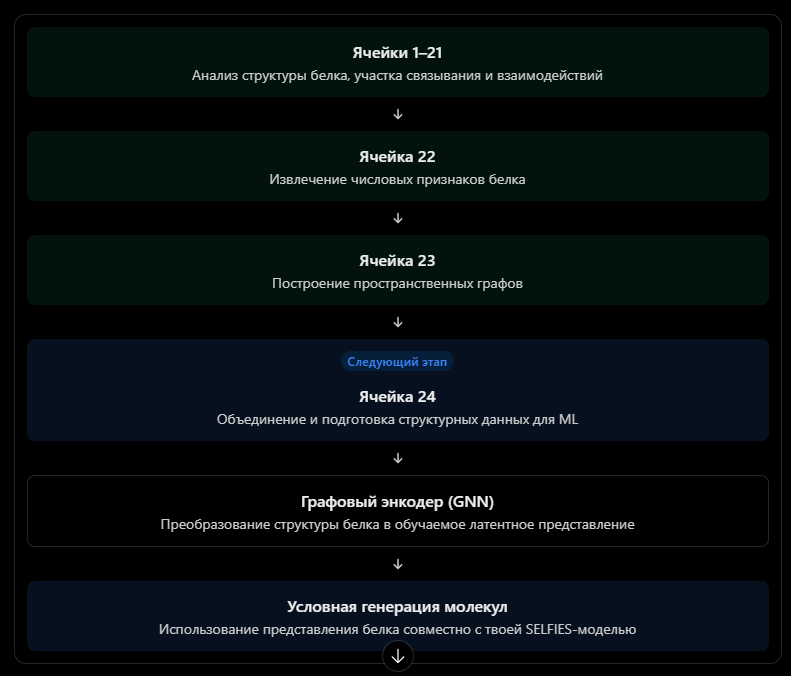

In [36]:
# ============================================================
# CELL 24. UNIFIED PROTEIN STRUCTURAL REPRESENTATION
# ============================================================
#
# НАЗНАЧЕНИЕ:
# Объединение результатов Cell 22 и Cell 23 в единое
# машинно-ориентированное представление структуры белка.
#
# СОЗДАВАЕМЫЕ ПРЕДСТАВЛЕНИЯ:
#
# ATOM GRAPH:
# X_atom                  - признаки атомов
# pos_atom                - координаты атомов
# edge_index_atom         - индексы атомных рёбер
# edge_attr_atom          - признаки атомных рёбер
# atom_node_ids           - исходные ID атомных узлов
#
# RESIDUE GRAPH:
# X_residue               - признаки аминокислотных остатков
# pos_residue             - координаты центров остатков
# edge_index_residue      - индексы остаточных рёбер
# edge_attr_residue       - признаки остаточных рёбер
# residue_node_ids        - исходные ID остатков
#
# GLOBAL:
# X_global                - глобальные признаки белка
#
# BINDING SITE:
# is_binding_site_atom    - атом принадлежит остатку binding site
# is_direct_contact_atom  - атом непосредственно контактирует
#                           с выбранным компонентом
# is_binding_site_residue - остаток входит в binding site
#
# ВАЖНО:
# Пространственные контакты не являются автоматически
# химическими связями.
#
# На этом этапе обучение модели не выполняется.
# ============================================================


import os
import json

import numpy as np
import pandas as pd

from pathlib import Path


print("=" * 70)
print("CELL 24. UNIFIED PROTEIN STRUCTURAL REPRESENTATION")
print("=" * 70)


# ============================================================
# 1. PATHS
# ============================================================

PDB_NAME = str(
    globals().get("PDB_ID", "UNKNOWN")
)


if "FEATURE_DIR" in globals():

    feature_dir_24 = Path(FEATURE_DIR)

elif "feature_dir" in globals():

    feature_dir_24 = Path(feature_dir)

else:

    feature_dir_24 = (
        Path("PDB_Protein_Analysis")
        / "results"
        / "features"
    )


output_dir_24 = (
    feature_dir_24.parent
    / "unified_representation"
)

output_dir_24.mkdir(
    parents=True,
    exist_ok=True
)


print(f"PDB ID: {PDB_NAME}")
print(f"Input directory: {feature_dir_24}")
print(f"Output directory: {output_dir_24}")


# ============================================================
# 2. LOADING CELL 22 AND CELL 23 DATA
# ============================================================


def load_csv_24(filename, required=True):

    path = feature_dir_24 / filename

    if not path.exists():

        if required:

            raise FileNotFoundError(
                f"Не найден файл: {path}\n"
                "Проверьте выполнение ячеек 22 и 23."
            )

        return pd.DataFrame()

    return pd.read_csv(path)


# ----------------------------
# CELL 23: SPATIAL GRAPHS
# ----------------------------

df_atom_nodes_24 = load_csv_24(
    f"{PDB_NAME}_spatial_atom_nodes.csv"
)

df_atom_edges_24 = load_csv_24(
    f"{PDB_NAME}_spatial_atom_edges.csv"
)

df_residue_nodes_24 = load_csv_24(
    f"{PDB_NAME}_spatial_residue_nodes.csv"
)

df_residue_edges_24 = load_csv_24(
    f"{PDB_NAME}_spatial_residue_edges.csv"
)


# ----------------------------
# CELL 22: PROTEIN FEATURES
# ----------------------------

df_global_24 = load_csv_24(
    f"{PDB_NAME}_global_features.csv",
    required=False
)

df_binding_24 = load_csv_24(
    f"{PDB_NAME}_binding_site_features.csv",
    required=False
)

df_interactions_24 = load_csv_24(
    f"{PDB_NAME}_interaction_features.csv",
    required=False
)

df_metal_24 = load_csv_24(
    f"{PDB_NAME}_metal_features.csv",
    required=False
)

df_atom_features_24 = load_csv_24(
    f"{PDB_NAME}_atom_features.csv",
    required=False
)

df_residue_features_24 = load_csv_24(
    f"{PDB_NAME}_residue_features.csv",
    required=False
)

df_binding_contacts_24 = load_csv_24(
    f"{PDB_NAME}_binding_atom_contact_features.csv",
    required=False
)


print("\nINPUT DATA")
print("-" * 70)


input_tables_24 = {

    "Atom nodes": df_atom_nodes_24,
    "Atom edges": df_atom_edges_24,

    "Residue nodes": df_residue_nodes_24,
    "Residue edges": df_residue_edges_24,

    "Global features": df_global_24,
    "Binding site": df_binding_24,

    "Binding atom contacts": df_binding_contacts_24,

    "Interactions": df_interactions_24,
    "Metal features": df_metal_24

}


for name, dataframe in input_tables_24.items():

    print(
        f"{name:27s}: {len(dataframe):8d} rows"
    )


if df_atom_nodes_24.empty:

    raise ValueError(
        "Таблица атомных узлов пуста."
    )


if df_residue_nodes_24.empty:

    raise ValueError(
        "Таблица остаточных узлов пуста."
    )


# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================


def find_column_24(dataframe, candidates):
    """
    Поиск столбца с учётом регистра и разделителей.
    """

    normalized = {

        "".join(
            ch.lower()
            for ch in str(col)
            if ch.isalnum()
        ): col

        for col in dataframe.columns

    }

    for candidate in candidates:

        key = "".join(
            ch.lower()
            for ch in str(candidate)
            if ch.isalnum()
        )

        if key in normalized:

            return normalized[key]

    return None


def normalize_text_24(value):
    """
    Нормализация текстовых идентификаторов.
    """

    if pd.isna(value):

        return ""

    return str(value).strip()


def normalize_number_24(value):
    """
    Нормализация номера остатка.
    """

    if pd.isna(value):

        return None

    try:

        numeric_value = float(value)

        if not np.isfinite(numeric_value):

            raise ValueError(
                f"Некорректный номер: {value}"
            )

        if not numeric_value.is_integer():

            raise ValueError(
                f"Номер остатка не является целым: {value}"
            )

        return int(numeric_value)

    except (ValueError, TypeError):

        raise ValueError(
            f"Невозможно нормализовать номер остатка: {value}"
        )


def normalize_icode_24(value):
    """
    Пустой или отсутствующий insertion code -> ''.
    """

    if pd.isna(value):

        return ""

    return str(value).strip()


def make_residue_key_24(
    chain_id,
    residue_name,
    residue_number,
    insertion_code=""
):
    """
    Унифицированный идентификатор остатка.

    Формат:
    (
        chain_id,
        residue_name,
        residue_number,
        insertion_code
    )

    Исходный residue_key не используется,
    поскольку Cell 22 и Cell 23 могут формировать
    его в разных форматах.
    """

    return (

        normalize_text_24(chain_id),

        normalize_text_24(
            residue_name
        ).upper(),

        normalize_number_24(
            residue_number
        ),

        normalize_icode_24(
            insertion_code
        )

    )


def clean_numeric_matrix_24(dataframe):
    """
    Перевод признаков в float32.

    NaN и +/-inf заменяются нулями.

    Стандартизация не выполняется.
    """

    if dataframe.shape[1] == 0:

        return np.zeros(
            (len(dataframe), 0),
            dtype=np.float32
        )

    result = dataframe.copy()

    for col in result.columns:

        result[col] = pd.to_numeric(
            result[col],
            errors="coerce"
        )

        result[col] = result[col].replace(
            [np.inf, -np.inf],
            np.nan
        )

        result[col] = result[col].fillna(0.0)

    return result.to_numpy(
        dtype=np.float32
    )


def get_node_ids_24(
    dataframe,
    candidates,
    object_name
):
    """
    Получение исходных ID узлов.

    Если ID отсутствует, используются позиции строк.

    Проверяются:
    - отсутствие пропусков;
    - целочисленность;
    - уникальность.
    """

    col = find_column_24(
        dataframe,
        candidates
    )

    if col is None:

        print(
            f"WARNING: {object_name}: ID column not found. "
            "Используются позиции строк."
        )

        return np.arange(
            len(dataframe),
            dtype=np.int64
        )

    ids = pd.to_numeric(
        dataframe[col],
        errors="coerce"
    )

    if ids.isna().any():

        raise ValueError(
            f"{object_name}: обнаружены некорректные ID."
        )

    values = ids.to_numpy(
        dtype=np.float64
    )

    if not np.isfinite(values).all():

        raise ValueError(
            f"{object_name}: ID содержат NaN или inf."
        )

    if not np.all(
        values == np.floor(values)
    ):

        raise ValueError(
            f"{object_name}: обнаружены нецелочисленные ID."
        )

    ids = values.astype(
        np.int64
    )

    if len(np.unique(ids)) != len(ids):

        raise ValueError(
            f"{object_name}: ID узлов не уникальны."
        )

    return ids


def make_bidirectional_edges_24(
    edge_dataframe,
    source_col,
    target_col,
    feature_columns,
    node_ids,
    object_name
):
    """
    Создание двунаправленных рёбер.

    Исходные ID преобразуются в позиции строк
    соответствующей матрицы узлов.

    edge_index содержит позиции строк, а не исходные ID.
    """

    if edge_dataframe.empty:

        return (

            np.empty(
                (2, 0),
                dtype=np.int64
            ),

            np.empty(
                (0, len(feature_columns)),
                dtype=np.float32
            )

        )

    if source_col not in edge_dataframe.columns:

        raise ValueError(
            f"{object_name}: отсутствует {source_col}."
        )

    if target_col not in edge_dataframe.columns:

        raise ValueError(
            f"{object_name}: отсутствует {target_col}."
        )

    source_raw = pd.to_numeric(
        edge_dataframe[source_col],
        errors="coerce"
    )

    target_raw = pd.to_numeric(
        edge_dataframe[target_col],
        errors="coerce"
    )

    if source_raw.isna().any() or target_raw.isna().any():

        raise ValueError(
            f"{object_name}: некорректные индексы рёбер."
        )

    source_values = source_raw.to_numpy(
        dtype=np.float64
    )

    target_values = target_raw.to_numpy(
        dtype=np.float64
    )

    if not np.all(
        source_values == np.floor(source_values)
    ):

        raise ValueError(
            f"{object_name}: source ID нецелочисленные."
        )

    if not np.all(
        target_values == np.floor(target_values)
    ):

        raise ValueError(
            f"{object_name}: target ID нецелочисленные."
        )

    source_raw = source_values.astype(
        np.int64
    )

    target_raw = target_values.astype(
        np.int64
    )

    id_to_position = {

        int(node_id): position

        for position, node_id in enumerate(node_ids)

    }

    unknown_ids = (

        set(source_raw.tolist())
        | set(target_raw.tolist())

    ) - set(id_to_position.keys())

    if unknown_ids:

        raise ValueError(
            f"{object_name}: рёбра содержат неизвестные ID: "
            f"{list(unknown_ids)[:10]}"
        )

    source = np.array(

        [
            id_to_position[int(value)]
            for value in source_raw
        ],

        dtype=np.int64

    )

    target = np.array(

        [
            id_to_position[int(value)]
            for value in target_raw
        ],

        dtype=np.int64

    )

    if feature_columns:

        edge_features = clean_numeric_matrix_24(
            edge_dataframe[feature_columns]
        )

    else:

        edge_features = np.empty(
            (len(source), 0),
            dtype=np.float32
        )

    no_self_loop = source != target

    source = source[no_self_loop]
    target = target[no_self_loop]

    edge_features = edge_features[
        no_self_loop
    ]

    edge_index = np.vstack([

        np.concatenate([
            source,
            target
        ]),

        np.concatenate([
            target,
            source
        ])

    ])

    edge_attr = np.concatenate([

        edge_features,
        edge_features

    ], axis=0)

    return edge_index, edge_attr


# ============================================================
# 4. NODE IDENTIFIERS
# ============================================================

# Проверяем реальные поля атомных узлов.

required_atom_columns_24 = [

    "chain_id",
    "residue_name",
    "residue_number",
    "insertion_code"

]


for col in required_atom_columns_24:

    if col not in df_atom_nodes_24.columns:

        raise ValueError(
            f"В atom nodes отсутствует столбец: {col}"
        )


# Поля остаточных узлов.
required_residue_columns_24 = [

    "chain_id",
    "residue_name",
    "residue_number",
    "graph_residue_id"

]


for col in required_residue_columns_24:

    if col not in df_residue_nodes_24.columns:

        raise ValueError(
            f"В residue nodes отсутствует столбец: {col}"
        )


# Поля binding site.
required_binding_columns_24 = [

    "protein_chain",
    "residue_name",
    "residue_number",
    "insertion_code"

]


if not df_binding_24.empty:

    for col in required_binding_columns_24:

        if col not in df_binding_24.columns:

            raise ValueError(
                f"В binding site отсутствует столбец: {col}"
            )


# ============================================================
# 5. UNIFIED RESIDUE IDENTIFIERS
# ============================================================
#
# Cell 23:
# residue_key = A: :1:
#
# Cell 22:
# residue_key = A:HIS:240
#
# Исходные строки не сравниваем.
#
# Используем составной ключ:
# chain + residue name + residue number + insertion code.
# ============================================================


# ------------------------------------------------------------
# 5.1. Создаём карту insertion_code по атомам
# ------------------------------------------------------------

atom_icode_map_24 = {}


for row in df_atom_nodes_24[
    required_atom_columns_24
].itertuples(index=False, name=None):

    chain_id, residue_name, residue_number, insertion_code = row

    base_key = (

        normalize_text_24(chain_id),

        normalize_text_24(residue_name).upper(),

        normalize_number_24(residue_number)

    )

    icode = normalize_icode_24(
        insertion_code
    )

    atom_icode_map_24.setdefault(
        base_key,
        set()
    ).add(icode)


# ------------------------------------------------------------
# 5.2. Ключи атомных узлов
# ------------------------------------------------------------

atom_residue_keys_24 = [

    make_residue_key_24(*row)

    for row in df_atom_nodes_24[
        required_atom_columns_24
    ].itertuples(index=False, name=None)

]


# ------------------------------------------------------------
# 5.3. Ключи остаточных узлов
# ------------------------------------------------------------

residue_node_keys_24 = []


for row in df_residue_nodes_24[
    required_residue_columns_24[:3]
].itertuples(index=False, name=None):

    chain_id, residue_name, residue_number = row

    base_key = (

        normalize_text_24(chain_id),

        normalize_text_24(residue_name).upper(),

        normalize_number_24(residue_number)

    )

    possible_icodes = atom_icode_map_24.get(
        base_key,
        set()
    )

    if len(possible_icodes) == 0:

        raise ValueError(
            f"Для остатка {base_key} не найдены атомы."
        )

    if len(possible_icodes) > 1:

        raise ValueError(
            f"Для остатка {base_key} обнаружено несколько "
            f"insertion_code: {possible_icodes}."
        )

    insertion_code = next(
        iter(possible_icodes)
    )

    residue_node_keys_24.append(

        make_residue_key_24(

            chain_id,
            residue_name,
            residue_number,
            insertion_code

        )

    )


# ------------------------------------------------------------
# 5.4. Ключи binding site
# ------------------------------------------------------------

binding_residue_keys_24 = set()


if not df_binding_24.empty:

    for row in df_binding_24[
        required_binding_columns_24
    ].itertuples(index=False, name=None):

        protein_chain, residue_name, residue_number, insertion_code = row

        binding_residue_keys_24.add(

            make_residue_key_24(

                protein_chain,
                residue_name,
                residue_number,
                insertion_code

            )

        )


# ------------------------------------------------------------
# 5.5. Маски binding site
# ------------------------------------------------------------

is_binding_site_residue_24 = np.array(

    [
        key in binding_residue_keys_24
        for key in residue_node_keys_24
    ],

    dtype=np.float32

)


is_binding_site_atom_24 = np.array(

    [
        key in binding_residue_keys_24
        for key in atom_residue_keys_24
    ],

    dtype=np.float32

)


matched_residue_keys_24 = (

    set(residue_node_keys_24)
    & binding_residue_keys_24

)


unmatched_residue_keys_24 = (

    binding_residue_keys_24
    - set(residue_node_keys_24)

)


matched_residues_24 = int(
    is_binding_site_residue_24.sum()
)

matched_atoms_24 = int(
    is_binding_site_atom_24.sum()
)


print("\nRESIDUE IDENTIFIER VALIDATION")
print("-" * 70)

print(
    "Unique binding site residues:",
    len(binding_residue_keys_24)
)

print(
    "Matched residue nodes:",
    matched_residues_24
)

print(
    "Matched atom nodes:",
    matched_atoms_24
)

print(
    "Total residue nodes:",
    len(residue_node_keys_24)
)

print(
    "Total atom nodes:",
    len(atom_residue_keys_24)
)


if unmatched_residue_keys_24:

    raise ValueError(
        "Не все binding site residues найдены в residue graph: "
        f"{unmatched_residue_keys_24}"
    )


if matched_residues_24 != len(binding_residue_keys_24):

    raise ValueError(
        "Количество сопоставленных остатков не совпадает "
        "с количеством остатков binding site."
    )


print(
    "\nВсе binding site residues успешно сопоставлены."
)


# ------------------------------------------------------------
# 5.6. Совместимость с именами переменных Cell 24
# ------------------------------------------------------------

# Эти имена используются в последующих разделах.
# Повторное формирование ключей не требуется.

residue_keys_24 = residue_node_keys_24

atom_binding_mask_24 = is_binding_site_atom_24

residue_binding_mask_24 = is_binding_site_residue_24


# ============================================================
# ============================================================
# 6. DIRECT CONTACT ATOM IDENTIFICATION
# ============================================================
#
# Определяем атомы белка, непосредственно контактирующие
# с исследуемым компонентом.
#
# Используем реальные столбцы таблицы Cell 22:
#
# protein_chain
# residue_name
# residue_number
# insertion_code
# protein_atom
#
# Сопоставление выполняется по двум идентификаторам:
# 1. Составной ключ остатка.
# 2. Название атома.
#
# Результат:
# direct_contact_mask_24
#
# ============================================================


direct_contact_mask_24 = np.zeros(
    len(df_atom_nodes_24),
    dtype=np.float32
)

direct_contact_available_24 = False

direct_contact_mapping_info_24 = {

    "source": None,

    "contact_rows": int(
        len(df_binding_contacts_24)
    ),

    "unique_contact_atoms": 0,

    "matched_contact_atoms": 0,

    "unmatched_contact_atoms": 0

}


if not df_binding_contacts_24.empty:

    # --------------------------------------------------------
    # 6.1. Определение столбцов таблицы контактов
    # --------------------------------------------------------

    contact_chain_col_24 = find_column_24(
        df_binding_contacts_24,
        [
            "protein_chain",
            "chain_id"
        ]
    )

    contact_residue_name_col_24 = find_column_24(
        df_binding_contacts_24,
        [
            "protein_residue_name",
            "residue_name"
        ]
    )

    contact_residue_number_col_24 = find_column_24(
        df_binding_contacts_24,
        [
            "protein_residue_number",
            "residue_number"
        ]
    )

    contact_icode_col_24 = find_column_24(
        df_binding_contacts_24,
        [
            "protein_insertion_code",
            "insertion_code",
            "icode"
        ]
    )

    # ВАЖНО:
    # В твоей таблице используется именно protein_atom.
    # Добавили его в список допустимых названий.

    contact_atom_name_col_24 = find_column_24(
        df_binding_contacts_24,
        [
            "protein_atom_name",
            "protein_contact_atom",
            "closest_protein_atom",
            "protein_atom",
            "atom_name"
        ]
    )

    # Столбец имени атома в таблице атомных узлов.

    atom_atom_name_col_24 = find_column_24(
        df_atom_nodes_24,
        [
            "atom_name"
        ]
    )

    contact_columns_24 = {

        "chain": contact_chain_col_24,

        "residue_name": contact_residue_name_col_24,

        "residue_number": contact_residue_number_col_24,

        "insertion_code": contact_icode_col_24,

        "atom_name": contact_atom_name_col_24

    }

    missing_contact_columns_24 = [

        name

        for name, col in contact_columns_24.items()

        if col is None

    ]

    if atom_atom_name_col_24 is None:

        missing_contact_columns_24.append(
            "atom_name in atom nodes"
        )


    # --------------------------------------------------------
    # 6.2. Проверка доступности идентификаторов
    # --------------------------------------------------------

    if not missing_contact_columns_24:

        # ----------------------------------------------------
        # 6.3. Формирование множества контактных атомов
        # ----------------------------------------------------

        direct_contact_keys_24 = set()

        for _, row in df_binding_contacts_24.iterrows():

            residue_key = make_residue_key_24(

                row[contact_chain_col_24],

                row[contact_residue_name_col_24],

                row[contact_residue_number_col_24],

                row[contact_icode_col_24]

            )

            atom_name = normalize_text_24(
                row[contact_atom_name_col_24]
            ).upper()

            if atom_name:

                direct_contact_keys_24.add(

                    (
                        residue_key,
                        atom_name
                    )

                )


        # ----------------------------------------------------
        # 6.4. Сопоставление с атомными узлами
        # ----------------------------------------------------

        matched_contact_keys_24 = set()

        for atom_index, (_, row) in enumerate(
            df_atom_nodes_24.iterrows()
        ):

            residue_key = atom_residue_keys_24[
                atom_index
            ]

            atom_name = normalize_text_24(
                row[atom_atom_name_col_24]
            ).upper()

            atom_key = (
                residue_key,
                atom_name
            )

            if atom_key in direct_contact_keys_24:

                direct_contact_mask_24[
                    atom_index
                ] = 1.0

                matched_contact_keys_24.add(
                    atom_key
                )


        # ----------------------------------------------------
        # 6.5. Расчёт результатов сопоставления
        # ----------------------------------------------------

        unmatched_contact_keys_24 = (

            direct_contact_keys_24
            - matched_contact_keys_24

        )

        direct_contact_available_24 = True

        direct_contact_mapping_info_24 = {

            "source": "binding_atom_contact_features",

            "contact_rows": int(
                len(df_binding_contacts_24)
            ),

            "unique_contact_atoms": int(
                len(direct_contact_keys_24)
            ),

            "matched_contact_atoms": int(
                len(matched_contact_keys_24)
            ),

            "unmatched_contact_atoms": int(
                len(unmatched_contact_keys_24)
            )

        }

    else:

        print(
            "\nWARNING: Не удалось определить все "
            "идентификаторы прямых атомных контактов."
        )

        print(
            "Missing fields:",
            missing_contact_columns_24
        )

        print(
            "Available contact columns:",
            df_binding_contacts_24.columns.tolist()
        )


# ------------------------------------------------------------
# 6.6. Вывод результатов
# ------------------------------------------------------------

print("\nDIRECT CONTACT ATOMS")
print("-" * 70)

print(
    "Direct contact feature available:",
    direct_contact_available_24
)

print(
    "Direct contact atoms matched:",
    int(direct_contact_mask_24.sum())
)

print(
    "Direct contact mapping:",
    direct_contact_mapping_info_24
)
# ============================================================
# 7. ATOM NODE FEATURES
# ============================================================
#
# X_atom:
# - числовые характеристики атомов;
# - one-hot элемент;
# - is_binding_site_atom;
# - is_direct_contact_atom.
#
# Координаты хранятся отдельно в pos_atom.
# ============================================================


atom_element_col_24 = find_column_24(

    df_atom_nodes_24,

    ["element"]

)


if atom_element_col_24 is None:

    raise ValueError(
        "В атомных узлах отсутствует element."
    )


ELEMENTS_24 = [

    "C",
    "N",
    "O",
    "S",
    "P",
    "F",
    "CL",
    "BR",
    "I",
    "MG",
    "ZN",
    "FE",
    "CU",
    "CA",
    "NA",
    "K",
    "MN",
    "CO",
    "NI",
    "OTHER"

]


atom_elements_24 = (

    df_atom_nodes_24[
        atom_element_col_24
    ]

    .fillna("OTHER")

    .astype(str)

    .str.strip()

    .str.upper()

)


atom_elements_24 = atom_elements_24.where(

    atom_elements_24.isin(ELEMENTS_24),

    "OTHER"

)


atom_element_features_24 = np.column_stack([

    (
        atom_elements_24 == element
    ).astype(np.float32)

    for element in ELEMENTS_24

])


excluded_atom_columns_24 = {

    "graphatomid",
    "atomserial",
    "atomid",
    "serial",

    "resid",
    "residueid",
    "residuenumber",
    "resnum",
    "resseq",
    "modelid",

    "x",
    "y",
    "z",

    "xa",
    "ya",
    "za",

    "coordx",
    "coordy",
    "coordz",

    "xcoord",
    "ycoord",
    "zcoord",

    "chainid",
    "residuename",
    "residuekey",
    "insertioncode",
    "icode",

    "atomname",
    "atomfullname",
    "element",

    "heteroflag",
    "altloc",

    "_element",
    "_chainid",
    "_resname",
    "_resnum",
    "_icode",
    "_residuekey"

}


atom_numeric_columns_24 = []


for col in df_atom_nodes_24.columns:

    normalized = "".join(

        ch.lower()

        for ch in str(col)

        if ch.isalnum()

    )

    if normalized in excluded_atom_columns_24:

        continue

    converted = pd.to_numeric(

        df_atom_nodes_24[col],

        errors="coerce"

    )

    if converted.notna().any():

        if converted.nunique(dropna=True) > 1:

            atom_numeric_columns_24.append(col)


df_atom_numeric_24 = df_atom_nodes_24[
    atom_numeric_columns_24
].copy()


X_atom_numeric_24 = clean_numeric_matrix_24(
    df_atom_numeric_24
)


# Координаты атомов.

atom_coordinate_columns_24 = [

    find_column_24(
        df_atom_nodes_24,
        ["x_A"]
    ),

    find_column_24(
        df_atom_nodes_24,
        ["y_A"]
    ),

    find_column_24(
        df_atom_nodes_24,
        ["z_A"]
    )

]


if any(
    col is None
    for col in atom_coordinate_columns_24
):

    raise ValueError(
        "Не найдены координаты атомов x_A, y_A, z_A."
    )


pos_atom = df_atom_nodes_24[
    atom_coordinate_columns_24
].apply(
    pd.to_numeric,
    errors="coerce"
).to_numpy(
    dtype=np.float32
)


if not np.isfinite(pos_atom).all():

    raise ValueError(
        "В координатах атомов обнаружены NaN или inf."
    )


# Итоговая матрица атомных признаков.

X_atom = np.concatenate(

    [

        X_atom_numeric_24,

        atom_element_features_24,

        atom_binding_mask_24.reshape(-1, 1),

        direct_contact_mask_24.reshape(-1, 1)

    ],

    axis=1

).astype(np.float32)


atom_feature_names_24 = (

    [
        f"numeric_{col}"
        for col in atom_numeric_columns_24
    ]

    + [
        f"element_{element}"
        for element in ELEMENTS_24
    ]

    + [

        "is_binding_site_atom",

        "is_direct_contact_atom"

    ]

)


# ============================================================
# 8. RESIDUE NODE FEATURES
# ============================================================
#
# X_residue:
# - числовые признаки остатков;
# - one-hot аминокислоты;
# - is_binding_site_residue.
#
# Координаты центров хранятся отдельно.
# ============================================================


res_name_col_24 = "residue_name"


AMINO_ACIDS_24 = [

    "ALA",
    "ARG",
    "ASN",
    "ASP",
    "CYS",
    "GLN",
    "GLU",
    "GLY",
    "HIS",
    "ILE",
    "LEU",
    "LYS",
    "MET",
    "PHE",
    "PRO",
    "SER",
    "THR",
    "TRP",
    "TYR",
    "VAL",
    "OTHER"

]


residue_names_24 = (

    df_residue_nodes_24[
        res_name_col_24
    ]

    .fillna("OTHER")

    .astype(str)

    .str.strip()

    .str.upper()

)


residue_names_24 = residue_names_24.where(

    residue_names_24.isin(AMINO_ACIDS_24),

    "OTHER"

)


residue_type_features_24 = np.column_stack([

    (
        residue_names_24 == amino_acid
    ).astype(np.float32)

    for amino_acid in AMINO_ACIDS_24

])


excluded_residue_columns_24 = {

    "graphresidueid",
    "residueid",
    "resid",
    "residuenumber",
    "resnum",
    "resseq",
    "modelid",

    "chainid",
    "residuename",
    "residuekey",
    "insertioncode",
    "icode",

    "centerx",
    "centery",
    "centerz",

    "centerxa",
    "centerya",
    "centerza",

    "x",
    "y",
    "z",

    "xa",
    "ya",
    "za"

}


residue_numeric_columns_24 = []


for col in df_residue_nodes_24.columns:

    normalized = "".join(

        ch.lower()

        for ch in str(col)

        if ch.isalnum()

    )

    if normalized in excluded_residue_columns_24:

        continue

    converted = pd.to_numeric(

        df_residue_nodes_24[col],

        errors="coerce"

    )

    if converted.notna().any():

        if converted.nunique(dropna=True) > 1:

            residue_numeric_columns_24.append(col)


df_residue_numeric_24 = df_residue_nodes_24[
    residue_numeric_columns_24
].copy()


X_residue_numeric_24 = clean_numeric_matrix_24(
    df_residue_numeric_24
)


# Координаты центров остатков.

residue_coordinate_columns_24 = [

    find_column_24(
        df_residue_nodes_24,
        ["center_x_A"]
    ),

    find_column_24(
        df_residue_nodes_24,
        ["center_y_A"]
    ),

    find_column_24(
        df_residue_nodes_24,
        ["center_z_A"]
    )

]


if any(
    col is None
    for col in residue_coordinate_columns_24
):

    raise ValueError(
        "Не найдены координаты центров остатков."
    )


pos_residue = df_residue_nodes_24[
    residue_coordinate_columns_24
].apply(
    pd.to_numeric,
    errors="coerce"
).to_numpy(
    dtype=np.float32
)


if not np.isfinite(pos_residue).all():

    raise ValueError(
        "В координатах остатков обнаружены NaN или inf."
    )


X_residue = np.concatenate(

    [

        X_residue_numeric_24,

        residue_type_features_24,

        residue_binding_mask_24.reshape(-1, 1)

    ],

    axis=1

).astype(np.float32)


residue_feature_names_24 = (

    [
        f"numeric_{col}"
        for col in residue_numeric_columns_24
    ]

    + [
        f"amino_acid_{aa}"
        for aa in AMINO_ACIDS_24
    ]

    + [
        "is_binding_site_residue"
    ]

)


# ============================================================
# 9. NODE IDENTIFIERS
# ============================================================


atom_node_ids = get_node_ids_24(

    df_atom_nodes_24,

    ["graph_atom_id"],

    "Atom graph"

)


residue_node_ids = get_node_ids_24(

    df_residue_nodes_24,

    ["graph_residue_id"],

    "Residue graph"

)


# ============================================================
# 10. ATOM EDGES
# ============================================================


atom_edge_features_24 = [

    col

    for col in [

        "distance_A",

        "same_residue"

    ]

    if col in df_atom_edges_24.columns

]


edge_index_atom, edge_attr_atom = (
    make_bidirectional_edges_24(

        df_atom_edges_24,

        "atom_i",

        "atom_j",

        atom_edge_features_24,

        atom_node_ids,

        "Atom graph"

    )
)


atom_edge_feature_names_24 = (
    atom_edge_features_24.copy()
)


# ============================================================
# 11. RESIDUE EDGES
# ============================================================


residue_edge_features_24 = [

    col

    for col in [

        "min_distance_A",

        "mean_contact_distance_A",

        "atom_contact_count"

    ]

    if col in df_residue_edges_24.columns

]


edge_index_residue, edge_attr_residue = (
    make_bidirectional_edges_24(

        df_residue_edges_24,

        "residue_node_i",

        "residue_node_j",

        residue_edge_features_24,

        residue_node_ids,

        "Residue graph"

    )
)


residue_edge_feature_names_24 = (
    residue_edge_features_24.copy()
)


# ============================================================
# 12. GLOBAL PROTEIN FEATURES
# ============================================================
#
# Один вектор числовых характеристик структуры.
#
# Он хранится отдельно от атомного и остаточного графов.
# ============================================================


global_numeric_columns_24 = []


excluded_global_columns_24 = {

    "pdbid",
    "structureid",
    "proteinid",
    "modelid"

}


if len(df_global_24) > 1:

    raise ValueError(
        "Ожидалась одна строка глобальных признаков "
        "для одной структуры белка."
    )


if not df_global_24.empty:

    for col in df_global_24.columns:

        normalized = "".join(

            ch.lower()

            for ch in str(col)

            if ch.isalnum()

        )

        if normalized in excluded_global_columns_24:

            continue

        converted = pd.to_numeric(

            df_global_24[col],

            errors="coerce"

        )

        if converted.notna().any():

            global_numeric_columns_24.append(col)


if global_numeric_columns_24:

    X_global = clean_numeric_matrix_24(

        df_global_24[
            global_numeric_columns_24
        ]

    )[0]

else:

    X_global = np.empty(
        0,
        dtype=np.float32
    )


global_feature_names_24 = [

    str(col)

    for col in global_numeric_columns_24

]


# ============================================================
# 13. FINAL FEATURE TABLES
# ============================================================


df_ml_atom_features = pd.DataFrame(

    X_atom,

    columns=atom_feature_names_24

)


df_ml_atom_features.insert(

    0,

    "graph_atom_id",

    atom_node_ids

)


df_ml_residue_features = pd.DataFrame(

    X_residue,

    columns=residue_feature_names_24

)


df_ml_residue_features.insert(

    0,

    "graph_residue_id",

    residue_node_ids

)


# ============================================================
# 14. VALIDATION
# ============================================================


print("\nVALIDATION")
print("-" * 70)


# Размерности узлов и координат.

assert X_atom.shape[0] == len(atom_node_ids)

assert pos_atom.shape == (
    len(atom_node_ids),
    3
)

assert X_residue.shape[0] == len(residue_node_ids)

assert pos_residue.shape == (
    len(residue_node_ids),
    3
)


# Числовые значения.

assert np.isfinite(X_atom).all()

assert np.isfinite(X_residue).all()

assert np.isfinite(X_global).all()

assert np.isfinite(pos_atom).all()

assert np.isfinite(pos_residue).all()

assert np.isfinite(edge_attr_atom).all()

assert np.isfinite(edge_attr_residue).all()


# Проверка индексов рёбер.

if edge_index_atom.size:

    assert edge_index_atom.min() >= 0

    assert edge_index_atom.max() < len(X_atom)


if edge_index_residue.size:

    assert edge_index_residue.min() >= 0

    assert edge_index_residue.max() < len(X_residue)


# Проверка размерностей признаков.

assert X_atom.shape[1] == len(
    atom_feature_names_24
)

assert X_residue.shape[1] == len(
    residue_feature_names_24
)


# Проверка бинарных масок.

assert set(
    np.unique(atom_binding_mask_24)
).issubset({0.0, 1.0})


assert set(
    np.unique(direct_contact_mask_24)
).issubset({0.0, 1.0})


assert set(
    np.unique(residue_binding_mask_24)
).issubset({0.0, 1.0})


# Проверка соответствия числа узлов и масок.

assert len(atom_binding_mask_24) == len(X_atom)

assert len(direct_contact_mask_24) == len(X_atom)

assert len(residue_binding_mask_24) == len(X_residue)


print("Node dimensions: OK")
print("Coordinate dimensions: OK")
print("Edge index ranges: OK")
print("Finite numerical values: OK")
print("Feature names: OK")
print("Binding masks: OK")


# ============================================================
# 15. SAVE NPZ
# ============================================================


ml_data_path_24 = (

    output_dir_24

    / f"{PDB_NAME}_ml_graph_data.npz"

)


np.savez_compressed(

    ml_data_path_24,

    X_atom=X_atom,

    pos_atom=pos_atom,

    edge_index_atom=edge_index_atom,

    edge_attr_atom=edge_attr_atom,

    X_residue=X_residue,

    pos_residue=pos_residue,

    edge_index_residue=edge_index_residue,

    edge_attr_residue=edge_attr_residue,

    X_global=X_global,

    atom_node_ids=atom_node_ids,

    residue_node_ids=residue_node_ids,

    is_binding_site_atom=atom_binding_mask_24,

    is_direct_contact_atom=direct_contact_mask_24,

    is_binding_site_residue=residue_binding_mask_24

)


# ============================================================
# 16. SAVE FEATURE TABLES
# ============================================================


ml_atom_csv_24 = (

    output_dir_24

    / f"{PDB_NAME}_ml_atom_features.csv"

)


ml_residue_csv_24 = (

    output_dir_24

    / f"{PDB_NAME}_ml_residue_features.csv"

)


df_ml_atom_features.to_csv(

    ml_atom_csv_24,

    index=False

)


df_ml_residue_features.to_csv(

    ml_residue_csv_24,

    index=False

)


global_csv_24 = (

    output_dir_24

    / f"{PDB_NAME}_ml_global_features.csv"

)


if len(X_global) > 0:

    pd.DataFrame(

        [X_global],

        columns=global_feature_names_24

    ).to_csv(

        global_csv_24,

        index=False

    )


# ============================================================
# 17. FEATURE MANIFEST
# ============================================================


ml_manifest_24 = {

    "pdb_id": PDB_NAME,

    "description": (
        "Unified protein structural representation "
        "for machine learning and graph neural networks"
    ),

    "source_cells": [22, 23, 24],

    "atom_graph": {

        "node_count": int(
            len(X_atom)
        ),

        "feature_count": int(
            X_atom.shape[1]
        ),

        "coordinate_dimensions": 3,

        "edge_count_directed": int(
            edge_index_atom.shape[1]
        ),

        "feature_names": atom_feature_names_24,

        "edge_feature_names": atom_edge_feature_names_24,

        "node_id_field": "atom_node_ids"

    },

    "residue_graph": {

        "node_count": int(
            len(X_residue)
        ),

        "feature_count": int(
            X_residue.shape[1]
        ),

        "coordinate_dimensions": 3,

        "edge_count_directed": int(
            edge_index_residue.shape[1]
        ),

        "feature_names": residue_feature_names_24,

        "edge_feature_names": residue_edge_feature_names_24,

        "node_id_field": "residue_node_ids"

    },

    "global_features": {

        "feature_count": int(
            len(X_global)
        ),

        "feature_names": global_feature_names_24

    },

    "binding_site": {

        "binding_residue_count": int(
            len(binding_residue_keys_24)
        ),

        "matched_binding_residue_count": int(
            len(matched_residue_keys_24)
        ),

        "unmatched_binding_residue_count": int(
            len(unmatched_residue_keys_24)
        ),

        "binding_atom_count": int(
            atom_binding_mask_24.sum()
        ),

        "binding_residue_node_count": int(
            residue_binding_mask_24.sum()
        ),

        "direct_contact_atom_count": int(
            direct_contact_mask_24.sum()
        ),

        "direct_contact_feature_available": bool(
            direct_contact_available_24
        ),

        "direct_contact_mapping": (
            direct_contact_mapping_info_24
        )

    },

    "preprocessing": {

        "categorical_encoding": "one-hot",

        "missing_numeric_values": "zero imputation",

        "feature_standardization": False,

        "coordinates_separate_from_node_features": True,

        "edge_representation": "bidirectional",

        "edge_index_convention": (
            "zero-based row positions in node matrices"
        ),

        "node_identifiers_saved_separately": True,

        "training_performed": False

    },

    "files": {

        "ml_graph_data": ml_data_path_24.name,

        "atom_features": ml_atom_csv_24.name,

        "residue_features": ml_residue_csv_24.name,

        "global_features": (

            global_csv_24.name

            if len(X_global) > 0

            else None

        )

    }

}


manifest_path_24 = (

    output_dir_24

    / f"{PDB_NAME}_ml_manifest.json"

)


with open(

    manifest_path_24,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        ml_manifest_24,

        file,

        ensure_ascii=False,

        indent=4

    )


# ============================================================
# 18. FINAL REPORT
# ============================================================


print("\n" + "=" * 70)
print("UNIFIED PROTEIN REPRESENTATION SUMMARY")
print("=" * 70)


print("\nATOM GRAPH")
print("-" * 70)

print(
    f"Atom nodes:             {X_atom.shape[0]:,}"
)

print(
    f"Atom features:          {X_atom.shape[1]:,}"
)

print(
    f"Atom coordinates:       {pos_atom.shape}"
)

print(
    f"Atom edge index:        {edge_index_atom.shape}"
)

print(
    f"Atom edge features:     {edge_attr_atom.shape}"
)


print("\nRESIDUE GRAPH")
print("-" * 70)

print(
    f"Residue nodes:          {X_residue.shape[0]:,}"
)

print(
    f"Residue features:       {X_residue.shape[1]:,}"
)

print(
    f"Residue coordinates:    {pos_residue.shape}"
)

print(
    f"Residue edge index:     {edge_index_residue.shape}"
)

print(
    f"Residue edge features:  {edge_attr_residue.shape}"
)


print("\nGLOBAL FEATURES")
print("-" * 70)

print(
    f"Global feature count:   {len(X_global):,}"
)


print("\nBINDING SITE")
print("-" * 70)

print(
    "Binding-site residues:",
    len(binding_residue_keys_24)
)

print(
    "Matched binding residues:",
    len(matched_residue_keys_24)
)

print(
    "Binding-site atom count:",
    int(atom_binding_mask_24.sum())
)

print(
    "Direct contact atom count:",
    int(direct_contact_mask_24.sum())
)

print(
    "Binding-site residue nodes:",
    int(residue_binding_mask_24.sum())
)


print("\nDIRECT CONTACT MAPPING")
print("-" * 70)

for key, value in direct_contact_mapping_info_24.items():

    print(
        f"{key:30s}: {value}"
    )


# ============================================================
# 19. SAVE VALIDATION
# ============================================================


output_files_24 = [

    ml_data_path_24,

    ml_atom_csv_24,

    ml_residue_csv_24,

    manifest_path_24

]


if len(X_global) > 0:

    output_files_24.append(
        global_csv_24
    )


print("\nSAVED FILES")
print("-" * 70)


for path in output_files_24:

    exists = path.exists()

    print(

        f"{path.name:45s}"

        f"{'OK' if exists else 'NOT FOUND'}"

    )

    assert exists, (
        f"Файл не создан: {path}"
    )


# ============================================================
# 20. FINAL STATUS
# ============================================================


print("\n" + "=" * 70)
print("CELL 24 COMPLETED")
print("=" * 70)

print(
    "Unified protein representation successfully created."
)

print(
    f"\nOutput directory: {output_dir_24}"
)


print("\nMAIN ML OBJECTS")


main_arrays_24 = {

    "X_atom": X_atom,

    "pos_atom": pos_atom,

    "edge_index_atom": edge_index_atom,

    "edge_attr_atom": edge_attr_atom,

    "X_residue": X_residue,

    "pos_residue": pos_residue,

    "edge_index_residue": edge_index_residue,

    "edge_attr_residue": edge_attr_residue,

    "X_global": X_global,

    "atom_node_ids": atom_node_ids,

    "residue_node_ids": residue_node_ids,

    "is_binding_site_atom": atom_binding_mask_24,

    "is_direct_contact_atom": direct_contact_mask_24,

    "is_binding_site_residue": residue_binding_mask_24

}


for name, array in main_arrays_24.items():

    print(

        f"{name:30s}"

        f"shape={str(array.shape):18s}"

        f"dtype={array.dtype}"

    )


print("\nAll validation checks passed.")

CELL 24. UNIFIED PROTEIN STRUCTURAL REPRESENTATION
PDB ID: 1OCC
Input directory: PDB_Protein_Analysis\results\features
Output directory: PDB_Protein_Analysis\results\unified_representation

INPUT DATA
----------------------------------------------------------------------
Atom nodes                 :    28472 rows
Atom edges                 :   347700 rows
Residue nodes              :     3560 rows
Residue edges              :    20587 rows
Global features            :        1 rows
Binding site               :        3 rows
Binding atom contacts      :       17 rows
Interactions               :       88 rows
Metal features             :       58 rows

RESIDUE IDENTIFIER VALIDATION
----------------------------------------------------------------------
Unique binding site residues: 3
Matched residue nodes: 3
Matched atom nodes: 30
Total residue nodes: 3560
Total atom nodes: 28472

Все binding site residues успешно сопоставлены.

DIRECT CONTACT ATOMS
--------------------------------------

Уровень 1. Глобальные признаки
Cell 22
Общие характеристики белка: количество атомов, остатков, цепей, компонентов и другие метрики.


Уровень 2. Локальные признаки
Cell 22
Характеристики атомов, аминокислот, участка связывания и взаимодействий.


Уровень 3. Пространственные признаки
Cell 23
Трёхмерные координаты, пространственные соседства и расстояния между атомами и остатками.
Что появится после выполнения
Для каждой структуры будут созданы пять файлов:
Файл	Содержание
1OCC_spatial_atom_nodes.csv	Атомы белка и их координаты
1OCC_spatial_atom_edges.csv	Пространственные контакты между атомами
1OCC_spatial_residue_nodes.csv	Аминокислотные остатки и их центры
1OCC_spatial_residue_edges.csv	Пространственные контакты между остатками
1OCC_spatial_graph_summary.json	Сводная статистика графов

Назначение основных признаков:
Признак	Что означает
x_A, y_A, z_A	Координаты атома в ангстремах
element	Химический элемент атома
residue_key	Идентификатор аминокислотного остатка
distance_A	Расстояние между двумя атомами
atom_contact_count	Число контактирующих пар атомов двух остатков
min_distance_A	Минимальное расстояние между остатками
center_x_A, center_y_A, center_z_A	Координаты геометрического центра остатка

Как это связано с конечной целью
Теперь у нас появляются три уровня представления белка:


results/features/

1OCC_protein_features.json

1OCC_global_features.csv

1OCC_atom_features.csv

1OCC_residue_features.csv

1OCC_interaction_features.csv

1OCC_metal_features.csv

Группа	Примеры признаков	Для чего нужны
Глобальные	protein_atom_count, residue_count, chain_count	Общая характеристика белка
Элементный состав	protein_atom_count_element_C, ..._N, ..._O	Химический состав
Аминокислотный состав	residue_count_HIS, residue_count_CYS	Состав белковой последовательности
Металлы	metal_contact_count_CU, metal_mean_distance_ZN	Характеристика металлоцентров
Взаимодействия	protein_component_contact_count	Характеристика контактов
Дисульфидные мостики	disulfide_bridge_count	Структурная стабилизация
Область связывания	binding_site_residue_count	Характеристика binding site

Эта ячейка создаёт единый экспорт структурных признаков, но пока не формирует окончательный входной тензор для VAE или Transformer.

Причина в том, что у нас пока три разных уровня данных:
1. Глобальные признаки белка — одна строка.
2. Признаки остатков — множество строк.
3. Пространственные взаимодействия — граф связей между атомами или остатками.
Их нельзя бездумно объединять в одну строку: при таком преобразовании потеряется информация о пространственной организации белка.

Для будущей модели SBDD потребуется отдельный этап преобразования этих таблиц в согласованное представление белкового кармана.

# Заключение по выполненной работе

Анализ трёхмерной структуры белка и подготовка структурных данных для машинного обучения в области Structure-Based Drug Design

## Что было сделано

В этом ноутбуке я выполнил загрузку, изучение и комплексный анализ трёхмерной структуры белка. В качестве исходных данных использовал структуры из базы данных Protein Data Bank (PDB) в формате mmCIF.

Работа включала исследование состава белка, его пространственной организации, полноты структурных данных, небелковых компонентов и возможных взаимодействий между ними и белком.

В дальнейшем я расширил анализатор, добавив извлечение структурных и функциональных признаков, построение пространственных графов на атомном и остаточном уровнях, а также формирование единого машинно-читаемого представления белковой структуры.

Таким образом, ноутбук выполняет не только анализ структуры белка, но и подготовку данных, которые в дальнейшем могут использоваться в моделях машинного обучения.

## Что я делал в ноутбуке

| Ячейки | Что делал простыми словами |
|---|---|
| 1–3. Загрузка структуры | Загрузил файл с трёхмерной структурой белка из базы данных PDB в формате mmCIF. |
| 4. Чтение структуры | Открыл файл и определил, какие модели и цепи входят в структуру. |
| 5. Последовательности | Получил последовательности аминокислот, из которых состоит белок, и сохранил их в формате FASTA. |
| 6. Анализ остатков | Определил, какие аминокислоты входят в состав белка и сколько их. |
| 7. Координаты атомов | Получил координаты каждого атома в пространстве: X, Y и Z. |
| 8. Анализ комплекса | Нашёл дополнительные молекулы и воду, которые присутствуют в структуре вместе с белком. |
| 9. Геометрия | Изучил пространственное расположение атомов и основные геометрические характеристики структуры. |
| 10. Метаданные | Получил информацию о методе получения структуры, разрешении и других характеристиках. |
| 11. Распределение аминокислот | Построил график, показывающий, какие аминокислоты встречаются чаще. |
| 12. Сохранение результатов | Сохранил полученные таблицы и результаты анализа в файлы JSON и CSV. |
| 13. Проверка последовательности | Сравнил полученную последовательность белка с эталонной последовательностью. |
| 14. Полнота структуры | Проверил наличие отсутствующих участков, альтернативных положений атомов, значений occupancy меньше 1 и отсутствующих значений occupancy. |
| 15. Разделение компонентов | Разделил структуру на белковые цепи, небелковые компоненты и воду. |
| 16. 3D-визуализация | Построил интерактивную трёхмерную модель белка с помощью NGLView. |
| 17. Идентификация небелковых компонентов | Обнаружил небелковые компоненты, определил их типы, цепи, атомный состав и координаты. Выбрал компоненты для дальнейшего исследования. |
| 18. Анализ области связывания | Определил аминокислотные остатки белка, расположенные рядом с выбранным компонентом, и рассчитал расстояния до него. |
| 19. Универсальный анализ взаимодействий | Реализовал анализ атомных контактов белка с выбранными компонентами, потенциальных полярных и гидрофобных взаимодействий, возможных водородных связей, а также координации различных металлов. Дополнительно исследовал дисульфидные мостики. |
| 20–21. Итоговые структурные и функциональные характеристики | Систематизировал основные характеристики белка, его цепей и пространственной организации, рассчитал итоговые структурные и функциональные метрики. |
| 22. Извлечение структурных признаков (Feature Extraction) | Преобразовал информацию о белке в набор числовых характеристик, пригодных для машинного обучения. Подготовил признаки атомов, аминокислотных остатков, глобальные характеристики белка и информацию об области связывания. |
| 23. Построение пространственных графов (Protein Graph Construction) | Представил белок в виде двух графов: атомного и остаточного. Вершины графов соответствуют атомам или аминокислотным остаткам, а рёбра отражают их пространственную близость. Дополнительно сохранил координаты узлов и характеристики рёбер. |
| 24. Формирование единого машинного представления (Unified Protein Representation) | Объединил результаты извлечения признаков и построения графов в единую структуру данных. Сформировал матрицы атомных и остаточных признаков, координаты, рёбра графов, глобальные характеристики и маски, обозначающие область связывания и атомы прямых контактов. Выполнил проверки корректности полученного представления и сохранил результаты в NPZ, CSV и JSON. |

## Какой результат получился

В результате работы я:

1. Получил исходную трёхмерную структуру белка из базы данных PDB.
2. Изучил состав белка: аминокислотные цепи, остатки, атомы и дополнительные молекулы.
3. Получил координаты атомов и исследовал их пространственное расположение.
4. Проверил полноту структурных данных и изучил основные характеристики качества структуры.
5. Построил интерактивную трёхмерную модель белка с помощью NGLView.
6. Обнаружил и идентифицировал небелковые компоненты, присутствующие в структуре.
7. Исследовал области связывания и аминокислотные остатки, расположенные рядом с выбранными компонентами.
8. Проанализировал атомные контакты и возможные типы взаимодействий между белком и небелковыми компонентами.
9. Реализовал универсальный анализ координации металлов, не ограничиваясь только железосодержащими компонентами.
10. Получил структурные и функциональные характеристики белка в числовом виде.
11. Построил атомный и остаточный пространственные графы, отражающие организацию белковой структуры.
12. Объединил графовые данные, числовые признаки, координаты и информацию об области связывания в единое машинно-читаемое представление.
13. Выполнил проверки корректности размерностей, координат, индексов рёбер и числовых значений.
14. Сохранил подготовленные данные в файлы NPZ, CSV и JSON, а также сформировал итоговые отчёты в форматах DOCX и PDF.

### Пример результата Cell 24 для структуры 1OCC

Для одной из обработанных структур — 1OCC — было сформировано следующее машинное представление:

| Характеристика | Полученный результат |
|---|---:|
| Атомные узлы | 28 472 |
| Признаки атомов | 24 |
| Рёбра атомного графа | 695 400 |
| Остаточные узлы | 3 560 |
| Признаки остатков | 23 |
| Рёбра остаточного графа | 41 174 |
| Глобальные признаки | 54 |
| Остатки области связывания | 3 |
| Атомы области связывания | 30 |
| Атомы прямых контактов | 17 |

Все предусмотренные проверки Cell 24 были успешно пройдены.

Основной результат сохранён в файле `1OCC_ml_graph_data.npz`. Дополнительно сформированы таблицы атомных и остаточных признаков, глобальных характеристик и манифест с описанием структуры данных.

## цель этой работы

Главная цель ноутбука — разработать универсальный инструмент для анализа трёхмерных структур белков и преобразования полученной информации в формат, пригодный для дальнейшего использования в машинном обучении.

В первой части работы я реализовал анализ структуры белка, исследование его пространственной организации, обнаружение небелковых компонентов и изучение возможных взаимодействий между ними и белком.

Во второй части я перешёл от обычного структурного анализа к подготовке данных для нейросетевых моделей. Для этого извлёк числовые признаки, построил атомный и остаточный пространственные графы и объединил полученную информацию в единое машинно-читаемое представление.

Особое значение имеет возможность описывать белок одновременно на нескольких уровнях: на уровне отдельных атомов, аминокислотных остатков и общих характеристик всей структуры. Это позволяет сохранить не только химические и структурные свойства белка, но и информацию о пространственном расположении его элементов.

Полученное представление в дальнейшем может использоваться как входные данные для специальной нейросетевой архитектуры — Protein Encoder, задача которой будет заключаться в преобразовании структурной информации в компактное латентное представление белка (Protein Embedding).

В перспективе это представление планируется интегрировать с уже разработанной генеративной моделью молекул на основе VAE и Transformer. Это позволит перейти от генерации молекул только на основе их химической структуры к генерации с учётом структурных особенностей белковой мишени.

При этом важно отметить, что на текущем этапе реализованы структурный анализатор и подготовка данных для машинного обучения. Сам Protein Encoder, совместное обучение с генеративной моделью и генерация молекул с учётом белковой структуры являются следующими этапами разработки.

Также обнаруженный небелковый компонент не обязательно является лекарственным соединением. Это может быть природный кофактор, ион металла, субстрат или другая молекула, присутствующая в структуре. Поэтому выполненная работа представляет собой универсальную подготовительную основу для последующего исследования взаимодействий белок–лиганд и разработки методов Structure-Based Drug Design.

Краткий вариант:

В этом ноутбуке я скачал трёхмерную структуру белка из базы данных PDB и провёл её комплексный анализ. Сначала изучил состав белка: цепи, аминокислоты, атомы и дополнительные молекулы. Затем получил координаты атомов, проверил полноту и качество структурных данных и построил интерактивную 3D-модель с помощью NGLView.

На следующем этапе я реализовал поиск и идентификацию небелковых компонентов структуры. Выбрал один из компонентов, определил аминокислотные остатки в его ближайшем окружении и проанализировал возможные взаимодействия между ним и белком.

Все полученные результаты сохранил в таблицы и файлы JSON и CSV, а также сформировал итоговый отчёт в форматах DOCX и PDF.

Выполненная работа позволила мне разобраться в основных этапах анализа трёхмерных структур белков и подготовить основу для дальнейшего исследования взаимодействий белков с потенциальными лекарственными соединениями с использованием методов машинного обучения в области SBDD.